# Create and analyze trends across the summer stats from the Fourier Fits for summers 1961-2025
## (2026-07-17) BELOW NOT STARTED!

In [2]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from cartopy import crs as ccrs, feature as cfeature
import netCDF4
from netCDF4 import Dataset
from datetime import datetime as dt

import scipy.stats as stats
from sklearn import linear_model
import statsmodels.api as sm
import seaborn as sns
from statsmodels.nonparametric.smoothers_lowess import lowess as  sm_lowess
import pwlf #piecewise linear fits

# to get rid of runtime warnings when OLS fits hit a divide by zero - handled by setting R2 and p-vals appropriately
import warnings
warnings.filterwarnings('ignore')

## Load LSM for filtering

In [3]:
file_path = '../../../Data/ERA5-global/ERA5-2023-09-01-CoordFixed-LSM.nc'
ds_lsm = xr.open_dataset(file_path)
ds_lsm

<xarray.Dataset> Size: 8MB
Dimensions:  (lat: 721, lon: 1440)
Coordinates:
  * lat      (lat) float32 3kB 90.0 89.75 89.5 89.25 ... -89.5 -89.75 -90.0
  * lon      (lon) float32 6kB -180.0 -179.8 -179.5 -179.2 ... 179.2 179.5 179.8
Data variables:
    lsm      (lat, lon) float64 8MB ...

## load data from a couple of years to test Fourier results

In [4]:
%%time

# takes about 55 sec

# start with one year and lsm and add a coordinate for the year
year = 1961
input_path = '../../../Data/ERA5-global/Analysis/New-Fourier/'+str(year)+'_summer_stats.nc'
ds = xr.open_dataset(input_path)
ds = ds.merge(ds_lsm)
ds = ds.expand_dims("time").assign_coords(time=("time", [dt(year,1,1)]))

# loop thru remaining years and also add time coord
input_years = np.arange(1962,1963,1)

for year in input_years:
    input_path = '../../../Data/ERA5-global/Analysis/New-Fourier/'+str(year)+'_summer_stats.nc'
    ds_i = xr.open_dataset(input_path)
    ds_i = ds_i.merge(ds_lsm)
    ds_i = ds_i.expand_dims("time").assign_coords(time=("time", [dt(year,1,1)]))
    ds = ds.merge(ds_i)

ds

CPU times: user 91.2 ms, sys: 88.9 ms, total: 180 ms
Wall time: 188 ms


<xarray.Dataset> Size: 150MB
Dimensions:         (lat: 721, lon: 1440, time: 2)
Coordinates:
  * lat             (lat) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * lon             (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.5 179.8
  * time            (time) datetime64[us] 16B 1961-01-01 1962-01-01
Data variables:
    SummerStart     (time, lat, lon) float64 17MB 135.0 135.0 ... 162.0 162.0
    SummerEnd       (time, lat, lon) float64 17MB 224.0 224.0 ... 232.0 232.0
    SummerTmax      (time, lat, lon) float64 17MB 179.0 179.0 ... 192.0 192.0
    SummerHeat      (time, lat, lon) float64 17MB 390.0 390.0 ... 221.4 221.4
    SummerLength    (time, lat, lon) float64 17MB 90.0 90.0 90.0 ... 71.0 71.0
    SummerlikeDays  (time, lat, lon) float64 17MB 89.0 89.0 89.0 ... 85.0 85.0
    SummerRMSE      (time, lat, lon) float64 17MB 4.247 4.247 ... 3.733 3.733
    SummerMeanT     (time, lat, lon) float64 17MB 240.5 240.5 ... 273.9 273.9
    lsm             (time, lat, lon) float64 17MB 1.0 1.0 1.0 ... 0.0 0.0 0.0

### Map of summer like days

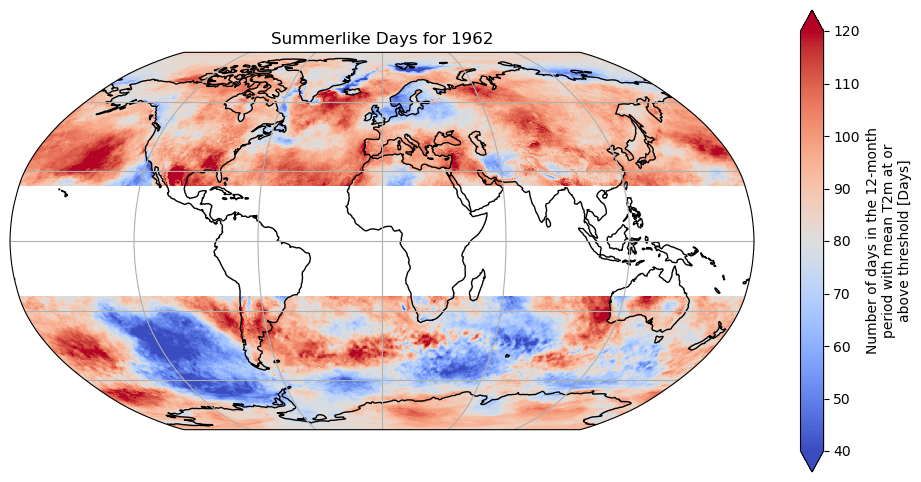

In [6]:
input_year=1962

# Global summer length for the year
fig = plt.figure(figsize=(12,6))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines()

ds.SummerlikeDays.sel(time=str(input_year)).where((ds.lat <= -23.5) | (ds.lat >= 23.5)).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=40,
    vmax=120, # define range to include an entire year
    cmap="coolwarm"#"YlOrRd"#cmap="coolwarm"
)

plt.title("Summerlike Days for "+str(input_year))#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.show()

## Pull in the coastal margins for use in data processing and write out full 1961-2025 Summer Stats for Fourier fit data

In [7]:
# write those results out for later use
input_path = '../../../Data/ERA5-global/ERA5-2023-09-01-CoordFixed-CoastalMargins.nc'
results_ds = xr.open_dataset(input_path)



In [8]:
results_ds

<xarray.Dataset> Size: 1MB
Dimensions:  (lat: 721, lon: 1440)
Coordinates:
  * lat      (lat) float32 3kB 90.0 89.75 89.5 89.25 ... -89.5 -89.75 -90.0
  * lon      (lon) float32 6kB -180.0 -179.8 -179.5 -179.2 ... 179.2 179.5 179.8
Data variables:
    Coastal  (lat, lon) bool 1MB ...

## * Build and write out the full data set from Fourier fits including the coastal margin boolean

In [9]:
%%time

# takes ~4 min to load

# start with one year and lsm then coastal and add a coordinate for the year
year = 1961
input_path = '../../../Data/ERA5-global/Analysis/New-Fourier/'+str(year)+'_summer_stats.nc'
ds_base = xr.open_dataset(input_path)
ds_base = ds_base.merge(ds_lsm) # add lsm
ds_base = ds_base.merge(results_ds) # add coastal flag
ds_base = ds_base.expand_dims("time").assign_coords(time=("time", [dt(year,1,1)]))

# loop thru remaining years and also add time coord
input_years = np.arange(1962,2026,1)

for year in input_years:
    input_path = '../../../Data/ERA5-global/Analysis/New-Fourier/'+str(year)+'_summer_stats.nc'
    ds_i = xr.open_dataset(input_path)
    ds_i = ds_i.merge(ds_lsm)
    ds_i = ds_i.merge(results_ds)
    ds_i = ds_i.expand_dims("time").assign_coords(time=("time", [dt(year,1,1)]))
    ds_base = ds_base.merge(ds_i)

ds_base

CPU times: user 1min 33s, sys: 2min 51s, total: 4min 25s
Wall time: 5min 3s


<xarray.Dataset> Size: 5GB
Dimensions:         (lat: 721, lon: 1440, time: 65)
Coordinates:
  * lat             (lat) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * lon             (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.5 179.8
  * time            (time) datetime64[us] 520B 1961-01-01 ... 2025-01-01
Data variables:
    SummerStart     (time, lat, lon) float64 540MB 135.0 135.0 ... 150.0 150.0
    SummerEnd       (time, lat, lon) float64 540MB 224.0 224.0 ... 252.0 252.0
    SummerTmax      (time, lat, lon) float64 540MB 179.0 179.0 ... 185.0 185.0
    SummerHeat      (time, lat, lon) float64 540MB 390.0 390.0 ... 249.0 249.0
    SummerLength    (time, lat, lon) float64 540MB 90.0 90.0 ... 103.0 103.0
    SummerlikeDays  (time, lat, lon) float64 540MB 89.0 89.0 ... 102.0 102.0
    SummerRMSE      (time, lat, lon) float64 540MB 4.247 4.247 ... 3.977 3.977
    SummerMeanT     (time, lat, lon) float64 540MB 240.5 240.5 ... 273.0 273.0
    lsm             (time, lat, lon) float64 540MB 1.0 1.0 1.0 ... 0.0 0.0 0.0
    Coastal         (time, lat, lon) float64 540MB 0.0 0.0 0.0 ... 0.0 0.0 0.0

In [11]:
# re-add attributes which get lost on merge apparently
ds_base.SummerStart.attrs["long_name"] = "Start day of summer for the year (DOY in [1,365])"
ds_base.SummerStart.attrs["units"] = "Day of year"

ds_base.SummerEnd.attrs["long_name"] = "Last day of summer for the year (DOY in [1,365])"
ds_base.SummerEnd.attrs["units"] = "Day of year"

ds_base.SummerLength.attrs["long_name"] = "Duration of summer for the year"
ds_base.SummerLength.attrs["units"] = "Days"

ds_base.SummerlikeDays.attrs["long_name"] = "Number of days in the 12-month period with mean T2m at or above threshold"
ds_base.SummerlikeDays.attrs["units"] = "Days"

ds_base.SummerTmax.attrs["long_name"] = "Day of max mean temp during summer for the year"
ds_base.SummerTmax.attrs["units"] = "Day of year"

ds_base.SummerHeat.attrs["long_name"] = "Accumulated heat during summer for the year"
ds_base.SummerHeat.attrs["units"] = "Degree-Days"

ds_base.SummerRMSE.attrs["long_name"] = "Root mean squared error of polynomial fit"
ds_base.SummerRMSE.attrs["units"] = "Degrees [K]"

ds_base.SummerMeanT.attrs["long_name"] = "Mean temperature during the summer period"
ds_base.SummerMeanT.attrs["units"] = "Degrees [K]"

ds_base.lsm.attrs["long_name"] = "Land-sea mask - a measure of the amount of land in the cell"
ds_base.lsm.attrs["units"] = "(0 - 1)"


###
### also cast the Coastal as boolean?
###
ds_base.Coastal.values = ds_base.Coastal.values.astype(bool)
ds_base.Coastal.attrs["long_name"] = "Boolean value for whether a >30% land cell has at least one >80% water neighbor"
ds_base.Coastal.attrs["units"] = "true/false"

ds_base

<xarray.Dataset> Size: 5GB
Dimensions:         (lat: 721, lon: 1440, time: 65)
Coordinates:
  * lat             (lat) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * lon             (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.5 179.8
  * time            (time) datetime64[us] 520B 1961-01-01 ... 2025-01-01
Data variables:
    SummerStart     (time, lat, lon) float64 540MB 135.0 135.0 ... 150.0 150.0
    SummerEnd       (time, lat, lon) float64 540MB 224.0 224.0 ... 252.0 252.0
    SummerTmax      (time, lat, lon) float64 540MB 179.0 179.0 ... 185.0 185.0
    SummerHeat      (time, lat, lon) float64 540MB 390.0 390.0 ... 249.0 249.0
    SummerLength    (time, lat, lon) float64 540MB 90.0 90.0 ... 103.0 103.0
    SummerlikeDays  (time, lat, lon) float64 540MB 89.0 89.0 ... 102.0 102.0
    SummerRMSE      (time, lat, lon) float64 540MB 4.247 4.247 ... 3.977 3.977
    SummerMeanT     (time, lat, lon) float64 540MB 240.5 240.5 ... 273.0 273.0
    lsm             (time, lat, lon) float64 540MB 1.0 1.0 1.0 ... 0.0 0.0 0.0
    Coastal         (time, lat, lon) bool 67MB False False False ... False False

In [12]:
# write out complete dataset with LSM and Coastal flags
output_path = '../../../Data/ERA5-global/Analysis/New-Fourier/1961-2025_ALL_summer_stats.nc'
ds_base.to_netcdf(output_path)

# create a COASTAL data file similar to the LAND and OCEAN ones we have so far as well
# output_path = '../../../Data/ERA5-global/Analysis/New/1961-2023_COASTAL_summer_stats.nc'
# ds_coastal = ds_base.where(ds_base.Coastal)
# ds_coastal.to_netcdf(output_path)



In [13]:
! ls -al "../../../Data/ERA5-global/Analysis/New-Fourier/"

total 26259856
drwx------@    91 tedscott  staff        2912 Jul 20 11:17 .
drwx------@    42 tedscott  staff        1344 Jun 11 16:08 ..
-rw-r--r--@     1 tedscott  staff       10244 Jul 20 10:46 .DS_Store
-rw-------@     1 tedscott  staff    66478723 Jul 17 15:22 1961_summer_stats.nc
-rw-------@     1 tedscott  staff   393179156 Apr 14  2025 1961-1990_DOYClimatologyNH.nc
-rw-------@     1 tedscott  staff     6754117 Apr 14  2025 1961-1990_NH_ClimStartEnd_stats.nc
-rw-------@     1 tedscott  staff    24942864 Jun  9  2025 1961-2023_AccHeatTrends.nc
-rw-------@     1 tedscott  staff  1231850829 Nov 13  2025 1961-2023_ALL_summer_stats_zipped.zip
-rw-------@     1 tedscott  staff  5298175103 Oct 27  2025 1961-2023_ALL_summer_stats.nc
-rw-------@     1 tedscott  staff    24943042 Jun 11  2025 1961-2023_EndTrends.nc
-rw-------@     1 tedscott  staff    24943042 Jun  9  2025 1961-2023_LengthTrends.nc
-rw-------@     1 tedscott  staff    24943042 Jun 11  2025 1961-2023_StartTrends.nc
-rw----

# **********

# *** JUMP here after first running

In [14]:
ds = xr.open_dataset('../../../Data/ERA5-global/Analysis/New-Fourier/1961-2025_ALL_summer_stats.nc')
ds

<xarray.Dataset> Size: 5GB
Dimensions:         (time: 65, lat: 721, lon: 1440)
Coordinates:
  * time            (time) datetime64[ns] 520B 1961-01-01 ... 2025-01-01
  * lat             (lat) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * lon             (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.5 179.8
Data variables:
    SummerStart     (time, lat, lon) float64 540MB ...
    SummerEnd       (time, lat, lon) float64 540MB ...
    SummerTmax      (time, lat, lon) float64 540MB ...
    SummerHeat      (time, lat, lon) float64 540MB ...
    SummerLength    (time, lat, lon) float64 540MB ...
    SummerlikeDays  (time, lat, lon) float64 540MB ...
    SummerRMSE      (time, lat, lon) float64 540MB ...
    SummerMeanT     (time, lat, lon) float64 540MB ...
    lsm             (time, lat, lon) float64 540MB ...
    Coastal         (time, lat, lon) bool 67MB ...

# **********

# Plots

In [15]:


# find weights (this is a regular grid so we can use cos(latitude))
weights = np.cos(np.deg2rad(ds.lat))
weights.name = "weights"


### Global Land vs Ocean Summer Length

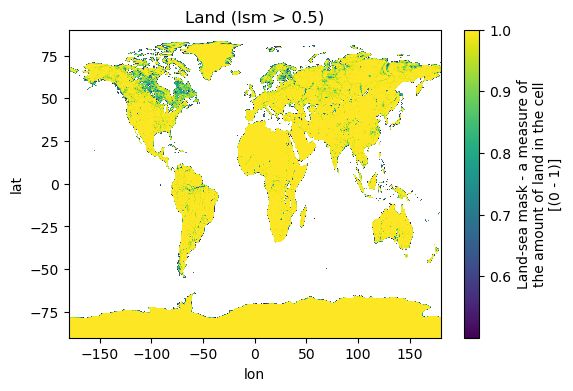

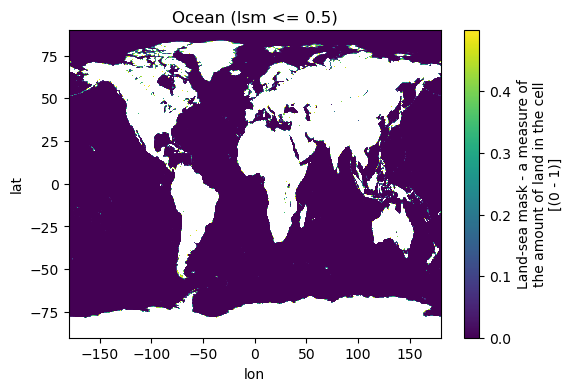

In [16]:
# can be land and inland small water
ds_land = ds.where(ds.lsm > 0.5)
ds_ocean = ds.where(ds.lsm <= 0.5)

plt.figure(figsize=(6,4))
#plt.subplot(111)
ds_land.lsm.sel(time='2020').plot()
plt.title("Land (lsm > 0.5)")
#plt.subplot(122)
plt.figure(figsize=(6,4))
ds_ocean.lsm.sel(time='2020').plot()
plt.title("Ocean (lsm <= 0.5)")
#plt.tight_layout()
plt.show()

In [17]:
ds_land

<xarray.Dataset> Size: 5GB
Dimensions:         (time: 65, lat: 721, lon: 1440)
Coordinates:
  * time            (time) datetime64[ns] 520B 1961-01-01 ... 2025-01-01
  * lat             (lat) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * lon             (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.5 179.8
Data variables:
    SummerStart     (time, lat, lon) float64 540MB 135.0 135.0 135.0 ... nan nan
    SummerEnd       (time, lat, lon) float64 540MB 224.0 224.0 224.0 ... nan nan
    SummerTmax      (time, lat, lon) float64 540MB 179.0 179.0 179.0 ... nan nan
    SummerHeat      (time, lat, lon) float64 540MB 390.0 390.0 390.0 ... nan nan
    SummerLength    (time, lat, lon) float64 540MB 90.0 90.0 90.0 ... nan nan
    SummerlikeDays  (time, lat, lon) float64 540MB 89.0 89.0 89.0 ... nan nan
    SummerRMSE      (time, lat, lon) float64 540MB 4.247 4.247 4.247 ... nan nan
    SummerMeanT     (time, lat, lon) float64 540MB 240.5 240.5 240.5 ... nan nan
    lsm             (time, lat, lon) float64 540MB 1.0 1.0 1.0 ... nan nan nan
    Coastal         (time, lat, lon) float64 540MB 0.0 0.0 0.0 ... nan nan nan

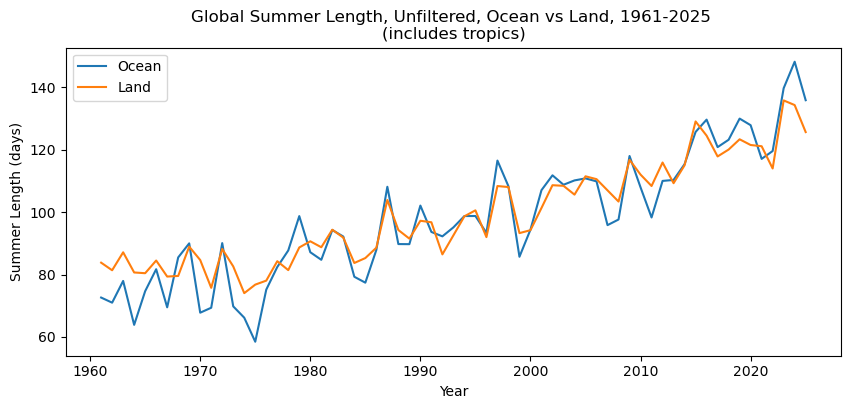

In [18]:


# take the weighted spatial mean since the latitude range of the region of interest is large
wavg_land_sl = ds_land.SummerLength.weighted(weights).mean(dim=['lat','lon'])
wavg_ocean_sl = ds_ocean.SummerLength.weighted(weights).mean(dim=['lat','lon'])

plt.figure(figsize=(10,4))
plt.plot(wavg_ocean_sl.time.dt.year, wavg_ocean_sl, label="Ocean")
plt.plot(wavg_land_sl.time.dt.year, wavg_land_sl, label="Land")

plt.xlabel("Year")
plt.ylabel("Summer Length (days)")
plt.title("Global Summer Length, Unfiltered, Ocean vs Land, 1961-2025 \n(includes tropics)")
plt.legend()
plt.show()

## Global Mid-latitude Land vs Ocean

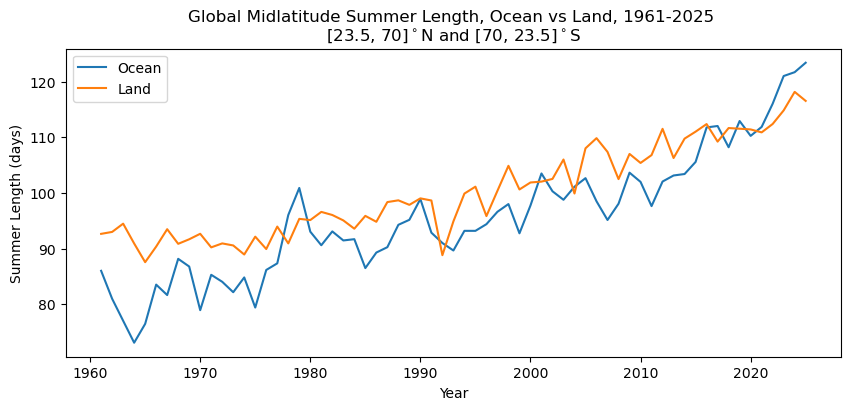

In [19]:
# take the weighted spatial mean since the latitude range of the region of interest is large
wavg_midlat_land_sl = ds_land.SummerLength.where(((ds_land.lat >= 23.5) & (ds_land.lat <= 70)) | 
                                         ((ds_land.lat <= -23.5) & (ds_land.lat >= -70))).weighted(weights).mean(dim=['lat','lon'])
wavg_midlat_ocean_sl = ds_ocean.SummerLength.where(((ds_ocean.lat >= 23.5) & (ds_ocean.lat <= 70)) |
                                           ((ds_ocean.lat <= -23.5) & (ds_ocean.lat >= -70))).weighted(weights).mean(dim=['lat','lon'])

plt.figure(figsize=(10,4))
plt.plot(wavg_midlat_ocean_sl.time.dt.year, wavg_midlat_ocean_sl, label="Ocean")
plt.plot(wavg_midlat_land_sl.time.dt.year, wavg_midlat_land_sl, label="Land")
plt.xlabel("Year")
plt.ylabel("Summer Length (days)")
plt.title("Global Midlatitude Summer Length, Ocean vs Land, 1961-2025 \n[23.5, 70]$^\circ$N and [70, 23.5]$^\circ$S")
plt.legend()
plt.show()

## Scatter plots of Ocean (<= 50% land) vs Land (> 50% land) for NH and SH, Start/End/Length

In [25]:
plot_vars = list(ds.data_vars)
remove_me = {'SummerTmax','SummerMeanHS','SummerRMSE','SummerR2','lsm','Coastal','SummerMeanT'}
plot_vars = [item for item in plot_vars if item not in remove_me]
plot_vars

['SummerStart', 'SummerEnd', 'SummerHeat', 'SummerLength', 'SummerlikeDays']

#### removing requirement on ds.SummerMeanT > 0 because it makes very little difference in Fourier fit data

In [26]:
%%time

# takes 36 sec

# latitude & longitude ranges for NH and SH midlatitudes so they will be easy to adjust
nh_min = 23.5
nh_max = 70
sh_min = -23.5
sh_max = -70

# datasets of weighted averages for the midlatitudes
# for now, removing grid cells from averages where the mean summer temp was 0 K meaning no summer
# quick counts suggest this loses 1.5 - 2% of grid cells across the 63 years
nh_land_full = ds.where((ds.lsm > 0.5) & #(ds.SummerMeanT > 0) &
                             ((ds.lat >= nh_min) & (ds.lat <= nh_max))).weighted(weights).mean(dim=['lat','lon'])

nh_ocean_full = ds.where((ds.lsm <= 0.5) & #(ds.SummerMeanT > 0) &
                              ((ds.lat >= nh_min) & (ds.lat <= nh_max))).weighted(weights).mean(dim=['lat','lon'])

sh_land_full = ds.where((ds.lsm > 0.5) & #(ds.SummerMeanT > 0) & 
                             ((ds.lat >= sh_max) & (ds.lat <= sh_min))).weighted(weights).mean(dim=['lat','lon'])

sh_ocean_full = ds.where((ds.lsm <= 0.5) & #(ds.SummerMeanT > 0) & 
                              ((ds.lat >= sh_max) & (ds.lat <= sh_min))).weighted(weights).mean(dim=['lat','lon'])

nh_land_an = ds.sel(time=slice('1990','2025')).where((ds.lsm > 0.5) & #(ds.SummerMeanT > 0) &
                                                          ((ds.lat >= nh_min) & (ds.lat <= nh_max))).weighted(weights).mean(dim=['lat','lon'])

nh_ocean_an = ds.sel(time=slice('1990','2025')).where((ds.lsm <= 0.5) & #(ds.SummerMeanT > 0) &
                                                           ((ds.lat >= nh_min) & (ds.lat <= nh_max))).weighted(weights).mean(dim=['lat','lon'])

sh_land_an = ds.sel(time=slice('1990','2025')).where((ds.lsm > 0.5) & #(ds.SummerMeanT > 0) &
                                                          ((ds.lat >= sh_max) & (ds.lat <= sh_min))).weighted(weights).mean(dim=['lat','lon'])

sh_ocean_an = ds.sel(time=slice('1990','2025')).where((ds.lsm <= 0.5) & #(ds.SummerMeanT > 0) &
                                                           ((ds.lat >= sh_max) & (ds.lat <= sh_min))).weighted(weights).mean(dim=['lat','lon'])

# adding in baseline period for trends to put in paper
nh_land_base = ds.sel(time=slice('1961','1990')).where((ds.lsm > 0.5) & #(ds.SummerMeanT > 0) &
                                                          ((ds.lat >= nh_min) & (ds.lat <= nh_max))).weighted(weights).mean(dim=['lat','lon'])

nh_ocean_base = ds.sel(time=slice('1961','1990')).where((ds.lsm <= 0.5) & #(ds.SummerMeanT > 0) &
                                                           ((ds.lat >= nh_min) & (ds.lat <= nh_max))).weighted(weights).mean(dim=['lat','lon'])

sh_land_base = ds.sel(time=slice('1961','1990')).where((ds.lsm > 0.5) & #(ds.SummerMeanT > 0) &
                                                          ((ds.lat >= sh_max) & (ds.lat <= sh_min))).weighted(weights).mean(dim=['lat','lon'])

sh_ocean_base = ds.sel(time=slice('1961','1990')).where((ds.lsm <= 0.5) & #(ds.SummerMeanT > 0) &
                                                           ((ds.lat >= sh_max) & (ds.lat <= sh_min))).weighted(weights).mean(dim=['lat','lon'])


CPU times: user 17.5 s, sys: 18 s, total: 35.5 s
Wall time: 38.2 s


In [27]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20

sns.set_theme(style="darkgrid")

### First with no trends

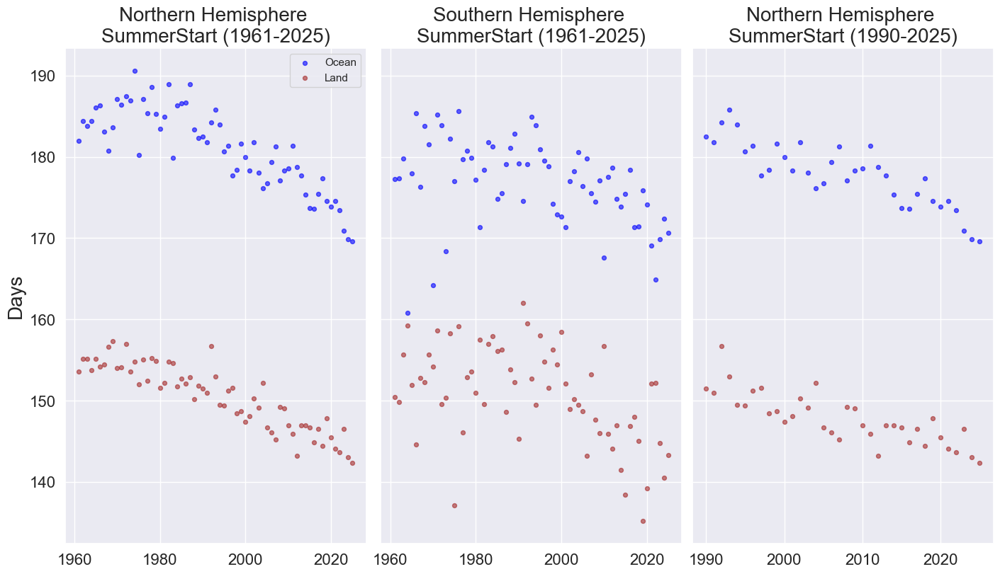

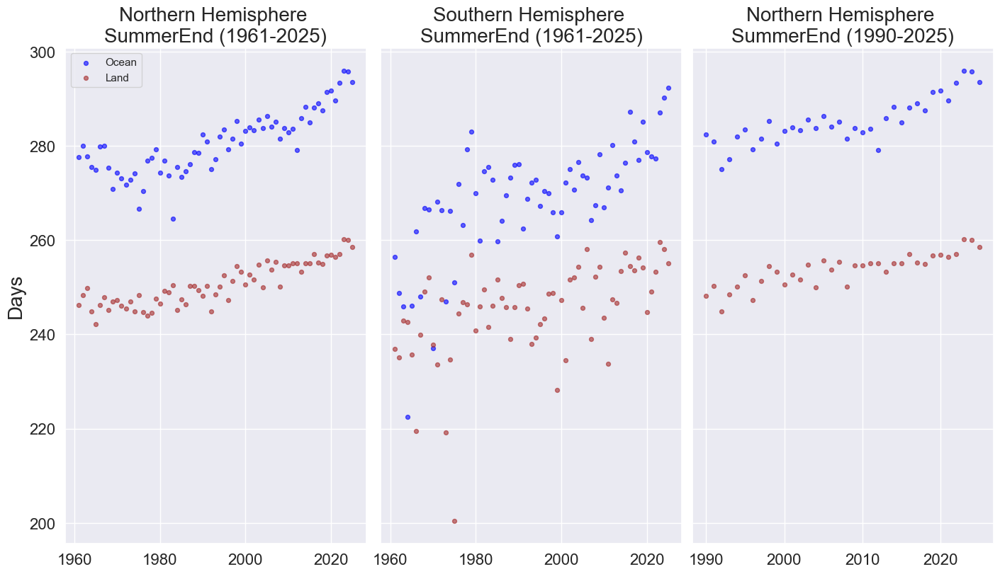

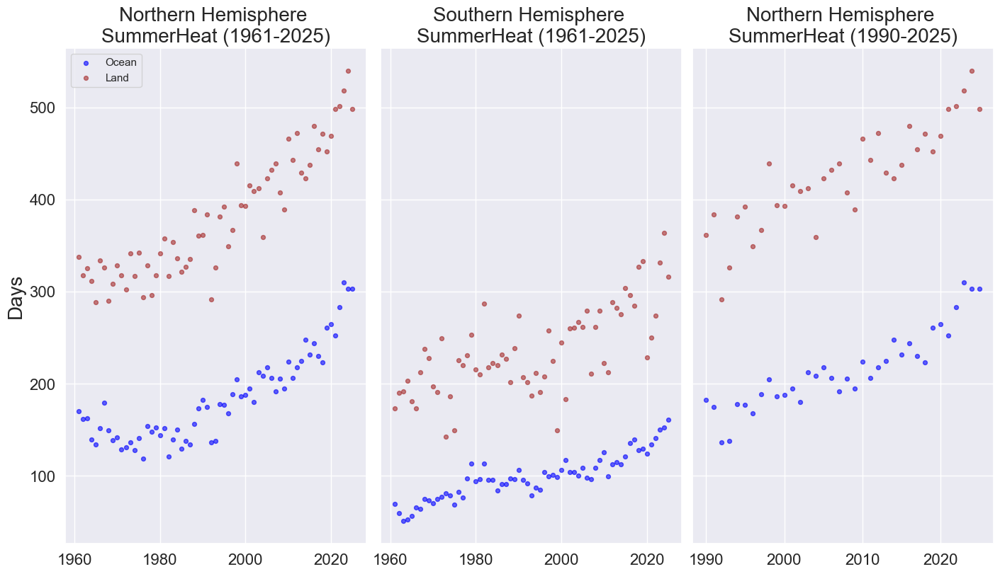

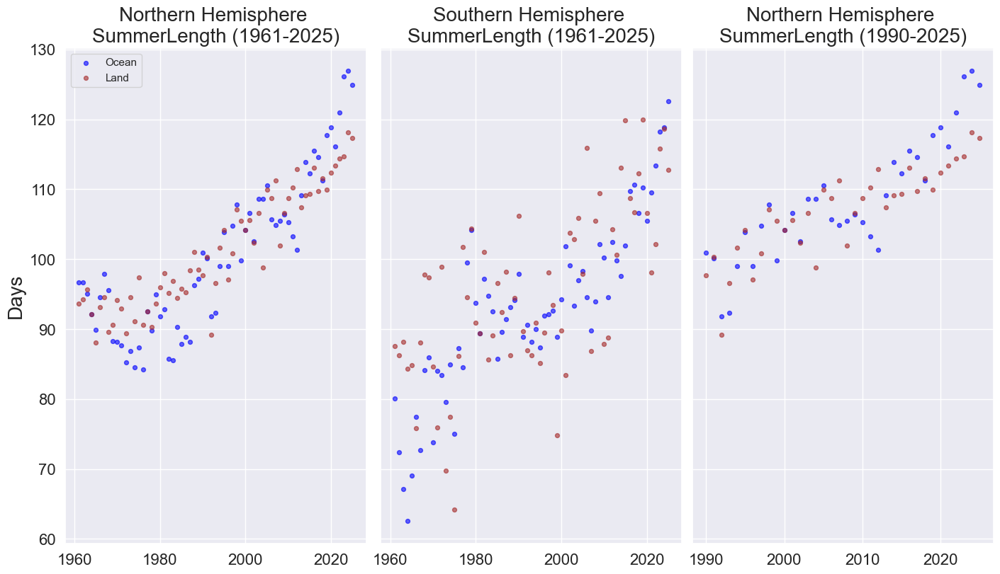

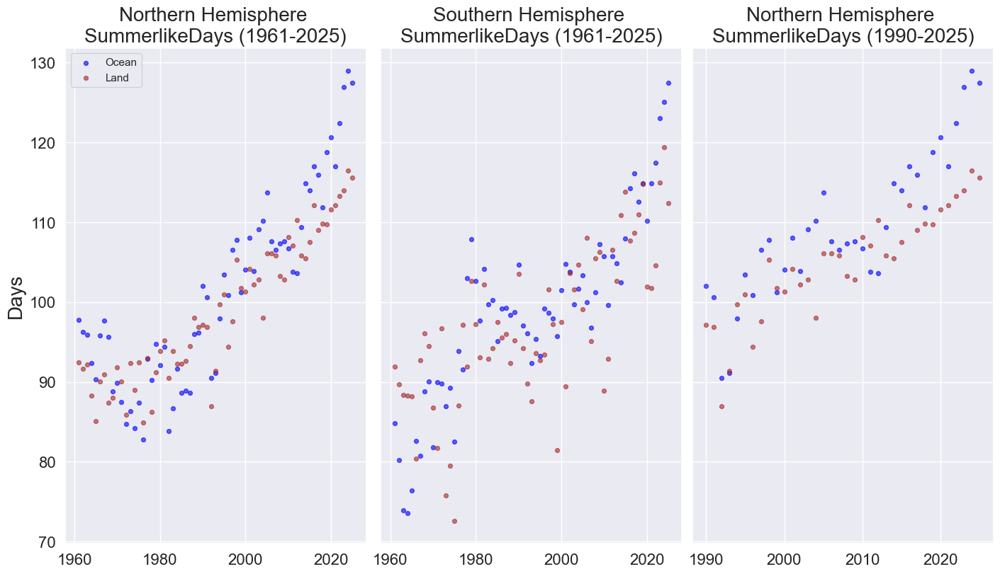

CPU times: user 696 ms, sys: 57.9 ms, total: 754 ms
Wall time: 771 ms


In [28]:
%%time


# loop through all plot variables
for i,v in enumerate(plot_vars):

    # create blank fig
    fig = plt.figure(figsize = (14,8), layout='constrained')
    
    # Full Time Period NH
    ax1 = fig.add_subplot(1,3,1)

    # linear fits for slope from 1960-1976
    x_land = nh_land_full.time.dt.year.values[0:17]
    y_land = nh_land_full[v].values[0:17]
    coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
    poly_land = np.poly1d(coefs_land)
    slope_land = np.round(coefs_land[0],2)
    slope_land_sd = np.round(np.sqrt(V[0][0]),2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_land)
    ss_total = np.sum((y_land - ymean)**2)
    ss_res = np.sum((y_land - poly_land(x_land))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_land = np.round(1 - (ss_res / ss_total),2)

    # linear fits for slope
    x_ocean = nh_ocean_full.time.dt.year.values[0:17]
    y_ocean = nh_ocean_full[v].values[0:17]
    coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
    poly_ocean = np.poly1d(coefs_ocean)
    slope_ocean = np.round(coefs_ocean[0],2)
    slope_ocean_sd = np.round(np.sqrt(V[0][0]),2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_ocean)
    ss_total = np.sum((y_ocean - ymean)**2)
    ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_ocean = np.round(1 - (ss_res / ss_total),2)
    
    # plot data
    ax1.scatter(nh_ocean_full.time.dt.year.values, nh_ocean_full[v], label="Ocean", c="blue", s=s, alpha=alpha)
    # ax1.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", linewidth=lw, color='blue', 
    #      label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
    ax1.scatter(nh_land_full.time.dt.year.values, nh_land_full[v], label="Land", c="brown", s=s, alpha=alpha)
    # ax1.plot(x_land, poly_land(x_land), linewidth=lw, linestyle="dotted", color='brown',
    #      label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
    ax1.set_title("Northern Hemisphere \n" + v + " (1961-2025)", fontsize = fs)

    # Annotation
    ann_y = (ax1.get_yticks())[-3]+8
    ann_x = np.mean(ax1.get_xticks())-5
    # ax1.text(ann_x, ann_y, 
    #          ''+str(np.round((slope_ocean+slope_land)*5,1))+r' $\frac{days}{decade}$', fontsize=28, color='purple', fontweight='bold')
    
    plt.tick_params('x', labelsize=16)
    plt.tick_params('y', labelsize=16)
    ax1.set_ylabel('Days', fontsize=fs)
    ax1.legend(loc='best')

    # Full time period SH
    ax2 = fig.add_subplot(1,3,2, sharey=ax1)

    # linear fits for slope
    x_land = sh_land_full.time.dt.year.values
    y_land = sh_land_full[v].values
    coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
    poly_land = np.poly1d(coefs_land)
    slope_land = np.round(coefs_land[0],2)
    slope_land_sd = np.round(np.sqrt(V[0][0]),2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_land)
    ss_total = np.sum((y_land - ymean)**2)
    ss_res = np.sum((y_land - poly_land(x_land))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_land = np.round(1 - (ss_res / ss_total),2)

    # linear fits for slope
    x_ocean = sh_ocean_full.time.dt.year.values
    y_ocean = sh_ocean_full[v].values
    coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
    poly_ocean = np.poly1d(coefs_ocean)
    slope_ocean = np.round(coefs_ocean[0],2)
    slope_ocean_sd = np.round(np.sqrt(V[0][0]),2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_ocean)
    ss_total = np.sum((y_ocean - ymean)**2)
    ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_ocean = np.round(1 - (ss_res / ss_total),2)
    
    # plot data
    ax2.scatter(sh_ocean_full.time.dt.year.values, sh_ocean_full[v], label="SH Ocean", c="blue", s=s, alpha=alpha)
    # ax2.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", linewidth=lw, color='blue', 
    #      label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
    ax2.scatter(sh_land_full.time.dt.year.values, sh_land_full[v], label="SH Land", c="brown", s=s, alpha=alpha)
    # ax2.plot(x_land, poly_land(x_land), linestyle="dotted", linewidth=lw, color='brown',
         # label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
    ax2.set_title("Southern Hemisphere \n" + v + " (1961-2025)", fontsize = fs)
    # Annotation
    # ann_y = (ax2.get_yticks())[-3]+8
    # ann_x = np.mean(ax2.get_xticks())-5
    # ax2.text(ann_x, ann_y, 
    #          ''+str(np.round((slope_ocean+slope_land)*5,1))+r' $\frac{days}{decade}$', fontsize=28, color='purple', fontweight='bold')
    
    plt.tick_params('x', labelsize=16)
    plt.tick_params('y', labelsize=6, labelleft=False)
    #ax2.legend(loc='best')
    

    # Analysis time period NH
    ax3 = fig.add_subplot(1,3,3, sharey=ax1)

    # linear fits for slope
    x_land = nh_land_an.time.dt.year.values
    y_land = nh_land_an[v].values
    coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
    poly_land = np.poly1d(coefs_land)
    slope_land = np.round(coefs_land[0],2)
    slope_land_sd = np.round(np.sqrt(V[0][0]),2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_land)
    ss_total = np.sum((y_land - ymean)**2)
    ss_res = np.sum((y_land - poly_land(x_land))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_land = np.round(1 - (ss_res / ss_total),2)

    # linear fits for slope
    x_ocean = nh_ocean_an.time.dt.year.values
    y_ocean = nh_ocean_an[v].values
    coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
    poly_ocean = np.poly1d(coefs_ocean)
    slope_ocean = np.round(coefs_ocean[0],2)
    slope_ocean_sd = np.round(np.sqrt(V[0][0]),2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_ocean)
    ss_total = np.sum((y_ocean - ymean)**2)
    ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_ocean = np.round(1 - (ss_res / ss_total),2)
    
    # plot data
    ax3.scatter(nh_ocean_an.time.dt.year.values, nh_ocean_an[v], label="NH Ocean", c="blue", s=s, alpha=alpha)
    #ax3.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", linewidth=lw, color='blue', 
         #label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
    ax3.scatter(nh_land_an.time.dt.year.values, nh_land_an[v], label="NH Land", c="brown", s=s, alpha=alpha)
    #ax3.plot(x_land, poly_land(x_land), linestyle="dotted", linewidth=lw, color='brown',
         #label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
    ax3.set_title("Northern Hemisphere \n" + v + " (1990-2025)", fontsize = fs)
    # Annotation - units in per decade
    ann_y = (ax3.get_yticks())[-3]+8
    ann_x = np.mean(ax3.get_xticks())-5
    # ax3.text(ann_x, ann_y, 
    #          ''+str(np.round((slope_ocean+slope_land)*5,1))+r' $\frac{days}{decade}$', fontsize=28, color='purple', fontweight='bold')
    
    plt.tick_params('x', labelsize=16)
    plt.tick_params('y', labelsize=6, labelleft=False)
    #ax3.legend(loc='best')


#plt.tight_layout()
plt.show()

### Then with the full 1961-2025 trend

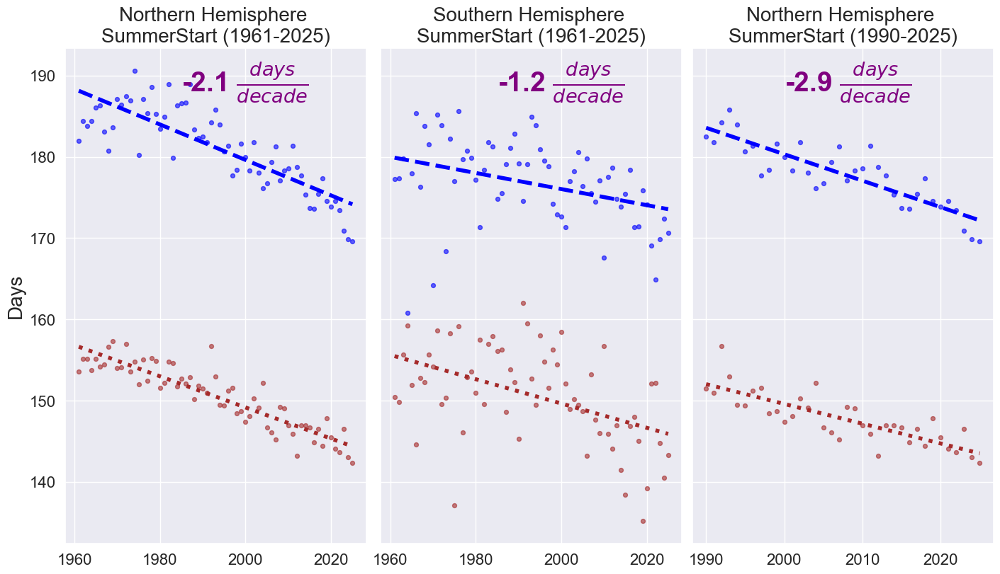

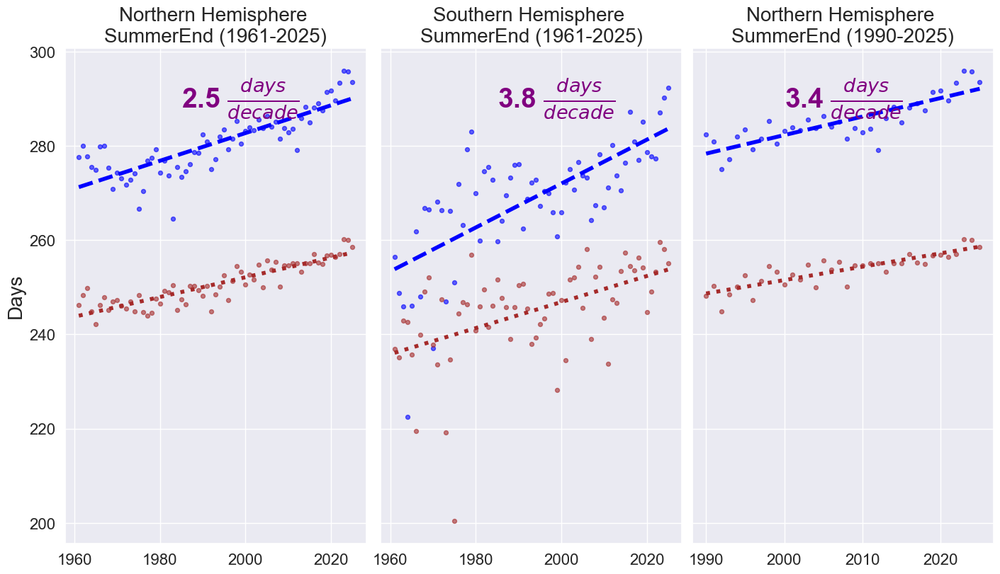

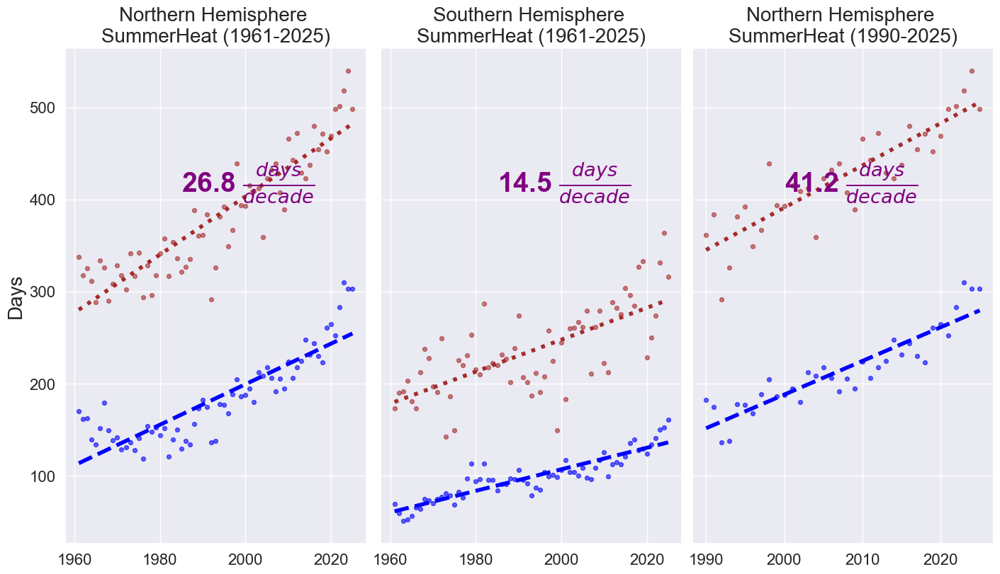

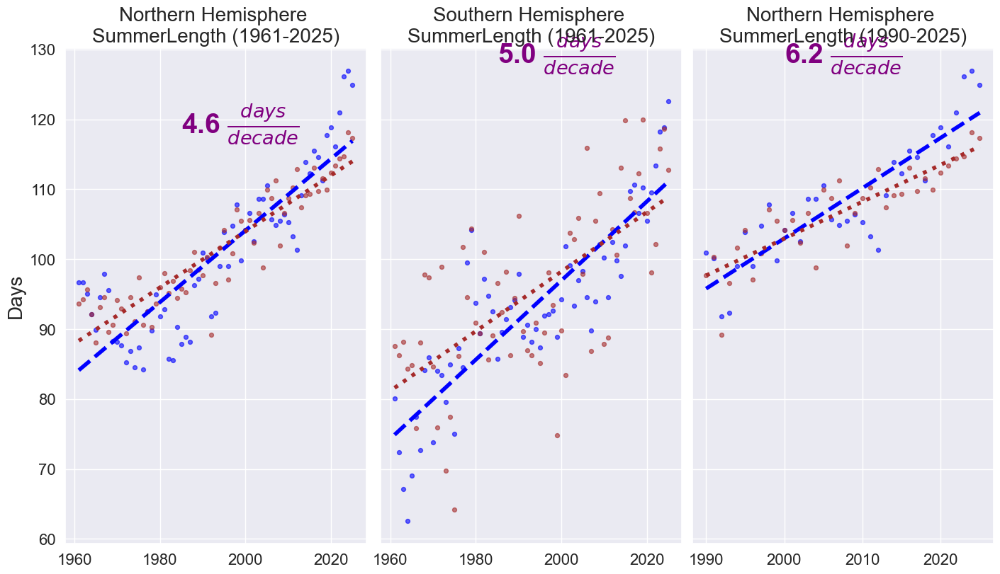

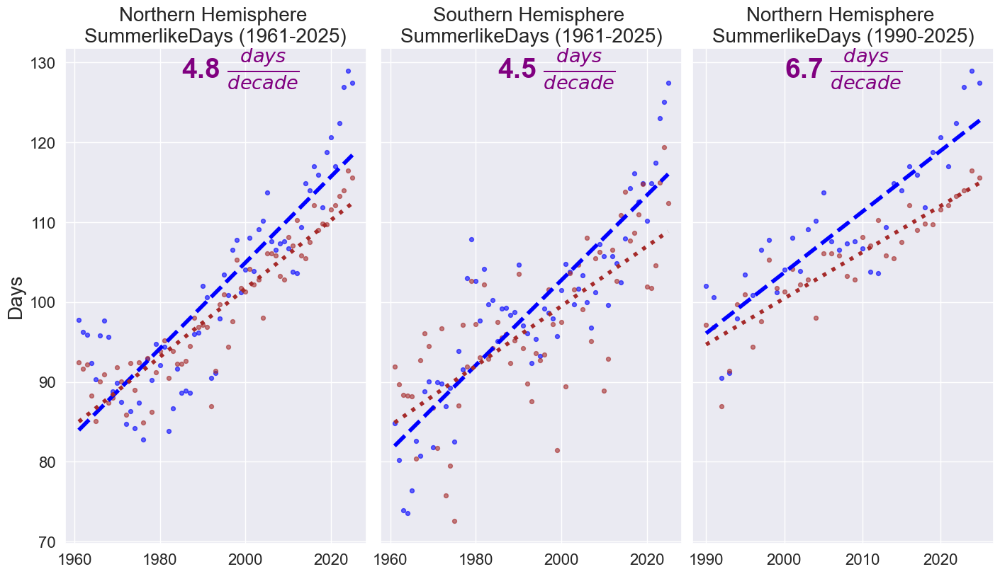

CPU times: user 764 ms, sys: 65 ms, total: 829 ms
Wall time: 837 ms


In [29]:
%%time


# loop through all plot variables
for i,v in enumerate(plot_vars):

    # create blank fig
    fig = plt.figure(figsize = (14,8), layout='constrained')
    
    # Full Time Period NH
    ax1 = fig.add_subplot(1,3,1)

    # linear fits for slope
    x_land = nh_land_full.time.dt.year.values
    y_land = nh_land_full[v].values
    coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
    poly_land = np.poly1d(coefs_land)
    slope_land = np.round(coefs_land[0],2)
    slope_land_sd = np.round(np.sqrt(V[0][0]),2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_land)
    ss_total = np.sum((y_land - ymean)**2)
    ss_res = np.sum((y_land - poly_land(x_land))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_land = np.round(1 - (ss_res / ss_total),2)

    # linear fits for slope
    x_ocean = nh_ocean_full.time.dt.year.values
    y_ocean = nh_ocean_full[v].values
    coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
    poly_ocean = np.poly1d(coefs_ocean)
    slope_ocean = np.round(coefs_ocean[0],2)
    slope_ocean_sd = np.round(np.sqrt(V[0][0]),2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_ocean)
    ss_total = np.sum((y_ocean - ymean)**2)
    ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_ocean = np.round(1 - (ss_res / ss_total),2)
    
    # plot data
    ax1.scatter(nh_ocean_full.time.dt.year.values, nh_ocean_full[v], label="NH Ocean", c="blue", s=s, alpha=alpha)
    ax1.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", linewidth=lw, color='blue', 
         label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
    ax1.scatter(nh_land_full.time.dt.year.values, nh_land_full[v], label="NH Land", c="brown", s=s, alpha=alpha)
    ax1.plot(x_land, poly_land(x_land), linewidth=lw, linestyle="dotted", color='brown',
         label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
    ax1.set_title("Northern Hemisphere \n" + v + " (1961-2025)", fontsize = fs)

    # Annotation
    ann_y = (ax1.get_yticks())[-3]+8
    ann_x = np.mean(ax1.get_xticks())-5
    ax1.text(ann_x, ann_y, 
             ''+str(np.round((slope_ocean+slope_land)*5,1))+r' $\frac{days}{decade}$', fontsize=28, color='purple', fontweight='bold')
    
    plt.tick_params('x', labelsize=16)
    plt.tick_params('y', labelsize=16)
    ax1.set_ylabel('Days', fontsize=fs)
    #ax1.legend(loc='best')

    # Full time period SH
    ax2 = fig.add_subplot(1,3,2, sharey=ax1)

    # linear fits for slope
    x_land = sh_land_full.time.dt.year.values
    y_land = sh_land_full[v].values
    coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
    poly_land = np.poly1d(coefs_land)
    slope_land = np.round(coefs_land[0],2)
    slope_land_sd = np.round(np.sqrt(V[0][0]),2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_land)
    ss_total = np.sum((y_land - ymean)**2)
    ss_res = np.sum((y_land - poly_land(x_land))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_land = np.round(1 - (ss_res / ss_total),2)

    # linear fits for slope
    x_ocean = sh_ocean_full.time.dt.year.values
    y_ocean = sh_ocean_full[v].values
    coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
    poly_ocean = np.poly1d(coefs_ocean)
    slope_ocean = np.round(coefs_ocean[0],2)
    slope_ocean_sd = np.round(np.sqrt(V[0][0]),2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_ocean)
    ss_total = np.sum((y_ocean - ymean)**2)
    ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_ocean = np.round(1 - (ss_res / ss_total),2)
    
    # plot data
    ax2.scatter(sh_ocean_full.time.dt.year.values, sh_ocean_full[v], label="SH Ocean", c="blue", s=s, alpha=alpha)
    ax2.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", linewidth=lw, color='blue', 
         label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
    ax2.scatter(sh_land_full.time.dt.year.values, sh_land_full[v], label="SH Land", c="brown", s=s, alpha=alpha)
    ax2.plot(x_land, poly_land(x_land), linestyle="dotted", linewidth=lw, color='brown',
         label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
    ax2.set_title("Southern Hemisphere \n" + v + " (1961-2025)", fontsize = fs)
    # Annotation
    ann_y = (ax2.get_yticks())[-3]+8
    ann_x = np.mean(ax2.get_xticks())-5
    ax2.text(ann_x, ann_y, 
             ''+str(np.round((slope_ocean+slope_land)*5,1))+r' $\frac{days}{decade}$', fontsize=28, color='purple', fontweight='bold')
    
    plt.tick_params('x', labelsize=16)
    plt.tick_params('y', labelsize=6, labelleft=False)
    #ax2.legend(loc='best')
    

    # Analysis time period NH
    ax3 = fig.add_subplot(1,3,3, sharey=ax1)

    # linear fits for slope
    x_land = nh_land_an.time.dt.year.values
    y_land = nh_land_an[v].values
    coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
    poly_land = np.poly1d(coefs_land)
    slope_land = np.round(coefs_land[0],2)
    slope_land_sd = np.round(np.sqrt(V[0][0]),2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_land)
    ss_total = np.sum((y_land - ymean)**2)
    ss_res = np.sum((y_land - poly_land(x_land))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_land = np.round(1 - (ss_res / ss_total),2)

    # linear fits for slope
    x_ocean = nh_ocean_an.time.dt.year.values
    y_ocean = nh_ocean_an[v].values
    coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
    poly_ocean = np.poly1d(coefs_ocean)
    slope_ocean = np.round(coefs_ocean[0],2)
    slope_ocean_sd = np.round(np.sqrt(V[0][0]),2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_ocean)
    ss_total = np.sum((y_ocean - ymean)**2)
    ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_ocean = np.round(1 - (ss_res / ss_total),2)
    
    # plot data
    ax3.scatter(nh_ocean_an.time.dt.year.values, nh_ocean_an[v], label="NH Ocean", c="blue", s=s, alpha=alpha)
    ax3.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", linewidth=lw, color='blue', 
         label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
    ax3.scatter(nh_land_an.time.dt.year.values, nh_land_an[v], label="NH Land", c="brown", s=s, alpha=alpha)
    ax3.plot(x_land, poly_land(x_land), linestyle="dotted", linewidth=lw, color='brown',
         label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
    ax3.set_title("Northern Hemisphere \n" + v + " (1990-2025)", fontsize = fs)
    # Annotation - units in per decade
    ann_y = (ax3.get_yticks())[-3]+8
    ann_x = np.mean(ax3.get_xticks())-5
    ax3.text(ann_x, ann_y, 
             ''+str(np.round((slope_ocean+slope_land)*5,1))+r' $\frac{days}{decade}$', fontsize=28, color='purple', fontweight='bold')
    
    plt.tick_params('x', labelsize=16)
    plt.tick_params('y', labelsize=6, labelleft=False)
    #ax3.legend(loc='best')


#plt.tight_layout()
plt.show()

## Same as above but Coast/Land/Ocean where Land does not include Coasts

In [30]:
#ds.where((ds.lsm > 0.5) & (ds.SummerMeanT == 0) & (ds.Coastal == False) & ((ds.lat >= nh_min) & (ds.lat <= nh_max))).weighted(weights).mean(dim=['lat','lon']).count()
# latitude & longitude ranges for NH and SH midlatitudes so they will be easy to adjust
nh_min = 23.5
nh_max = 70
sh_min = -23.5
sh_max = -70

#### removed ds.SummerMeanT > 0 in the below because with the Fourier fits it makes no difference in results

In [31]:
%%time

# 35 sec

nh_land_full = ds.where((ds.lsm > 0.5) &  (ds.Coastal == False) & #(ds.SummerMeanT > 0) &
                             ((ds.lat >= nh_min) & (ds.lat <= nh_max))).weighted(weights).mean(dim=['lat','lon'])

nh_coast_full = ds.where((ds.Coastal)  & #& (ds.SummerMeanT > 0)
                              ((ds.lat >= nh_min) & (ds.lat <= nh_max))).weighted(weights).mean(dim=['lat','lon'])

sh_land_full = ds.where((ds.lsm > 0.5)  & (ds.Coastal == False) & #& (ds.SummerMeanT > 0)
                             ((ds.lat >= sh_max) & (ds.lat <= sh_min))).weighted(weights).mean(dim=['lat','lon'])

sh_coast_full = ds.where((ds.Coastal)  & #& (ds.SummerMeanT > 0)
                              ((ds.lat >= sh_max) & (ds.lat <= sh_min))).weighted(weights).mean(dim=['lat','lon'])

nh_land_an = ds.sel(time=slice('1990','2025')).where((ds.lsm > 0.5)  & (ds.Coastal == False) & #& (ds.SummerMeanT > 0)
                                                          ((ds.lat >= nh_min) & (ds.lat <= nh_max))).weighted(weights).mean(dim=['lat','lon'])

nh_coast_an = ds.sel(time=slice('1990','2025')).where((ds.Coastal)  & #& (ds.SummerMeanT > 0)
                                                           ((ds.lat >= nh_min) & (ds.lat <= nh_max))).weighted(weights).mean(dim=['lat','lon'])

sh_land_an = ds.sel(time=slice('1990','2025')).where((ds.lsm > 0.5)  & (ds.Coastal == False) & #& (ds.SummerMeanT > 0)
                                                          ((ds.lat >= sh_max) & (ds.lat <= sh_min))).weighted(weights).mean(dim=['lat','lon'])

sh_coast_an = ds.sel(time=slice('1990','2025')).where((ds.Coastal)  & #& (ds.SummerMeanT > 0)
                                                           ((ds.lat >= sh_max) & (ds.lat <= sh_min))).weighted(weights).mean(dim=['lat','lon'])

# adding in baseline period to use for trends in the paper
nh_land_base = ds.sel(time=slice('1961','1990')).where((ds.lsm > 0.5)  & (ds.Coastal == False) & #& (ds.SummerMeanT > 0)
                                                          ((ds.lat >= nh_min) & (ds.lat <= nh_max))).weighted(weights).mean(dim=['lat','lon'])

nh_coast_base = ds.sel(time=slice('1961','1990')).where((ds.Coastal)  & #& (ds.SummerMeanT > 0)
                                                           ((ds.lat >= nh_min) & (ds.lat <= nh_max))).weighted(weights).mean(dim=['lat','lon'])

sh_land_base = ds.sel(time=slice('1961','1990')).where((ds.lsm > 0.5)  & (ds.Coastal == False) & #& (ds.SummerMeanT > 0)
                                                          ((ds.lat >= sh_max) & (ds.lat <= sh_min))).weighted(weights).mean(dim=['lat','lon'])

sh_coast_base = ds.sel(time=slice('1961','1990')).where((ds.Coastal)  & #& (ds.SummerMeanT > 0)
                                                           ((ds.lat >= sh_max) & (ds.lat <= sh_min))).weighted(weights).mean(dim=['lat','lon'])




CPU times: user 17.4 s, sys: 15.8 s, total: 33.2 s
Wall time: 35.4 s


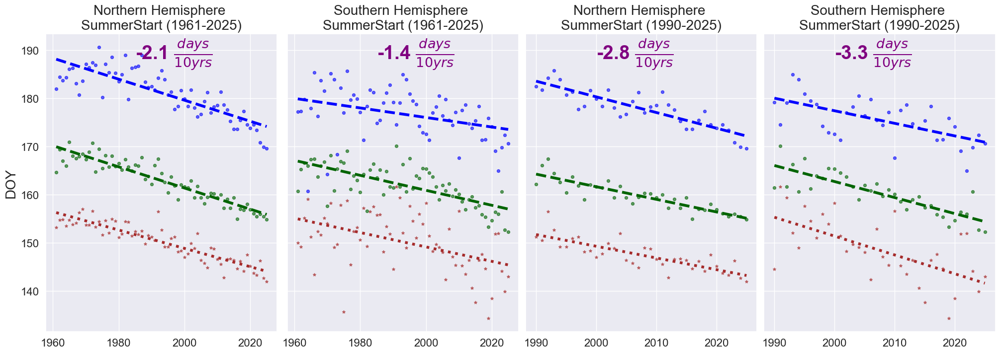

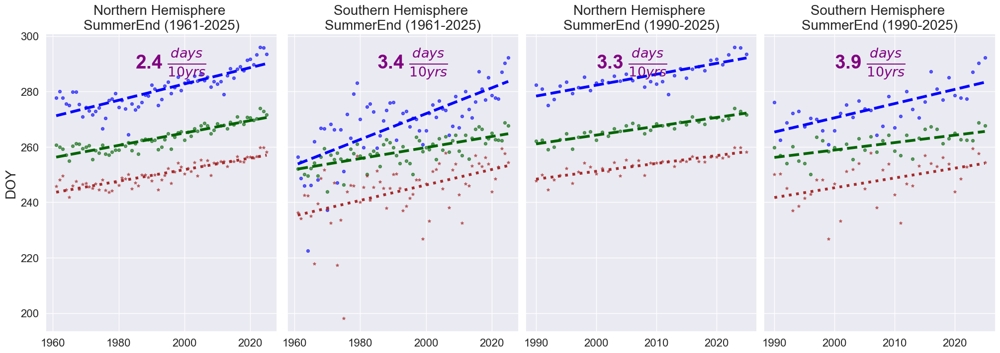

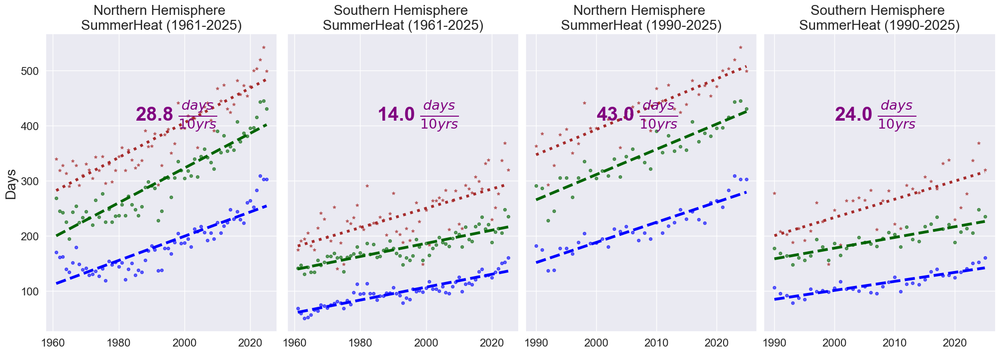

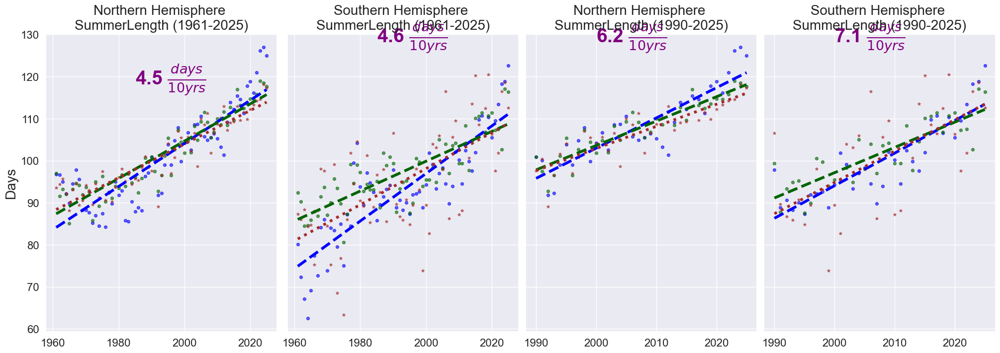

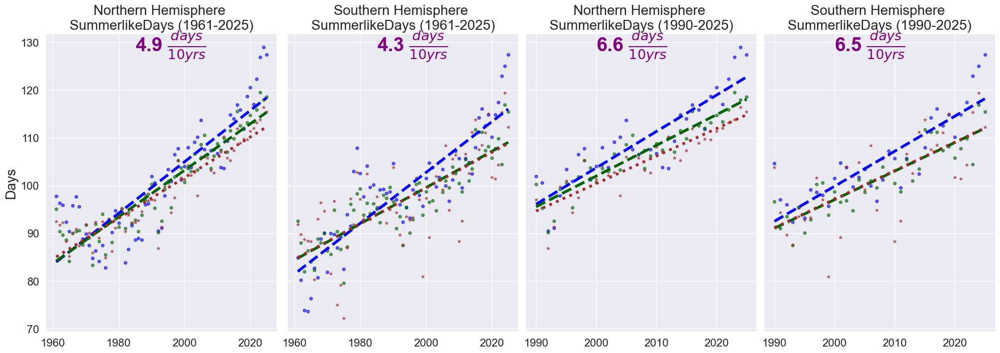

CPU times: user 970 ms, sys: 102 ms, total: 1.07 s
Wall time: 1.09 s


In [32]:
%%time

# takes 30 sec



# loop through all plot variables
for i,v in enumerate(plot_vars):

    # create blank fig
    fig = plt.figure(figsize = (20,7), layout='constrained')
    
    # Full Time Period NH
    ax1 = fig.add_subplot(1,4,1)

    # linear fits for slope
    x_land = nh_land_full.time.dt.year.values
    y_land = nh_land_full[v].values
    coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
    poly_land = np.poly1d(coefs_land)
    slope_land = np.round(coefs_land[0],2)
    slope_land_sd = np.round(np.sqrt(V[0][0]),2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_land)
    ss_total = np.sum((y_land - ymean)**2)
    ss_res = np.sum((y_land - poly_land(x_land))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_land = np.round(1 - (ss_res / ss_total),2)

    # linear fits for slope
    x_coast = nh_coast_full.time.dt.year.values
    y_coast = nh_coast_full[v].values
    coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
    poly_coast = np.poly1d(coefs_coast)
    slope_coast = np.round(coefs_coast[0],2)
    slope_coast_sd = np.round(np.sqrt(V[0][0]),2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_coast)
    ss_total = np.sum((y_coast - ymean)**2)
    ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_coast = np.round(1 - (ss_res / ss_total),2)

    # linear fits for slope
    x_ocean = nh_ocean_full.time.dt.year.values
    y_ocean = nh_ocean_full[v].values
    coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
    poly_ocean = np.poly1d(coefs_ocean)
    slope_ocean = np.round(coefs_ocean[0],2)
    slope_ocean_sd = np.round(np.sqrt(V[0][0]),2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_ocean)
    ss_total = np.sum((y_ocean - ymean)**2)
    ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_ocean = np.round(1 - (ss_res / ss_total),2)
    
    # plot data
    ax1.scatter(x_ocean, y_ocean, label="NH Ocean", c="blue", s=s, alpha=alpha)
    ax1.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", linewidth=lw, color='blue', 
         label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
    ax1.scatter(x_coast, y_coast, label="NH Coast", c="darkgreen", s=s, alpha=alpha)
    ax1.plot(x_coast, poly_coast(x_coast), linestyle="dashed", linewidth=lw, color='darkgreen', 
         label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
    ax1.scatter(x_land, y_land, label="NH Inland", marker='*', facecolors='brown', edgecolors='brown', s=s, alpha=alpha)
    ax1.plot(x_land, poly_land(x_land), linestyle="dotted", linewidth=lw, color='brown',
         label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
    ax1.set_title("Northern Hemisphere \n" + v + " (1961-2025)", fontsize = fs)
    # Annotation
    ann_y = (ax1.get_yticks())[-3]+8
    ann_x = np.mean(ax1.get_xticks())-5
    # plot shows mean slope across all surface types for clarity
    mean_slope = np.sqrt(slope_ocean**2 + slope_coast**2 + slope_land**2)/np.sqrt(3) * 10 # to get days per decade
    if (slope_ocean < 0):
        mean_slope = mean_slope * -1
    ax1.text(ann_x, ann_y, 
             ''+str(np.round(mean_slope,1))+r' $\frac{days}{10 yrs}$', fontsize=28, color='purple', fontweight='bold')
             #''+str(np.round((slope_ocean+slope_land)*5,1))+r' $\frac{days}{decade}$', fontsize=28, color='purple', fontweight='bold')
    plt.tick_params('x', labelsize=16)
    plt.tick_params('y', labelsize=16)
    if i < 2:
        ylabel = 'DOY'
    else:
        ylabel = 'Days'
    ax1.set_ylabel(ylabel, fontsize=fs)
    #ax1.legend(loc='best')

    # Full time period SH
    ax2 = fig.add_subplot(1,4,2, sharey=ax1)

    # linear fits for slope
    x_land = sh_land_full.time.dt.year.values
    y_land = sh_land_full[v].values
    coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
    poly_land = np.poly1d(coefs_land)
    slope_land = np.round(coefs_land[0],2)
    slope_land_sd = np.round(np.sqrt(V[0][0]),2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_land)
    ss_total = np.sum((y_land - ymean)**2)
    ss_res = np.sum((y_land - poly_land(x_land))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_land = np.round(1 - (ss_res / ss_total),2)

    # linear fits for slope
    x_coast = sh_coast_full.time.dt.year.values
    y_coast = sh_coast_full[v].values
    coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
    poly_coast = np.poly1d(coefs_coast)
    slope_coast = np.round(coefs_coast[0],2)
    slope_coast_sd = np.round(np.sqrt(V[0][0]),2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_coast)
    ss_total = np.sum((y_coast - ymean)**2)
    ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_coast = np.round(1 - (ss_res / ss_total),2)

    # linear fits for slope
    x_ocean = sh_ocean_full.time.dt.year.values
    y_ocean = sh_ocean_full[v].values
    coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
    poly_ocean = np.poly1d(coefs_ocean)
    slope_ocean = np.round(coefs_ocean[0],2)
    slope_ocean_sd = np.round(np.sqrt(V[0][0]),2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_ocean)
    ss_total = np.sum((y_ocean - ymean)**2)
    ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_ocean = np.round(1 - (ss_res / ss_total),2)
    
    # plot data
    ax2.scatter(x_ocean, y_ocean, label="SH Ocean", c="blue", s=s, alpha=alpha)
    ax2.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", linewidth=lw, color='blue', 
         label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
    ax2.scatter(x_coast, y_coast, label="SH Coast", c="darkgreen", s=s, alpha=alpha)
    ax2.plot(x_coast, poly_coast(x_coast), linestyle="dashed", linewidth=lw, color='darkgreen', 
         label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
    ax2.scatter(x_land, y_land, label="SH Inland", marker='*', facecolors='brown', edgecolors='brown', s=s, alpha=alpha)
    ax2.plot(x_land, poly_land(x_land), linestyle="dotted", linewidth=lw, color='brown',
         label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
    ax2.set_title("Southern Hemisphere \n" + v + " (1961-2025)", fontsize = fs)
    # Annotation
    ann_y = (ax2.get_yticks())[-3]+8
    ann_x = np.mean(ax2.get_xticks())-5
    # plot shows mean slope across all surface types for clarity
    mean_slope = np.sqrt(slope_ocean**2 + slope_coast**2 + slope_land**2)/np.sqrt(3) * 10 # to get days per decade
    if (slope_ocean < 0):
        mean_slope = mean_slope * -1
    ax2.text(ann_x, ann_y, 
             ''+str(np.round(mean_slope,1))+r' $\frac{days}{10 yrs}$', fontsize=28, color='purple', fontweight='bold')
    # ax2.text(np.min(x_land)+10, np.max(y_ocean)-2, 
    #          r'$\frac{\Delta}{\Delta t} \approx $'+str(np.round((slope_ocean+slope_land)*5,1)), fontsize=28, color='purple', fontweight='bold')
    plt.tick_params('x', labelsize=16)
    plt.tick_params('y', labelsize=6, labelleft=False)
    #ax2.legend(loc='best')
    

    # Analysis time period NH
    ax3 = fig.add_subplot(1,4,3, sharey=ax1)

    # linear fits for slope
    x_land = nh_land_an.time.dt.year.values
    y_land = nh_land_an[v].values
    coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
    poly_land = np.poly1d(coefs_land)
    slope_land = np.round(coefs_land[0],2)
    slope_land_sd = np.round(np.sqrt(V[0][0]),2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_land)
    ss_total = np.sum((y_land - ymean)**2)
    ss_res = np.sum((y_land - poly_land(x_land))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_land = np.round(1 - (ss_res / ss_total),2)

    # linear fits for slope
    x_coast = nh_coast_an.time.dt.year.values
    y_coast = nh_coast_an[v].values
    coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
    poly_coast = np.poly1d(coefs_coast)
    slope_coast = np.round(coefs_coast[0],2)
    slope_coast_sd = np.round(np.sqrt(V[0][0]),2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_coast)
    ss_total = np.sum((y_coast - ymean)**2)
    ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_coast = np.round(1 - (ss_res / ss_total),2)

    # linear fits for slope
    x_ocean = nh_ocean_an.time.dt.year.values
    y_ocean = nh_ocean_an[v].values
    coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
    poly_ocean = np.poly1d(coefs_ocean)
    slope_ocean = np.round(coefs_ocean[0],2)
    slope_ocean_sd = np.round(np.sqrt(V[0][0]),2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_ocean)
    ss_total = np.sum((y_ocean - ymean)**2)
    ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_ocean = np.round(1 - (ss_res / ss_total),2)
    
    # plot data
    ax3.scatter(x_ocean, y_ocean, label="NH Ocean", c="blue", s=s, alpha=alpha)
    ax3.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", linewidth=lw, color='blue', 
         label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
    ax3.scatter(x_coast, y_coast, label="NH Coast", c="darkgreen", s=s, alpha=alpha)
    ax3.plot(x_coast, poly_coast(x_coast), linestyle="dashed", linewidth=lw, color='darkgreen', 
         label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
    ax3.scatter(x_land, y_land, label="NH Inland", marker='*', facecolors='brown', edgecolors='brown', s=s, alpha=alpha)
    ax3.plot(x_land, poly_land(x_land), linestyle="dotted", linewidth=lw, color='brown',
         label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
    ax3.set_title("Northern Hemisphere \n" + v + " (1990-2025)", fontsize = fs)
    # Annotation - units in per decade
    ann_y = (ax3.get_yticks())[-3]+8
    ann_x = np.mean(ax3.get_xticks())-5
    # plot shows mean slope across all surface types for clarity
    mean_slope = np.sqrt(slope_ocean**2 + slope_coast**2 + slope_land**2)/np.sqrt(3) * 10 # to get days per decade
    if (slope_ocean < 0):
        mean_slope = mean_slope * -1
    ax3.text(ann_x, ann_y, 
             ''+str(np.round(mean_slope,1))+r' $\frac{days}{10 yrs}$', fontsize=28, color='purple', fontweight='bold')
    plt.tick_params('x', labelsize=16)
    plt.tick_params('y', labelsize=6, labelleft=False)
    #ax3.legend(loc='best')

    
    # Analysis time period SH
    ax4 = fig.add_subplot(1,4,4, sharey=ax1)

    # linear fits for slope
    x_land = sh_land_an.time.dt.year.values
    y_land = sh_land_an[v].values
    coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
    poly_land = np.poly1d(coefs_land)
    slope_land = np.round(coefs_land[0],2)
    slope_land_sd = np.round(np.sqrt(V[0][0]),2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_land)
    ss_total = np.sum((y_land - ymean)**2)
    ss_res = np.sum((y_land - poly_land(x_land))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_land = np.round(1 - (ss_res / ss_total),2)

    # linear fits for slope
    x_coast = sh_coast_an.time.dt.year.values
    y_coast = sh_coast_an[v].values
    coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
    poly_coast = np.poly1d(coefs_coast)
    slope_coast = np.round(coefs_coast[0],2)
    slope_coast_sd = np.round(np.sqrt(V[0][0]),2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_coast)
    ss_total = np.sum((y_coast - ymean)**2)
    ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_coast = np.round(1 - (ss_res / ss_total),2)

    # linear fits for slope
    x_ocean = sh_ocean_an.time.dt.year.values
    y_ocean = sh_ocean_an[v].values
    coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
    poly_ocean = np.poly1d(coefs_ocean)
    slope_ocean = np.round(coefs_ocean[0],2)
    slope_ocean_sd = np.round(np.sqrt(V[0][0]),2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_ocean)
    ss_total = np.sum((y_ocean - ymean)**2)
    ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_ocean = np.round(1 - (ss_res / ss_total),2)
    
    # plot data
    ax4.scatter(x_ocean, y_ocean, label="SH Ocean", c="blue", s=s, alpha=alpha)
    ax4.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", linewidth=lw, color='blue', 
         label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
    ax4.scatter(x_coast, y_coast, label="SH Coast", c="darkgreen", s=s, alpha=alpha)
    ax4.plot(x_coast, poly_coast(x_coast), linestyle="dashed", linewidth=lw, color='darkgreen', 
         label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
    ax4.scatter(x_land, y_land, label="SH Inland", marker='*', facecolors='brown', edgecolors='brown', s=s, alpha=alpha)
    ax4.plot(x_land, poly_land(x_land), linestyle="dotted", linewidth=lw, color='brown',
         label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
    ax4.set_title("Southern Hemisphere \n" + v + " (1990-2025)", fontsize = fs)
    # Annotation - units in per decade
    ann_y = (ax4.get_yticks())[-3]+8
    ann_x = np.mean(ax4.get_xticks())-5
        # plot shows mean slope across all surface types for clarity
    mean_slope = np.sqrt(slope_ocean**2 + slope_coast**2 + slope_land**2)/np.sqrt(3) * 10 # to get days per decade
    if (slope_ocean < 0):
        mean_slope = mean_slope * -1
    ax4.text(ann_x, ann_y, 
             ''+str(np.round(mean_slope,1))+r' $\frac{days}{10 yrs}$', fontsize=28, color='purple', fontweight='bold')
    
    plt.tick_params('x', labelsize=16)
    plt.tick_params('y', labelsize=6, labelleft=False)
    #ax3.legend(loc='best')


#plt.tight_layout()
plt.show()

#### Reformatted length only

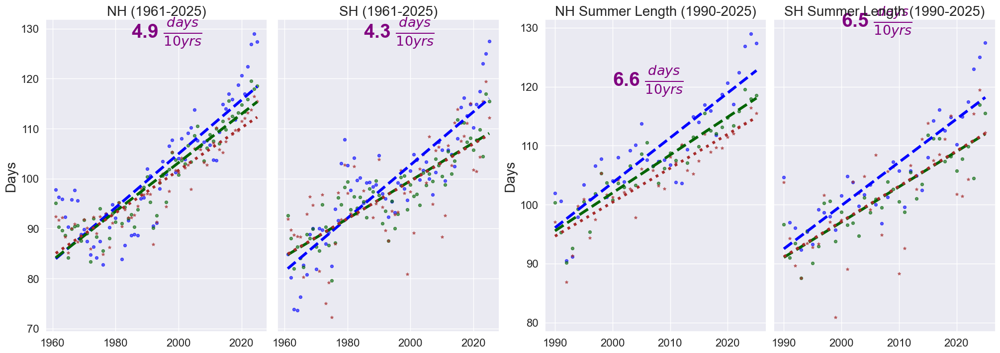

CPU times: user 208 ms, sys: 11.2 ms, total: 219 ms
Wall time: 218 ms


In [33]:
%%time

# takes 30 sec


# create blank fig
fig = plt.figure(figsize = (20,7), layout='constrained')

# Full Time Period NH
ax1 = fig.add_subplot(1,4,1)

# linear fits for slope
x_land = nh_land_full.time.dt.year.values
y_land = nh_land_full[v].values
coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
poly_land = np.poly1d(coefs_land)
slope_land = np.round(coefs_land[0],2)
slope_land_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_land)
ss_total = np.sum((y_land - ymean)**2)
ss_res = np.sum((y_land - poly_land(x_land))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_land = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_coast = nh_coast_full.time.dt.year.values
y_coast = nh_coast_full[v].values
coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
poly_coast = np.poly1d(coefs_coast)
slope_coast = np.round(coefs_coast[0],2)
slope_coast_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_coast)
ss_total = np.sum((y_coast - ymean)**2)
ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_coast = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_ocean = nh_ocean_full.time.dt.year.values
y_ocean = nh_ocean_full[v].values
coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
poly_ocean = np.poly1d(coefs_ocean)
slope_ocean = np.round(coefs_ocean[0],2)
slope_ocean_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_ocean)
ss_total = np.sum((y_ocean - ymean)**2)
ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_ocean = np.round(1 - (ss_res / ss_total),2)

# plot data
ax1.scatter(x_ocean, y_ocean, label="NH Ocean", c="blue", s=s, alpha=alpha)
ax1.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
ax1.scatter(x_coast, y_coast, label="NH Coast", c="darkgreen", s=s, alpha=alpha)
ax1.plot(x_coast, poly_coast(x_coast), linestyle="dashed", linewidth=lw, color='darkgreen', 
     label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
ax1.scatter(x_land, y_land, label="NH Inland", marker='*', facecolors='brown', edgecolors='brown', s=s, alpha=alpha)
ax1.plot(x_land, poly_land(x_land), linestyle="dotted", linewidth=lw, color='brown',
     label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
ax1.set_title("NH (1961-2025)", fontsize = fs)
# Annotation
ann_y = (ax1.get_yticks())[-3]+8
ann_x = np.mean(ax1.get_xticks())-5
# plot shows mean slope across all surface types for clarity
mean_slope = np.sqrt(slope_ocean**2 + slope_coast**2 + slope_land**2)/np.sqrt(3) * 10 # to get days per decade
if (slope_ocean < 0):
    mean_slope = mean_slope * -1
ax1.text(ann_x, ann_y, 
         ''+str(np.round(mean_slope,1))+r' $\frac{days}{10 yrs}$', fontsize=28, color='purple', fontweight='bold')
         #''+str(np.round((slope_ocean+slope_land)*5,1))+r' $\frac{days}{decade}$', fontsize=28, color='purple', fontweight='bold')
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=16)
if i < 2:
    ylabel = 'DOY'
else:
    ylabel = 'Days'
ax1.set_ylabel(ylabel, fontsize=fs)
#ax1.legend(loc='best')

# Full time period SH
ax2 = fig.add_subplot(1,4,2, sharey=ax1)

# linear fits for slope
x_land = sh_land_full.time.dt.year.values
y_land = sh_land_full[v].values
coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
poly_land = np.poly1d(coefs_land)
slope_land = np.round(coefs_land[0],2)
slope_land_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_land)
ss_total = np.sum((y_land - ymean)**2)
ss_res = np.sum((y_land - poly_land(x_land))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_land = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_coast = sh_coast_full.time.dt.year.values
y_coast = sh_coast_full[v].values
coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
poly_coast = np.poly1d(coefs_coast)
slope_coast = np.round(coefs_coast[0],2)
slope_coast_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_coast)
ss_total = np.sum((y_coast - ymean)**2)
ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_coast = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_ocean = sh_ocean_full.time.dt.year.values
y_ocean = sh_ocean_full[v].values
coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
poly_ocean = np.poly1d(coefs_ocean)
slope_ocean = np.round(coefs_ocean[0],2)
slope_ocean_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_ocean)
ss_total = np.sum((y_ocean - ymean)**2)
ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_ocean = np.round(1 - (ss_res / ss_total),2)

# plot data
ax2.scatter(x_ocean, y_ocean, label="SH Ocean", c="blue", s=s, alpha=alpha)
ax2.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
ax2.scatter(x_coast, y_coast, label="SH Coast", c="darkgreen", s=s, alpha=alpha)
ax2.plot(x_coast, poly_coast(x_coast), linestyle="dashed", linewidth=lw, color='darkgreen', 
     label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
ax2.scatter(x_land, y_land, label="SH Inland", marker='*', facecolors='brown', edgecolors='brown', s=s, alpha=alpha)
ax2.plot(x_land, poly_land(x_land), linestyle="dotted", linewidth=lw, color='brown',
     label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
ax2.set_title("SH (1961-2025)", fontsize = fs)
# Annotation
ann_y = (ax2.get_yticks())[-3]+8
ann_x = np.mean(ax2.get_xticks())-5
# plot shows mean slope across all surface types for clarity
mean_slope = np.sqrt(slope_ocean**2 + slope_coast**2 + slope_land**2)/np.sqrt(3) * 10 # to get days per decade
if (slope_ocean < 0):
    mean_slope = mean_slope * -1
ax2.text(ann_x, ann_y, 
         ''+str(np.round(mean_slope,1))+r' $\frac{days}{10 yrs}$', fontsize=28, color='purple', fontweight='bold')
# ax2.text(np.min(x_land)+10, np.max(y_ocean)-2, 
#          r'$\frac{\Delta}{\Delta t} \approx $'+str(np.round((slope_ocean+slope_land)*5,1)), fontsize=28, color='purple', fontweight='bold')
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=6, labelleft=False)
#ax2.legend(loc='best')


# Analysis time period NH
ax3 = fig.add_subplot(1,4,3)#, sharey=ax1)

# linear fits for slope
x_land = nh_land_an.time.dt.year.values
y_land = nh_land_an[v].values
coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
poly_land = np.poly1d(coefs_land)
slope_land = np.round(coefs_land[0],2)
slope_land_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_land)
ss_total = np.sum((y_land - ymean)**2)
ss_res = np.sum((y_land - poly_land(x_land))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_land = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_coast = nh_coast_an.time.dt.year.values
y_coast = nh_coast_an[v].values
coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
poly_coast = np.poly1d(coefs_coast)
slope_coast = np.round(coefs_coast[0],2)
slope_coast_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_coast)
ss_total = np.sum((y_coast - ymean)**2)
ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_coast = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_ocean = nh_ocean_an.time.dt.year.values
y_ocean = nh_ocean_an[v].values
coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
poly_ocean = np.poly1d(coefs_ocean)
slope_ocean = np.round(coefs_ocean[0],2)
slope_ocean_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_ocean)
ss_total = np.sum((y_ocean - ymean)**2)
ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_ocean = np.round(1 - (ss_res / ss_total),2)

# plot data
ax3.scatter(x_ocean, y_ocean, label="NH Ocean", c="blue", s=s, alpha=alpha)
ax3.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
ax3.scatter(x_coast, y_coast, label="NH Coast", c="darkgreen", s=s, alpha=alpha)
ax3.plot(x_coast, poly_coast(x_coast), linestyle="dashed", linewidth=lw, color='darkgreen', 
     label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
ax3.scatter(x_land, y_land, label="NH Inland", marker='*', facecolors='brown', edgecolors='brown', s=s, alpha=alpha)
ax3.plot(x_land, poly_land(x_land), linestyle="dotted", linewidth=lw, color='brown',
     label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
ax3.set_title("NH Summer Length (1990-2025)", fontsize = fs)
# Annotation - units in per decade
ann_y = (ax3.get_yticks())[-3]
ann_x = np.mean(ax3.get_xticks())-5
# plot shows mean slope across all surface types for clarity
mean_slope = np.sqrt(slope_ocean**2 + slope_coast**2 + slope_land**2)/np.sqrt(3) * 10 # to get days per decade
if (slope_ocean < 0):
    mean_slope = mean_slope * -1
ax3.text(ann_x, ann_y, 
         ''+str(np.round(mean_slope,1))+r' $\frac{days}{10 yrs}$', fontsize=28, color='purple', fontweight='bold')
ax3.set_ylabel('Days', fontsize=fs)
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=16, labelleft=True)
#ax3.legend(loc='best')


# Analysis time period SH
ax4 = fig.add_subplot(1,4,4, sharey=ax3)

# linear fits for slope
x_land = sh_land_an.time.dt.year.values
y_land = sh_land_an[v].values
coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
poly_land = np.poly1d(coefs_land)
slope_land = np.round(coefs_land[0],2)
slope_land_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_land)
ss_total = np.sum((y_land - ymean)**2)
ss_res = np.sum((y_land - poly_land(x_land))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_land = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_coast = sh_coast_an.time.dt.year.values
y_coast = sh_coast_an[v].values
coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
poly_coast = np.poly1d(coefs_coast)
slope_coast = np.round(coefs_coast[0],2)
slope_coast_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_coast)
ss_total = np.sum((y_coast - ymean)**2)
ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_coast = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_ocean = sh_ocean_an.time.dt.year.values
y_ocean = sh_ocean_an[v].values
coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
poly_ocean = np.poly1d(coefs_ocean)
slope_ocean = np.round(coefs_ocean[0],2)
slope_ocean_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_ocean)
ss_total = np.sum((y_ocean - ymean)**2)
ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_ocean = np.round(1 - (ss_res / ss_total),2)

# plot data
ax4.scatter(x_ocean, y_ocean, label="SH Ocean", c="blue", s=s, alpha=alpha)
ax4.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
ax4.scatter(x_coast, y_coast, label="SH Coast", c="darkgreen", s=s, alpha=alpha)
ax4.plot(x_coast, poly_coast(x_coast), linestyle="dashed", linewidth=lw, color='darkgreen', 
     label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
ax4.scatter(x_land, y_land, label="SH Inland", marker='*', facecolors='brown', edgecolors='brown', s=s, alpha=alpha)
ax4.plot(x_land, poly_land(x_land), linestyle="dotted", linewidth=lw, color='brown',
     label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
ax4.set_title("SH Summer Length (1990-2025)", fontsize = fs)
# Annotation - units in per decade
ann_y = (ax4.get_yticks())[-3]+10
ann_x = np.mean(ax4.get_xticks())-5
    # plot shows mean slope across all surface types for clarity
mean_slope = np.sqrt(slope_ocean**2 + slope_coast**2 + slope_land**2)/np.sqrt(3) * 10 # to get days per decade
if (slope_ocean < 0):
    mean_slope = mean_slope * -1
ax4.text(ann_x, ann_y, 
         ''+str(np.round(mean_slope,1))+r' $\frac{days}{10 yrs}$', fontsize=28, color='purple', fontweight='bold')

plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=6, labelleft=False)
#ax3.legend(loc='best')


#plt.tight_layout()
plt.show()

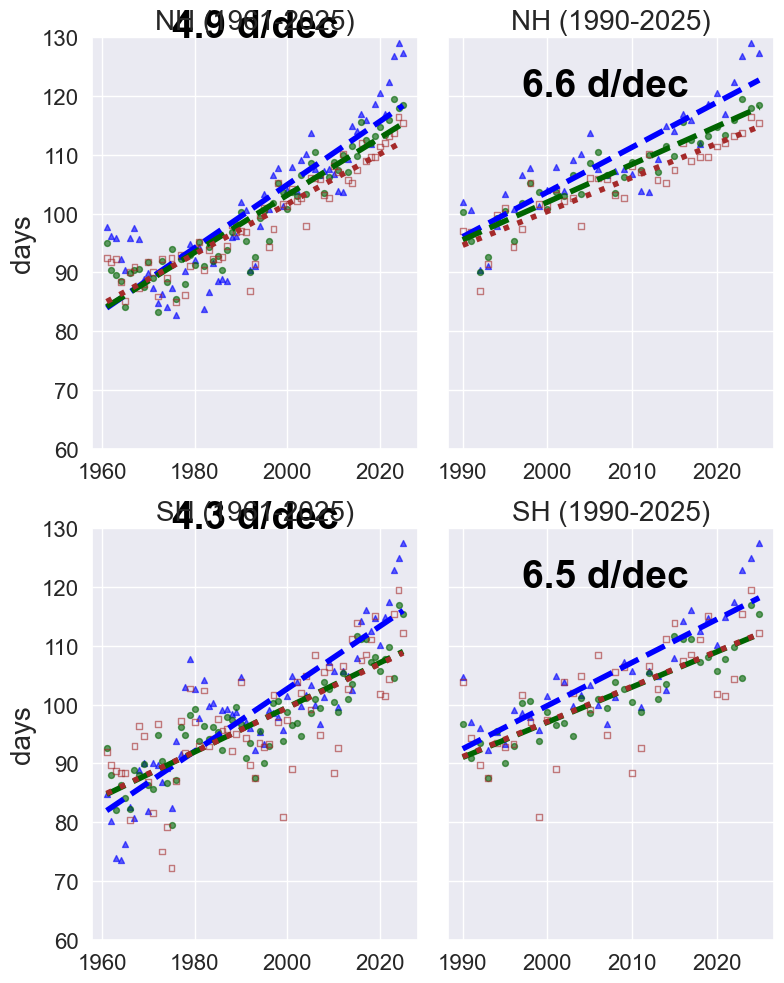

CPU times: user 160 ms, sys: 8.74 ms, total: 168 ms
Wall time: 168 ms


In [35]:
%%time

# takes 30 sec
#markers
l_m = 's'
o_m = '^'
c_m = 'o'


# create blank fig
fig = plt.figure(figsize = (8,10), layout='constrained')

# Full Time Period NH
ax1 = fig.add_subplot(2,2,1)

# linear fits for slope
x_land = nh_land_full.time.dt.year.values
y_land = nh_land_full[v].values
coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
poly_land = np.poly1d(coefs_land)
slope_land = np.round(coefs_land[0],2)
slope_land_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_land)
ss_total = np.sum((y_land - ymean)**2)
ss_res = np.sum((y_land - poly_land(x_land))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_land = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_coast = nh_coast_full.time.dt.year.values
y_coast = nh_coast_full[v].values
coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
poly_coast = np.poly1d(coefs_coast)
slope_coast = np.round(coefs_coast[0],2)
slope_coast_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_coast)
ss_total = np.sum((y_coast - ymean)**2)
ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_coast = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_ocean = nh_ocean_full.time.dt.year.values
y_ocean = nh_ocean_full[v].values
coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
poly_ocean = np.poly1d(coefs_ocean)
slope_ocean = np.round(coefs_ocean[0],2)
slope_ocean_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_ocean)
ss_total = np.sum((y_ocean - ymean)**2)
ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_ocean = np.round(1 - (ss_res / ss_total),2)

# plot data
ax1.scatter(x_ocean, y_ocean, label="NH Ocean", c="blue", s=s, marker=o_m, alpha=alpha)
ax1.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
ax1.scatter(x_coast, y_coast, label="NH Coast", c="darkgreen", s=s, marker=c_m, alpha=alpha)
ax1.plot(x_coast, poly_coast(x_coast), linestyle="dashed", linewidth=lw, color='darkgreen', 
     label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
ax1.scatter(x_land, y_land, label="NH Inland", marker=l_m, facecolors='none', edgecolors='brown', s=s, alpha=alpha)
ax1.plot(x_land, poly_land(x_land), linestyle="dotted", linewidth=lw, color='brown',
     label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
ax1.set_title("NH (1961-2025)", fontsize = fs)
# Annotation
ann_y = (ax1.get_yticks())[-3]+10
ann_x = np.mean(ax1.get_xticks())-15
# plot shows mean slope across all surface types for clarity
mean_slope = np.sqrt(slope_ocean**2 + slope_coast**2 + slope_land**2)/np.sqrt(3) * 10 # to get days per decade
if (slope_ocean < 0):
    mean_slope = mean_slope * -1
ax1.text(ann_x, ann_y, 
         ''+str(np.round(mean_slope,1))+r' d/dec', fontsize=28, color='black', fontweight='bold')
         #''+str(np.round((slope_ocean+slope_land)*5,1))+r' $\frac{days}{decade}$', fontsize=28, color='purple', fontweight='bold')
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=16)
if i < 2:
    ylabel = 'DOY'
else:
    ylabel = 'days'
ax1.set_ylabel(ylabel, fontsize=fs)
ax1.set_ylim(60,130)
#ax1.legend(loc='best')

# Full time period SH
ax2 = fig.add_subplot(2,2,3)#, sharey=ax1)

# linear fits for slope
x_land = sh_land_full.time.dt.year.values
y_land = sh_land_full[v].values
coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
poly_land = np.poly1d(coefs_land)
slope_land = np.round(coefs_land[0],2)
slope_land_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_land)
ss_total = np.sum((y_land - ymean)**2)
ss_res = np.sum((y_land - poly_land(x_land))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_land = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_coast = sh_coast_full.time.dt.year.values
y_coast = sh_coast_full[v].values
coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
poly_coast = np.poly1d(coefs_coast)
slope_coast = np.round(coefs_coast[0],2)
slope_coast_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_coast)
ss_total = np.sum((y_coast - ymean)**2)
ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_coast = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_ocean = sh_ocean_full.time.dt.year.values
y_ocean = sh_ocean_full[v].values
coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
poly_ocean = np.poly1d(coefs_ocean)
slope_ocean = np.round(coefs_ocean[0],2)
slope_ocean_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_ocean)
ss_total = np.sum((y_ocean - ymean)**2)
ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_ocean = np.round(1 - (ss_res / ss_total),2)

# plot data
ax2.scatter(x_ocean, y_ocean, label="SH Ocean", c="blue", s=s, marker=o_m, alpha=alpha)
ax2.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
ax2.scatter(x_coast, y_coast, label="SH Coast", c="darkgreen", s=s, marker=c_m, alpha=alpha)
ax2.plot(x_coast, poly_coast(x_coast), linestyle="dashed", linewidth=lw, color='darkgreen', 
     label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
ax2.scatter(x_land, y_land, label="SH Inland", marker=l_m, facecolors='none', edgecolors='brown', s=s, alpha=alpha)
ax2.plot(x_land, poly_land(x_land), linestyle="dotted", linewidth=lw, color='brown',
     label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
ax2.set_title("SH (1961-2025)", fontsize = fs)
ax2.set_ylabel('days', fontsize=fs)
# Annotation
ann_y = (ax2.get_yticks())[-3]+10
ann_x = np.mean(ax2.get_xticks())-15
# plot shows mean slope across all surface types for clarity
mean_slope = np.sqrt(slope_ocean**2 + slope_coast**2 + slope_land**2)/np.sqrt(3) * 10 # to get days per decade
if (slope_ocean < 0):
    mean_slope = mean_slope * -1
ax2.text(ann_x, ann_y, 
         ''+str(np.round(mean_slope,1))+r' d/dec', fontsize=28, color='black', fontweight='bold')
# ax2.text(np.min(x_land)+10, np.max(y_ocean)-2, 
#          r'$\frac{\Delta}{\Delta t} \approx $'+str(np.round((slope_ocean+slope_land)*5,1)), fontsize=28, color='purple', fontweight='bold')
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=16, labelleft=True)
ax2.set_ylim(60,130)
#ax2.legend(loc='best')


# Analysis time period NH
ax3 = fig.add_subplot(2,2,2, sharey=ax1)

# linear fits for slope
x_land = nh_land_an.time.dt.year.values
y_land = nh_land_an[v].values
coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
poly_land = np.poly1d(coefs_land)
slope_land = np.round(coefs_land[0],2)
slope_land_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_land)
ss_total = np.sum((y_land - ymean)**2)
ss_res = np.sum((y_land - poly_land(x_land))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_land = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_coast = nh_coast_an.time.dt.year.values
y_coast = nh_coast_an[v].values
coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
poly_coast = np.poly1d(coefs_coast)
slope_coast = np.round(coefs_coast[0],2)
slope_coast_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_coast)
ss_total = np.sum((y_coast - ymean)**2)
ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_coast = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_ocean = nh_ocean_an.time.dt.year.values
y_ocean = nh_ocean_an[v].values
coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
poly_ocean = np.poly1d(coefs_ocean)
slope_ocean = np.round(coefs_ocean[0],2)
slope_ocean_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_ocean)
ss_total = np.sum((y_ocean - ymean)**2)
ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_ocean = np.round(1 - (ss_res / ss_total),2)

# plot data
ax3.scatter(x_ocean, y_ocean, label="NH Ocean", c="blue", s=s, marker=o_m, alpha=alpha)
ax3.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
ax3.scatter(x_coast, y_coast, label="NH Coast", c="darkgreen", s=s, marker=c_m, alpha=alpha)
ax3.plot(x_coast, poly_coast(x_coast), linestyle="dashed", linewidth=lw, color='darkgreen', 
     label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
ax3.scatter(x_land, y_land, label="NH Inland", marker=l_m, facecolors='none', edgecolors='brown', s=s, alpha=alpha)
ax3.plot(x_land, poly_land(x_land), linestyle="dotted", linewidth=lw, color='brown',
     label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
ax3.set_title("NH (1990-2025)", fontsize = fs)
# Annotation - units in per decade
ann_y = (ax3.get_yticks())[-3]+10
ann_x = np.mean(ax3.get_xticks())-8
# plot shows mean slope across all surface types for clarity
mean_slope = np.sqrt(slope_ocean**2 + slope_coast**2 + slope_land**2)/np.sqrt(3) * 10 # to get days per decade
if (slope_ocean < 0):
    mean_slope = mean_slope * -1
ax3.text(ann_x, ann_y, 
         ''+str(np.round(mean_slope,1))+r' d/dec', fontsize=28, color='black', fontweight='bold')
#ax3.set_ylabel('Days', fontsize=fs)
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=16, labelleft=False)
#ax3.legend(loc='best')


# Analysis time period SH
ax4 = fig.add_subplot(2,2,4, sharey=ax2)

# linear fits for slope
x_land = sh_land_an.time.dt.year.values
y_land = sh_land_an[v].values
coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
poly_land = np.poly1d(coefs_land)
slope_land = np.round(coefs_land[0],2)
slope_land_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_land)
ss_total = np.sum((y_land - ymean)**2)
ss_res = np.sum((y_land - poly_land(x_land))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_land = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_coast = sh_coast_an.time.dt.year.values
y_coast = sh_coast_an[v].values
coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
poly_coast = np.poly1d(coefs_coast)
slope_coast = np.round(coefs_coast[0],2)
slope_coast_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_coast)
ss_total = np.sum((y_coast - ymean)**2)
ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_coast = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_ocean = sh_ocean_an.time.dt.year.values
y_ocean = sh_ocean_an[v].values
coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
poly_ocean = np.poly1d(coefs_ocean)
slope_ocean = np.round(coefs_ocean[0],2)
slope_ocean_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_ocean)
ss_total = np.sum((y_ocean - ymean)**2)
ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_ocean = np.round(1 - (ss_res / ss_total),2)

# plot data
ax4.scatter(x_ocean, y_ocean, label="SH Ocean", c="blue", s=s, marker=o_m, alpha=alpha)
ax4.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
ax4.scatter(x_coast, y_coast, label="SH Coast", c="darkgreen", s=s, marker=c_m, alpha=alpha)
ax4.plot(x_coast, poly_coast(x_coast), linestyle="dashed", linewidth=lw, color='darkgreen', 
     label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
ax4.scatter(x_land, y_land, label="SH Inland", marker=l_m, facecolors='none', edgecolors='brown', s=s, alpha=alpha)
ax4.plot(x_land, poly_land(x_land), linestyle="dotted", linewidth=lw, color='brown',
     label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
ax4.set_title("SH (1990-2025)", fontsize = fs)
# Annotation - units in per decade
ann_y = (ax4.get_yticks())[-3]+10
ann_x = np.mean(ax4.get_xticks())-8
    # plot shows mean slope across all surface types for clarity
mean_slope = np.sqrt(slope_ocean**2 + slope_coast**2 + slope_land**2)/np.sqrt(3) * 10 # to get days per decade
if (slope_ocean < 0):
    mean_slope = mean_slope * -1
ax4.text(ann_x, ann_y, 
         ''+str(np.round(mean_slope,1))+r' d/dec', fontsize=28, color='black', fontweight='bold')

plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=6, labelleft=False)
#ax3.legend(loc='best')


plt.tight_layout()
# plt.savefig("./Plots/summer_length_2x2_plot.png",bbox_inches='tight')
# plt.savefig("./Plots/summer_length_2x2_plot.pdf",bbox_inches='tight')
plt.show()


## ** NOTE the slopes on Summer Length in the above plots are averaged (in quadrature?) and not the same as when fitting all the data points as a group, which is what is done below in the categorical scatter plots, so in the paper, I am using the slopes from the categorical scatter plots. **

#### Reformatted Heat Only

In [36]:
v = 'SummerHeat'

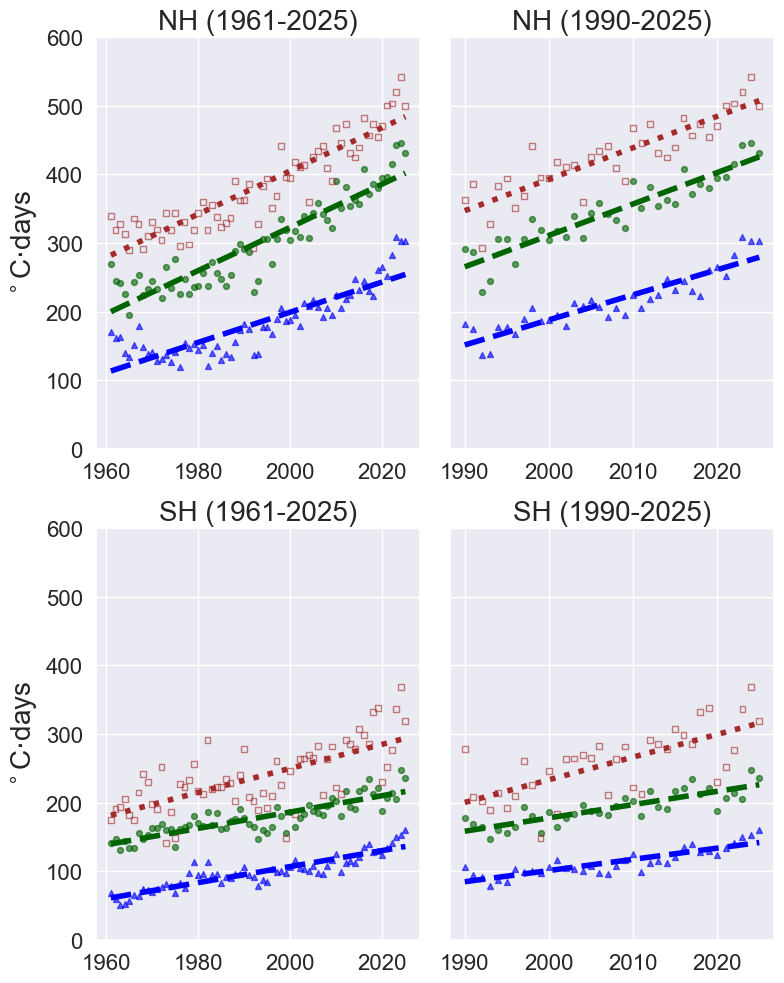

CPU times: user 154 ms, sys: 6.86 ms, total: 161 ms
Wall time: 161 ms


In [37]:
%%time

# takes 30 sec


# create blank fig
fig = plt.figure(figsize = (8,10), layout='constrained')

# Full Time Period NH
ax1 = fig.add_subplot(2,2,1)

# linear fits for slope
x_land = nh_land_full.time.dt.year.values
y_land = nh_land_full[v].values
coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
poly_land = np.poly1d(coefs_land)
slope_land = np.round(coefs_land[0],2)
slope_land_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_land)
ss_total = np.sum((y_land - ymean)**2)
ss_res = np.sum((y_land - poly_land(x_land))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_land = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_coast = nh_coast_full.time.dt.year.values
y_coast = nh_coast_full[v].values
coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
poly_coast = np.poly1d(coefs_coast)
slope_coast = np.round(coefs_coast[0],2)
slope_coast_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_coast)
ss_total = np.sum((y_coast - ymean)**2)
ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_coast = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_ocean = nh_ocean_full.time.dt.year.values
y_ocean = nh_ocean_full[v].values
coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
poly_ocean = np.poly1d(coefs_ocean)
slope_ocean = np.round(coefs_ocean[0],2)
slope_ocean_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_ocean)
ss_total = np.sum((y_ocean - ymean)**2)
ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_ocean = np.round(1 - (ss_res / ss_total),2)

# plot data
ax1.scatter(x_ocean, y_ocean, label="NH Ocean", c="blue", s=s, marker=o_m, alpha=alpha)
ax1.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
ax1.scatter(x_coast, y_coast, label="NH Coast", c="darkgreen", s=s, marker=c_m, alpha=alpha)
ax1.plot(x_coast, poly_coast(x_coast), linestyle="dashed", linewidth=lw, color='darkgreen', 
     label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
ax1.scatter(x_land, y_land, label="NH Inland", marker=l_m, facecolors='none', edgecolors='brown', s=s, alpha=alpha)
ax1.plot(x_land, poly_land(x_land), linestyle="dotted", linewidth=lw, color='brown',
     label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
ax1.set_title("NH (1961-2025)", fontsize = fs)
# Annotation
ann_y = 500#(ax1.get_yticks())[-3]+10
ann_x = 1965#np.mean(ax1.get_xticks())-15
# plot shows mean slope across all surface types for clarity
mean_slope = np.sqrt(slope_ocean**2 + slope_coast**2 + slope_land**2)/np.sqrt(3) * 10 # to get days per decade
if (slope_ocean < 0):
    mean_slope = mean_slope * -1
# ax1.text(ann_x, ann_y, 
#          ''+str(np.round(mean_slope,1))+r' $^{\circ}$C Days/10 yr', fontsize=fs, color='black', fontweight='bold')

# ax1.text(ann_x, ann_y, 
#          ''+str(25.4)+r' $^{\circ}$C$\cdot$d/dec', fontsize=fs, color='black', fontweight='bold')

plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=16)
ax1.set_ylabel(r'$^\circ$C$\cdot$days', fontsize=fs)
ax1.set_ylim(0,600)
#ax1.legend(loc='best')

# Full time period SH
ax2 = fig.add_subplot(2,2,3)#, sharey=ax1)

# linear fits for slope
x_land = sh_land_full.time.dt.year.values
y_land = sh_land_full[v].values
coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
poly_land = np.poly1d(coefs_land)
slope_land = np.round(coefs_land[0],2)
slope_land_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_land)
ss_total = np.sum((y_land - ymean)**2)
ss_res = np.sum((y_land - poly_land(x_land))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_land = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_coast = sh_coast_full.time.dt.year.values
y_coast = sh_coast_full[v].values
coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
poly_coast = np.poly1d(coefs_coast)
slope_coast = np.round(coefs_coast[0],2)
slope_coast_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_coast)
ss_total = np.sum((y_coast - ymean)**2)
ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_coast = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_ocean = sh_ocean_full.time.dt.year.values
y_ocean = sh_ocean_full[v].values
coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
poly_ocean = np.poly1d(coefs_ocean)
slope_ocean = np.round(coefs_ocean[0],2)
slope_ocean_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_ocean)
ss_total = np.sum((y_ocean - ymean)**2)
ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_ocean = np.round(1 - (ss_res / ss_total),2)

# plot data
ax2.scatter(x_ocean, y_ocean, label="SH Ocean", c="blue", s=s, marker=o_m, alpha=alpha)
ax2.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
ax2.scatter(x_coast, y_coast, label="SH Coast", c="darkgreen", s=s, marker=c_m, alpha=alpha)
ax2.plot(x_coast, poly_coast(x_coast), linestyle="dashed", linewidth=lw, color='darkgreen', 
     label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
ax2.scatter(x_land, y_land, label="SH Inland", marker=l_m, facecolors='none', edgecolors='brown', s=s, alpha=alpha)
ax2.plot(x_land, poly_land(x_land), linestyle="dotted", linewidth=lw, color='brown',
     label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
ax2.set_title("SH (1961-2025)", fontsize = fs)
ax2.set_ylabel(r'$^\circ$C$\cdot$days', fontsize=fs)
# Annotation
#ann_y = (ax2.get_yticks())[-3]+10
#ann_x = np.mean(ax2.get_xticks())-15
# plot shows mean slope across all surface types for clarity
mean_slope = np.sqrt(slope_ocean**2 + slope_coast**2 + slope_land**2)/np.sqrt(3) * 10 # to get days per decade
if (slope_ocean < 0):
    mean_slope = mean_slope * -1
# ax2.text(ann_x, ann_y, 
#          ''+str(np.round(mean_slope,1))+r' $^{\circ}$C Days/10 yr', fontsize=fs, color='black', fontweight='bold')
# ax2.text(ann_x, ann_y, 
#          ''+str(11.5)+r' $^{\circ}$C$\cdot$d/dec', fontsize=fs, color='black', fontweight='bold')
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=16, labelleft=True)
ax2.set_ylim(0,600)
#ax2.legend(loc='best')


# Analysis time period NH
ax3 = fig.add_subplot(2,2,2, sharey=ax1)

# linear fits for slope
x_land = nh_land_an.time.dt.year.values
y_land = nh_land_an[v].values
coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
poly_land = np.poly1d(coefs_land)
slope_land = np.round(coefs_land[0],2)
slope_land_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_land)
ss_total = np.sum((y_land - ymean)**2)
ss_res = np.sum((y_land - poly_land(x_land))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_land = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_coast = nh_coast_an.time.dt.year.values
y_coast = nh_coast_an[v].values
coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
poly_coast = np.poly1d(coefs_coast)
slope_coast = np.round(coefs_coast[0],2)
slope_coast_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_coast)
ss_total = np.sum((y_coast - ymean)**2)
ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_coast = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_ocean = nh_ocean_an.time.dt.year.values
y_ocean = nh_ocean_an[v].values
coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
poly_ocean = np.poly1d(coefs_ocean)
slope_ocean = np.round(coefs_ocean[0],2)
slope_ocean_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_ocean)
ss_total = np.sum((y_ocean - ymean)**2)
ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_ocean = np.round(1 - (ss_res / ss_total),2)

# plot data
ax3.scatter(x_ocean, y_ocean, label="NH Ocean", c="blue", s=s, marker=o_m, alpha=alpha)
ax3.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
ax3.scatter(x_coast, y_coast, label="NH Coast", c="darkgreen", s=s, marker=c_m, alpha=alpha)
ax3.plot(x_coast, poly_coast(x_coast), linestyle="dashed", linewidth=lw, color='darkgreen', 
     label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
ax3.scatter(x_land, y_land, label="NH Inland", marker=l_m, facecolors='none', edgecolors='brown', s=s, alpha=alpha)
ax3.plot(x_land, poly_land(x_land), linestyle="dotted", linewidth=lw, color='brown',
     label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
ax3.set_title("NH (1990-2025)", fontsize = fs)
# Annotation - units in per decade
#ann_y = (ax3.get_yticks())[-3]+10
ann_x = 1993#np.mean(ax3.get_xticks())-8
# plot shows mean slope across all surface types for clarity
mean_slope = np.sqrt(slope_ocean**2 + slope_coast**2 + slope_land**2)/np.sqrt(3) * 10 # to get days per decade
if (slope_ocean < 0):
    mean_slope = mean_slope * -1
# ax3.text(ann_x, ann_y, 
#          ''+str(np.round(mean_slope,1))+r' $^{\circ}$C Days/10 yr', fontsize=fs, color='black', fontweight='bold')
# ax3.text(ann_x, ann_y, 
#          ''+str(39.0)+r' $^{\circ}$C$\cdot$d/dec', fontsize=fs, color='black', fontweight='bold')
#ax3.set_ylabel('Days', fontsize=fs)
#ax3.set_ylabel('Days', fontsize=fs)
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=16, labelleft=False)
#ax3.legend(loc='best')


# Analysis time period SH
ax4 = fig.add_subplot(2,2,4, sharey=ax2)

# linear fits for slope
x_land = sh_land_an.time.dt.year.values
y_land = sh_land_an[v].values
coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
poly_land = np.poly1d(coefs_land)
slope_land = np.round(coefs_land[0],2)
slope_land_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_land)
ss_total = np.sum((y_land - ymean)**2)
ss_res = np.sum((y_land - poly_land(x_land))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_land = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_coast = sh_coast_an.time.dt.year.values
y_coast = sh_coast_an[v].values
coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
poly_coast = np.poly1d(coefs_coast)
slope_coast = np.round(coefs_coast[0],2)
slope_coast_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_coast)
ss_total = np.sum((y_coast - ymean)**2)
ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_coast = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_ocean = sh_ocean_an.time.dt.year.values
y_ocean = sh_ocean_an[v].values
coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
poly_ocean = np.poly1d(coefs_ocean)
slope_ocean = np.round(coefs_ocean[0],2)
slope_ocean_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_ocean)
ss_total = np.sum((y_ocean - ymean)**2)
ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_ocean = np.round(1 - (ss_res / ss_total),2)

# plot data
ax4.scatter(x_ocean, y_ocean, label="SH Ocean", c="blue", s=s, marker=o_m, alpha=alpha)
ax4.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
ax4.scatter(x_coast, y_coast, label="SH Coast", c="darkgreen", s=s, marker=c_m, alpha=alpha)
ax4.plot(x_coast, poly_coast(x_coast), linestyle="dashed", linewidth=lw, color='darkgreen', 
     label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
ax4.scatter(x_land, y_land, label="SH Inland", marker=l_m, facecolors='none', edgecolors='brown', s=s, alpha=alpha)
ax4.plot(x_land, poly_land(x_land), linestyle="dotted", linewidth=lw, color='brown',
     label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
ax4.set_title("SH (1990-2025)", fontsize = fs)
# Annotation - units in per decade
#ann_y = (ax4.get_yticks())[-3]+10
ann_x = 1993#np.mean(ax4.get_xticks())-8
    # plot shows mean slope across all surface types for clarity
mean_slope = np.sqrt(slope_ocean**2 + slope_coast**2 + slope_land**2)/np.sqrt(3) * 10 # to get days per decade
if (slope_ocean < 0):
    mean_slope = mean_slope * -1
# ax4.text(ann_x, ann_y, 
#          ''+str(np.round(mean_slope,1))+r' $^{\circ}$C Days/10 yr', fontsize=fs, color='black', fontweight='bold')
# ax4.text(ann_x, ann_y, 
#          ''+str(16.0)+r' $^{\circ}$C$\cdot$d/dec', fontsize=fs, color='black', fontweight='bold')

plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=6, labelleft=False)
#ax3.legend(loc='best')


plt.tight_layout()
# plt.savefig("./Plots/summer_heat_2x2_plot.png",bbox_inches='tight')
# plt.savefig("./Plots/summer_heat_2x2_plot.pdf",bbox_inches='tight')
plt.show()


#### no mean slope labels

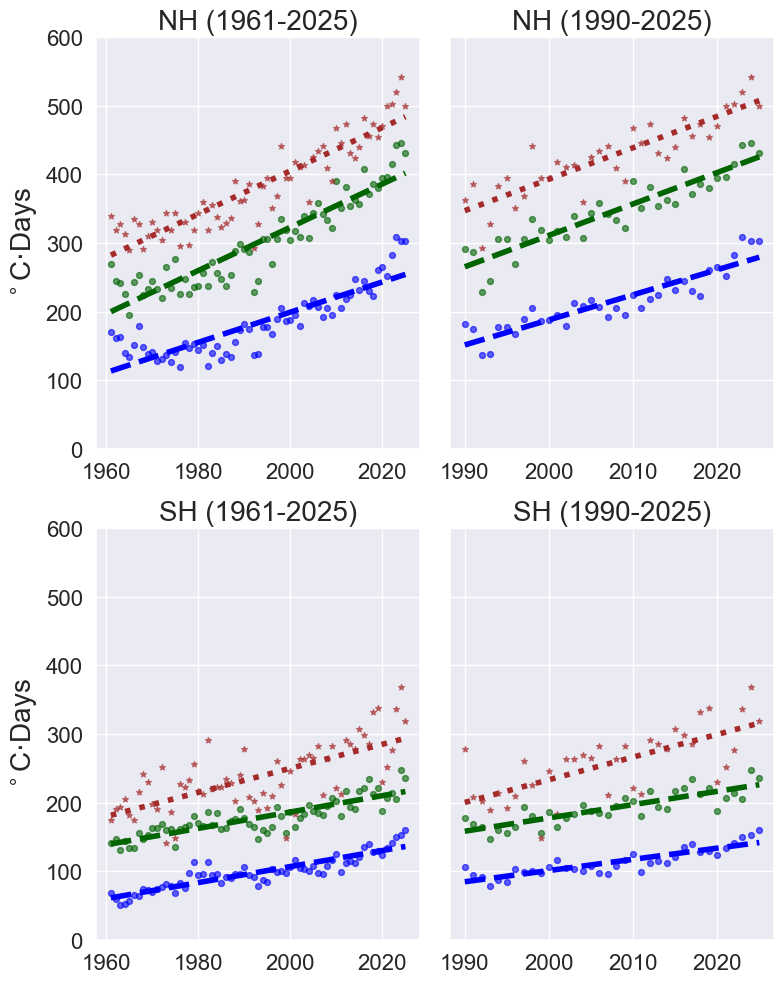

CPU times: user 165 ms, sys: 7.69 ms, total: 173 ms
Wall time: 324 ms


In [38]:
%%time

# takes 30 sec


# create blank fig
fig = plt.figure(figsize = (8,10), layout='constrained')

# Full Time Period NH
ax1 = fig.add_subplot(2,2,1)

# linear fits for slope
x_land = nh_land_full.time.dt.year.values
y_land = nh_land_full[v].values
coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
poly_land = np.poly1d(coefs_land)
slope_land = np.round(coefs_land[0],2)
slope_land_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_land)
ss_total = np.sum((y_land - ymean)**2)
ss_res = np.sum((y_land - poly_land(x_land))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_land = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_coast = nh_coast_full.time.dt.year.values
y_coast = nh_coast_full[v].values
coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
poly_coast = np.poly1d(coefs_coast)
slope_coast = np.round(coefs_coast[0],2)
slope_coast_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_coast)
ss_total = np.sum((y_coast - ymean)**2)
ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_coast = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_ocean = nh_ocean_full.time.dt.year.values
y_ocean = nh_ocean_full[v].values
coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
poly_ocean = np.poly1d(coefs_ocean)
slope_ocean = np.round(coefs_ocean[0],2)
slope_ocean_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_ocean)
ss_total = np.sum((y_ocean - ymean)**2)
ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_ocean = np.round(1 - (ss_res / ss_total),2)

# plot data
ax1.scatter(x_ocean, y_ocean, label="NH Ocean", c="blue", s=s, alpha=alpha)
ax1.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
ax1.scatter(x_coast, y_coast, label="NH Coast", c="darkgreen", s=s, alpha=alpha)
ax1.plot(x_coast, poly_coast(x_coast), linestyle="dashed", linewidth=lw, color='darkgreen', 
     label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
ax1.scatter(x_land, y_land, label="NH Inland", marker='*', facecolors='brown', edgecolors='brown', s=s, alpha=alpha)
ax1.plot(x_land, poly_land(x_land), linestyle="dotted", linewidth=lw, color='brown',
     label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
ax1.set_title("NH (1961-2025)", fontsize = fs)
# Annotation
ann_y = 500#(ax1.get_yticks())[-3]+10
ann_x = 1965#np.mean(ax1.get_xticks())-15
# plot shows mean slope across all surface types for clarity
mean_slope = np.sqrt(slope_ocean**2 + slope_coast**2 + slope_land**2)/np.sqrt(3) * 10 # to get days per decade
if (slope_ocean < 0):
    mean_slope = mean_slope * -1
# ax1.text(ann_x, ann_y, 
#          ''+str(np.round(mean_slope,1))+r' $^{\circ}$C Days/10 yr', fontsize=fs, color='black', fontweight='bold')

# ax1.text(ann_x, ann_y, 
#          ''+str(25.4)+r' $^{\circ}$C$\cdot$d/dec', fontsize=fs, color='black', fontweight='bold')

plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=16)
ax1.set_ylabel(r'$^\circ$C$\cdot$Days', fontsize=fs)
ax1.set_ylim(0,600)
#ax1.legend(loc='best')

# Full time period SH
ax2 = fig.add_subplot(2,2,3)#, sharey=ax1)

# linear fits for slope
x_land = sh_land_full.time.dt.year.values
y_land = sh_land_full[v].values
coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
poly_land = np.poly1d(coefs_land)
slope_land = np.round(coefs_land[0],2)
slope_land_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_land)
ss_total = np.sum((y_land - ymean)**2)
ss_res = np.sum((y_land - poly_land(x_land))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_land = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_coast = sh_coast_full.time.dt.year.values
y_coast = sh_coast_full[v].values
coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
poly_coast = np.poly1d(coefs_coast)
slope_coast = np.round(coefs_coast[0],2)
slope_coast_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_coast)
ss_total = np.sum((y_coast - ymean)**2)
ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_coast = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_ocean = sh_ocean_full.time.dt.year.values
y_ocean = sh_ocean_full[v].values
coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
poly_ocean = np.poly1d(coefs_ocean)
slope_ocean = np.round(coefs_ocean[0],2)
slope_ocean_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_ocean)
ss_total = np.sum((y_ocean - ymean)**2)
ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_ocean = np.round(1 - (ss_res / ss_total),2)

# plot data
ax2.scatter(x_ocean, y_ocean, label="SH Ocean", c="blue", s=s, alpha=alpha)
ax2.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
ax2.scatter(x_coast, y_coast, label="SH Coast", c="darkgreen", s=s, alpha=alpha)
ax2.plot(x_coast, poly_coast(x_coast), linestyle="dashed", linewidth=lw, color='darkgreen', 
     label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
ax2.scatter(x_land, y_land, label="SH Inland", marker='*', facecolors='brown', edgecolors='brown', s=s, alpha=alpha)
ax2.plot(x_land, poly_land(x_land), linestyle="dotted", linewidth=lw, color='brown',
     label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
ax2.set_title("SH (1961-2025)", fontsize = fs)
ax2.set_ylabel(r'$^\circ$C$\cdot$Days', fontsize=fs)
# Annotation
#ann_y = (ax2.get_yticks())[-3]+10
#ann_x = np.mean(ax2.get_xticks())-15
# plot shows mean slope across all surface types for clarity
mean_slope = np.sqrt(slope_ocean**2 + slope_coast**2 + slope_land**2)/np.sqrt(3) * 10 # to get days per decade
if (slope_ocean < 0):
    mean_slope = mean_slope * -1
# ax2.text(ann_x, ann_y, 
#          ''+str(np.round(mean_slope,1))+r' $^{\circ}$C Days/10 yr', fontsize=fs, color='black', fontweight='bold')
# ax2.text(ann_x, ann_y, 
#          ''+str(11.5)+r' $^{\circ}$C$\cdot$d/dec', fontsize=fs, color='black', fontweight='bold')
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=16, labelleft=True)
ax2.set_ylim(0,600)
#ax2.legend(loc='best')


# Analysis time period NH
ax3 = fig.add_subplot(2,2,2, sharey=ax1)

# linear fits for slope
x_land = nh_land_an.time.dt.year.values
y_land = nh_land_an[v].values
coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
poly_land = np.poly1d(coefs_land)
slope_land = np.round(coefs_land[0],2)
slope_land_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_land)
ss_total = np.sum((y_land - ymean)**2)
ss_res = np.sum((y_land - poly_land(x_land))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_land = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_coast = nh_coast_an.time.dt.year.values
y_coast = nh_coast_an[v].values
coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
poly_coast = np.poly1d(coefs_coast)
slope_coast = np.round(coefs_coast[0],2)
slope_coast_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_coast)
ss_total = np.sum((y_coast - ymean)**2)
ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_coast = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_ocean = nh_ocean_an.time.dt.year.values
y_ocean = nh_ocean_an[v].values
coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
poly_ocean = np.poly1d(coefs_ocean)
slope_ocean = np.round(coefs_ocean[0],2)
slope_ocean_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_ocean)
ss_total = np.sum((y_ocean - ymean)**2)
ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_ocean = np.round(1 - (ss_res / ss_total),2)

# plot data
ax3.scatter(x_ocean, y_ocean, label="NH Ocean", c="blue", s=s, alpha=alpha)
ax3.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
ax3.scatter(x_coast, y_coast, label="NH Coast", c="darkgreen", s=s, alpha=alpha)
ax3.plot(x_coast, poly_coast(x_coast), linestyle="dashed", linewidth=lw, color='darkgreen', 
     label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
ax3.scatter(x_land, y_land, label="NH Inland", marker='*', facecolors='brown', edgecolors='brown', s=s, alpha=alpha)
ax3.plot(x_land, poly_land(x_land), linestyle="dotted", linewidth=lw, color='brown',
     label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
ax3.set_title("NH (1990-2025)", fontsize = fs)
# Annotation - units in per decade
#ann_y = (ax3.get_yticks())[-3]+10
ann_x = 1993#np.mean(ax3.get_xticks())-8
# plot shows mean slope across all surface types for clarity
mean_slope = np.sqrt(slope_ocean**2 + slope_coast**2 + slope_land**2)/np.sqrt(3) * 10 # to get days per decade
if (slope_ocean < 0):
    mean_slope = mean_slope * -1
# ax3.text(ann_x, ann_y, 
#          ''+str(np.round(mean_slope,1))+r' $^{\circ}$C Days/10 yr', fontsize=fs, color='black', fontweight='bold')
# ax3.text(ann_x, ann_y, 
#          ''+str(39.0)+r' $^{\circ}$C$\cdot$d/dec', fontsize=fs, color='black', fontweight='bold')
#ax3.set_ylabel('Days', fontsize=fs)
#ax3.set_ylabel('Days', fontsize=fs)
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=16, labelleft=False)
#ax3.legend(loc='best')


# Analysis time period SH
ax4 = fig.add_subplot(2,2,4, sharey=ax2)

# linear fits for slope
x_land = sh_land_an.time.dt.year.values
y_land = sh_land_an[v].values
coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
poly_land = np.poly1d(coefs_land)
slope_land = np.round(coefs_land[0],2)
slope_land_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_land)
ss_total = np.sum((y_land - ymean)**2)
ss_res = np.sum((y_land - poly_land(x_land))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_land = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_coast = sh_coast_an.time.dt.year.values
y_coast = sh_coast_an[v].values
coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
poly_coast = np.poly1d(coefs_coast)
slope_coast = np.round(coefs_coast[0],2)
slope_coast_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_coast)
ss_total = np.sum((y_coast - ymean)**2)
ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_coast = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_ocean = sh_ocean_an.time.dt.year.values
y_ocean = sh_ocean_an[v].values
coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
poly_ocean = np.poly1d(coefs_ocean)
slope_ocean = np.round(coefs_ocean[0],2)
slope_ocean_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_ocean)
ss_total = np.sum((y_ocean - ymean)**2)
ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_ocean = np.round(1 - (ss_res / ss_total),2)

# plot data
ax4.scatter(x_ocean, y_ocean, label="SH Ocean", c="blue", s=s, alpha=alpha)
ax4.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
ax4.scatter(x_coast, y_coast, label="SH Coast", c="darkgreen", s=s, alpha=alpha)
ax4.plot(x_coast, poly_coast(x_coast), linestyle="dashed", linewidth=lw, color='darkgreen', 
     label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
ax4.scatter(x_land, y_land, label="SH Inland", marker='*', facecolors='brown', edgecolors='brown', s=s, alpha=alpha)
ax4.plot(x_land, poly_land(x_land), linestyle="dotted", linewidth=lw, color='brown',
     label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
ax4.set_title("SH (1990-2025)", fontsize = fs)
# Annotation - units in per decade
#ann_y = (ax4.get_yticks())[-3]+10
ann_x = 1993#np.mean(ax4.get_xticks())-8
    # plot shows mean slope across all surface types for clarity
mean_slope = np.sqrt(slope_ocean**2 + slope_coast**2 + slope_land**2)/np.sqrt(3) * 10 # to get days per decade
if (slope_ocean < 0):
    mean_slope = mean_slope * -1
# ax4.text(ann_x, ann_y, 
#          ''+str(np.round(mean_slope,1))+r' $^{\circ}$C Days/10 yr', fontsize=fs, color='black', fontweight='bold')
# ax4.text(ann_x, ann_y, 
#          ''+str(16.0)+r' $^{\circ}$C$\cdot$d/dec', fontsize=fs, color='black', fontweight='bold')

plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=6, labelleft=False)
#ax3.legend(loc='best')


plt.tight_layout()
#plt.savefig("./Plots/summer_heat_4x4_plot.png")
plt.show()


#### reset plot vars

In [39]:
plot_vars = list(ds.data_vars)
remove_me = {'SummerTmax','SummerMeanHS','SummerRMSE','SummerR2','lsm','Coastal','SummerMeanT'}
plot_vars = [item for item in plot_vars if item not in remove_me]
plot_vars

['SummerStart', 'SummerEnd', 'SummerHeat', 'SummerLength', 'SummerlikeDays']

### Reformatted without slopes for paper and only 1990-2025

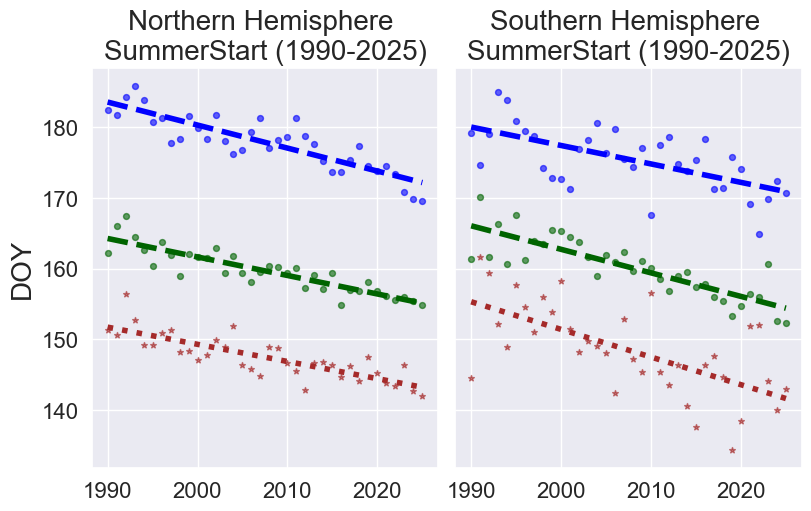

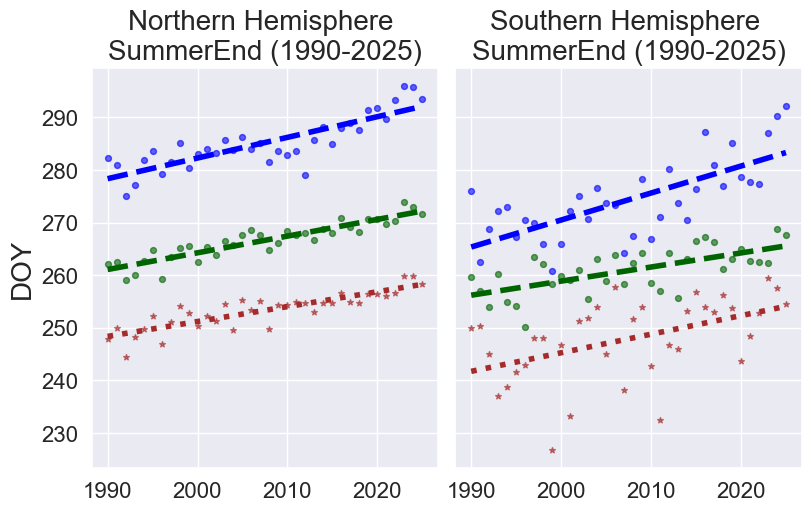

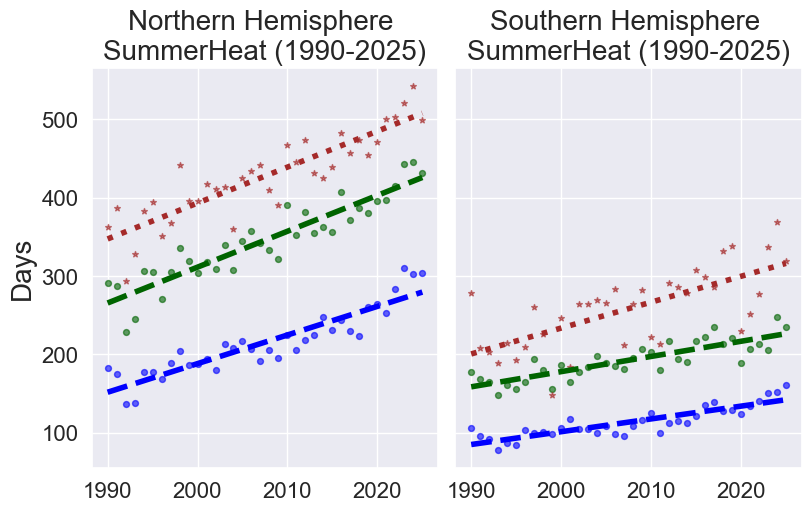

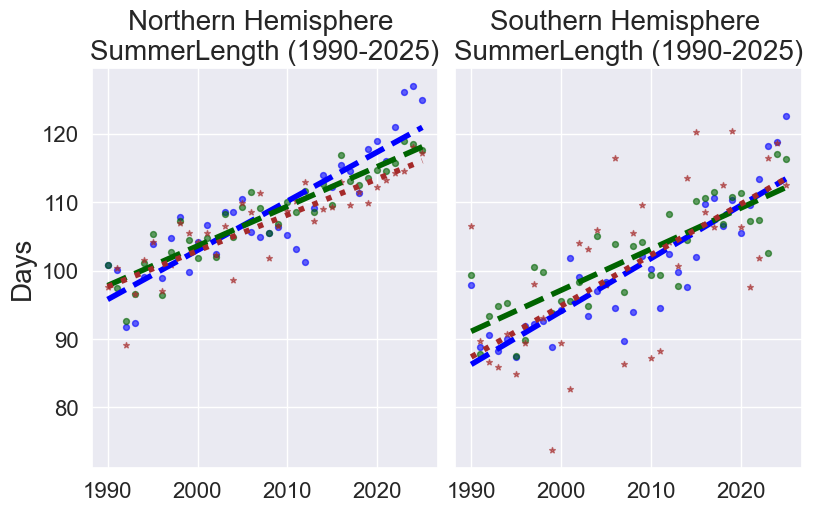

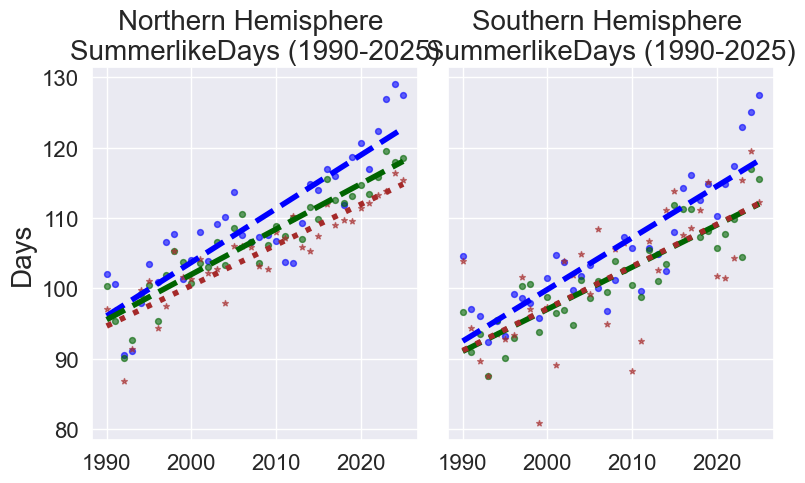

CPU times: user 436 ms, sys: 24.8 ms, total: 461 ms
Wall time: 459 ms


In [40]:
%%time

# takes 30 sec



# loop through all plot variables
for i,v in enumerate(plot_vars):

    # create blank fig
    fig = plt.figure(figsize = (8,5), layout='constrained')
    
    
    

    # Analysis time period NH
    ax3 = fig.add_subplot(1,2,1)

    # linear fits for slope
    x_land = nh_land_an.time.dt.year.values
    y_land = nh_land_an[v].values
    coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
    poly_land = np.poly1d(coefs_land)
    slope_land = np.round(coefs_land[0],2)
    slope_land_sd = np.round(np.sqrt(V[0][0]),2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_land)
    ss_total = np.sum((y_land - ymean)**2)
    ss_res = np.sum((y_land - poly_land(x_land))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_land = np.round(1 - (ss_res / ss_total),2)

    # linear fits for slope
    x_coast = nh_coast_an.time.dt.year.values
    y_coast = nh_coast_an[v].values
    coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
    poly_coast = np.poly1d(coefs_coast)
    slope_coast = np.round(coefs_coast[0],2)
    slope_coast_sd = np.round(np.sqrt(V[0][0]),2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_coast)
    ss_total = np.sum((y_coast - ymean)**2)
    ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_coast = np.round(1 - (ss_res / ss_total),2)

    # linear fits for slope
    x_ocean = nh_ocean_an.time.dt.year.values
    y_ocean = nh_ocean_an[v].values
    coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
    poly_ocean = np.poly1d(coefs_ocean)
    slope_ocean = np.round(coefs_ocean[0],2)
    slope_ocean_sd = np.round(np.sqrt(V[0][0]),2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_ocean)
    ss_total = np.sum((y_ocean - ymean)**2)
    ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_ocean = np.round(1 - (ss_res / ss_total),2)
    
    # plot data
    ax3.scatter(x_ocean, y_ocean, label="NH Ocean", c="blue", s=s, alpha=alpha)
    ax3.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", linewidth=lw, color='blue', 
         label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
    ax3.scatter(x_coast, y_coast, label="NH Coast", c="darkgreen", s=s, alpha=alpha)
    ax3.plot(x_coast, poly_coast(x_coast), linestyle="dashed", linewidth=lw, color='darkgreen', 
         label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
    ax3.scatter(x_land, y_land, label="NH Inland", marker='*', facecolors='brown', edgecolors='brown', s=s, alpha=alpha)
    ax3.plot(x_land, poly_land(x_land), linestyle="dotted", linewidth=lw, color='brown',
         label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
    ax3.set_title("Northern Hemisphere \n" + v + " (1990-2025)", fontsize = fs)
    # Annotation - units in per decade
    # ann_y = (ax3.get_yticks())[-3]+8
    # ann_x = np.mean(ax3.get_xticks())-5
    # # plot shows mean slope across all surface types for clarity
    # mean_slope = np.sqrt(slope_ocean**2 + slope_coast**2 + slope_land**2)/np.sqrt(3) * 10 # to get days per decade
    # if (slope_ocean < 0):
    #     mean_slope = mean_slope * -1
    # ax3.text(ann_x, ann_y, 
    #          ''+str(np.round(mean_slope,1))+r' $\frac{days}{10 yrs}$', fontsize=28, color='purple', fontweight='bold')
    plt.tick_params('x', labelsize=16)
    plt.tick_params('y', labelsize=16)
    if i < 2:
        ylabel = 'DOY'
    else:
        ylabel = 'Days'
    ax3.set_ylabel(ylabel, fontsize=fs)
    #ax3.legend(loc='best')

    
    # Analysis time period SH
    ax4 = fig.add_subplot(1,2,2, sharey=ax3)

    # linear fits for slope
    x_land = sh_land_an.time.dt.year.values
    y_land = sh_land_an[v].values
    coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
    poly_land = np.poly1d(coefs_land)
    slope_land = np.round(coefs_land[0],2)
    slope_land_sd = np.round(np.sqrt(V[0][0]),2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_land)
    ss_total = np.sum((y_land - ymean)**2)
    ss_res = np.sum((y_land - poly_land(x_land))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_land = np.round(1 - (ss_res / ss_total),2)

    # linear fits for slope
    x_coast = sh_coast_an.time.dt.year.values
    y_coast = sh_coast_an[v].values
    coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
    poly_coast = np.poly1d(coefs_coast)
    slope_coast = np.round(coefs_coast[0],2)
    slope_coast_sd = np.round(np.sqrt(V[0][0]),2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_coast)
    ss_total = np.sum((y_coast - ymean)**2)
    ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_coast = np.round(1 - (ss_res / ss_total),2)

    # linear fits for slope
    x_ocean = sh_ocean_an.time.dt.year.values
    y_ocean = sh_ocean_an[v].values
    coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
    poly_ocean = np.poly1d(coefs_ocean)
    slope_ocean = np.round(coefs_ocean[0],2)
    slope_ocean_sd = np.round(np.sqrt(V[0][0]),2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_ocean)
    ss_total = np.sum((y_ocean - ymean)**2)
    ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_ocean = np.round(1 - (ss_res / ss_total),2)
    
    # plot data
    ax4.scatter(x_ocean, y_ocean, label="SH Ocean", c="blue", s=s, alpha=alpha)
    ax4.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", linewidth=lw, color='blue', 
         label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
    ax4.scatter(x_coast, y_coast, label="SH Coast", c="darkgreen", s=s, alpha=alpha)
    ax4.plot(x_coast, poly_coast(x_coast), linestyle="dashed", linewidth=lw, color='darkgreen', 
         label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
    ax4.scatter(x_land, y_land, label="SH Inland", marker='*', facecolors='brown', edgecolors='brown', s=s, alpha=alpha)
    ax4.plot(x_land, poly_land(x_land), linestyle="dotted", linewidth=lw, color='brown',
         label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
    ax4.set_title("Southern Hemisphere \n" + v + " (1990-2025)", fontsize = fs)
    # Annotation - units in per decade
    # ann_y = (ax4.get_yticks())[-3]+8
    # ann_x = np.mean(ax4.get_xticks())-5
    #     # plot shows mean slope across all surface types for clarity
    # mean_slope = np.sqrt(slope_ocean**2 + slope_coast**2 + slope_land**2)/np.sqrt(3) * 10 # to get days per decade
    # if (slope_ocean < 0):
    #     mean_slope = mean_slope * -1
    # ax4.text(ann_x, ann_y, 
    #          ''+str(np.round(mean_slope,1))+r' $\frac{days}{10 yrs}$', fontsize=28, color='purple', fontweight='bold')
    
    plt.tick_params('x', labelsize=16)
    plt.tick_params('y', labelsize=6, labelleft=False)
    #ax3.legend(loc='best')


plt.tight_layout()
plt.show()

### CATEGORICAL Scatterplots for paper

#### build data frame

In [41]:
plot_vars = list(ds.data_vars)
remove_me = {'SummerR2','lsm','Coastal','SummerMeanHS','SummerTmax',
 'SummerRMSE',
 'SummerMeanT' }
plot_vars = [item for item in plot_vars if item not in remove_me]
plot_vars

['SummerStart', 'SummerEnd', 'SummerHeat', 'SummerLength', 'SummerlikeDays']

In [42]:
%%time

# takes 20 sec

nh_full = ds.where(((ds.lat >= nh_min) & (ds.lat <= nh_max))).weighted(weights).mean(dim=['lat','lon'])
sh_full = ds.where(((ds.lat >= sh_max) & (ds.lat <= sh_min))).weighted(weights).mean(dim=['lat','lon'])
nh_an = ds.sel(time=slice('1990','2025')).where(((ds.lat >= nh_min) & (ds.lat <= nh_max))).weighted(weights).mean(dim=['lat','lon'])
sh_an = ds.sel(time=slice('1990','2025')).where(((ds.lat >= sh_max) & (ds.lat <= sh_min))).weighted(weights).mean(dim=['lat','lon'])

# adding in baseline period for paper
nh_base = ds.sel(time=slice('1961','1990')).where(((ds.lat >= nh_min) & (ds.lat <= nh_max))).weighted(weights).mean(dim=['lat','lon'])
sh_base = ds.sel(time=slice('1961','1990')).where(((ds.lat >= sh_max) & (ds.lat <= sh_min))).weighted(weights).mean(dim=['lat','lon'])


CPU times: user 8.38 s, sys: 9.29 s, total: 17.7 s
Wall time: 20.2 s


In [43]:

# Initialize data 
plot_data = []
p_thresh = 0.05 # significance level for conf int


# loop through all plot variables
for i,v in enumerate(plot_vars):

    # full time period NH
    
    # ALL linear fits for slope
    x = nh_full.time.dt.year.values
    y = nh_full[v].values
    coefs_all, V = np.polyfit(x, y, 1, cov=True)
    poly_all = np.poly1d(coefs_all)
    slope_all = np.round(coefs_all[0]*10,2) # mult by 10 to get days/decade
    slope_all_sd = np.round(np.sqrt(V[0][0])*10,2)  # mult by 10 to get days/decade



    # build row of data
    temp_data = {'Metric': v, 'Surface':'All', 'Hemisphere':'NH', 'Slope':slope_all, 'SE':slope_all_sd, 'Period':'1961-2025'}
    plot_data.append(temp_data)

    
    
    # LAND linear fits for slope
    x_land = nh_land_full.time.dt.year.values
    y_land = nh_land_full[v].values
    coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
    poly_land = np.poly1d(coefs_land)
    slope_land = np.round(coefs_land[0]*10,2)
    slope_land_sd = np.round(np.sqrt(V[0][0])*10,2)  

    # build row of data
    temp_data = {'Metric': v, 'Surface':'Land', 'Hemisphere':'NH', 'Slope':slope_land, 'SE':slope_land_sd, 'Period':'1961-2025'}
    plot_data.append(temp_data)
    

    # COAST linear fits for slope
    x_coast = nh_coast_full.time.dt.year.values
    y_coast = nh_coast_full[v].values
    coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
    poly_coast = np.poly1d(coefs_coast)
    slope_coast = np.round(coefs_coast[0]*10,2)
    slope_coast_sd = np.round(np.sqrt(V[0][0])*10,2)  

    # build row of data
    temp_data = {'Metric': v, 'Surface':'Coast', 'Hemisphere':'NH', 'Slope':slope_coast, 'SE':slope_coast_sd, 'Period':'1961-2025'}
    plot_data.append(temp_data)

    # OCEAN linear fits for slope
    x_ocean = nh_ocean_full.time.dt.year.values
    y_ocean = nh_ocean_full[v].values
    coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
    poly_ocean = np.poly1d(coefs_ocean)
    slope_ocean = np.round(coefs_ocean[0]*10,2)
    slope_ocean_sd = np.round(np.sqrt(V[0][0])*10,2)  

    # build row of data
    temp_data = {'Metric': v, 'Surface':'Ocean', 'Hemisphere':'NH', 'Slope':slope_ocean, 'SE':slope_ocean_sd, 'Period':'1961-2025'}
    plot_data.append(temp_data)

    
    # full time period SH

    # ALL linear fits for slope
    x = sh_full.time.dt.year.values
    y = sh_full[v].values
    coefs_all, V = np.polyfit(x, y, 1, cov=True)
    poly_all = np.poly1d(coefs_all)
    slope_all = np.round(coefs_all[0]*10,2)
    slope_all_sd = np.round(np.sqrt(V[0][0])*10,2)  

    # build row of data
    temp_data = {'Metric': v, 'Surface':'All', 'Hemisphere':'SH', 'Slope':slope_all, 'SE':slope_all_sd, 'Period':'1961-2025'}
    plot_data.append(temp_data)

    # linear fits for slope
    x_land = sh_land_full.time.dt.year.values
    y_land = sh_land_full[v].values
    coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
    poly_land = np.poly1d(coefs_land)
    slope_land = np.round(coefs_land[0]*10,2)
    slope_land_sd = np.round(np.sqrt(V[0][0])*10,2)  

    # build row of data
    temp_data = {'Metric': v, 'Surface':'Land', 'Hemisphere':'SH', 'Slope':slope_land, 'SE':slope_land_sd, 'Period':'1961-2025'}
    plot_data.append(temp_data)

    # linear fits for slope
    x_coast = sh_coast_full.time.dt.year.values
    y_coast = sh_coast_full[v].values
    coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
    poly_coast = np.poly1d(coefs_coast)
    slope_coast = np.round(coefs_coast[0]*10,2)
    slope_coast_sd = np.round(np.sqrt(V[0][0])*10,2)  

    # build row of data
    temp_data = {'Metric': v, 'Surface':'Coast', 'Hemisphere':'SH', 'Slope':slope_coast, 'SE':slope_coast_sd, 'Period':'1961-2025'}
    plot_data.append(temp_data)

    # linear fits for slope
    x_ocean = sh_ocean_full.time.dt.year.values
    y_ocean = sh_ocean_full[v].values
    coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
    poly_ocean = np.poly1d(coefs_ocean)
    slope_ocean = np.round(coefs_ocean[0]*10,2)
    slope_ocean_sd = np.round(np.sqrt(V[0][0])*10,2)  

    # build row of data
    temp_data = {'Metric': v, 'Surface':'Ocean', 'Hemisphere':'SH', 'Slope':slope_ocean, 'SE':slope_ocean_sd, 'Period':'1961-2025'}
    plot_data.append(temp_data)

    # Analysis time period NH

    # ALL linear fits for slope
    x = nh_an.time.dt.year.values
    y = nh_an[v].values
    coefs_all, V = np.polyfit(x, y, 1, cov=True)
    poly_all = np.poly1d(coefs_all)
    slope_all = np.round(coefs_all[0]*10,2)
    slope_all_sd = np.round(np.sqrt(V[0][0])*10,2)  

    # build row of data
    temp_data = {'Metric': v, 'Surface':'All', 'Hemisphere':'NH', 'Slope':slope_all, 'SE':slope_all_sd, 'Period':'1990-2025'}
    plot_data.append(temp_data)
    
    # linear fits for slope
    x_land = nh_land_an.time.dt.year.values
    y_land = nh_land_an[v].values
    coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
    poly_land = np.poly1d(coefs_land)
    slope_land = np.round(coefs_land[0]*10,2)
    slope_land_sd = np.round(np.sqrt(V[0][0])*10,2)  

    # build row of data
    temp_data = {'Metric': v, 'Surface':'Land', 'Hemisphere':'NH', 'Slope':slope_land, 'SE':slope_land_sd, 'Period':'1990-2025'}
    plot_data.append(temp_data)

    # linear fits for slope
    x_coast = nh_coast_an.time.dt.year.values
    y_coast = nh_coast_an[v].values
    coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
    poly_coast = np.poly1d(coefs_coast)
    slope_coast = np.round(coefs_coast[0]*10,2)
    slope_coast_sd = np.round(np.sqrt(V[0][0])*10,2)  

    # build row of data
    temp_data = {'Metric': v, 'Surface':'Coast', 'Hemisphere':'NH', 'Slope':slope_coast, 'SE':slope_coast_sd, 'Period':'1990-2025'}
    plot_data.append(temp_data)

    # linear fits for slope
    x_ocean = nh_ocean_an.time.dt.year.values
    y_ocean = nh_ocean_an[v].values
    coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
    poly_ocean = np.poly1d(coefs_ocean)
    slope_ocean = np.round(coefs_ocean[0]*10,2)
    slope_ocean_sd = np.round(np.sqrt(V[0][0])*10,2)  

    # build row of data
    temp_data = {'Metric': v, 'Surface':'Ocean', 'Hemisphere':'NH', 'Slope':slope_ocean, 'SE':slope_ocean_sd, 'Period':'1990-2025'}
    plot_data.append(temp_data)

    # Analysis time period SH

    # ALL linear fits for slope
    x = sh_an.time.dt.year.values
    y = sh_an[v].values
    coefs_all, V = np.polyfit(x, y, 1, cov=True)
    poly_all = np.poly1d(coefs_all)
    slope_all = np.round(coefs_all[0]*10,2)
    slope_all_sd = np.round(np.sqrt(V[0][0])*10,2)  

    # build row of data
    temp_data = {'Metric': v, 'Surface':'All', 'Hemisphere':'SH', 'Slope':slope_all, 'SE':slope_all_sd, 'Period':'1990-2025'}
    plot_data.append(temp_data)

    # linear fits for slope
    x_land = sh_land_an.time.dt.year.values
    y_land = sh_land_an[v].values
    coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
    poly_land = np.poly1d(coefs_land)
    slope_land = np.round(coefs_land[0]*10,2)
    slope_land_sd = np.round(np.sqrt(V[0][0])*10,2)  

    # build row of data
    temp_data = {'Metric': v, 'Surface':'Land', 'Hemisphere':'SH', 'Slope':slope_land, 'SE':slope_land_sd, 'Period':'1990-2025'}
    plot_data.append(temp_data)

    # linear fits for slope
    x_coast = sh_coast_an.time.dt.year.values
    y_coast = sh_coast_an[v].values
    coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
    poly_coast = np.poly1d(coefs_coast)
    slope_coast = np.round(coefs_coast[0]*10,2)
    slope_coast_sd = np.round(np.sqrt(V[0][0])*10,2)  

    # build row of data
    temp_data = {'Metric': v, 'Surface':'Coast', 'Hemisphere':'SH', 'Slope':slope_coast, 'SE':slope_coast_sd, 'Period':'1990-2025'}
    plot_data.append(temp_data) 
    
    # linear fits for slope
    x_ocean = sh_ocean_an.time.dt.year.values
    y_ocean = sh_ocean_an[v].values
    coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
    poly_ocean = np.poly1d(coefs_ocean)
    slope_ocean = np.round(coefs_ocean[0]*10,2)
    slope_ocean_sd = np.round(np.sqrt(V[0][0])*10,2)  

    # build row of data
    temp_data = {'Metric': v, 'Surface':'Ocean', 'Hemisphere':'SH', 'Slope':slope_ocean, 'SE':slope_ocean_sd, 'Period':'1990-2025'}
    plot_data.append(temp_data)


    # Baseline time period NH

    # ALL linear fits for slope
    x = nh_base.time.dt.year.values
    y = nh_base[v].values
    coefs_all, V = np.polyfit(x, y, 1, cov=True)
    poly_all = np.poly1d(coefs_all)
    slope_all = np.round(coefs_all[0]*10,2)
    slope_all_sd = np.round(np.sqrt(V[0][0])*10,2)  

    # build row of data
    temp_data = {'Metric': v, 'Surface':'All', 'Hemisphere':'NH', 'Slope':slope_all, 'SE':slope_all_sd, 'Period':'1961-1990'}
    plot_data.append(temp_data)
    
    # linear fits for slope
    x_land = nh_land_base.time.dt.year.values
    y_land = nh_land_base[v].values
    coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
    poly_land = np.poly1d(coefs_land)
    slope_land = np.round(coefs_land[0]*10,2)
    slope_land_sd = np.round(np.sqrt(V[0][0])*10,2)  

    # build row of data
    temp_data = {'Metric': v, 'Surface':'Land', 'Hemisphere':'NH', 'Slope':slope_land, 'SE':slope_land_sd, 'Period':'1961-1990'}
    plot_data.append(temp_data)

    # linear fits for slope
    x_coast = nh_coast_base.time.dt.year.values
    y_coast = nh_coast_base[v].values
    coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
    poly_coast = np.poly1d(coefs_coast)
    slope_coast = np.round(coefs_coast[0]*10,2)
    slope_coast_sd = np.round(np.sqrt(V[0][0])*10,2)  

    # build row of data
    temp_data = {'Metric': v, 'Surface':'Coast', 'Hemisphere':'NH', 'Slope':slope_coast, 'SE':slope_coast_sd, 'Period':'1961-1990'}
    plot_data.append(temp_data)

    # linear fits for slope
    x_ocean = nh_ocean_base.time.dt.year.values
    y_ocean = nh_ocean_base[v].values
    coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
    poly_ocean = np.poly1d(coefs_ocean)
    slope_ocean = np.round(coefs_ocean[0]*10,2)
    slope_ocean_sd = np.round(np.sqrt(V[0][0])*10,2)  

    # build row of data
    temp_data = {'Metric': v, 'Surface':'Ocean', 'Hemisphere':'NH', 'Slope':slope_ocean, 'SE':slope_ocean_sd, 'Period':'1961-1990'}
    plot_data.append(temp_data)

    # Baseline time period SH

    # ALL linear fits for slope
    x = sh_base.time.dt.year.values
    y = sh_base[v].values
    coefs_all, V = np.polyfit(x, y, 1, cov=True)
    poly_all = np.poly1d(coefs_all)
    slope_all = np.round(coefs_all[0]*10,2)
    slope_all_sd = np.round(np.sqrt(V[0][0])*10,2)  

    # build row of data
    temp_data = {'Metric': v, 'Surface':'All', 'Hemisphere':'SH', 'Slope':slope_all, 'SE':slope_all_sd, 'Period':'1961-1990'}
    plot_data.append(temp_data)

    # linear fits for slope
    x_land = sh_land_base.time.dt.year.values
    y_land = sh_land_base[v].values
    coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
    poly_land = np.poly1d(coefs_land)
    slope_land = np.round(coefs_land[0]*10,2)
    slope_land_sd = np.round(np.sqrt(V[0][0])*10,2)  

    # build row of data
    temp_data = {'Metric': v, 'Surface':'Land', 'Hemisphere':'SH', 'Slope':slope_land, 'SE':slope_land_sd, 'Period':'1961-1990'}
    plot_data.append(temp_data)

    # linear fits for slope
    x_coast = sh_coast_base.time.dt.year.values
    y_coast = sh_coast_base[v].values
    coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
    poly_coast = np.poly1d(coefs_coast)
    slope_coast = np.round(coefs_coast[0]*10,2)
    slope_coast_sd = np.round(np.sqrt(V[0][0])*10,2)  

    # build row of data
    temp_data = {'Metric': v, 'Surface':'Coast', 'Hemisphere':'SH', 'Slope':slope_coast, 'SE':slope_coast_sd, 'Period':'1961-1990'}
    plot_data.append(temp_data) 
    
    # linear fits for slope
    x_ocean = sh_ocean_base.time.dt.year.values
    y_ocean = sh_ocean_base[v].values
    coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
    poly_ocean = np.poly1d(coefs_ocean)
    slope_ocean = np.round(coefs_ocean[0]*10,2)
    slope_ocean_sd = np.round(np.sqrt(V[0][0])*10,2)  

    # build row of data
    temp_data = {'Metric': v, 'Surface':'Ocean', 'Hemisphere':'SH', 'Slope':slope_ocean, 'SE':slope_ocean_sd, 'Period':'1961-1990'}
    plot_data.append(temp_data)





# Creates DataFrame.
df_plot = pd.DataFrame(plot_data)
df_plot

,Metric,Surface,Hemisphere,Slope,SE,Period
0,SummerStart,All,NH,-2.05,0.12,1961-2025
1,SummerStart,Land,NH,-1.91,0.12,1961-2025
2,SummerStart,Coast,NH,-2.20,0.11,1961-2025
3,SummerStart,Ocean,NH,-2.18,0.19,1961-2025
4,SummerStart,All,SH,-1.04,0.30,1961-2025
...,...,...,...,...,...,...
115,SummerlikeDays,Ocean,NH,-0.51,1.03,1961-1990
116,SummerlikeDays,All,SH,8.79,1.07,1961-1990
117,SummerlikeDays,Land,SH,3.78,1.49,1961-1990
118,SummerlikeDays,Coast,SH,4.65,0.84,1961-1990


In [44]:
df_plot.tail(50)

,Metric,Surface,Hemisphere,Slope,SE,Period
70,SummerHeat,Coast,SH,14.85,2.07,1961-1990
71,SummerHeat,Ocean,SH,16.34,1.96,1961-1990
72,SummerLength,All,NH,4.57,0.26,1961-2025
73,SummerLength,Land,NH,3.99,0.22,1961-2025
74,SummerLength,Coast,NH,4.43,0.22,1961-2025
75,SummerLength,Ocean,NH,5.12,0.38,1961-2025
76,SummerLength,All,SH,5.52,0.40,1961-2025
77,SummerLength,Land,SH,4.29,0.64,1961-2025
78,SummerLength,Coast,SH,3.55,0.31,1961-2025
79,SummerLength,Ocean,SH,5.65,0.42,1961-2025


#### Save out the table of trends in the metrics by surface and period

In [45]:
output_file = '../../../Data/ERA5-global/Analysis/New-Fourier/ALL_summer_length_start_end_heat_trends.csv'
df_plot.to_csv(output_file, index=False)

In [46]:
# read it back in
input_file = '../../../Data/ERA5-global/Analysis/New-Fourier/ALL_summer_length_start_end_heat_trends.csv'
df_plot = pd.read_csv(input_file)
df_plot.tail(100)

,Metric,Surface,Hemisphere,Slope,SE,Period
20,SummerStart,All,SH,0.93,1.11,1961-1990
21,SummerStart,Land,SH,0.06,1.12,1961-1990
22,SummerStart,Coast,SH,-1.07,0.64,1961-1990
23,SummerStart,Ocean,SH,1.02,1.23,1961-1990
24,SummerEnd,All,NH,2.52,0.17,1961-2025
...,...,...,...,...,...,...
115,SummerlikeDays,Ocean,NH,-0.51,1.03,1961-1990
116,SummerlikeDays,All,SH,8.79,1.07,1961-1990
117,SummerlikeDays,Land,SH,3.78,1.49,1961-1990
118,SummerlikeDays,Coast,SH,4.65,0.84,1961-1990


#### Make the plots as is

In [47]:


# data slices
start_full = df_plot.query('Metric == "SummerStart" & Surface == "All" & Period == "1961-2025" ')
start_an = df_plot.query('Metric == "SummerStart" & Surface == "All" & Period == "1990-2025" ')
end_full = df_plot.query('Metric == "SummerEnd" & Surface == "All" & Period == "1961-2025" ')
end_an = df_plot.query('Metric == "SummerEnd" & Surface == "All" & Period == "1990-2025" ')

start_full_land = df_plot.query('Metric == "SummerStart" & Surface == "Land" & Period == "1961-2025" ')
start_an_land = df_plot.query('Metric == "SummerStart" & Surface == "Land" & Period == "1990-2025" ')
end_full_land = df_plot.query('Metric == "SummerEnd" & Surface == "Land" & Period == "1961-2025" ')
end_an_land = df_plot.query('Metric == "SummerEnd" & Surface == "Land" & Period == "1990-2025" ')

start_full_coast = df_plot.query('Metric == "SummerStart" & Surface == "Coast" & Period == "1961-2025" ')
start_an_coast = df_plot.query('Metric == "SummerStart" & Surface == "Coast" & Period == "1990-2025" ')
end_full_coast = df_plot.query('Metric == "SummerEnd" & Surface == "Coast" & Period == "1961-2025" ')
end_an_coast = df_plot.query('Metric == "SummerEnd" & Surface == "Coast" & Period == "1990-2025" ')

start_full_ocean = df_plot.query('Metric == "SummerStart" & Surface == "Ocean" & Period == "1961-2025" ')
start_an_ocean = df_plot.query('Metric == "SummerStart" & Surface == "Ocean" & Period == "1990-2025" ')
end_full_ocean = df_plot.query('Metric == "SummerEnd" & Surface == "Ocean" & Period == "1961-2025" ')
end_an_ocean = df_plot.query('Metric == "SummerEnd" & Surface == "Ocean" & Period == "1990-2025" ')

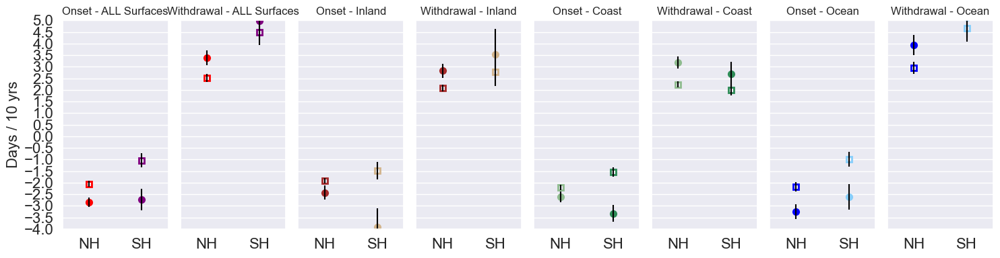

In [48]:
# plot params
ms = 6
palette_all={"NH": "red", "SH": "purple"}
palette_land={"NH": "brown", "SH": "tan"}
palette_coast={"NH": "darkseagreen", "SH": "seagreen"}
palette_ocean={"NH": "blue", "SH": "lightskyblue"}
xlabels = ['NH','SH']
#print(start_full, start_an)
#print(start_full, start_an)

fig=plt.figure(figsize=(15,4))#, layout='constrained')
#sns.set_context("paper")
### ALL surface average

ax1 = fig.add_subplot(1,8,1)
ax1=sns.pointplot(data=start_full, x="Hemisphere", y="Slope", hue="Hemisphere", palette=palette_all, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax1.errorbar(start_full['Hemisphere'], start_full['Slope'], yerr=start_full['SE'], fmt="none", color="black")
ax1=sns.pointplot(data=start_an, x="Hemisphere", y="Slope", hue="Hemisphere", palette=palette_all, markers=['o','o'], label="1990-2025", markersize=ms)
ax1.errorbar(start_an['Hemisphere'], start_an['Slope'], yerr=start_an['SE'], fmt="none", color="black")
#plt.scatter(x='Hemisphere', y='Slope', data=temp)
#ax1.legend(loc='upper left')
ax1.set_xlabel("")
ax1.set_ylabel("Days / 10 yrs", fontsize=16)
ax1.set_title('Onset - ALL Surfaces')
ax1.set_yticks(np.arange(-4,6,0.5))
ax1.set_ylim(-4,5)

ax1.set_xlim(-0.5, len(xlabels)-0.5)
#ax1.xaxis.set_major_locator(ticker.FixedLocator([0, 1, 2]))
plt.tick_params('x', labelsize=16)

plt.tick_params('y', labelsize=16)

#plt.title('Summer Onset Trends')

ax2 = fig.add_subplot(1,8,2, sharey=ax1)
ax2 = sns.pointplot(data=end_full, x="Hemisphere", y="Slope", hue="Hemisphere", palette=palette_all, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax2.errorbar(end_full['Hemisphere'], end_full['Slope'], yerr=end_full['SE'], fmt="none", color="black")
ax2 = sns.pointplot(data=end_an, x="Hemisphere", y="Slope", hue="Hemisphere", palette=palette_all, markers=['o','o'], label="1990-2025", markersize=ms)
ax2.errorbar(end_an['Hemisphere'], end_an['Slope'], yerr=end_an['SE'], fmt="none", color="black")
#plt.scatter(x='Hemisphere', y='Slope', data=temp)
#ax2.legend(loc='best')
ax2.set_xlabel("")
ax2.set_ylabel("")
ax2.set_title('Withdrawal - ALL Surfaces')
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=6, labelleft=False)
ax2.set_xlim(-0.5, len(xlabels)-0.5)


### Land

ax3 = fig.add_subplot(1,8,3, sharey=ax1)
ax3=sns.pointplot(data=start_full_land, x="Hemisphere", y="Slope", hue="Hemisphere", palette=palette_land, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax3.errorbar(start_full_land['Hemisphere'], start_full_land['Slope'], yerr=start_full_land['SE'], fmt="none", color="black")
ax3=sns.pointplot(data=start_an_land, x="Hemisphere", y="Slope", hue="Hemisphere", palette=palette_land, markers=['o','o'], label="1990-2025", markersize=ms)
ax3.errorbar(start_an_land['Hemisphere'], start_an_land['Slope'], yerr=start_an_land['SE'], fmt="none", color="black")
#plt.scatter(x='Hemisphere', y='Slope', data=temp)
#ax3.legend(loc='upper left')
ax3.set_xlabel("")
ax3.set_ylabel("")
ax3.set_title('Onset - Inland')

plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=6, labelleft=False)
ax3.set_xlim(-0.5, len(xlabels)-0.5)


ax4 = fig.add_subplot(1,8,4, sharey=ax1)
ax4 = sns.pointplot(data=end_full_land, x="Hemisphere", y="Slope", hue="Hemisphere", palette=palette_land, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax4.errorbar(end_full_land['Hemisphere'], end_full_land['Slope'], yerr=end_full_land['SE'], fmt="none", color="black",)
ax4 = sns.pointplot(data=end_an_land, x="Hemisphere", y="Slope", hue="Hemisphere", palette=palette_land, markers=['o','o'], label="1990-2025", markersize=ms)
ax4.errorbar(end_an_land['Hemisphere'], end_an_land['Slope'], yerr=end_an_land['SE'], fmt="none", color="black")
#plt.scatter(x='Hemisphere', y='Slope', data=temp)
#ax2.legend(loc='best')
ax4.set_xlabel("")
ax4.set_ylabel("")
ax4.set_title('Withdrawal - Inland')
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=6, labelleft=False)
ax4.set_xlim(-0.5, len(xlabels)-0.5)


### Coast

ax5 = fig.add_subplot(1,8,5, sharey=ax1)
ax5=sns.pointplot(data=start_full_coast, x="Hemisphere", y="Slope", hue="Hemisphere", palette=palette_coast, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax5.errorbar(start_full_coast['Hemisphere'], start_full_coast['Slope'], yerr=start_full_coast['SE'], fmt="none", color="black")
ax5=sns.pointplot(data=start_an_coast, x="Hemisphere", y="Slope", hue="Hemisphere", palette=palette_coast, markers=['o','o'], label="1990-2025", markersize=ms)
ax5.errorbar(start_an_coast['Hemisphere'], start_an_coast['Slope'], yerr=start_an_coast['SE'], fmt="none", color="black")
#plt.scatter(x='Hemisphere', y='Slope', data=temp)
#ax3.legend(loc='upper left')
ax5.set_xlabel("")
ax5.set_ylabel("")
ax5.set_title('Onset - Coast')

plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=6, labelleft=False)
ax5.set_xlim(-0.5, len(xlabels)-0.5)

ax6 = fig.add_subplot(1,8,6, sharey=ax1)
ax6 = sns.pointplot(data=end_full_coast, x="Hemisphere", y="Slope", hue="Hemisphere", palette=palette_coast, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax6.errorbar(end_full_coast['Hemisphere'], end_full_coast['Slope'], yerr=end_full_coast['SE'], fmt="none", color="black",)
ax6 = sns.pointplot(data=end_an_coast, x="Hemisphere", y="Slope", hue="Hemisphere", palette=palette_coast, markers=['o','o'], label="1990-2025", markersize=ms)
ax6.errorbar(end_an_coast['Hemisphere'], end_an_coast['Slope'], yerr=end_an_coast['SE'], fmt="none", color="black")
#plt.scatter(x='Hemisphere', y='Slope', data=temp)
#ax2.legend(loc='best')
ax6.set_xlabel("")
ax6.set_ylabel("")
ax6.set_title('Withdrawal - Coast')
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=6, labelleft=False)
ax6.set_xlim(-0.5, len(xlabels)-0.5)


### Ocean

ax7 = fig.add_subplot(1,8,7, sharey=ax1)
ax7=sns.pointplot(data=start_full_ocean, x="Hemisphere", y="Slope", hue="Hemisphere", palette=palette_ocean, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax7.errorbar(start_full_ocean['Hemisphere'], start_full_ocean['Slope'], yerr=start_full_ocean['SE'], fmt="none", color="black")
ax7=sns.pointplot(data=start_an_ocean, x="Hemisphere", y="Slope", hue="Hemisphere", palette=palette_ocean, markers=['o','o'], label="1990-2025", markersize=ms)
ax7.errorbar(start_an_ocean['Hemisphere'], start_an_ocean['Slope'], yerr=start_an_ocean['SE'], fmt="none", color="black")
#plt.scatter(x='Hemisphere', y='Slope', data=temp)
#ax3.legend(loc='upper left')
ax7.set_xlabel("")
ax7.set_ylabel("")
ax7.set_title('Onset - Ocean')

plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=6, labelleft=False)
ax7.set_xlim(-0.5, len(xlabels)-0.5)

ax8 = fig.add_subplot(1,8,8, sharey=ax1)
ax8 = sns.pointplot(data=end_full_ocean, x="Hemisphere", y="Slope", hue="Hemisphere", palette=palette_ocean, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax8.errorbar(end_full_ocean['Hemisphere'], end_full_ocean['Slope'], yerr=end_full_ocean['SE'], fmt="none", color="black",)
ax8 = sns.pointplot(data=end_an_ocean, x="Hemisphere", y="Slope", hue="Hemisphere", palette=palette_ocean, markers=['o','o'], label="1990-2025", markersize=ms)
ax8.errorbar(end_an_ocean['Hemisphere'], end_an_ocean['Slope'], yerr=end_an_ocean['SE'], fmt="none", color="black")
#plt.scatter(x='Hemisphere', y='Slope', data=temp)
#ax2.legend(loc='best')
ax8.set_xlabel("")
ax8.set_ylabel("")
ax8.set_title('Withdrawal - Ocean')
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=6, labelleft=False)
ax8.set_xlim(-0.5, len(xlabels)-0.5)





plt.tight_layout()
plt.show()

#### Make the plots with onset positive

In [49]:
# take absolute value of all slopes to switch onsets to positive numbers
df_plot['Slope'] = np.abs(df_plot['Slope'])
df_plot

,Metric,Surface,Hemisphere,Slope,SE,Period
0,SummerStart,All,NH,2.05,0.12,1961-2025
1,SummerStart,Land,NH,1.91,0.12,1961-2025
2,SummerStart,Coast,NH,2.20,0.11,1961-2025
3,SummerStart,Ocean,NH,2.18,0.19,1961-2025
4,SummerStart,All,SH,1.04,0.30,1961-2025
...,...,...,...,...,...,...
115,SummerlikeDays,Ocean,NH,0.51,1.03,1961-1990
116,SummerlikeDays,All,SH,8.79,1.07,1961-1990
117,SummerlikeDays,Land,SH,3.78,1.49,1961-1990
118,SummerlikeDays,Coast,SH,4.65,0.84,1961-1990


In [50]:
# data slices
start_full = df_plot.query('Metric == "SummerStart" & Surface == "All" & Period == "1961-2025" ')
start_an = df_plot.query('Metric == "SummerStart" & Surface == "All" & Period == "1990-2025" ')
end_full = df_plot.query('Metric == "SummerEnd" & Surface == "All" & Period == "1961-2025" ')
end_an = df_plot.query('Metric == "SummerEnd" & Surface == "All" & Period == "1990-2025" ')

start_full_land = df_plot.query('Metric == "SummerStart" & Surface == "Land" & Period == "1961-2025" ')
start_an_land = df_plot.query('Metric == "SummerStart" & Surface == "Land" & Period == "1990-2025" ')
end_full_land = df_plot.query('Metric == "SummerEnd" & Surface == "Land" & Period == "1961-2025" ')
end_an_land = df_plot.query('Metric == "SummerEnd" & Surface == "Land" & Period == "1990-2025" ')

start_full_coast = df_plot.query('Metric == "SummerStart" & Surface == "Coast" & Period == "1961-2025" ')
start_an_coast = df_plot.query('Metric == "SummerStart" & Surface == "Coast" & Period == "1990-2025" ')
end_full_coast = df_plot.query('Metric == "SummerEnd" & Surface == "Coast" & Period == "1961-2025" ')
end_an_coast = df_plot.query('Metric == "SummerEnd" & Surface == "Coast" & Period == "1990-2025" ')

start_full_ocean = df_plot.query('Metric == "SummerStart" & Surface == "Ocean" & Period == "1961-2025" ')
start_an_ocean = df_plot.query('Metric == "SummerStart" & Surface == "Ocean" & Period == "1990-2025" ')
end_full_ocean = df_plot.query('Metric == "SummerEnd" & Surface == "Ocean" & Period == "1961-2025" ')
end_an_ocean = df_plot.query('Metric == "SummerEnd" & Surface == "Ocean" & Period == "1990-2025" ')

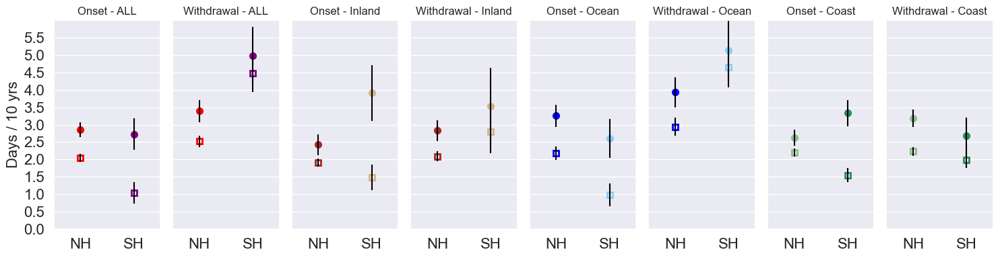

In [53]:
# plot params
ms = 6
palette_all={"NH": "red", "SH": "purple"}
palette_land={"NH": "brown", "SH": "tan"}
palette_coast={"NH": "darkseagreen", "SH": "seagreen"}
palette_ocean={"NH": "blue", "SH": "lightskyblue"}
xlabels = ['NH','SH']
#print(start_full, start_an)
#print(start_full, start_an)

fig=plt.figure(figsize=(15,4))#, layout='constrained')
#sns.set_context("paper")
### ALL surface average

ax1 = fig.add_subplot(1,8,1)
ax1=sns.pointplot(data=start_full, x="Hemisphere", y="Slope", hue="Hemisphere", palette=palette_all, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax1.errorbar(start_full['Hemisphere'], start_full['Slope'], yerr=start_full['SE'], fmt="none", color="black")
ax1=sns.pointplot(data=start_an, x="Hemisphere", y="Slope", hue="Hemisphere", palette=palette_all, markers=['o','o'], label="1990-2025", markersize=ms)
ax1.errorbar(start_an['Hemisphere'], start_an['Slope'], yerr=start_an['SE'], fmt="none", color="black")
#plt.scatter(x='Hemisphere', y='Slope', data=temp)
#ax1.legend(loc='upper left')
ax1.set_xlabel("")
ax1.set_ylabel("Days / 10 yrs", fontsize=16)
ax1.set_title('Onset - ALL', fontsize=12)
ax1.set_yticks(np.arange(0,6,0.5))
ax1.set_ylim(0,6)

ax1.set_xlim(-0.5, len(xlabels)-0.5)
#ax1.xaxis.set_major_locator(ticker.FixedLocator([0, 1, 2]))
plt.tick_params('x', labelsize=16)

plt.tick_params('y', labelsize=16)

#plt.title('Summer Onset Trends')

ax2 = fig.add_subplot(1,8,2, sharey=ax1)
ax2 = sns.pointplot(data=end_full, x="Hemisphere", y="Slope", hue="Hemisphere", palette=palette_all, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax2.errorbar(end_full['Hemisphere'], end_full['Slope'], yerr=end_full['SE'], fmt="none", color="black")
ax2 = sns.pointplot(data=end_an, x="Hemisphere", y="Slope", hue="Hemisphere", palette=palette_all, markers=['o','o'], label="1990-2025", markersize=ms)
ax2.errorbar(end_an['Hemisphere'], end_an['Slope'], yerr=end_an['SE'], fmt="none", color="black")
#plt.scatter(x='Hemisphere', y='Slope', data=temp)
#ax2.legend(loc='best')
ax2.set_xlabel("")
ax2.set_ylabel("")
ax2.set_title('Withdrawal - ALL', fontsize=12)
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=6, labelleft=False)
ax2.set_xlim(-0.5, len(xlabels)-0.5)


### Land

ax3 = fig.add_subplot(1,8,3, sharey=ax1)
ax3=sns.pointplot(data=start_full_land, x="Hemisphere", y="Slope", hue="Hemisphere", palette=palette_land, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax3.errorbar(start_full_land['Hemisphere'], start_full_land['Slope'], yerr=start_full_land['SE'], fmt="none", color="black")
ax3=sns.pointplot(data=start_an_land, x="Hemisphere", y="Slope", hue="Hemisphere", palette=palette_land, markers=['o','o'], label="1990-2025", markersize=ms)
ax3.errorbar(start_an_land['Hemisphere'], start_an_land['Slope'], yerr=start_an_land['SE'], fmt="none", color="black")
#plt.scatter(x='Hemisphere', y='Slope', data=temp)
#ax3.legend(loc='upper left')
ax3.set_xlabel("")
ax3.set_ylabel("")
ax3.set_title('Onset - Inland', fontsize=12)

plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=6, labelleft=False)
ax3.set_xlim(-0.5, len(xlabels)-0.5)


ax4 = fig.add_subplot(1,8,4, sharey=ax1)
ax4 = sns.pointplot(data=end_full_land, x="Hemisphere", y="Slope", hue="Hemisphere", palette=palette_land, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax4.errorbar(end_full_land['Hemisphere'], end_full_land['Slope'], yerr=end_full_land['SE'], fmt="none", color="black",)
ax4 = sns.pointplot(data=end_an_land, x="Hemisphere", y="Slope", hue="Hemisphere", palette=palette_land, markers=['o','o'], label="1990-2025", markersize=ms)
ax4.errorbar(end_an_land['Hemisphere'], end_an_land['Slope'], yerr=end_an_land['SE'], fmt="none", color="black")
#plt.scatter(x='Hemisphere', y='Slope', data=temp)
#ax2.legend(loc='best')
ax4.set_xlabel("")
ax4.set_ylabel("")
ax4.set_title('Withdrawal - Inland', fontsize=12)
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=6, labelleft=False)
ax4.set_xlim(-0.5, len(xlabels)-0.5)

### Ocean

ax7 = fig.add_subplot(1,8,5, sharey=ax1)
ax7=sns.pointplot(data=start_full_ocean, x="Hemisphere", y="Slope", hue="Hemisphere", palette=palette_ocean, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax7.errorbar(start_full_ocean['Hemisphere'], start_full_ocean['Slope'], yerr=start_full_ocean['SE'], fmt="none", color="black")
ax7=sns.pointplot(data=start_an_ocean, x="Hemisphere", y="Slope", hue="Hemisphere", palette=palette_ocean, markers=['o','o'], label="1990-2025", markersize=ms)
ax7.errorbar(start_an_ocean['Hemisphere'], start_an_ocean['Slope'], yerr=start_an_ocean['SE'], fmt="none", color="black")
#plt.scatter(x='Hemisphere', y='Slope', data=temp)
#ax3.legend(loc='upper left')
ax7.set_xlabel("")
ax7.set_ylabel("")
ax7.set_title('Onset - Ocean', fontsize=12)

plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=6, labelleft=False)
ax7.set_xlim(-0.5, len(xlabels)-0.5)

ax8 = fig.add_subplot(1,8,6, sharey=ax1)
ax8 = sns.pointplot(data=end_full_ocean, x="Hemisphere", y="Slope", hue="Hemisphere", palette=palette_ocean, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax8.errorbar(end_full_ocean['Hemisphere'], end_full_ocean['Slope'], yerr=end_full_ocean['SE'], fmt="none", color="black",)
ax8 = sns.pointplot(data=end_an_ocean, x="Hemisphere", y="Slope", hue="Hemisphere", palette=palette_ocean, markers=['o','o'], label="1990-2025", markersize=ms)
ax8.errorbar(end_an_ocean['Hemisphere'], end_an_ocean['Slope'], yerr=end_an_ocean['SE'], fmt="none", color="black")
#plt.scatter(x='Hemisphere', y='Slope', data=temp)
#ax2.legend(loc='best')
ax8.set_xlabel("")
ax8.set_ylabel("")
ax8.set_title('Withdrawal - Ocean', fontsize=12)
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=6, labelleft=False)
ax8.set_xlim(-0.5, len(xlabels)-0.5)

### Coast

ax5 = fig.add_subplot(1,8,7, sharey=ax1)
ax5=sns.pointplot(data=start_full_coast, x="Hemisphere", y="Slope", hue="Hemisphere", palette=palette_coast, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax5.errorbar(start_full_coast['Hemisphere'], start_full_coast['Slope'], yerr=start_full_coast['SE'], fmt="none", color="black")
ax5=sns.pointplot(data=start_an_coast, x="Hemisphere", y="Slope", hue="Hemisphere", palette=palette_coast, markers=['o','o'], label="1990-2025", markersize=ms)
ax5.errorbar(start_an_coast['Hemisphere'], start_an_coast['Slope'], yerr=start_an_coast['SE'], fmt="none", color="black")
#plt.scatter(x='Hemisphere', y='Slope', data=temp)
#ax3.legend(loc='upper left')
ax5.set_xlabel("")
ax5.set_ylabel("")
ax5.set_title('Onset - Coast', fontsize=12)

plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=6, labelleft=False)
ax5.set_xlim(-0.5, len(xlabels)-0.5)

ax6 = fig.add_subplot(1,8,8, sharey=ax1)
ax6 = sns.pointplot(data=end_full_coast, x="Hemisphere", y="Slope", hue="Hemisphere", palette=palette_coast, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax6.errorbar(end_full_coast['Hemisphere'], end_full_coast['Slope'], yerr=end_full_coast['SE'], fmt="none", color="black",)
ax6 = sns.pointplot(data=end_an_coast, x="Hemisphere", y="Slope", hue="Hemisphere", palette=palette_coast, markers=['o','o'], label="1990-2025", markersize=ms)
ax6.errorbar(end_an_coast['Hemisphere'], end_an_coast['Slope'], yerr=end_an_coast['SE'], fmt="none", color="black")
#plt.scatter(x='Hemisphere', y='Slope', data=temp)
#ax2.legend(loc='best')
ax6.set_xlabel("")
ax6.set_ylabel("")
ax6.set_title('Withdrawal - Coast', fontsize=12)
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=6, labelleft=False)
ax6.set_xlim(-0.5, len(xlabels)-0.5)








plt.tight_layout()
plt.show()

In [29]:
df_plot.query('Hemisphere == "SH" & Metric == "SummerLength"')

,Metric,Surface,Hemisphere,Slope,SE,Period
52,SummerLength,All,SH,5.22,0.41,1961-2023
53,SummerLength,Land,SH,4.07,0.68,1961-2023
54,SummerLength,Coast,SH,3.29,0.31,1961-2023
55,SummerLength,Ocean,SH,5.34,0.42,1961-2023
60,SummerLength,All,SH,6.92,0.75,1990-2023
61,SummerLength,Land,SH,7.18,1.68,1990-2023
62,SummerLength,Coast,SH,5.48,0.71,1990-2023
63,SummerLength,Ocean,SH,6.90,0.76,1990-2023


#### Onset vs Withdrawal instead of by Hemisphere

In [54]:
# data slices
nh_full = df_plot.query('Hemisphere == "NH" & Metric in ["SummerStart","SummerEnd"] & Surface == "All" & Period == "1961-2025" ')
nh_an = df_plot.query('Hemisphere == "NH" & Metric in ["SummerStart","SummerEnd"] & Surface == "All" & Period == "1990-2025" ')
sh_full = df_plot.query('Hemisphere == "SH" & Metric in ["SummerStart","SummerEnd"] & Surface == "All" & Period == "1961-2025" ')
sh_an = df_plot.query('Hemisphere == "SH" & Metric in ["SummerStart","SummerEnd"] & Surface == "All" & Period == "1990-2025" ')

nh_full_land = df_plot.query('Hemisphere == "NH" & Metric in ["SummerStart","SummerEnd"] & Surface == "Land" & Period == "1961-2025" ')
nh_an_land = df_plot.query('Hemisphere == "NH" & Metric in ["SummerStart","SummerEnd"] & Surface == "Land" & Period == "1990-2025" ')
sh_full_land = df_plot.query('Hemisphere == "SH" & Metric in ["SummerStart","SummerEnd"] & Surface == "Land" & Period == "1961-2025" ')
sh_an_land = df_plot.query('Hemisphere == "SH" & Metric in ["SummerStart","SummerEnd"] & Surface == "Land" & Period == "1990-2025" ')

nh_full_ocean = df_plot.query('Hemisphere == "NH" & Metric in ["SummerStart","SummerEnd"] & Surface == "Ocean" & Period == "1961-2025" ')
nh_an_ocean = df_plot.query('Hemisphere == "NH" & Metric in ["SummerStart","SummerEnd"] & Surface == "Ocean" & Period == "1990-2025" ')
sh_full_ocean = df_plot.query('Hemisphere == "SH" & Metric in ["SummerStart","SummerEnd"] & Surface == "Ocean" & Period == "1961-2025" ')
sh_an_ocean = df_plot.query('Hemisphere == "SH" & Metric in ["SummerStart","SummerEnd"] & Surface == "Ocean" & Period == "1990-2025" ')

nh_full_coast = df_plot.query('Hemisphere == "NH" & Metric in ["SummerStart","SummerEnd"] & Surface == "Coast" & Period == "1961-2025" ')
nh_an_coast = df_plot.query('Hemisphere == "NH" & Metric in ["SummerStart","SummerEnd"] & Surface == "Coast" & Period == "1990-2025" ')
sh_full_coast = df_plot.query('Hemisphere == "SH" & Metric in ["SummerStart","SummerEnd"] & Surface == "Coast" & Period == "1961-2025" ')
sh_an_coast = df_plot.query('Hemisphere == "SH" & Metric in ["SummerStart","SummerEnd"] & Surface == "Coast" & Period == "1990-2025" ')

nh_full

,Metric,Surface,Hemisphere,Slope,SE,Period
0,SummerStart,All,NH,2.05,0.12,1961-2025
24,SummerEnd,All,NH,2.52,0.17,1961-2025


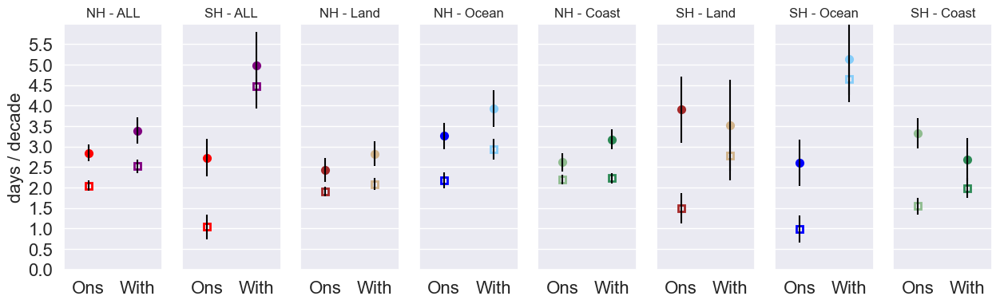

In [55]:
# plot params
ms = 6
palette_all={"SummerStart": "red", "SummerEnd": "purple"}
palette_land={"SummerStart": "brown", "SummerEnd": "tan"}
palette_coast={"SummerStart": "darkseagreen", "SummerEnd": "seagreen"}
palette_ocean={"SummerStart": "blue", "SummerEnd": "lightskyblue"}
xlabels = ['Ons','With']


fig=plt.figure(figsize=(15,4))#, layout='constrained')
#sns.set_context("paper")

### NH ALL surface average
ax1 = fig.add_subplot(1,8,1)
ax1 = sns.pointplot(data=nh_full, x='Metric', y="Slope", hue="Metric", palette=palette_all, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax1.errorbar(nh_full['Metric'], nh_full['Slope'], yerr=nh_full['SE'], fmt="none", color="black")
ax1 = sns.pointplot(data=nh_an, x="Metric", y="Slope", hue="Metric", palette=palette_all, markers=['o','o'], label="1990-2025", markersize=ms)
ax1.errorbar(nh_an['Metric'], nh_an['Slope'], yerr=nh_an['SE'], fmt="none", color="black")
ax1.set_xticks(ticks=[0,1], labels=xlabels)
ax1.set_xlabel("")
ax1.set_ylabel("days / decade", fontsize=16)
ax1.set_title('NH - ALL', fontsize=12)
ax1.set_yticks(np.arange(0,6,0.5))
ax1.set_ylim(0,6)
ax1.set_xlim(-0.5, len(xlabels)-0.5)
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=16)

### SH ALL surface average
ax2 = fig.add_subplot(1,8,2, sharey=ax1)
ax2=sns.pointplot(data=sh_full, x='Metric', y="Slope", hue="Metric", palette=palette_all, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax2.errorbar(sh_full['Metric'], sh_full['Slope'], yerr=sh_full['SE'], fmt="none", color="black")
ax2=sns.pointplot(data=sh_an, x="Metric", y="Slope", hue="Metric", palette=palette_all, markers=['o','o'], label="1990-2025", markersize=ms)
ax2.errorbar(sh_an['Metric'], sh_an['Slope'], yerr=sh_an['SE'], fmt="none", color="black")
ax2.set_xticks(ticks=[0,1], labels=xlabels)
ax2.set_xlabel("")
ax2.set_ylabel("")
ax2.set_title('SH - ALL', fontsize=12)
ax2.set_xlim(-0.5, len(xlabels)-0.5)
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=16, labelleft=False)

### NH Land surface average
ax3 = fig.add_subplot(1,8,3, sharey=ax1)
ax3 = sns.pointplot(data=nh_full_land, x='Metric', y="Slope", hue="Metric", palette=palette_land, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax3.errorbar(nh_full_land['Metric'], nh_full_land['Slope'], yerr=nh_full_land['SE'], fmt="none", color="black")
ax3 = sns.pointplot(data=nh_an_land, x="Metric", y="Slope", hue="Metric", palette=palette_land, markers=['o','o'], label="1990-2025", markersize=ms)
ax3.errorbar(nh_an_land['Metric'], nh_an_land['Slope'], yerr=nh_an_land['SE'], fmt="none", color="black")
ax3.set_xticks(ticks=[0,1], labels=xlabels)
ax3.set_xlabel("")
ax3.set_ylabel("")
ax3.set_title('NH - Land', fontsize=12)
ax3.set_xlim(-0.5, len(xlabels)-0.5)
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=16, labelleft=False)

### NH Ocean surface average
ax4 = fig.add_subplot(1,8,4, sharey=ax1)
ax4 = sns.pointplot(data=nh_full_ocean, x='Metric', y="Slope", hue="Metric", palette=palette_ocean, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax4.errorbar(nh_full_ocean['Metric'], nh_full_ocean['Slope'], yerr=nh_full_ocean['SE'], fmt="none", color="black")
ax4 = sns.pointplot(data=nh_an_ocean, x="Metric", y="Slope", hue="Metric", palette=palette_ocean, markers=['o','o'], label="1990-2025", markersize=ms)
ax4.errorbar(nh_an_ocean['Metric'], nh_an_ocean['Slope'], yerr=nh_an_ocean['SE'], fmt="none", color="black")
ax4.set_xticks(ticks=[0,1], labels=xlabels)
ax4.set_xlabel("")
ax4.set_ylabel("")
ax4.set_title('NH - Ocean', fontsize=12)
ax4.set_xlim(-0.5, len(xlabels)-0.5)
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=16, labelleft=False)

### NH Coast surface average
ax5 = fig.add_subplot(1,8,5, sharey=ax1)
ax5 = sns.pointplot(data=nh_full_coast, x='Metric', y="Slope", hue="Metric", palette=palette_coast, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax5.errorbar(nh_full_coast['Metric'], nh_full_coast['Slope'], yerr=nh_full_coast['SE'], fmt="none", color="black")
ax5 = sns.pointplot(data=nh_an_coast, x="Metric", y="Slope", hue="Metric", palette=palette_coast, markers=['o','o'], label="1990-2025", markersize=ms)
ax5.errorbar(nh_an_coast['Metric'], nh_an_coast['Slope'], yerr=nh_an_coast['SE'], fmt="none", color="black")
ax5.set_xticks(ticks=[0,1], labels=xlabels)
ax5.set_xlabel("")
ax5.set_ylabel("")
ax5.set_title('NH - Coast', fontsize=12)
ax5.set_xlim(-0.5, len(xlabels)-0.5)
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=16, labelleft=False)

### SH Land surface average
ax6 = fig.add_subplot(1,8,6, sharey=ax1)
ax6 = sns.pointplot(data=sh_full_land, x='Metric', y="Slope", hue="Metric", palette=palette_land, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax6.errorbar(sh_full_land['Metric'], sh_full_land['Slope'], yerr=sh_full_land['SE'], fmt="none", color="black")
ax6 = sns.pointplot(data=sh_an_land, x="Metric", y="Slope", hue="Metric", palette=palette_land, markers=['o','o'], label="1990-2025", markersize=ms)
ax6.errorbar(sh_an_land['Metric'], sh_an_land['Slope'], yerr=sh_an_land['SE'], fmt="none", color="black")
ax6.set_xticks(ticks=[0,1], labels=xlabels)
ax6.set_xlabel("")
ax6.set_ylabel("")
ax6.set_title('SH - Land', fontsize=12)
ax6.set_xlim(-0.5, len(xlabels)-0.5)
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=16, labelleft=False)

### SH Ocean surface average
ax7 = fig.add_subplot(1,8,7, sharey=ax1)
ax7 = sns.pointplot(data=sh_full_ocean, x='Metric', y="Slope", hue="Metric", palette=palette_ocean, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax7.errorbar(sh_full_ocean['Metric'], sh_full_ocean['Slope'], yerr=sh_full_ocean['SE'], fmt="none", color="black")
ax7 = sns.pointplot(data=sh_an_ocean, x="Metric", y="Slope", hue="Metric", palette=palette_ocean, markers=['o','o'], label="1990-2025", markersize=ms)
ax7.errorbar(sh_an_ocean['Metric'], sh_an_ocean['Slope'], yerr=sh_an_ocean['SE'], fmt="none", color="black")
ax7.set_xticks(ticks=[0,1], labels=xlabels)
ax7.set_xlabel("")
ax7.set_ylabel("")
ax7.set_title('SH - Ocean', fontsize=12)
ax7.set_xlim(-0.5, len(xlabels)-0.5)
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=16, labelleft=False)

### SH Coast surface average
ax8 = fig.add_subplot(1,8,8, sharey=ax1)
ax8 = sns.pointplot(data=sh_full_coast, x='Metric', y="Slope", hue="Metric", palette=palette_coast, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax8.errorbar(sh_full_coast['Metric'], sh_full_coast['Slope'], yerr=sh_full_coast['SE'], fmt="none", color="black")
ax8 = sns.pointplot(data=sh_an_coast, x="Metric", y="Slope", hue="Metric", palette=palette_coast, markers=['o','o'], label="1990-2025", markersize=ms)
ax8.errorbar(sh_an_coast['Metric'], sh_an_coast['Slope'], yerr=sh_an_coast['SE'], fmt="none", color="black")
ax8.set_xticks(ticks=[0,1], labels=xlabels)
ax8.set_xlabel("")
ax8.set_ylabel("")
ax8.set_title('SH - Coast', fontsize=12)
ax8.set_xlim(-0.5, len(xlabels)-0.5)
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=16, labelleft=False)



plt.show()


#### Grouped by Hemisphere and error as 95% conf intervals

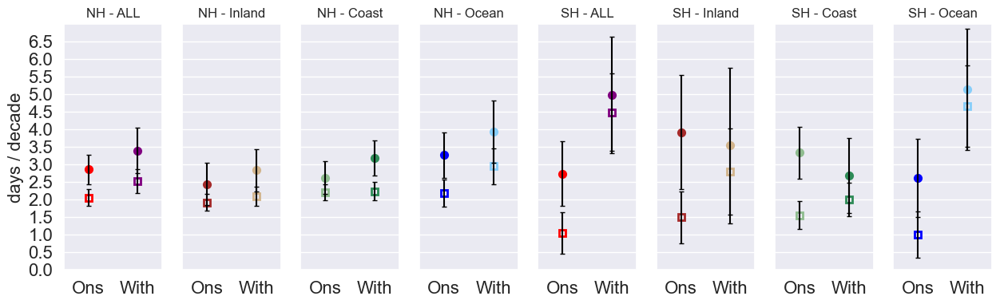

In [57]:
# plot params
ms = 6
caps = 2
palette_all={"SummerStart": "red", "SummerEnd": "purple"}
palette_land={"SummerStart": "brown", "SummerEnd": "tan"}
palette_coast={"SummerStart": "darkseagreen", "SummerEnd": "seagreen"}
palette_ocean={"SummerStart": "blue", "SummerEnd": "lightskyblue"}
xlabels = ['Ons','With']


fig=plt.figure(figsize=(15,4))#, layout='constrained')
#sns.set_context("paper")

#### Errors are multiplied by 2 to show 95% confidence values instead of 1 SE)


### NH ALL surface average
ax1 = fig.add_subplot(1,8,1)
ax1 = sns.pointplot(data=nh_full, x='Metric', y="Slope", hue="Metric", palette=palette_all, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax1.errorbar(nh_full['Metric'], nh_full['Slope'], yerr=2*nh_full['SE'], fmt="none", color="black", capsize=caps)
ax1 = sns.pointplot(data=nh_an, x="Metric", y="Slope", hue="Metric", palette=palette_all, markers=['o','o'], label="1990-2025", markersize=ms)
ax1.errorbar(nh_an['Metric'], nh_an['Slope'], yerr=2*nh_an['SE'], fmt="none", color="black", capsize=caps)
ax1.set_xticks(ticks=[0,1], labels=xlabels)
ax1.set_xlabel("")
ax1.set_ylabel("days / decade", fontsize=16)
ax1.set_title('NH - ALL', fontsize=12)
ax1.set_yticks(np.arange(0,7,0.5))
ax1.set_ylim(0,7)
ax1.set_xlim(-0.5, len(xlabels)-0.5)
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=16)


### NH Land surface average
ax3 = fig.add_subplot(1,8,2, sharey=ax1)
ax3 = sns.pointplot(data=nh_full_land, x='Metric', y="Slope", hue="Metric", palette=palette_land, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax3.errorbar(nh_full_land['Metric'], nh_full_land['Slope'], yerr=2*nh_full_land['SE'], fmt="none", color="black", capsize=caps)
ax3 = sns.pointplot(data=nh_an_land, x="Metric", y="Slope", hue="Metric", palette=palette_land, markers=['o','o'], label="1990-2025", markersize=ms)
ax3.errorbar(nh_an_land['Metric'], nh_an_land['Slope'], yerr=2*nh_an_land['SE'], fmt="none", color="black", capsize=caps)
ax3.set_xticks(ticks=[0,1], labels=xlabels)
ax3.set_xlabel("")
ax3.set_ylabel("")
ax3.set_title('NH - Inland', fontsize=12)
ax3.set_xlim(-0.5, len(xlabels)-0.5)
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=16, labelleft=False)

### NH Ocean surface average
ax4 = fig.add_subplot(1,8,4, sharey=ax1)
ax4 = sns.pointplot(data=nh_full_ocean, x='Metric', y="Slope", hue="Metric", palette=palette_ocean, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax4.errorbar(nh_full_ocean['Metric'], nh_full_ocean['Slope'], yerr=2*nh_full_ocean['SE'], fmt="none", color="black", capsize=caps)
ax4 = sns.pointplot(data=nh_an_ocean, x="Metric", y="Slope", hue="Metric", palette=palette_ocean, markers=['o','o'], label="1990-2025", markersize=ms)
ax4.errorbar(nh_an_ocean['Metric'], nh_an_ocean['Slope'], yerr=2*nh_an_ocean['SE'], fmt="none", color="black", capsize=caps)
ax4.set_xticks(ticks=[0,1], labels=xlabels)
ax4.set_xlabel("")
ax4.set_ylabel("")
ax4.set_title('NH - Ocean', fontsize=12)
ax4.set_xlim(-0.5, len(xlabels)-0.5)
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=16, labelleft=False)

### NH Coast surface average
ax5 = fig.add_subplot(1,8,3, sharey=ax1)
ax5 = sns.pointplot(data=nh_full_coast, x='Metric', y="Slope", hue="Metric", palette=palette_coast, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax5.errorbar(nh_full_coast['Metric'], nh_full_coast['Slope'], yerr=2*nh_full_coast['SE'], fmt="none", color="black", capsize=caps)
ax5 = sns.pointplot(data=nh_an_coast, x="Metric", y="Slope", hue="Metric", palette=palette_coast, markers=['o','o'], label="1990-2025", markersize=ms)
ax5.errorbar(nh_an_coast['Metric'], nh_an_coast['Slope'], yerr=2*nh_an_coast['SE'], fmt="none", color="black", capsize=caps)
ax5.set_xticks(ticks=[0,1], labels=xlabels)
ax5.set_xlabel("")
ax5.set_ylabel("")
ax5.set_title('NH - Coast', fontsize=12)
ax5.set_xlim(-0.5, len(xlabels)-0.5)
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=16, labelleft=False)


### SH ALL surface average
ax2 = fig.add_subplot(1,8,5, sharey=ax1)
ax2=sns.pointplot(data=sh_full, x='Metric', y="Slope", hue="Metric", palette=palette_all, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax2.errorbar(sh_full['Metric'], sh_full['Slope'], yerr=2*sh_full['SE'], fmt="none", color="black", capsize=caps)
ax2=sns.pointplot(data=sh_an, x="Metric", y="Slope", hue="Metric", palette=palette_all, markers=['o','o'], label="1990-2025", markersize=ms)
ax2.errorbar(sh_an['Metric'], sh_an['Slope'], yerr=2*sh_an['SE'], fmt="none", color="black", capsize=caps)
ax2.set_xticks(ticks=[0,1], labels=xlabels)
ax2.set_xlabel("")
ax2.set_ylabel("")
ax2.set_title('SH - ALL', fontsize=12)
ax2.set_xlim(-0.5, len(xlabels)-0.5)
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=16, labelleft=False)

### SH Land surface average
ax6 = fig.add_subplot(1,8,6, sharey=ax1)
ax6 = sns.pointplot(data=sh_full_land, x='Metric', y="Slope", hue="Metric", palette=palette_land, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax6.errorbar(sh_full_land['Metric'], sh_full_land['Slope'], yerr=2*sh_full_land['SE'], fmt="none", color="black", capsize=caps)
ax6 = sns.pointplot(data=sh_an_land, x="Metric", y="Slope", hue="Metric", palette=palette_land, markers=['o','o'], label="1990-2025", markersize=ms)
ax6.errorbar(sh_an_land['Metric'], sh_an_land['Slope'], yerr=2*sh_an_land['SE'], fmt="none", capsize=caps, color="black")
ax6.set_xticks(ticks=[0,1], labels=xlabels)
ax6.set_xlabel("")
ax6.set_ylabel("")
ax6.set_title('SH - Inland', fontsize=12)
ax6.set_xlim(-0.5, len(xlabels)-0.5)
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=16, labelleft=False)

### SH Ocean surface average
ax7 = fig.add_subplot(1,8,8, sharey=ax1)
ax7 = sns.pointplot(data=sh_full_ocean, x='Metric', y="Slope", hue="Metric", palette=palette_ocean, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax7.errorbar(sh_full_ocean['Metric'], sh_full_ocean['Slope'], yerr=2*sh_full_ocean['SE'], fmt="none", color="black", capsize=caps)
ax7 = sns.pointplot(data=sh_an_ocean, x="Metric", y="Slope", hue="Metric", palette=palette_ocean, markers=['o','o'], label="1990-2025", markersize=ms)
ax7.errorbar(sh_an_ocean['Metric'], sh_an_ocean['Slope'], yerr=2*sh_an_ocean['SE'], fmt="none", capsize=caps, color="black")
ax7.set_xticks(ticks=[0,1], labels=xlabels)
ax7.set_xlabel("")
ax7.set_ylabel("")
ax7.set_title('SH - Ocean', fontsize=12)
ax7.set_xlim(-0.5, len(xlabels)-0.5)
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=16, labelleft=False)

### SH Coast surface average
ax8 = fig.add_subplot(1,8,7, sharey=ax1)
ax8 = sns.pointplot(data=sh_full_coast, x='Metric', y="Slope", hue="Metric", palette=palette_coast, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax8.errorbar(sh_full_coast['Metric'], sh_full_coast['Slope'], yerr=2*sh_full_coast['SE'], fmt="none", color="black", capsize=caps)
ax8 = sns.pointplot(data=sh_an_coast, x="Metric", y="Slope", hue="Metric", palette=palette_coast, markers=['o','o'], label="1990-2025", markersize=ms)
ax8.errorbar(sh_an_coast['Metric'], sh_an_coast['Slope'], yerr=2*sh_an_coast['SE'], fmt="none", capsize=caps, color="black")
ax8.set_xticks(ticks=[0,1], labels=xlabels)
ax8.set_xlabel("")
ax8.set_ylabel("")
ax8.set_title('SH - Coast', fontsize=12)
ax8.set_xlim(-0.5, len(xlabels)-0.5)
plt.tick_params('x', labelsize=16)
plt.tick_params('y', labelsize=16, labelleft=False)


# plt.savefig("./Plots/All_Hemispheric_Onset_Withdrawal_Trends_with_error.png",bbox_inches='tight')
# plt.savefig("./Plots/All_Hemispheric_Onset_Withdrawal_Trends_with_error.pdf",bbox_inches='tight')

plt.show()


### Test for Stat Sig slope differences between onset and withdrawal 1990-2025

In [78]:
# help from https://stackoverflow.com/questions/66110650/how-to-compare-the-slopes-of-two-regression-lines
# and https://www.statsmodels.org/stable/examples/notebooks/generated/ols.html
# x=np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
# blue_y = np.array([0.94732871, 0.85729212, 0.86039587, 0.89169027, 0.90817473, 0.93606619, 0.93890423, 1., 0.97783521, 0.93035495])
# light_blue_y = np.array([0.81346023, 0.72248919, 0.72406021, 0.74823437, 0.77759055, 0.81167983,  0.84050726, 0.90357904, 0.97354455, 1. ])

# y = blue_y-light_blue_y
# # Let create a linear regression
# mod = sm.OLS(y, sm.add_constant(x))
# res = mod.fit()
# print(res.summary())
# #dir(res)
# # conf int on slope - if it contains zero then the diff is not significant
# print(res.conf_int()[1])
# if res.conf_int()[1][0] < 0.0 < res.conf_int()[1][1]: 
#     print("contains zero") 
# else: 
#     print("sig")

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.647
Model:                            OLS   Adj. R-squared:                  0.603
Method:                 Least Squares   F-statistic:                     14.67
Date:                Fri, 11 Jul 2025   Prob (F-statistic):            0.00502
Time:                        11:22:31   Log-Likelihood:                 18.081
No. Observations:                  10   AIC:                            -32.16
Df Residuals:                       8   BIC:                            -31.56
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.1775      0.026      6.807      0.0

In [58]:
%%time
# build datasets again because I rewrote their names above :(

nh_an_dat = ds.sel(time=slice('1990','2025')).where(((ds.lat >= nh_min) & (ds.lat <= nh_max))).weighted(weights).mean(dim=['lat','lon'])
sh_an_dat = ds.sel(time=slice('1990','2025')).where(((ds.lat >= sh_max) & (ds.lat <= sh_min))).weighted(weights).mean(dim=['lat','lon'])


nh_land_an_dat = ds.sel(time=slice('1990','2025')).where((ds.lsm > 0.5)  & (ds.Coastal == False) & #& (ds.SummerMeanT > 0)
                                                          ((ds.lat >= nh_min) & (ds.lat <= nh_max))).weighted(weights).mean(dim=['lat','lon'])

nh_coast_an_dat = ds.sel(time=slice('1990','2025')).where((ds.Coastal)  & #& (ds.SummerMeanT > 0)
                                                           ((ds.lat >= nh_min) & (ds.lat <= nh_max))).weighted(weights).mean(dim=['lat','lon'])

sh_land_an_dat = ds.sel(time=slice('1990','2025')).where((ds.lsm > 0.5)  & (ds.Coastal == False) & #& (ds.SummerMeanT > 0)
                                                          ((ds.lat >= sh_max) & (ds.lat <= sh_min))).weighted(weights).mean(dim=['lat','lon'])

sh_coast_an_dat = ds.sel(time=slice('1990','2025')).where((ds.Coastal)  & #& (ds.SummerMeanT > 0)
                                                           ((ds.lat >= sh_max) & (ds.lat <= sh_min))).weighted(weights).mean(dim=['lat','lon'])

nh_ocean_an_dat = ds.sel(time=slice('1990','2025')).where((ds.lsm <= 0.5) & #(ds.SummerMeanT > 0) &
                                                           ((ds.lat >= nh_min) & (ds.lat <= nh_max))).weighted(weights).mean(dim=['lat','lon'])

sh_ocean_an_dat = ds.sel(time=slice('1990','2025')).where((ds.lsm <= 0.5) & #(ds.SummerMeanT > 0) &
                                                           ((ds.lat >= sh_max) & (ds.lat <= sh_min))).weighted(weights).mean(dim=['lat','lon'])


CPU times: user 9.23 s, sys: 7.88 s, total: 17.1 s
Wall time: 18 s


In [59]:
x = nh_an_dat.time.dt.year.values
y1 = nh_an_dat.SummerStart.values
y2 = nh_an_dat.SummerEnd.values

# have to reflect y1 so that both onset and with are increasing over time
y1 = np.max(y1) - y1 + np.max(y1)

# check with plot
# plt.plot(x,y2, c='blue')
# plt.plot(x,y1, c='red')
# plt.plot(x, y2-y1, c='green')

y = y2-y1
# Let create a linear regression
mod = sm.OLS(y, sm.add_constant(x))
res = mod.fit()
#print(res.summary())
# conf int on slope - if it contains zero then the diff is not significant
print(res.conf_int()[1])
if res.conf_int()[1][0] < 0.0 < res.conf_int()[1][1]: 
    print("not sig contains zero") 
else: 
    print("sig")

[0.00129007 0.10680474]
sig


In [60]:
x = nh_land_an_dat.time.dt.year.values
y1 = nh_land_an_dat.SummerStart.values
y2 = nh_land_an_dat.SummerEnd.values

# have to reflect y1 so that both onset and with are increasing over time
y1 = np.max(y1) - y1 + np.max(y1)
y = y2-y1
# Let create a linear regression
mod = sm.OLS(y, sm.add_constant(x))
res = mod.fit()
# conf int on slope - if it contains zero then the diff is not significant
print(res.conf_int()[1])
if res.conf_int()[1][0] < 0.0 < res.conf_int()[1][1]: 
    print("not sig contains zero") 
else: 
    print("sig")

[-0.01830392  0.09888622]
not sig contains zero


In [61]:
x = nh_ocean_an_dat.time.dt.year.values
y1 = nh_ocean_an_dat.SummerStart.values
y2 = nh_ocean_an_dat.SummerEnd.values

# have to reflect y1 so that both onset and with are increasing over time
y1 = np.max(y1) - y1 + np.max(y1)
y = y2-y1
# Let create a linear regression
mod = sm.OLS(y, sm.add_constant(x))
res = mod.fit()
# conf int on slope - if it contains zero then the diff is not significant
print(res.conf_int()[1])
if res.conf_int()[1][0] < 0.0 < res.conf_int()[1][1]: 
    print("not sig contains zero") 
else: 
    print("sig")

[-0.01000405  0.14506729]
not sig contains zero


#### NH Coast SIG *onset vs withdrawal*

[0.01111035 0.10076206]
sig


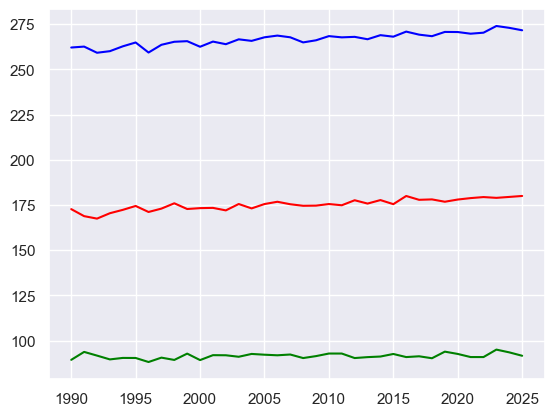

In [62]:
x = nh_coast_an_dat.time.dt.year.values
y1 = nh_coast_an_dat.SummerStart.values
y2 = nh_coast_an_dat.SummerEnd.values

# have to reflect y1 so that both onset and with are increasing over time
y1 = np.max(y1) - y1 + np.max(y1)

# check with plot
plt.plot(x,y2, c='blue')
plt.plot(x,y1, c='red')
plt.plot(x, y2-y1, c='green')

y = y2-y1
# Let create a linear regression
mod = sm.OLS(y, sm.add_constant(x))
res = mod.fit()
# conf int on slope - if it contains zero then the diff is not significant
print(res.conf_int()[1])
if res.conf_int()[1][0] < 0.0 < res.conf_int()[1][1]: 
    print("not sig contains zero") 
else: 
    print("sig")

[-0.00250131  0.45218182]
not sig contains zero


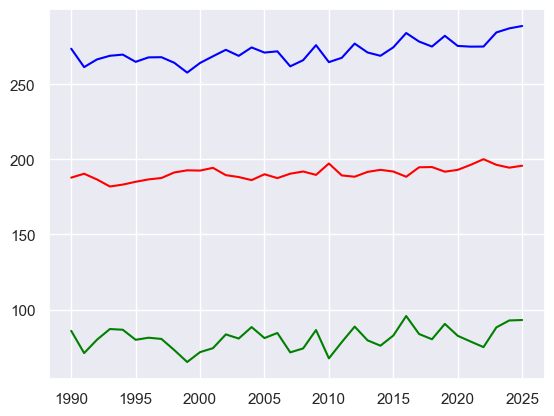

In [63]:
x = sh_an_dat.time.dt.year.values
y1 = sh_an_dat.SummerStart.values
y2 = sh_an_dat.SummerEnd.values

# have to reflect y1 so that both onset and with are increasing over time
y1 = np.max(y1) - y1 + np.max(y1)

# check with plot
plt.plot(x,y2, c='blue')
plt.plot(x,y1, c='red')
plt.plot(x, y2-y1, c='green')

y = y2-y1
# Let create a linear regression
mod = sm.OLS(y, sm.add_constant(x))
res = mod.fit()
#print(res.summary())
# conf int on slope - if it contains zero then the diff is not significant
print(res.conf_int()[1])
if res.conf_int()[1][0] < 0.0 < res.conf_int()[1][1]: 
    print("not sig contains zero") 
else: 
    print("sig")

[-0.28788352  0.21210353]
not sig contains zero


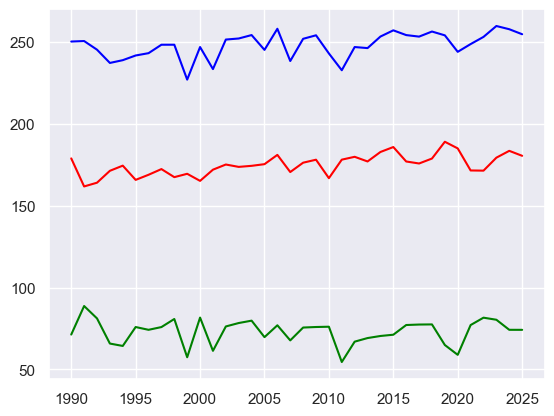

In [64]:
x = sh_land_an_dat.time.dt.year.values
y1 = sh_land_an_dat.SummerStart.values
y2 = sh_land_an_dat.SummerEnd.values

# have to reflect y1 so that both onset and with are increasing over time
y1 = np.max(y1) - y1 + np.max(y1)

# check with plot
plt.plot(x,y2, c='blue')
plt.plot(x,y1, c='red')
plt.plot(x, y2-y1, c='green')

y = y2-y1
# Let create a linear regression
mod = sm.OLS(y, sm.add_constant(x))
res = mod.fit()
#print(res.summary())
# conf int on slope - if it contains zero then the diff is not significant
print(res.conf_int()[1])
if res.conf_int()[1][0] < 0.0 < res.conf_int()[1][1]: 
    print("not sig contains zero") 
else: 
    print("sig")

[-0.19306928  0.0630489 ]
not sig contains zero


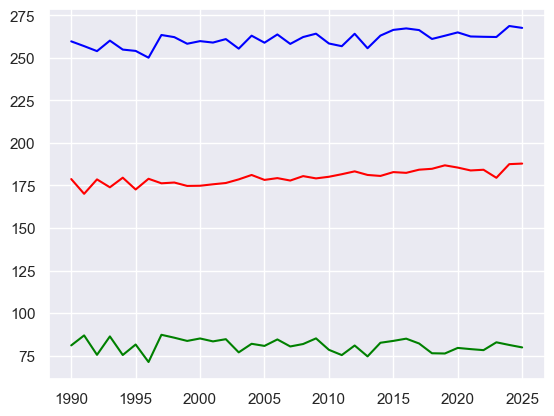

In [65]:
x = sh_coast_an_dat.time.dt.year.values
y1 = sh_coast_an_dat.SummerStart.values
y2 = sh_coast_an_dat.SummerEnd.values

# have to reflect y1 so that both onset and with are increasing over time
y1 = np.max(y1) - y1 + np.max(y1)

# check with plot
plt.plot(x,y2, c='blue')
plt.plot(x,y1, c='red')
plt.plot(x, y2-y1, c='green')

y = y2-y1
# Let create a linear regression
mod = sm.OLS(y, sm.add_constant(x))
res = mod.fit()
#print(res.summary())
# conf int on slope - if it contains zero then the diff is not significant
print(res.conf_int()[1])
if res.conf_int()[1][0] < 0.0 < res.conf_int()[1][1]: 
    print("not sig contains zero") 
else: 
    print("sig")

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.109
Model:                            OLS   Adj. R-squared:                  0.082
Method:                 Least Squares   F-statistic:                     4.146
Date:                Mon, 20 Jul 2026   Prob (F-statistic):             0.0496
Time:                        11:40:39   Log-Likelihood:                -123.65
No. Observations:                  36   AIC:                             251.3
Df Residuals:                      34   BIC:                             254.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -426.6427    248.791     -1.715      0.0

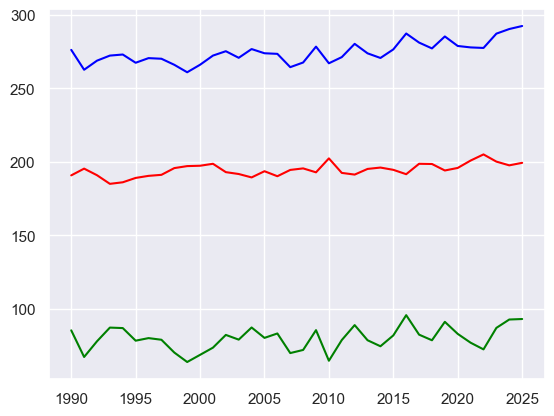

In [66]:
x = sh_ocean_an_dat.time.dt.year.values
y1 = sh_ocean_an_dat.SummerStart.values
y2 = sh_ocean_an_dat.SummerEnd.values

# have to reflect y1 so that both onset and with are increasing over time
y1 = np.max(y1) - y1 + np.max(y1)

# check with plot
plt.plot(x,y2, c='blue')
plt.plot(x,y1, c='red')
plt.plot(x, y2-y1, c='green')

y = y2-y1
# Let create a linear regression
mod = sm.OLS(y, sm.add_constant(x))
res = mod.fit()
print(res.summary())
# conf int on slope - if it contains zero then the diff is not significant
print(res.conf_int()[1])
if res.conf_int()[1][0] < 0.0 < res.conf_int()[1][1]: 
    print("not sig contains zero") 
else: 
    print("sig")

In [34]:
df_plot.query('Metric in ["SummerHeat"] & Surface == "All" ')

,Metric,Surface,Hemisphere,Slope,SE,Period
32,SummerHeat,All,NH,25.42,1.60,1961-2023
36,SummerHeat,All,SH,11.49,0.76,1961-2023
40,SummerHeat,All,NH,39.00,3.27,1990-2023
44,SummerHeat,All,SH,16.03,1.69,1990-2023


#### Accumulated Heat Plots

In [67]:
# data slices
nh_full = df_plot.query('Hemisphere == "NH" & Metric in ["SummerHeat"] & Surface == "All" & Period == "1961-2025" ')
nh_an = df_plot.query('Hemisphere == "NH" & Metric in ["SummerHeat"] & Surface == "All" & Period == "1990-2025" ')
sh_full = df_plot.query('Hemisphere == "SH" & Metric in ["SummerHeat"] & Surface == "All" & Period == "1961-2025" ')
sh_an = df_plot.query('Hemisphere == "SH" & Metric in ["SummerHeat"] & Surface == "All" & Period == "1990-2025" ')

nh_full_land = df_plot.query('Hemisphere == "NH" & Metric in ["SummerHeat"] & Surface == "Land" & Period == "1961-2025" ')
nh_an_land = df_plot.query('Hemisphere == "NH" & Metric in ["SummerHeat"] & Surface == "Land" & Period == "1990-2025" ')
sh_full_land = df_plot.query('Hemisphere == "SH" & Metric in ["SummerHeat"] & Surface == "Land" & Period == "1961-2025" ')
sh_an_land = df_plot.query('Hemisphere == "SH" & Metric in ["SummerHeat"] & Surface == "Land" & Period == "1990-2025" ')

nh_full_ocean = df_plot.query('Hemisphere == "NH" & Metric in ["SummerHeat"] & Surface == "Ocean" & Period == "1961-2025" ')
nh_an_ocean = df_plot.query('Hemisphere == "NH" & Metric in ["SummerHeat"] & Surface == "Ocean" & Period == "1990-2025" ')
sh_full_ocean = df_plot.query('Hemisphere == "SH" & Metric in ["SummerHeat"] & Surface == "Ocean" & Period == "1961-2025" ')
sh_an_ocean = df_plot.query('Hemisphere == "SH" & Metric in ["SummerHeat"] & Surface == "Ocean" & Period == "1990-2025" ')

nh_full_coast = df_plot.query('Hemisphere == "NH" & Metric in ["SummerHeat"] & Surface == "Coast" & Period == "1961-2025" ')
nh_an_coast = df_plot.query('Hemisphere == "NH" & Metric in ["SummerHeat"] & Surface == "Coast" & Period == "1990-2025" ')
sh_full_coast = df_plot.query('Hemisphere == "SH" & Metric in ["SummerHeat"] & Surface == "Coast" & Period == "1961-2025" ')
sh_an_coast = df_plot.query('Hemisphere == "SH" & Metric in ["SummerHeat"] & Surface == "Coast" & Period == "1990-2025" ')

nh_full

,Metric,Surface,Hemisphere,Slope,SE,Period
48,SummerHeat,All,NH,26.79,1.61,1961-2025


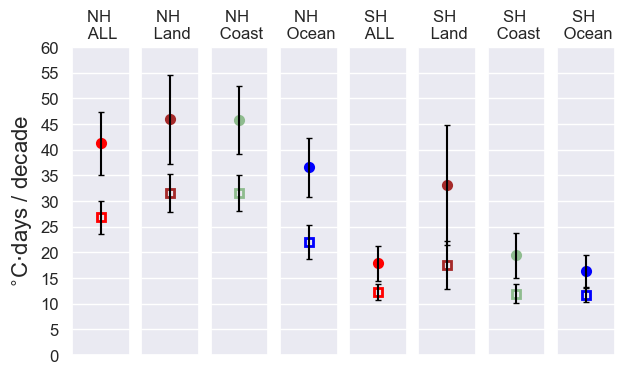

In [68]:
# plot params
ms = 6
caps = 2
palette_all={"SummerHeat": "red"}
palette_land={"SummerHeat": "brown"}
palette_coast={"SummerHeat": "darkseagreen"}
palette_ocean={"SummerHeat": "blue"}
xlabels = ['Heat']


fig=plt.figure(figsize=(7,4))#, layout='constrained')
#sns.set_context("paper")

#### Errors are multiplied by 2 to show 95% confidence values instead of 1 SE)


### NH ALL surface average
ax1 = fig.add_subplot(1,8,1)
ax1 = sns.pointplot(data=nh_full, x='Metric', y="Slope", hue="Metric", palette=palette_all, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax1.errorbar(nh_full['Metric'], nh_full['Slope'], yerr=2*nh_full['SE'], fmt="none", color="black", capsize=caps)
ax1 = sns.pointplot(data=nh_an, x="Metric", y="Slope", hue="Metric", palette=palette_all, markers=['o','o'], label="1990-2025", markersize=ms)
ax1.errorbar(nh_an['Metric'], nh_an['Slope'], yerr=2*nh_an['SE'], fmt="none", color="black", capsize=caps)
#ax1.set_xticks(ticks=[0.5], labels=xlabels)
ax1.set_xlabel("")
ax1.set_ylabel("$^{\circ}$C$\cdot$days / decade", fontsize=16)
ax1.set_title('NH \n ALL', fontsize=12)
ax1.set_yticks(np.arange(0,70,5), minor=False)
ax1.set_ylim(0,60)
ax1.set_xlim(-0.5, len(xlabels)-0.5)
plt.tick_params('x', labelsize=16, labelbottom=False)
plt.tick_params('y', labelsize=12)


### NH Land surface average
ax3 = fig.add_subplot(1,8,2, sharey=ax1)
ax3 = sns.pointplot(data=nh_full_land, x='Metric', y="Slope", hue="Metric", palette=palette_land, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax3.errorbar(nh_full_land['Metric'], nh_full_land['Slope'], yerr=2*nh_full_land['SE'], fmt="none", color="black", capsize=caps)
ax3 = sns.pointplot(data=nh_an_land, x="Metric", y="Slope", hue="Metric", palette=palette_land, markers=['o','o'], label="1990-2025", markersize=ms)
ax3.errorbar(nh_an_land['Metric'], nh_an_land['Slope'], yerr=2*nh_an_land['SE'], fmt="none", color="black", capsize=caps)
#ax3.set_xticks(ticks=[0,1], labels=xlabels)
ax3.set_xlabel("")
ax3.set_ylabel("")
ax3.set_title('NH \n Land', fontsize=12)
ax3.set_xlim(-0.5, len(xlabels)-0.5)
plt.tick_params('x', labelsize=16, labelbottom=False)
plt.tick_params('y', labelsize=16, labelleft=False)

### NH Ocean surface average
ax4 = fig.add_subplot(1,8,4, sharey=ax1)
ax4 = sns.pointplot(data=nh_full_ocean, x='Metric', y="Slope", hue="Metric", palette=palette_ocean, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax4.errorbar(nh_full_ocean['Metric'], nh_full_ocean['Slope'], yerr=2*nh_full_ocean['SE'], fmt="none", color="black", capsize=caps)
ax4 = sns.pointplot(data=nh_an_ocean, x="Metric", y="Slope", hue="Metric", palette=palette_ocean, markers=['o','o'], label="1990-2025", markersize=ms)
ax4.errorbar(nh_an_ocean['Metric'], nh_an_ocean['Slope'], yerr=2*nh_an_ocean['SE'], fmt="none", color="black", capsize=caps)
#ax4.set_xticks(ticks=[0,1], labels=xlabels)
ax4.set_xlabel("")
ax4.set_ylabel("")
ax4.set_title('NH \n Ocean', fontsize=12)
ax4.set_xlim(-0.5, len(xlabels)-0.5)
plt.tick_params('x', labelsize=16, labelbottom=False)
plt.tick_params('y', labelsize=16, labelleft=False)

### NH Coast surface average
ax5 = fig.add_subplot(1,8,3, sharey=ax1)
ax5 = sns.pointplot(data=nh_full_coast, x='Metric', y="Slope", hue="Metric", palette=palette_coast, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax5.errorbar(nh_full_coast['Metric'], nh_full_coast['Slope'], yerr=2*nh_full_coast['SE'], fmt="none", color="black", capsize=caps)
ax5 = sns.pointplot(data=nh_an_coast, x="Metric", y="Slope", hue="Metric", palette=palette_coast, markers=['o','o'], label="1990-2025", markersize=ms)
ax5.errorbar(nh_an_coast['Metric'], nh_an_coast['Slope'], yerr=2*nh_an_coast['SE'], fmt="none", color="black", capsize=caps)
#ax5.set_xticks(ticks=[0,1], labels=xlabels)
ax5.set_xlabel("")
ax5.set_ylabel("")
ax5.set_title('NH \n Coast', fontsize=12)
ax5.set_xlim(-0.5, len(xlabels)-0.5)
plt.tick_params('x', labelsize=16, labelbottom=False)
plt.tick_params('y', labelsize=16, labelleft=False)


### SH ALL surface average
ax2 = fig.add_subplot(1,8,5, sharey=ax1)
ax2=sns.pointplot(data=sh_full, x='Metric', y="Slope", hue="Metric", palette=palette_all, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax2.errorbar(sh_full['Metric'], sh_full['Slope'], yerr=2*sh_full['SE'], fmt="none", color="black", capsize=caps)
ax2=sns.pointplot(data=sh_an, x="Metric", y="Slope", hue="Metric", palette=palette_all, markers=['o','o'], label="1990-2025", markersize=ms)
ax2.errorbar(sh_an['Metric'], sh_an['Slope'], yerr=2*sh_an['SE'], fmt="none", color="black", capsize=caps)
#ax2.set_xticks(ticks=[0,1], labels=xlabels)
ax2.set_xlabel("")
ax2.set_ylabel("")
ax2.set_title('SH \n ALL', fontsize=12)
ax2.set_xlim(-0.5, len(xlabels)-0.5)
plt.tick_params('x', labelsize=16, labelbottom=False)
plt.tick_params('y', labelsize=16, labelleft=False)

### SH Land surface average
ax6 = fig.add_subplot(1,8,6, sharey=ax1)
ax6 = sns.pointplot(data=sh_full_land, x='Metric', y="Slope", hue="Metric", palette=palette_land, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax6.errorbar(sh_full_land['Metric'], sh_full_land['Slope'], yerr=2*sh_full_land['SE'], fmt="none", color="black", capsize=caps)
ax6 = sns.pointplot(data=sh_an_land, x="Metric", y="Slope", hue="Metric", palette=palette_land, markers=['o','o'], label="1990-2025", markersize=ms)
ax6.errorbar(sh_an_land['Metric'], sh_an_land['Slope'], yerr=2*sh_an_land['SE'], fmt="none", capsize=caps, color="black")
#ax6.set_xticks(ticks=[0,1], labels=xlabels)
ax6.set_xlabel("")
ax6.set_ylabel("")
ax6.set_title('SH \n Land', fontsize=12)
ax6.set_xlim(-0.5, len(xlabels)-0.5)
plt.tick_params('x', labelsize=16, labelbottom=False)
plt.tick_params('y', labelsize=16, labelleft=False)

### SH Ocean surface average
ax7 = fig.add_subplot(1,8,8, sharey=ax1)
ax7 = sns.pointplot(data=sh_full_ocean, x='Metric', y="Slope", hue="Metric", palette=palette_ocean, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax7.errorbar(sh_full_ocean['Metric'], sh_full_ocean['Slope'], yerr=2*sh_full_ocean['SE'], fmt="none", color="black", capsize=caps)
ax7 = sns.pointplot(data=sh_an_ocean, x="Metric", y="Slope", hue="Metric", palette=palette_ocean, markers=['o','o'], label="1990-2025", markersize=ms)
ax7.errorbar(sh_an_ocean['Metric'], sh_an_ocean['Slope'], yerr=2*sh_an_ocean['SE'], fmt="none", capsize=caps, color="black")
#ax7.set_xticks(ticks=[0,1], labels=xlabels)
ax7.set_xlabel("")
ax7.set_ylabel("")
ax7.set_title('SH \n Ocean', fontsize=12)
ax7.set_xlim(-0.5, len(xlabels)-0.5)
plt.tick_params('x', labelsize=16, labelbottom=False)
plt.tick_params('y', labelsize=16, labelleft=False)

### SH Coast surface average
ax8 = fig.add_subplot(1,8,7, sharey=ax1)
ax8 = sns.pointplot(data=sh_full_coast, x='Metric', y="Slope", hue="Metric", palette=palette_coast, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax8.errorbar(sh_full_coast['Metric'], sh_full_coast['Slope'], yerr=2*sh_full_coast['SE'], fmt="none", color="black", capsize=caps)
ax8 = sns.pointplot(data=sh_an_coast, x="Metric", y="Slope", hue="Metric", palette=palette_coast, markers=['o','o'], label="1990-2025", markersize=ms)
ax8.errorbar(sh_an_coast['Metric'], sh_an_coast['Slope'], yerr=2*sh_an_coast['SE'], fmt="none", capsize=caps, color="black")
#ax8.set_xticks(ticks=[0,1], labels=xlabels)
ax8.set_xlabel("")
ax8.set_ylabel("")
ax8.set_title('SH \n Coast', fontsize=12)
ax8.set_xlim(-0.5, len(xlabels)-0.5)
plt.tick_params('x', labelsize=16, labelbottom=False)
plt.tick_params('y', labelsize=16, labelleft=False)

# plt.savefig("./Plots/AccumulatedHeat_Trends_by_surface_with_errorbars.png",bbox_inches='tight')
# plt.savefig("./Plots/AccumulatedHeat_Trends_by_surface_with_errorbars.pdf",bbox_inches='tight')

plt.show()


In [302]:
from matplotlib import markers
print(markers.MarkerStyle.markers.keys())

dict_keys(['.', ',', 'o', 'v', '^', '<', '>', '1', '2', '3', '4', '8', 's', 'p', '*', 'h', 'H', '+', 'x', 'D', 'd', '|', '_', 'P', 'X', 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 'None', 'none', ' ', ''])


#### Summer Like Days Plots

In [69]:
df_plot.query('Metric in ["SummerlikeDays"] & Surface == "All" ')

,Metric,Surface,Hemisphere,Slope,SE,Period
96,SummerlikeDays,All,NH,4.83,0.28,1961-2025
100,SummerlikeDays,All,SH,5.17,0.37,1961-2025
104,SummerlikeDays,All,NH,6.70,0.50,1990-2025
108,SummerlikeDays,All,SH,7.21,0.72,1990-2025
112,SummerlikeDays,All,NH,0.85,0.75,1961-1990
116,SummerlikeDays,All,SH,8.79,1.07,1961-1990


In [70]:
# data slices
nh_full = df_plot.query('Hemisphere == "NH" & Metric in ["SummerlikeDays"] & Surface == "All" & Period == "1961-2025" ')
nh_an = df_plot.query('Hemisphere == "NH" & Metric in ["SummerlikeDays"] & Surface == "All" & Period == "1990-2025" ')
sh_full = df_plot.query('Hemisphere == "SH" & Metric in ["SummerlikeDays"] & Surface == "All" & Period == "1961-2025" ')
sh_an = df_plot.query('Hemisphere == "SH" & Metric in ["SummerlikeDays"] & Surface == "All" & Period == "1990-2025" ')

nh_full_land = df_plot.query('Hemisphere == "NH" & Metric in ["SummerlikeDays"] & Surface == "Land" & Period == "1961-2025" ')
nh_an_land = df_plot.query('Hemisphere == "NH" & Metric in ["SummerlikeDays"] & Surface == "Land" & Period == "1990-2025" ')
sh_full_land = df_plot.query('Hemisphere == "SH" & Metric in ["SummerlikeDays"] & Surface == "Land" & Period == "1961-2025" ')
sh_an_land = df_plot.query('Hemisphere == "SH" & Metric in ["SummerlikeDays"] & Surface == "Land" & Period == "1990-2025" ')

nh_full_ocean = df_plot.query('Hemisphere == "NH" & Metric in ["SummerlikeDays"] & Surface == "Ocean" & Period == "1961-2025" ')
nh_an_ocean = df_plot.query('Hemisphere == "NH" & Metric in ["SummerlikeDays"] & Surface == "Ocean" & Period == "1990-2025" ')
sh_full_ocean = df_plot.query('Hemisphere == "SH" & Metric in ["SummerlikeDays"] & Surface == "Ocean" & Period == "1961-2025" ')
sh_an_ocean = df_plot.query('Hemisphere == "SH" & Metric in ["SummerlikeDays"] & Surface == "Ocean" & Period == "1990-2025" ')

nh_full_coast = df_plot.query('Hemisphere == "NH" & Metric in ["SummerlikeDays"] & Surface == "Coast" & Period == "1961-2025" ')
nh_an_coast = df_plot.query('Hemisphere == "NH" & Metric in ["SummerlikeDays"] & Surface == "Coast" & Period == "1990-2025" ')
sh_full_coast = df_plot.query('Hemisphere == "SH" & Metric in ["SummerlikeDays"] & Surface == "Coast" & Period == "1961-2025" ')
sh_an_coast = df_plot.query('Hemisphere == "SH" & Metric in ["SummerlikeDays"] & Surface == "Coast" & Period == "1990-2025" ')

nh_full

,Metric,Surface,Hemisphere,Slope,SE,Period
96,SummerlikeDays,All,NH,4.83,0.28,1961-2025


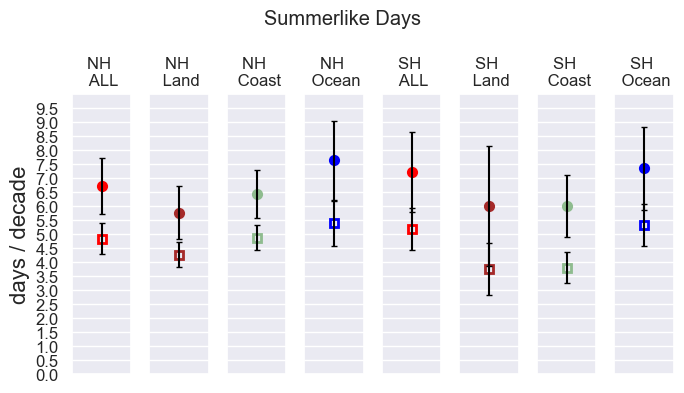

In [73]:
# plot params
ms = 6
caps = 2
palette_all={"SummerlikeDays": "red"}
palette_land={"SummerlikeDays": "brown"}
palette_coast={"SummerlikeDays": "darkseagreen"}
palette_ocean={"SummerlikeDays": "blue"}
xlabels = ['Heat']


fig=plt.figure(figsize=(7,4))#, layout='constrained')
#sns.set_context("paper")

#### Errors are multiplied by 2 to show 95% confidence values instead of 1 SE)
plt.suptitle("Summerlike Days")

### NH ALL surface average
ax1 = fig.add_subplot(1,8,1)
ax1 = sns.pointplot(data=nh_full, x='Metric', y="Slope", hue="Metric", palette=palette_all, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax1.errorbar(nh_full['Metric'], nh_full['Slope'], yerr=2*nh_full['SE'], fmt="none", color="black", capsize=caps)
ax1 = sns.pointplot(data=nh_an, x="Metric", y="Slope", hue="Metric", palette=palette_all, markers=['o','o'], label="1990-2025", markersize=ms)
ax1.errorbar(nh_an['Metric'], nh_an['Slope'], yerr=2*nh_an['SE'], fmt="none", color="black", capsize=caps)
#ax1.set_xticks(ticks=[0.5], labels=xlabels)
ax1.set_xlabel("")
ax1.set_ylabel("days / decade", fontsize=16)
ax1.set_title('NH \n ALL', fontsize=12)
ax1.set_yticks(np.arange(0,10,0.5), minor=False)
ax1.set_ylim(0,10)
ax1.set_xlim(-0.5, len(xlabels)-0.5)
plt.tick_params('x', labelsize=16, labelbottom=False)
plt.tick_params('y', labelsize=12)


### NH Land surface average
ax3 = fig.add_subplot(1,8,2, sharey=ax1)
ax3 = sns.pointplot(data=nh_full_land, x='Metric', y="Slope", hue="Metric", palette=palette_land, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax3.errorbar(nh_full_land['Metric'], nh_full_land['Slope'], yerr=2*nh_full_land['SE'], fmt="none", color="black", capsize=caps)
ax3 = sns.pointplot(data=nh_an_land, x="Metric", y="Slope", hue="Metric", palette=palette_land, markers=['o','o'], label="1990-2025", markersize=ms)
ax3.errorbar(nh_an_land['Metric'], nh_an_land['Slope'], yerr=2*nh_an_land['SE'], fmt="none", color="black", capsize=caps)
#ax3.set_xticks(ticks=[0,1], labels=xlabels)
ax3.set_xlabel("")
ax3.set_ylabel("")
ax3.set_title('NH \n Land', fontsize=12)
ax3.set_xlim(-0.5, len(xlabels)-0.5)
plt.tick_params('x', labelsize=16, labelbottom=False)
plt.tick_params('y', labelsize=16, labelleft=False)

### NH Ocean surface average
ax4 = fig.add_subplot(1,8,4, sharey=ax1)
ax4 = sns.pointplot(data=nh_full_ocean, x='Metric', y="Slope", hue="Metric", palette=palette_ocean, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax4.errorbar(nh_full_ocean['Metric'], nh_full_ocean['Slope'], yerr=2*nh_full_ocean['SE'], fmt="none", color="black", capsize=caps)
ax4 = sns.pointplot(data=nh_an_ocean, x="Metric", y="Slope", hue="Metric", palette=palette_ocean, markers=['o','o'], label="1990-2025", markersize=ms)
ax4.errorbar(nh_an_ocean['Metric'], nh_an_ocean['Slope'], yerr=2*nh_an_ocean['SE'], fmt="none", color="black", capsize=caps)
#ax4.set_xticks(ticks=[0,1], labels=xlabels)
ax4.set_xlabel("")
ax4.set_ylabel("")
ax4.set_title('NH \n Ocean', fontsize=12)
ax4.set_xlim(-0.5, len(xlabels)-0.5)
plt.tick_params('x', labelsize=16, labelbottom=False)
plt.tick_params('y', labelsize=16, labelleft=False)

### NH Coast surface average
ax5 = fig.add_subplot(1,8,3, sharey=ax1)
ax5 = sns.pointplot(data=nh_full_coast, x='Metric', y="Slope", hue="Metric", palette=palette_coast, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax5.errorbar(nh_full_coast['Metric'], nh_full_coast['Slope'], yerr=2*nh_full_coast['SE'], fmt="none", color="black", capsize=caps)
ax5 = sns.pointplot(data=nh_an_coast, x="Metric", y="Slope", hue="Metric", palette=palette_coast, markers=['o','o'], label="1990-2025", markersize=ms)
ax5.errorbar(nh_an_coast['Metric'], nh_an_coast['Slope'], yerr=2*nh_an_coast['SE'], fmt="none", color="black", capsize=caps)
#ax5.set_xticks(ticks=[0,1], labels=xlabels)
ax5.set_xlabel("")
ax5.set_ylabel("")
ax5.set_title('NH \n Coast', fontsize=12)
ax5.set_xlim(-0.5, len(xlabels)-0.5)
plt.tick_params('x', labelsize=16, labelbottom=False)
plt.tick_params('y', labelsize=16, labelleft=False)


### SH ALL surface average
ax2 = fig.add_subplot(1,8,5, sharey=ax1)
ax2=sns.pointplot(data=sh_full, x='Metric', y="Slope", hue="Metric", palette=palette_all, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax2.errorbar(sh_full['Metric'], sh_full['Slope'], yerr=2*sh_full['SE'], fmt="none", color="black", capsize=caps)
ax2=sns.pointplot(data=sh_an, x="Metric", y="Slope", hue="Metric", palette=palette_all, markers=['o','o'], label="1990-2025", markersize=ms)
ax2.errorbar(sh_an['Metric'], sh_an['Slope'], yerr=2*sh_an['SE'], fmt="none", color="black", capsize=caps)
#ax2.set_xticks(ticks=[0,1], labels=xlabels)
ax2.set_xlabel("")
ax2.set_ylabel("")
ax2.set_title('SH \n ALL', fontsize=12)
ax2.set_xlim(-0.5, len(xlabels)-0.5)
plt.tick_params('x', labelsize=16, labelbottom=False)
plt.tick_params('y', labelsize=16, labelleft=False)

### SH Land surface average
ax6 = fig.add_subplot(1,8,6, sharey=ax1)
ax6 = sns.pointplot(data=sh_full_land, x='Metric', y="Slope", hue="Metric", palette=palette_land, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax6.errorbar(sh_full_land['Metric'], sh_full_land['Slope'], yerr=2*sh_full_land['SE'], fmt="none", color="black", capsize=caps)
ax6 = sns.pointplot(data=sh_an_land, x="Metric", y="Slope", hue="Metric", palette=palette_land, markers=['o','o'], label="1990-2025", markersize=ms)
ax6.errorbar(sh_an_land['Metric'], sh_an_land['Slope'], yerr=2*sh_an_land['SE'], fmt="none", capsize=caps, color="black")
#ax6.set_xticks(ticks=[0,1], labels=xlabels)
ax6.set_xlabel("")
ax6.set_ylabel("")
ax6.set_title('SH \n Land', fontsize=12)
ax6.set_xlim(-0.5, len(xlabels)-0.5)
plt.tick_params('x', labelsize=16, labelbottom=False)
plt.tick_params('y', labelsize=16, labelleft=False)

### SH Ocean surface average
ax7 = fig.add_subplot(1,8,8, sharey=ax1)
ax7 = sns.pointplot(data=sh_full_ocean, x='Metric', y="Slope", hue="Metric", palette=palette_ocean, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax7.errorbar(sh_full_ocean['Metric'], sh_full_ocean['Slope'], yerr=2*sh_full_ocean['SE'], fmt="none", color="black", capsize=caps)
ax7 = sns.pointplot(data=sh_an_ocean, x="Metric", y="Slope", hue="Metric", palette=palette_ocean, markers=['o','o'], label="1990-2025", markersize=ms)
ax7.errorbar(sh_an_ocean['Metric'], sh_an_ocean['Slope'], yerr=2*sh_an_ocean['SE'], fmt="none", capsize=caps, color="black")
#ax7.set_xticks(ticks=[0,1], labels=xlabels)
ax7.set_xlabel("")
ax7.set_ylabel("")
ax7.set_title('SH \n Ocean', fontsize=12)
ax7.set_xlim(-0.5, len(xlabels)-0.5)
plt.tick_params('x', labelsize=16, labelbottom=False)
plt.tick_params('y', labelsize=16, labelleft=False)

### SH Coast surface average
ax8 = fig.add_subplot(1,8,7, sharey=ax1)
ax8 = sns.pointplot(data=sh_full_coast, x='Metric', y="Slope", hue="Metric", palette=palette_coast, markers=['s','s'], label="1961-2025", markersize=ms, fillstyle='none')
ax8.errorbar(sh_full_coast['Metric'], sh_full_coast['Slope'], yerr=2*sh_full_coast['SE'], fmt="none", color="black", capsize=caps)
ax8 = sns.pointplot(data=sh_an_coast, x="Metric", y="Slope", hue="Metric", palette=palette_coast, markers=['o','o'], label="1990-2025", markersize=ms)
ax8.errorbar(sh_an_coast['Metric'], sh_an_coast['Slope'], yerr=2*sh_an_coast['SE'], fmt="none", capsize=caps, color="black")
#ax8.set_xticks(ticks=[0,1], labels=xlabels)
ax8.set_xlabel("")
ax8.set_ylabel("")
ax8.set_title('SH \n Coast', fontsize=12)
ax8.set_xlim(-0.5, len(xlabels)-0.5)
plt.tick_params('x', labelsize=16, labelbottom=False)
plt.tick_params('y', labelsize=16, labelleft=False)

# plt.savefig("./Plots/AccumulatedHeat_Trends_by_surface_with_errorbars.png",bbox_inches='tight')
# plt.savefig("./Plots/AccumulatedHeat_Trends_by_surface_with_errorbars.pdf",bbox_inches='tight')
plt.tight_layout()
plt.show()


In [222]:
# read in trend files

# SummerLength
# input_path = '../../../Data/ERA5-global/Analysis/New-Fourier/1961-2025_LengthTrends.nc'
# ds_length_trends = xr.open_dataset(input_path)

# input_path2 = '../../../Data/ERA5-global/Analysis/New-Fourier/1990-2025_LengthTrends.nc'
# ds_length_trends_an = xr.open_dataset(input_path2)

# # SummerStart
# input_path = '../../../Data/ERA5-global/Analysis/New-Fourier/1961-2025_StartTrends.nc'
# ds_start_trends = xr.open_dataset(input_path)

# input_path2 = '../../../Data/ERA5-global/Analysis/New-Fourier/1990-2025_StartTrends.nc'
# ds_start_trends_an = xr.open_dataset(input_path2)

# # SummerEnd
# input_path = '../../../Data/ERA5-global/Analysis/New-Fourier/1961-2025_EndTrends.nc'
# ds_end_trends = xr.open_dataset(input_path)

# input_path2 = '../../../Data/ERA5-global/Analysis/New-Fourier/1990-2025_EndTrends.nc'
# ds_end_trends_an = xr.open_dataset(input_path2)

In [232]:
# datasets of zonal trends for land, ocean, coasts during analysis period
# nh_land_trends_an = ds_length_trends_an.LengthMKSlope.where((ds.lsm > 0.5) & (ds.Coastal == False) & 
#                                          ((ds.lat >= nh_min) & (ds.lat <= nh_max))).mean(dim=['lon','time'])#weighted(weights).mean(dim=['lat','lon','time'])

# nh_coast_trends_an = ds_length_trends_an.LengthMKSlope.where((ds.Coastal) & 
#                                          ((ds.lat >= nh_min) & (ds.lat <= nh_max))).mean(dim=['lon','time'])#.weighted(weights).mean(dim=['lat','lon','time'])

# nh_ocean_trends_an = ds_length_trends_an.LengthMKSlope.where((ds.lsm <= 0.5) & 
#                                      ((ds.lat >= nh_min) & (ds.lat <= nh_max))).mean(dim=['lon','time'])#.weighted(weights).mean(dim=['lat','lon','time'])

# sh_land_trends_an = ds_length_trends_an.LengthMKSlope.where((ds.lsm > 0.5) & (ds.Coastal == False) & 
#                                          ((ds.lat >= sh_max) & (ds.lat <= sh_min))).mean(dim=['lon','time'])#.weighted(weights).mean(dim=['lat','lon','time'])

# sh_coast_trends_an = ds_length_trends_an.LengthMKSlope.where((ds.Coastal) & 
#                                          ((ds.lat >= sh_max) & (ds.lat <= sh_min))).mean(dim=['lon','time'])#.weighted(weights).mean(dim=['lat','lon','time'])

# sh_ocean_trends_an = ds_length_trends_an.LengthMKSlope.where((ds.lsm <= 0.5) & 
#                                      ((ds.lat >= sh_max) & (ds.lat <= sh_min))).mean(dim=['lon','time'])#.weighted(weights).mean(dim=['lat','lon','time'])

In [ ]:
# # build data sets and plot them
    
# a = pd.DataFrame({ 'group' : np.repeat('NH Land', len(nh_land_trends_an.values)),#'NH Land', 
#                   'value': nh_land_trends_an.values * 10,
#                  'period': np.repeat('1990-2025', len(nh_land_trends_an.values)),#'1990-2025',
#                     'metric' : np.repeat('Length', len(nh_land_trends_an.values)),#'Length'
#                  })
# b = pd.DataFrame({ 'group' : np.repeat('NH Coast', len(nh_coast_trends_an.values)),#'NH Land', 
#                   'value': nh_coast_trends_an.values * 10,
#                  'period': np.repeat('1990-2025', len(nh_coast_trends_an.values)),#'1990-2025',
#                     'metric' : np.repeat('Length', len(nh_coast_trends_an.values)),#'Length'
#                  })
# c = pd.DataFrame({ 'group' : np.repeat('NH Ocean', len(nh_ocean_trends_an.values)),#'NH Land', 
#                   'value': nh_ocean_trends_an.values * 10,
#                  'period': np.repeat('1990-2025', len(nh_ocean_trends_an.values)),#'1990-2025',
#                     'metric' : np.repeat('Length', len(nh_ocean_trends_an.values)),#'Length'
#                  })
# d = pd.DataFrame({ 'group' : np.repeat('SH Land', len(sh_land_trends_an.values)),#'sh Land', 
#                   'value': sh_land_trends_an.values * 10,
#                  'period': np.repeat('1990-2025', len(sh_land_trends_an.values)),#'1990-2025',
#                     'metric' : np.repeat('Length', len(sh_land_trends_an.values)),#'Length'
#                  })
# e = pd.DataFrame({ 'group' : np.repeat('SH Coast', len(sh_coast_trends_an.values)),#'sh Land', 
#                   'value': sh_coast_trends_an.values * 10,
#                  'period': np.repeat('1990-2025', len(sh_coast_trends_an.values)),#'1990-2025',
#                     'metric' : np.repeat('Length', len(sh_coast_trends_an.values)),#'Length'
#                  })
# f = pd.DataFrame({ 'group' : np.repeat('SH Ocean', len(sh_ocean_trends_an.values)),#'sh Land', 
#                   'value': sh_ocean_trends_an.values * 10,
#                  'period': np.repeat('1990-2025', len(sh_ocean_trends_an.values)),#'1990-2025',
#                     'metric' : np.repeat('Length', len(sh_ocean_trends_an.values)),#'Length'
#                  })
# df = pd.concat([a,b,c,d,e,f], ignore_index=True)


# # get the colors right
# my_pal = {"NH Land": "peru", "NH Ocean": "blue", "NH Coast":"darkgreen", "SH Land": "peru", "SH Ocean": "blue", "SH Coast":"darkgreen"}

# # plot boxplot 
# ax2 = sns.boxplot( x='group', y='value', data=df, hue='group', fill='period', palette=my_pal, width=0.6,
#             linewidth=0.6,
#             showmeans=True,
#             fliersize=1)  

# # adding transparency to colors
# for patch in ax2.patches:
#     r, g, b, a = patch.get_facecolor()
#     patch.set_facecolor((r, g, b, .3))
    
# # Add number of grid cells per class to the plot
# ax2.set_title("Trends of Summer Lengths")
# #ax2.legend(loc='upper left')
# ax2.set_yticks(np.arange(0,15,2))
# ax2.set_ylabel("Change in Summer Length (Days/Year)")

# plt.tight_layout()
# plt.show()


## All three surface scatterplots, most vars: Land (that is not Coastal), Coastal, Ocean

In [77]:
list(ds.data_vars)

['SummerStart',
 'SummerEnd',
 'SummerTmax',
 'SummerHeat',
 'SummerLength',
 'SummerlikeDays',
 'SummerRMSE',
 'SummerMeanT',
 'lsm',
 'Coastal']

In [78]:
plot_vars = list(ds.data_vars)
remove_me = {
 'SummerTmax',
 'SummerRMSE',
 'SummerMeanT',
 'lsm',
 'Coastal'}
plot_vars = [item for item in plot_vars if item not in remove_me]
plot_vars

['SummerStart', 'SummerEnd', 'SummerHeat', 'SummerLength', 'SummerlikeDays']

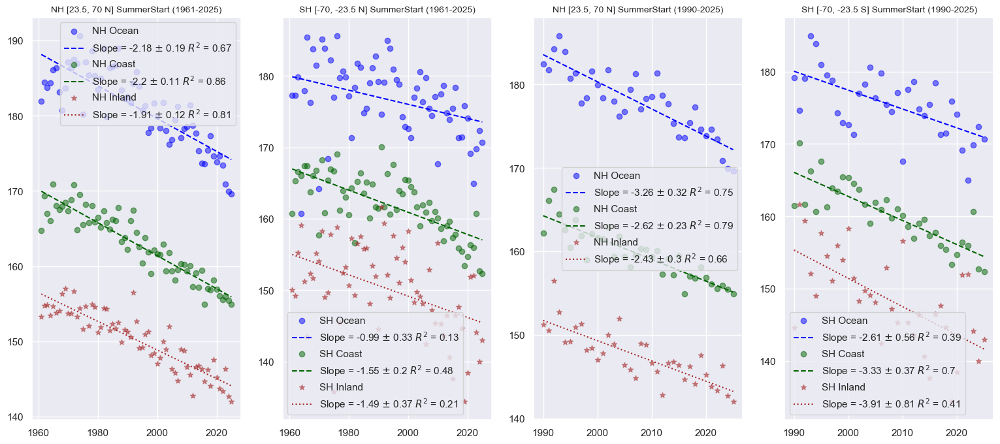

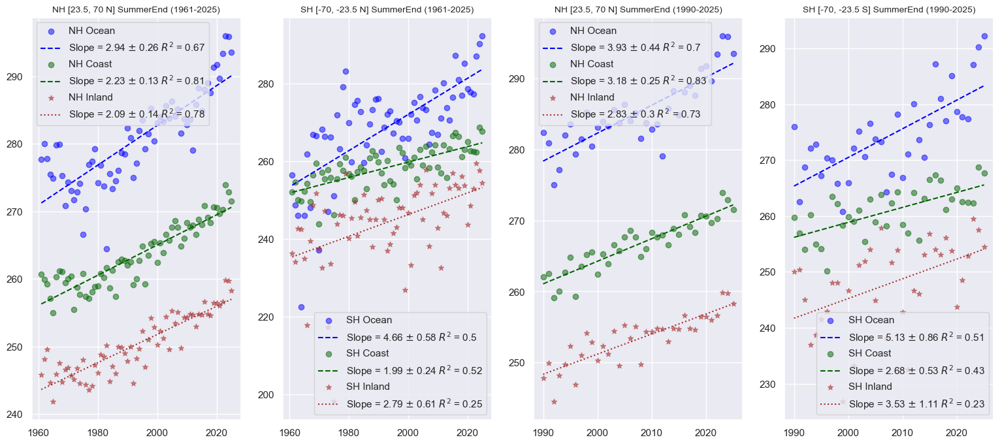

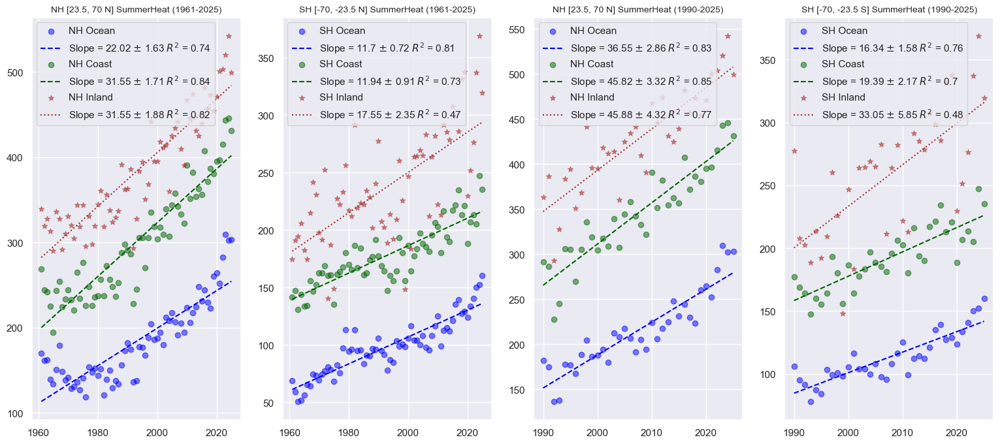

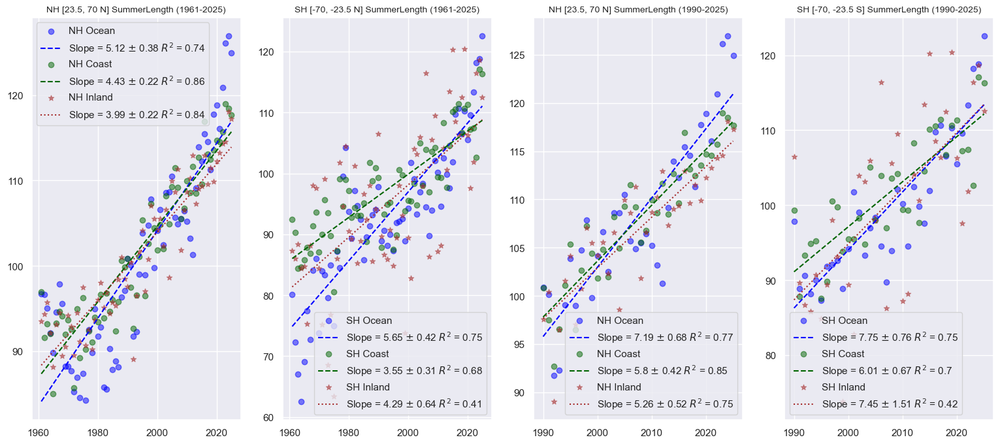

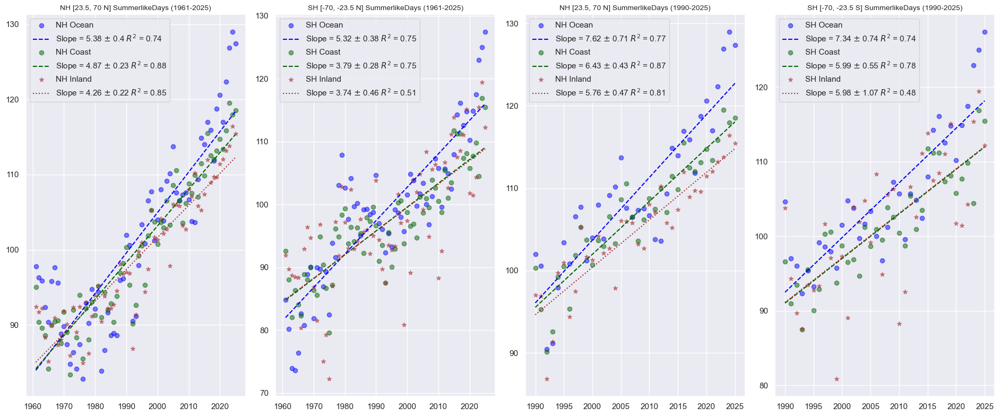

CPU times: user 1.09 s, sys: 94.7 ms, total: 1.19 s
Wall time: 1.19 s


In [79]:
%%time

# takes 30 sec



# loop through all plot variables
for i,v in enumerate(plot_vars):

    # create blank fig
    fig = plt.figure(figsize = (19,8))
    
    # Full Time Period NH
    ax1 = fig.add_subplot(1,4,1)

    # linear fits for slope
    x_land = nh_land_full.time.dt.year.values
    y_land = nh_land_full[v].values
    coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
    poly_land = np.poly1d(coefs_land)
    slope_land = np.round(coefs_land[0]*10,2)
    slope_land_sd = np.round(np.sqrt(V[0][0])*10,2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_land)
    ss_total = np.sum((y_land - ymean)**2)
    ss_res = np.sum((y_land - poly_land(x_land))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_land = np.round(1 - (ss_res / ss_total),2)

    # linear fits for slope
    x_coast = nh_coast_full.time.dt.year.values
    y_coast = nh_coast_full[v].values
    coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
    poly_coast = np.poly1d(coefs_coast)
    slope_coast = np.round(coefs_coast[0]*10,2)
    slope_coast_sd = np.round(np.sqrt(V[0][0])*10,2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_coast)
    ss_total = np.sum((y_coast - ymean)**2)
    ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_coast = np.round(1 - (ss_res / ss_total),2)

    # linear fits for slope
    x_ocean = nh_ocean_full.time.dt.year.values
    y_ocean = nh_ocean_full[v].values
    coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
    poly_ocean = np.poly1d(coefs_ocean)
    slope_ocean = np.round(coefs_ocean[0]*10,2)
    slope_ocean_sd = np.round(np.sqrt(V[0][0])*10,2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_ocean)
    ss_total = np.sum((y_ocean - ymean)**2)
    ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_ocean = np.round(1 - (ss_res / ss_total),2)
    
    # plot data
    # adjusted slopes to be per decade instead of per year
    ax1.scatter(x_ocean, y_ocean, label="NH Ocean", c="blue", alpha=0.5)
    ax1.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", color='blue', 
         label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
    ax1.scatter(x_coast, y_coast, label="NH Coast", c="darkgreen", alpha=0.5)
    ax1.plot(x_coast, poly_coast(x_coast), linestyle="dashed", color='darkgreen', 
         label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
    ax1.scatter(x_land, y_land, label="NH Inland", marker='*', facecolors='brown', edgecolors='brown', alpha=0.5)
    ax1.plot(x_land, poly_land(x_land), linestyle="dotted", color='brown',
         label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
    ax1.set_title("NH [23.5, 70 N] " + v + " (1961-2025)", fontsize = 10)
    ax1.legend(loc='best')

    # Full time period SH
    ax2 = fig.add_subplot(1,4,2)

    # linear fits for slope
    x_land = sh_land_full.time.dt.year.values
    y_land = sh_land_full[v].values
    coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
    poly_land = np.poly1d(coefs_land)
    slope_land = np.round(coefs_land[0]*10,2)
    slope_land_sd = np.round(np.sqrt(V[0][0])*10,2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_land)
    ss_total = np.sum((y_land - ymean)**2)
    ss_res = np.sum((y_land - poly_land(x_land))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_land = np.round(1 - (ss_res / ss_total),2)

    # linear fits for slope
    x_coast = sh_coast_full.time.dt.year.values
    y_coast = sh_coast_full[v].values
    coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
    poly_coast = np.poly1d(coefs_coast)
    slope_coast = np.round(coefs_coast[0]*10,2)
    slope_coast_sd = np.round(np.sqrt(V[0][0])*10,2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_coast)
    ss_total = np.sum((y_coast - ymean)**2)
    ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_coast = np.round(1 - (ss_res / ss_total),2)

    # linear fits for slope
    x_ocean = sh_ocean_full.time.dt.year.values
    y_ocean = sh_ocean_full[v].values
    coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
    poly_ocean = np.poly1d(coefs_ocean)
    slope_ocean = np.round(coefs_ocean[0]*10,2)
    slope_ocean_sd = np.round(np.sqrt(V[0][0])*10,2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_ocean)
    ss_total = np.sum((y_ocean - ymean)**2)
    ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_ocean = np.round(1 - (ss_res / ss_total),2)
    
    # plot data
    ax2.scatter(x_ocean, y_ocean, label="SH Ocean", c="blue", alpha=0.5)
    ax2.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", color='blue', 
         label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
    ax2.scatter(x_coast, y_coast, label="SH Coast", c="darkgreen", alpha=0.5)
    ax2.plot(x_coast, poly_coast(x_coast), linestyle="dashed", color='darkgreen', 
         label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
    ax2.scatter(x_land, y_land, label="SH Inland", marker='*', facecolors='brown', edgecolors='brown', alpha=0.5)
    ax2.plot(x_land, poly_land(x_land), linestyle="dotted", color='brown',
         label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
    ax2.set_title("SH [-70, -23.5 N] " + v + " (1961-2025)", fontsize = 10)
    ax2.legend(loc='best')
    

    # Analysis time period NH
    ax3 = fig.add_subplot(1,4,3)

    # linear fits for slope
    x_land = nh_land_an.time.dt.year.values
    y_land = nh_land_an[v].values
    coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
    poly_land = np.poly1d(coefs_land)
    slope_land = np.round(coefs_land[0]*10,2)
    slope_land_sd = np.round(np.sqrt(V[0][0])*10,2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_land)
    ss_total = np.sum((y_land - ymean)**2)
    ss_res = np.sum((y_land - poly_land(x_land))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_land = np.round(1 - (ss_res / ss_total),2)

    # linear fits for slope
    x_coast = nh_coast_an.time.dt.year.values
    y_coast = nh_coast_an[v].values
    coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
    poly_coast = np.poly1d(coefs_coast)
    slope_coast = np.round(coefs_coast[0]*10,2)
    slope_coast_sd = np.round(np.sqrt(V[0][0])*10,2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_coast)
    ss_total = np.sum((y_coast - ymean)**2)
    ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_coast = np.round(1 - (ss_res / ss_total),2)

    # linear fits for slope
    x_ocean = nh_ocean_an.time.dt.year.values
    y_ocean = nh_ocean_an[v].values
    coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
    poly_ocean = np.poly1d(coefs_ocean)
    slope_ocean = np.round(coefs_ocean[0]*10,2)
    slope_ocean_sd = np.round(np.sqrt(V[0][0])*10,2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_ocean)
    ss_total = np.sum((y_ocean - ymean)**2)
    ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_ocean = np.round(1 - (ss_res / ss_total),2)
    
    # plot data
    ax3.scatter(x_ocean, y_ocean, label="NH Ocean", c="blue", alpha=0.5)
    ax3.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", color='blue', 
         label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
    ax3.scatter(x_coast, y_coast, label="NH Coast", c="darkgreen", alpha=0.5)
    ax3.plot(x_coast, poly_coast(x_coast), linestyle="dashed", color='darkgreen', 
         label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
    ax3.scatter(x_land, y_land, label="NH Inland", marker='*', facecolors='brown', edgecolors='brown', alpha=0.5)
    ax3.plot(x_land, poly_land(x_land), linestyle="dotted", color='brown',
         label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
    ax3.set_title("NH [23.5, 70 N] " + v + " (1990-2025)", fontsize = 10)
    ax3.legend(loc='best')


    # Analysis time period SH
    ax4 = fig.add_subplot(1,4,4)

    # linear fits for slope
    x_land = sh_land_an.time.dt.year.values
    y_land = sh_land_an[v].values
    coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
    poly_land = np.poly1d(coefs_land)
    slope_land = np.round(coefs_land[0]*10,2)
    slope_land_sd = np.round(np.sqrt(V[0][0])*10,2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_land)
    ss_total = np.sum((y_land - ymean)**2)
    ss_res = np.sum((y_land - poly_land(x_land))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_land = np.round(1 - (ss_res / ss_total),2)

    # linear fits for slope
    x_coast = sh_coast_an.time.dt.year.values
    y_coast = sh_coast_an[v].values
    coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
    poly_coast = np.poly1d(coefs_coast)
    slope_coast = np.round(coefs_coast[0]*10,2)
    slope_coast_sd = np.round(np.sqrt(V[0][0])*10,2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_coast)
    ss_total = np.sum((y_coast - ymean)**2)
    ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_coast = np.round(1 - (ss_res / ss_total),2)

    # linear fits for slope
    x_ocean = sh_ocean_an.time.dt.year.values
    y_ocean = sh_ocean_an[v].values
    coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
    poly_ocean = np.poly1d(coefs_ocean)
    slope_ocean = np.round(coefs_ocean[0]*10,2)
    slope_ocean_sd = np.round(np.sqrt(V[0][0])*10,2)  
    # add in R^2 and RMSE
    ymean = np.mean(y_ocean)
    ss_total = np.sum((y_ocean - ymean)**2)
    ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_ocean = np.round(1 - (ss_res / ss_total),2)
    
    # plot data
    ax4.scatter(x_ocean, y_ocean, label="SH Ocean", c="blue", alpha=0.5)
    ax4.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", color='blue', 
         label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
    ax4.scatter(x_coast, y_coast, label="SH Coast", c="darkgreen", alpha=0.5)
    ax4.plot(x_coast, poly_coast(x_coast), linestyle="dashed", color='darkgreen', 
         label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
    ax4.scatter(x_land, y_land, label="SH Inland", marker='*', facecolors='brown', edgecolors='brown', alpha=0.5)
    ax4.plot(x_land, poly_land(x_land), linestyle="dotted", color='brown',
         label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
    ax4.set_title("SH [-70, -23.5 S] " + v + " (1990-2025)", fontsize = 10)
    ax4.legend(loc='best')


plt.tight_layout()
plt.show()



# Acceleration Checks

### LOWESS Smoothing of Length to check for acceleration following Rahmsdorf & Foster (2025) https://doi.org/10.21203/rs.3.rs-6079807/v1

#### Analysis Land

Text(0.5, 1.0, 'Residual between data and LOWESS')

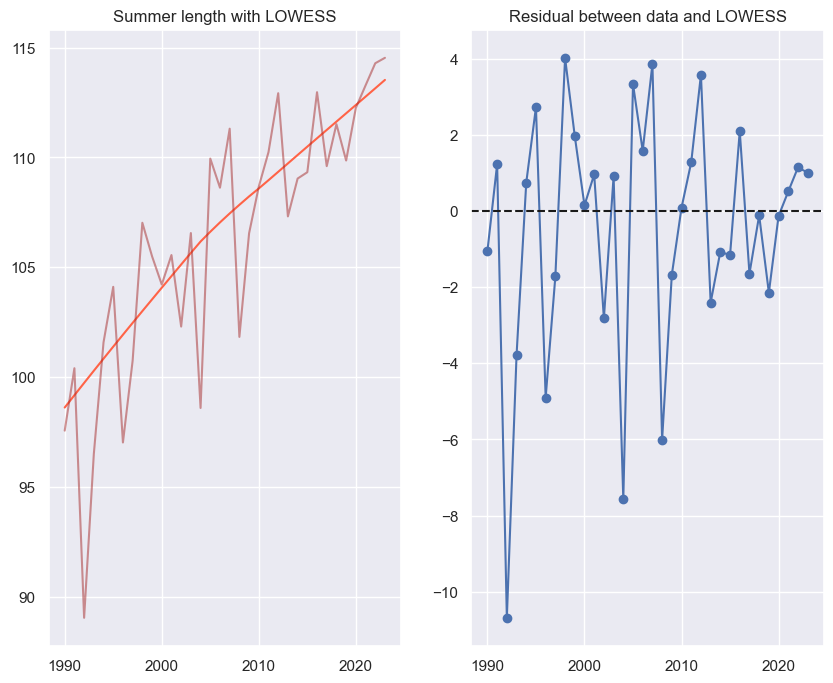

In [38]:
# help from https://james-brennan.github.io/posts/lowess_conf/


# define x & y using NH Ocean from 1990-2023 as example
x = nh_land_an.time.dt.year.values
y = nh_land_an.SummerLength.values

# LOWESS SMOOTHING

# parameters
iterations = 10
fraction = 30. / len(x)

sm_x, sm_y = sm_lowess(y, x,  frac=fraction, 
                           it=iterations, return_sorted = True).T
plt.figure(figsize=(10,8))
plt.subplot(1,2,1)
plt.plot(sm_x, sm_y, color='tomato')
plt.plot(x, y, c='brown', alpha=0.5)
plt.title("Summer length with LOWESS")

plt.subplot(1,2,2)
plt.plot(sm_x, y - sm_y, 'b')
plt.scatter(sm_x, y-sm_y)
plt.axhline(color='k', linestyle="--")
plt.title("Residual between data and LOWESS")

#### Analysis Ocean

Text(0.5, 1.0, 'Residual between data and LOWESS')

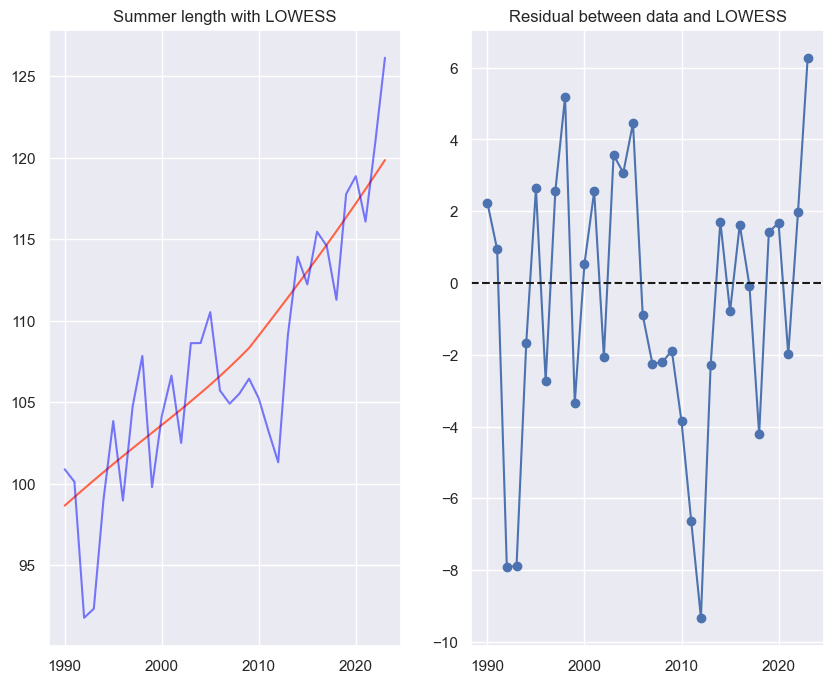

In [39]:
# help from https://james-brennan.github.io/posts/lowess_conf/


# define x & y using NH Ocean from 1990-2023 as example
x = nh_ocean_an.time.dt.year.values
y = nh_ocean_an.SummerLength.values

# LOWESS SMOOTHING

sm_x, sm_y = sm_lowess(y, x,  frac=fraction, 
                           it=iterations, return_sorted = True).T
plt.figure(figsize=(10,8))
plt.subplot(1,2,1)
plt.plot(sm_x, sm_y, color='tomato')
plt.plot(x, y, c='blue', alpha=0.5)
plt.title("Summer length with LOWESS")

plt.subplot(1,2,2)
plt.plot(sm_x, y - sm_y, 'b')
plt.scatter(sm_x, y-sm_y)
plt.axhline(color='k', linestyle="--")
plt.title("Residual between data and LOWESS")

In [19]:
# xt = np.append(x[:-2],2022)
# xt

#### Analysis Coastal

Text(0.5, 1.0, 'Residual between data and LOWESS')

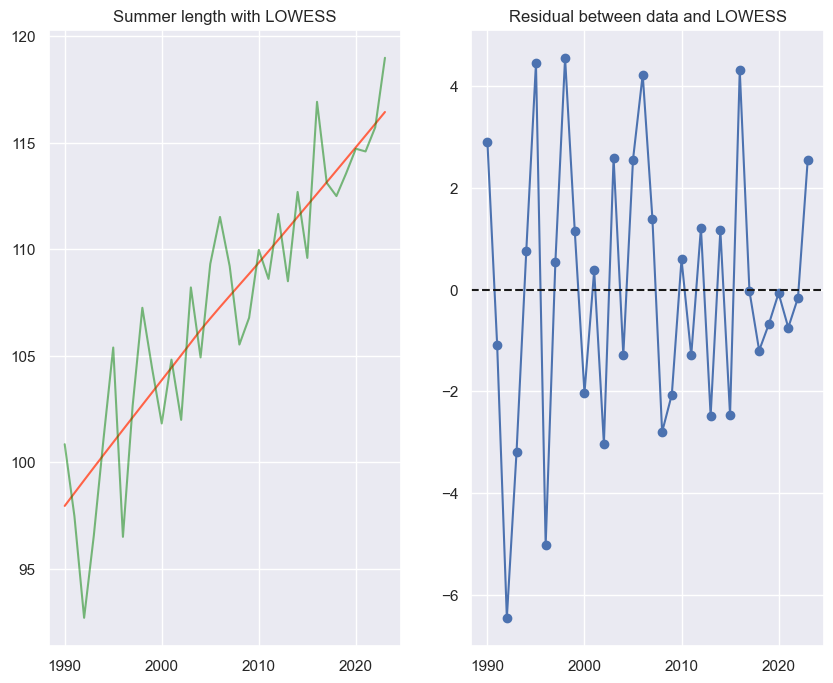

In [40]:
# help from https://james-brennan.github.io/posts/lowess_conf/


# define x & y using NH Ocean from 1990-2023 as example
x = nh_coast_an.time.dt.year.values
y = nh_coast_an.SummerLength.values

# LOWESS SMOOTHING

sm_x, sm_y = sm_lowess(y, x,  frac=fraction, 
                           it=iterations, return_sorted = True).T
plt.figure(figsize=(10,8))
plt.subplot(1,2,1)
plt.plot(sm_x, sm_y, color='tomato')
plt.plot(x, y, c='green', alpha=0.5)
plt.title("Summer length with LOWESS")

plt.subplot(1,2,2)
plt.plot(sm_x, y - sm_y, 'b')
plt.scatter(sm_x, y-sm_y)
plt.axhline(color='k', linestyle="--")
plt.title("Residual between data and LOWESS")

#### Full Land

Text(0.5, 1.0, 'Residual between data and LOWESS')

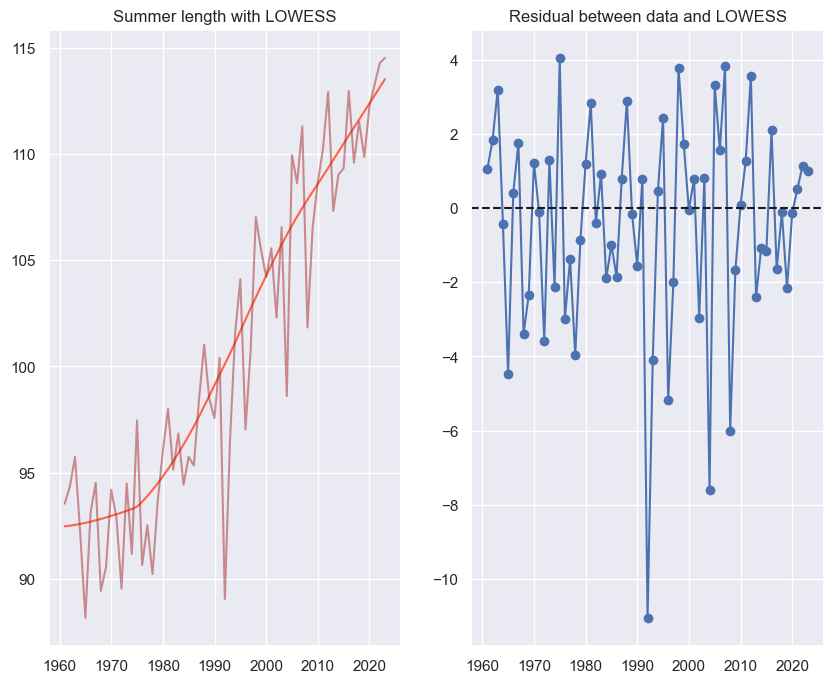

In [41]:
# help from https://james-brennan.github.io/posts/lowess_conf/


# define x & y using NH Ocean from 1990-2023 as example
x = nh_land_full.time.dt.year.values
y = nh_land_full.SummerLength.values

# LOWESS SMOOTHING

# parameters
iterations = 10
fraction = 30. / len(x)

sm_x, sm_y = sm_lowess(y, x,  frac=fraction, 
                           it=iterations, return_sorted = True).T
plt.figure(figsize=(10,8))
plt.subplot(1,2,1)
plt.plot(sm_x, sm_y, color='tomato')
plt.plot(x, y, c='brown', alpha=0.5)
plt.title("Summer length with LOWESS")

plt.subplot(1,2,2)
plt.plot(sm_x, y - sm_y, 'b')
plt.scatter(sm_x, y-sm_y)
plt.axhline(color='k', linestyle="--")
plt.title("Residual between data and LOWESS")

#### Full Ocean

Text(0.5, 1.0, 'Residual between data and LOWESS')

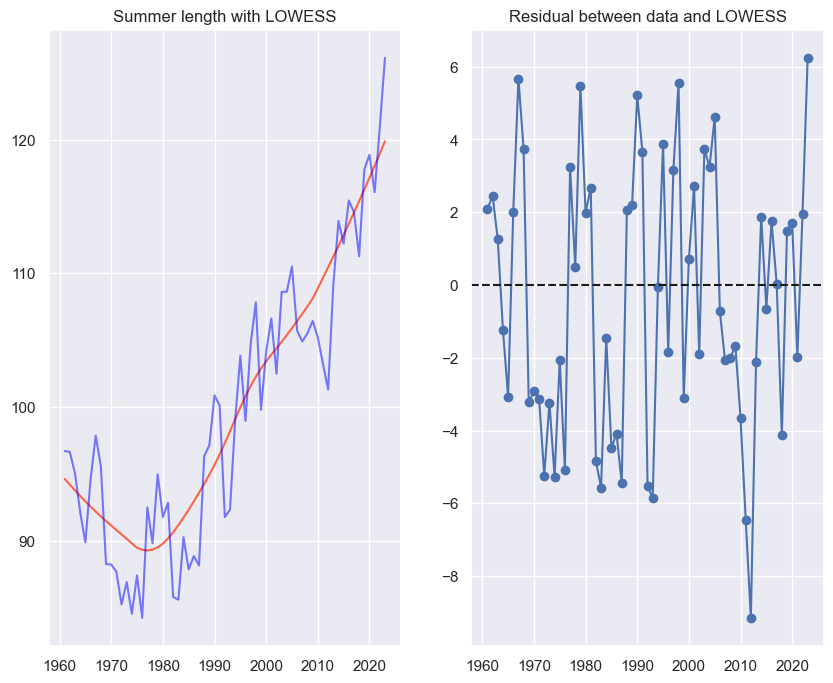

In [42]:
# help from https://james-brennan.github.io/posts/lowess_conf/


# define x & y using NH Ocean from 1990-2023 as example
x = nh_ocean_full.time.dt.year.values
y = nh_ocean_full.SummerLength.values

# LOWESS SMOOTHING

sm_x, sm_y = sm_lowess(y, x,  frac=fraction, 
                           it=iterations, return_sorted = True).T
plt.figure(figsize=(10,8))
plt.subplot(1,2,1)
plt.plot(sm_x, sm_y, color='tomato')
plt.plot(x, y, c='blue', alpha=0.5)
plt.title("Summer length with LOWESS")

plt.subplot(1,2,2)
plt.plot(sm_x, y - sm_y, 'b')
plt.scatter(sm_x, y-sm_y)
plt.axhline(color='k', linestyle="--")
plt.title("Residual between data and LOWESS")

In [23]:
# xt = np.append(x[:-2],2022)
# xt

#### Full Coastal (weak accel)

Text(0.5, 1.0, 'Residual between data and LOWESS')

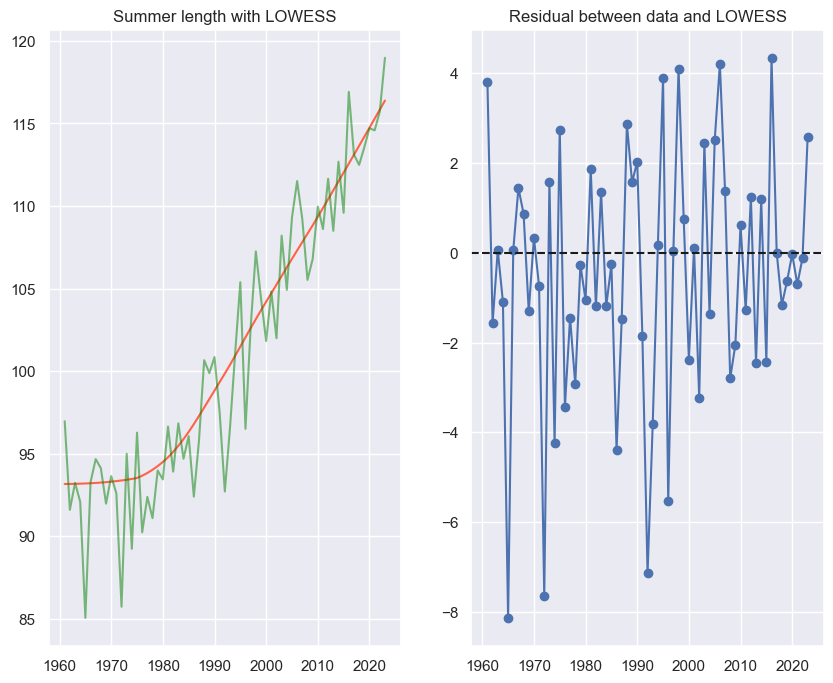

In [43]:
# help from https://james-brennan.github.io/posts/lowess_conf/


# define x & y using NH Ocean from 1990-2023 as example
x = nh_coast_full.time.dt.year.values
y = nh_coast_full.SummerLength.values

# LOWESS SMOOTHING

sm_x, sm_y = sm_lowess(y, x,  frac=fraction, 
                           it=iterations, return_sorted = True).T
plt.figure(figsize=(10,8))
plt.subplot(1,2,1)
plt.plot(sm_x, sm_y, color='tomato')
plt.plot(x, y, c='green', alpha=0.5)
plt.title("Summer length with LOWESS")

plt.subplot(1,2,2)
plt.plot(sm_x, y - sm_y, 'b')
plt.scatter(sm_x, y-sm_y)
plt.axhline(color='k', linestyle="--")
plt.title("Residual between data and LOWESS")

### LOWESS Smoothing of Accumulated Heat to check for acceleration following Rahmsdorf & Foster (2025) https://doi.org/10.21203/rs.3.rs-6079807/v1

#### Analysis Land

Text(0.5, 1.0, 'Residual between data and LOWESS')

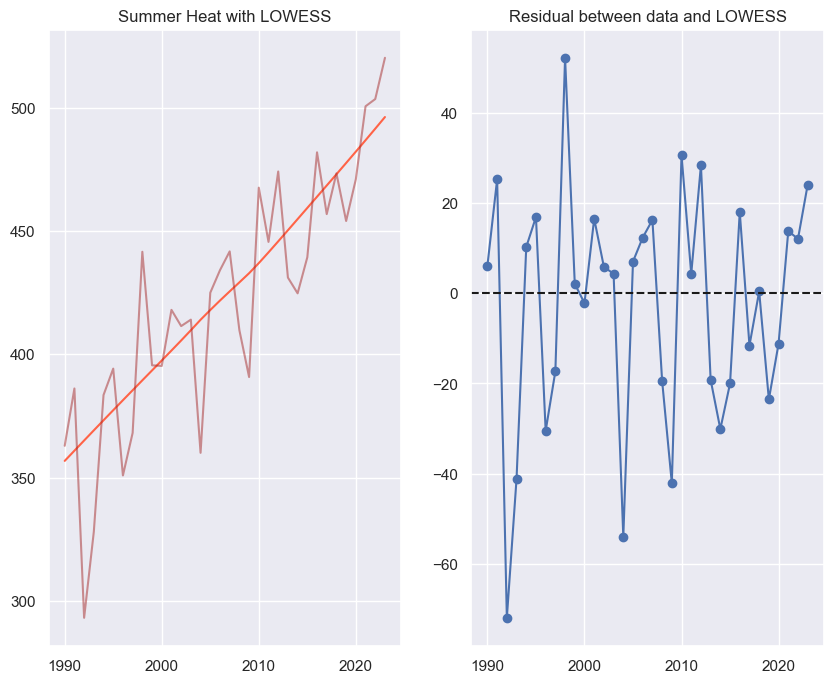

In [44]:
# help from https://james-brennan.github.io/posts/lowess_conf/


# define x & y using NH Ocean from 1990-2023 as example
x = nh_land_an.time.dt.year.values
y = nh_land_an.SummerHeat.values

# LOWESS SMOOTHING

# parameters
iterations = 10
fraction = 30. / len(x)

sm_x, sm_y = sm_lowess(y, x,  frac=fraction, 
                           it=iterations, return_sorted = True).T
plt.figure(figsize=(10,8))
plt.subplot(1,2,1)
plt.plot(sm_x, sm_y, color='tomato')
plt.plot(x, y, c='brown', alpha=0.5)
plt.title("Summer Heat with LOWESS")

plt.subplot(1,2,2)
plt.plot(sm_x, y - sm_y, 'b')
plt.scatter(sm_x, y-sm_y)
plt.axhline(color='k', linestyle="--")
plt.title("Residual between data and LOWESS")

#### Analysis Ocean

Text(0.5, 1.0, 'Residual between data and LOWESS')

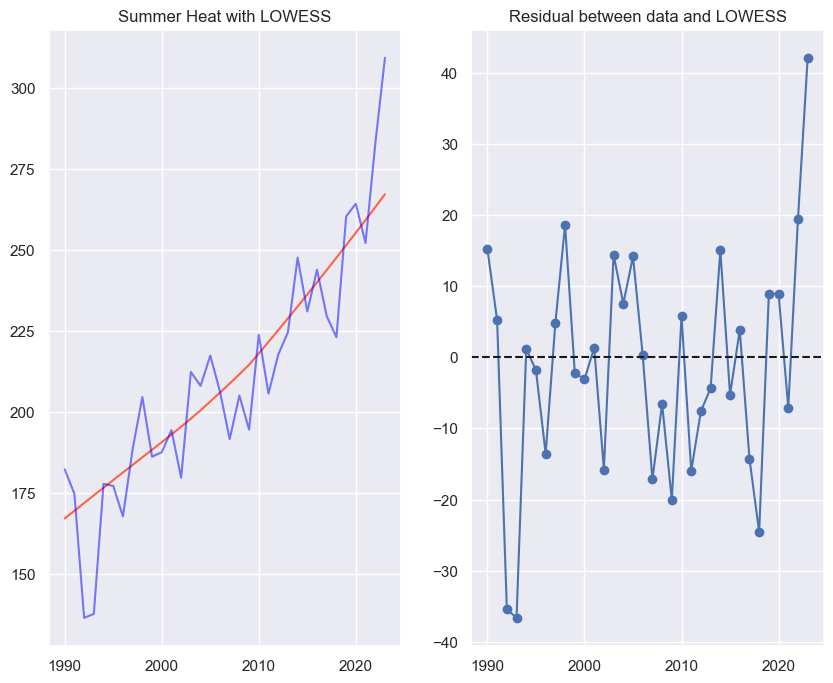

In [45]:
# help from https://james-brennan.github.io/posts/lowess_conf/


# define x & y using NH Ocean from 1990-2023 as example
x = nh_ocean_an.time.dt.year.values
y = nh_ocean_an.SummerHeat.values

# LOWESS SMOOTHING

sm_x, sm_y = sm_lowess(y, x,  frac=fraction, 
                           it=iterations, return_sorted = True).T
plt.figure(figsize=(10,8))
plt.subplot(1,2,1)
plt.plot(sm_x, sm_y, color='tomato')
plt.plot(x, y, c='blue', alpha=0.5)
plt.title("Summer Heat with LOWESS")

plt.subplot(1,2,2)
plt.plot(sm_x, y - sm_y, 'b')
plt.scatter(sm_x, y-sm_y)
plt.axhline(color='k', linestyle="--")
plt.title("Residual between data and LOWESS")

In [27]:
# xt = np.append(x[:-2],2022)
# xt

#### Analysis Coastal

Text(0.5, 1.0, 'Residual between data and LOWESS')

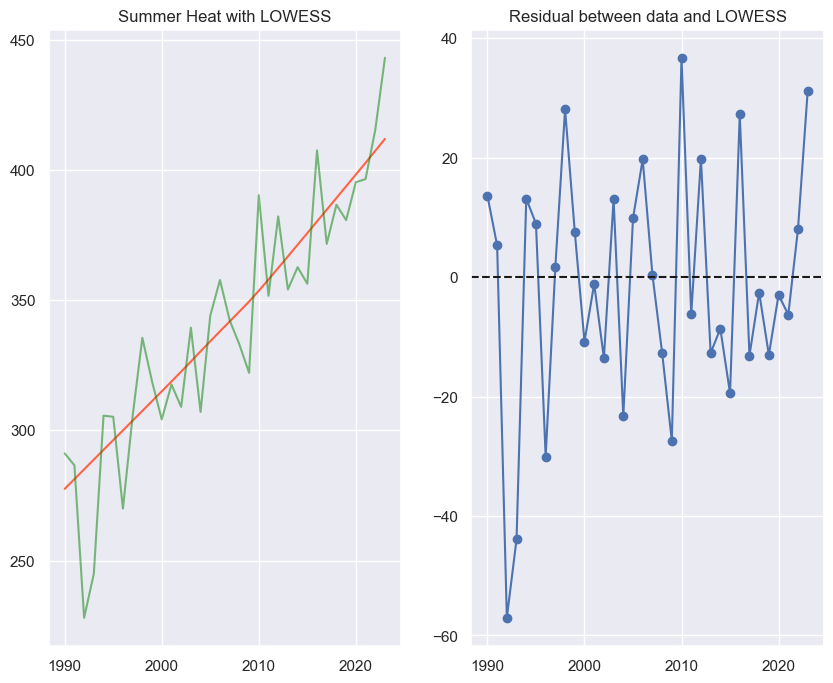

In [46]:
# help from https://james-brennan.github.io/posts/lowess_conf/


# define x & y using NH Ocean from 1990-2023 as example
x = nh_coast_an.time.dt.year.values
y = nh_coast_an.SummerHeat.values

# LOWESS SMOOTHING

sm_x, sm_y = sm_lowess(y, x,  frac=fraction, 
                           it=iterations, return_sorted = True).T
plt.figure(figsize=(10,8))
plt.subplot(1,2,1)
plt.plot(sm_x, sm_y, color='tomato')
plt.plot(x, y, c='green', alpha=0.5)
plt.title("Summer Heat with LOWESS")

plt.subplot(1,2,2)
plt.plot(sm_x, y - sm_y, 'b')
plt.scatter(sm_x, y-sm_y)
plt.axhline(color='k', linestyle="--")
plt.title("Residual between data and LOWESS")

#### Full Land

Text(0.5, 1.0, 'Residual between data and LOWESS')

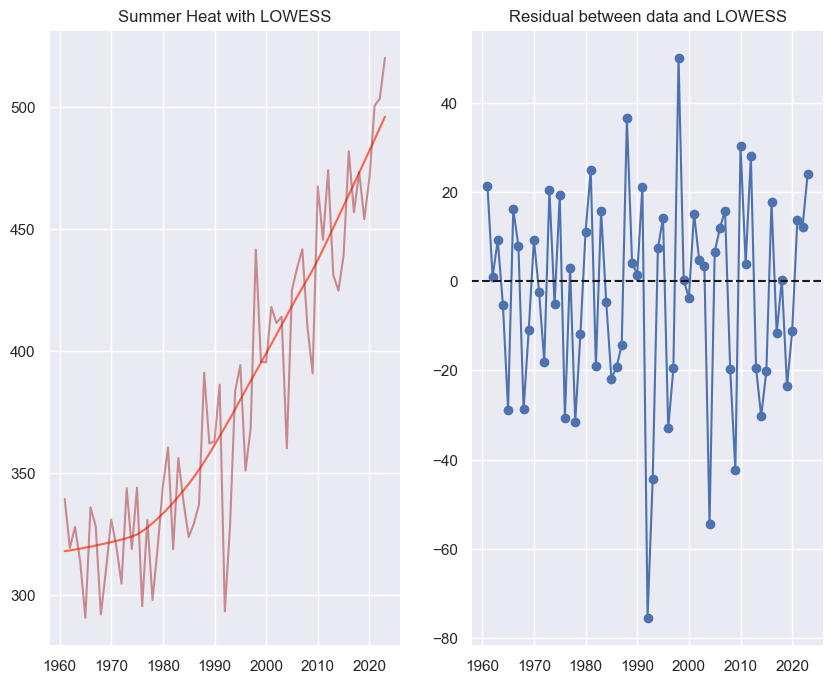

In [47]:
# help from https://james-brennan.github.io/posts/lowess_conf/


# define x & y using NH Ocean from 1990-2023 as example
x = nh_land_full.time.dt.year.values
y = nh_land_full.SummerHeat.values

# LOWESS SMOOTHING

# parameters
iterations = 10
fraction = 30. / len(x)

sm_x, sm_y = sm_lowess(y, x,  frac=fraction, 
                           it=iterations, return_sorted = True).T
plt.figure(figsize=(10,8))
plt.subplot(1,2,1)
plt.plot(sm_x, sm_y, color='tomato')
plt.plot(x, y, c='brown', alpha=0.5)
plt.title("Summer Heat with LOWESS")

plt.subplot(1,2,2)
plt.plot(sm_x, y - sm_y, 'b')
plt.scatter(sm_x, y-sm_y)
plt.axhline(color='k', linestyle="--")
plt.title("Residual between data and LOWESS")

#### Full Ocean

Text(0.5, 1.0, 'Residual between data and LOWESS')

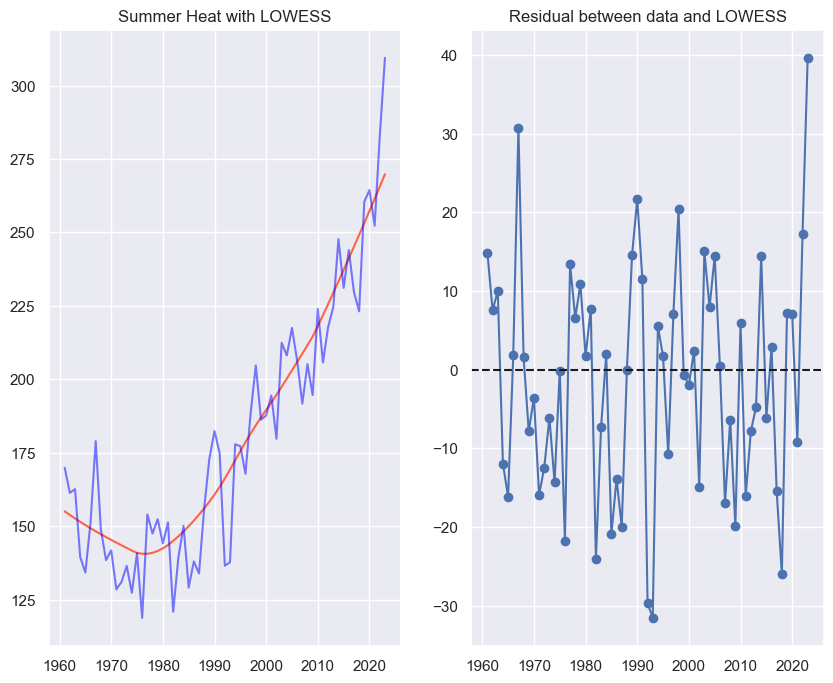

In [48]:
# help from https://james-brennan.github.io/posts/lowess_conf/


# define x & y using NH Ocean from 1990-2023 as example
x = nh_ocean_full.time.dt.year.values
y = nh_ocean_full.SummerHeat.values

# LOWESS SMOOTHING

sm_x, sm_y = sm_lowess(y, x,  frac=fraction, 
                           it=iterations, return_sorted = True).T
plt.figure(figsize=(10,8))
plt.subplot(1,2,1)
plt.plot(sm_x, sm_y, color='tomato')
plt.plot(x, y, c='blue', alpha=0.5)
plt.title("Summer Heat with LOWESS")

plt.subplot(1,2,2)
plt.plot(sm_x, y - sm_y, 'b')
plt.scatter(sm_x, y-sm_y)
plt.axhline(color='k', linestyle="--")
plt.title("Residual between data and LOWESS")

In [31]:
# xt = np.append(x[:-2],2022)
# xt

#### Full Coastal

Text(0.5, 1.0, 'Residual between data and LOWESS')

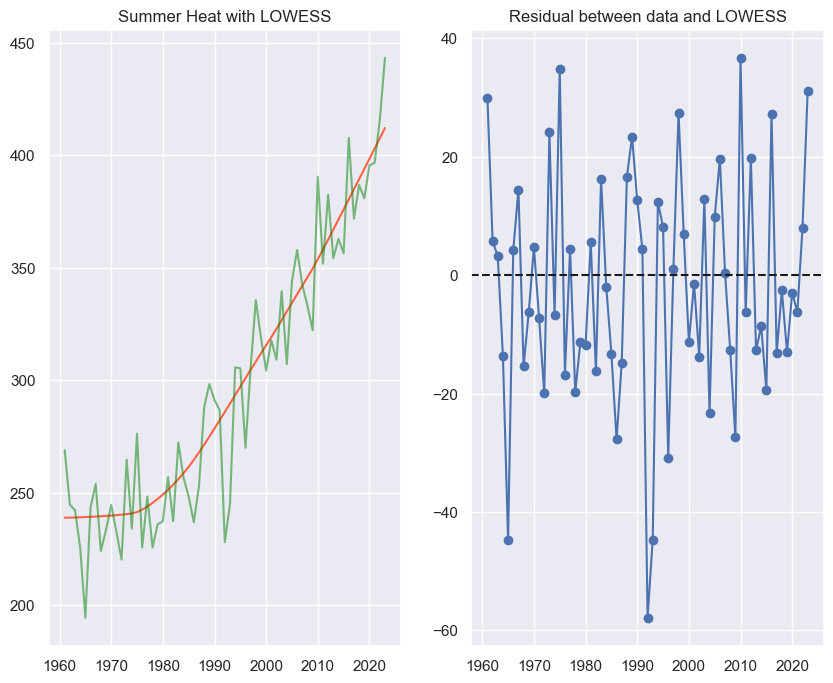

In [49]:
# help from https://james-brennan.github.io/posts/lowess_conf/


# define x & y using NH Ocean from 1990-2023 as example
x = nh_coast_full.time.dt.year.values
y = nh_coast_full.SummerHeat.values

# LOWESS SMOOTHING

sm_x, sm_y = sm_lowess(y, x,  frac=fraction, 
                           it=iterations, return_sorted = True).T
plt.figure(figsize=(10,8))
plt.subplot(1,2,1)
plt.plot(sm_x, sm_y, color='tomato')
plt.plot(x, y, c='green', alpha=0.5)
plt.title("Summer Heat with LOWESS")

plt.subplot(1,2,2)
plt.plot(sm_x, y - sm_y, 'b')
plt.scatter(sm_x, y-sm_y)
plt.axhline(color='k', linestyle="--")
plt.title("Residual between data and LOWESS")

## Instead try Piecewise Linear Fits - helpful example paper: https://journals.ametsoc.org/view/journals/wcas/17/2/WCAS-D-24-0057.1.xml

#### Package info and helpful pages: 
- https://pypi.org/project/pwlf/
- https://jekel.me/piecewise_linear_fit_py/how_it_works.html
- https://jekel.me/2017/Fit-a-piecewise-linear-function-to-data/


## ** NORTHERN ** Summer Length

### Full Land (no accel)

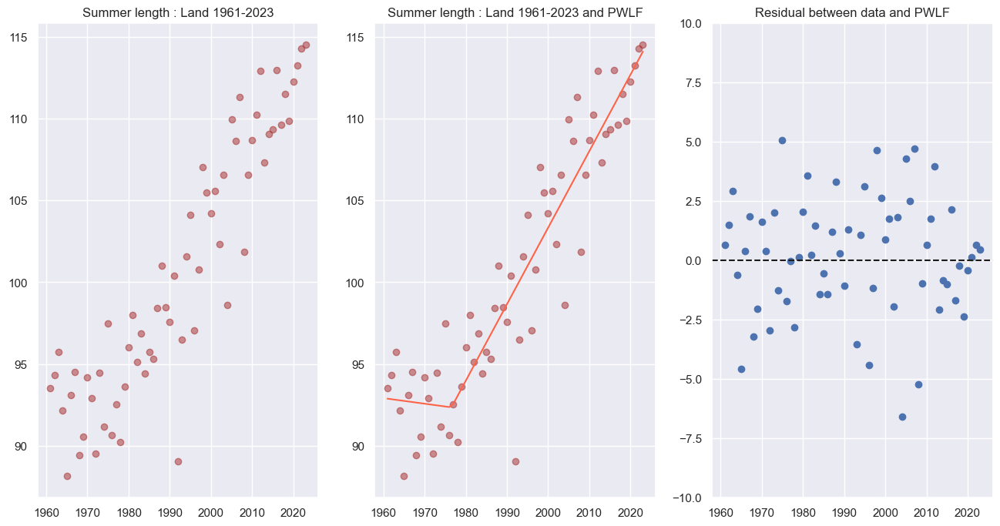

In [51]:
# help from https://jekel.me/piecewise_linear_fit_py/examples.html#find-the-best-number-of-line-segments

# define x & y 
x = nh_land_full.time.dt.year.values
y = nh_land_full.SummerLength.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for two line segments - it looks like either 2 or 3 to me
res = my_pwlf.fit(2)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='brown', alpha=0.5)
plt.title("Summer length : Land 1961-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='brown', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer length : Land 1961-2023 and PWLF")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-10,10)
plt.title("Residual between data and PWLF")


plt.show()

In [52]:
my_pwlf.calc_slopes()

array([-0.03417596,  0.46806468])

#### Two segments fits Land well and residuals are mostly centered around zero with only the 1992 (?) outlier

### Analysis Land (no accel - decel?)

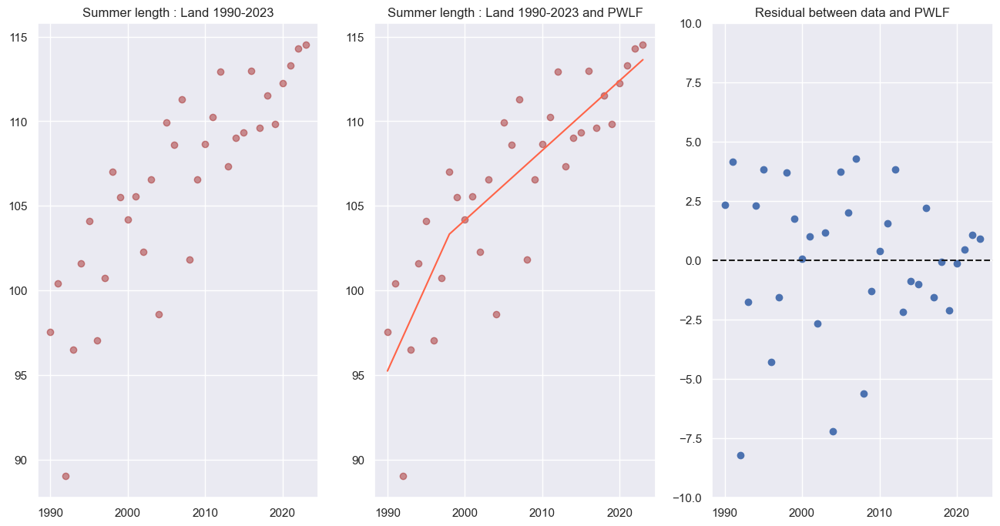

In [53]:
# help from https://jekel.me/piecewise_linear_fit_py/examples.html#find-the-best-number-of-line-segments

# define x & y 
x = nh_land_an.time.dt.year.values
y = nh_land_an.SummerLength.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for two line segments
res = my_pwlf.fit(2)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='brown', alpha=0.5)
plt.title("Summer length : Land 1990-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='brown', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer length : Land 1990-2023 and PWLF")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-10,10)
plt.title("Residual between data and PWLF")


plt.show()

In [54]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks, my_pwlf.r_squared()

(array([1.01053987, 0.41217401]),
 array([1990., 1998., 2023.]),
 np.float64(0.7309234006129117))

#### **** try just one line instead

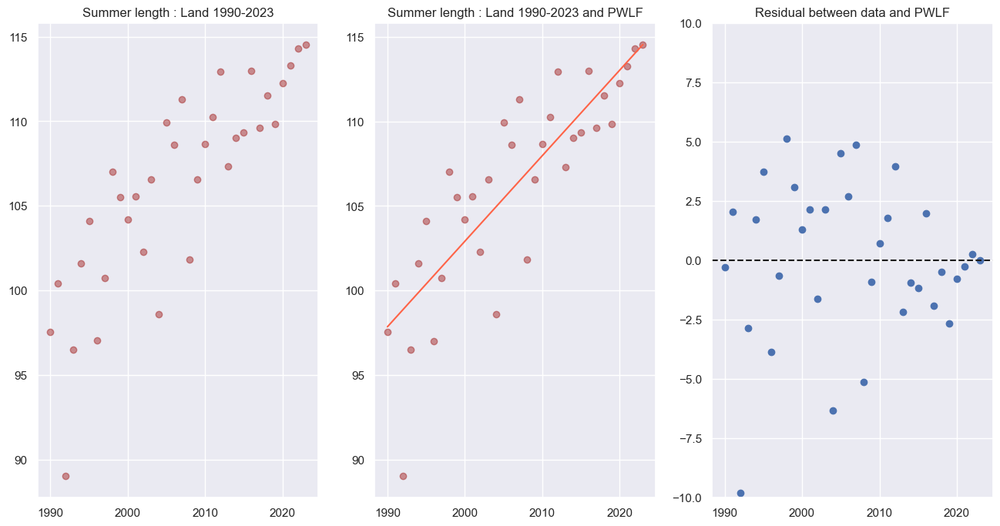

In [55]:
# help from https://jekel.me/piecewise_linear_fit_py/examples.html#find-the-best-number-of-line-segments

# define x & y 
x = nh_land_an.time.dt.year.values
y = nh_land_an.SummerLength.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for two line segments
res = my_pwlf.fit(1)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='brown', alpha=0.5)
plt.title("Summer length : Land 1990-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='brown', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer length : Land 1990-2023 and PWLF")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-10,10)
plt.title("Residual between data and PWLF")


plt.show()

In [56]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks, my_pwlf.r_squared()

(array([0.50542583]), array([1990, 2023]), np.float64(0.7048406725226829))

#### Two segments for Analysis period Land yields a slightly better fit and interestingly a lower slope for recent years

### Full Ocean (accel since 2018)

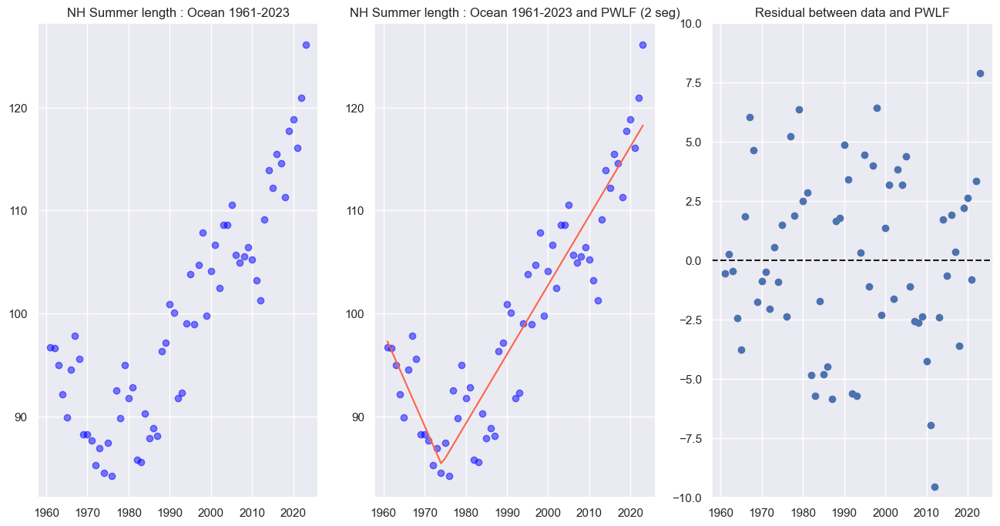

In [184]:
# help from https://james-brennan.github.io/posts/lowess_conf/


# define x & y using NH Ocean from 1990-2023 as example
x = nh_ocean_full.time.dt.year.values
y = nh_ocean_full.SummerLength.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for two line segments - it looks like either 2 or 3 to me
res = my_pwlf.fit(2)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='blue', alpha=0.5)
plt.title("NH Summer length : Ocean 1961-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='blue', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("NH Summer length : Ocean 1961-2023 and PWLF (2 seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-10,10)
plt.title("Residual between data and PWLF")


plt.show()

In [185]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks, my_pwlf.r_squared()

(array([-0.91003402,  0.67368329]),
 array([1961.       , 1974.1289333, 2023.       ]),
 np.float64(0.8727287306441638))

#### MSR and $R^{2}$

In [186]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(13.629648096547335), np.float64(0.8727287306441638))

#### Two segments for Ocean looks wrong for recent years - try 3

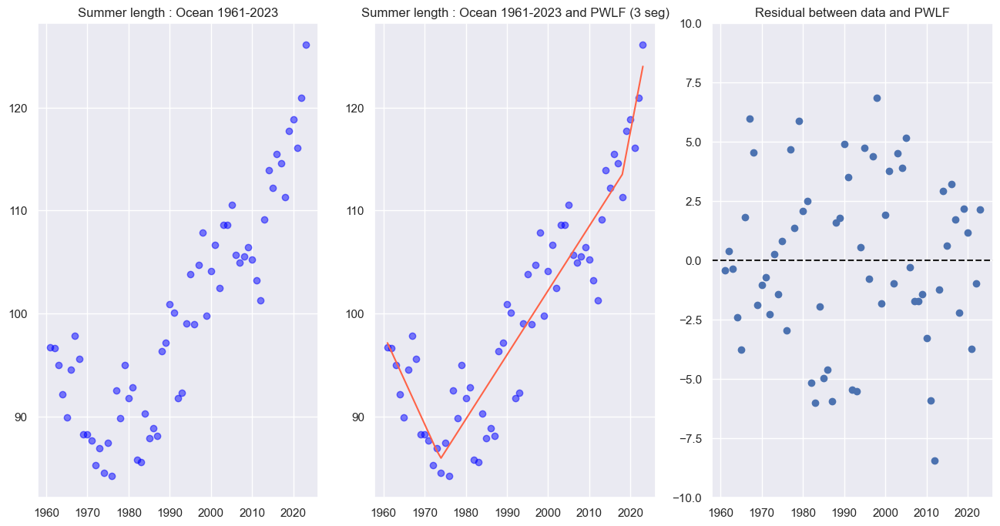

In [187]:



# define x & y using NH Ocean from 1990-2023 as example
x = nh_ocean_full.time.dt.year.values
y = nh_ocean_full.SummerLength.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for three line segments - it looks like either 2 or 3 to me
res = my_pwlf.fit(3)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='blue', alpha=0.5)
plt.title("Summer length : Ocean 1961-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='blue', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer length : Ocean 1961-2023 and PWLF (3 seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-10,10)
plt.title("Residual between data and PWLF")


plt.show()

In [188]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks, my_pwlf.r_squared()

(array([-0.8746643 ,  0.62623314,  2.09846926]),
 array([1961.        , 1973.87738715, 2018.        , 2023.        ]),
 np.float64(0.8853254543211032))

#### MSR and $R^{2}$

In [189]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(12.280648343852892), np.float64(0.8853254543211032))

#### Three segments for Ocean yields better residual plot and $R^2$ - recent years' (2018+) slope is 2.2 days per year for growth of summer length!

### Try 2015 changepoint ala Rahmstorf

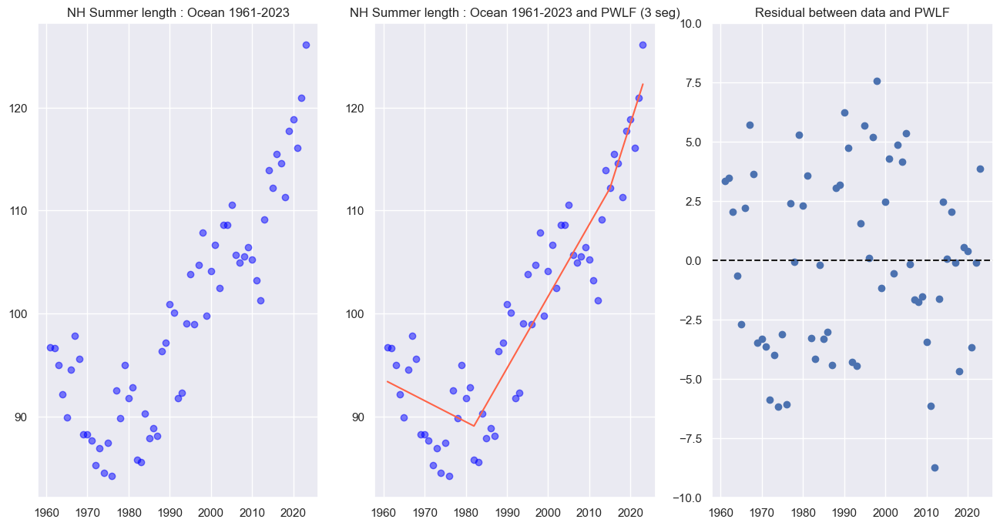

In [190]:


# define x & y using NH Ocean from 1990-2023 as example
x = nh_ocean_full.time.dt.year.values
y = nh_ocean_full.SummerLength.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# your desired line segment end locations
x0 = np.array([min(x), 1982, 2015, max(x)])

# fit the data for three line segments - it looks like either 2 or 3 to me
res = my_pwlf.fit_with_breaks(x0)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='blue', alpha=0.5)
plt.title("NH Summer length : Ocean 1961-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='blue', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("NH Summer length : Ocean 1961-2023 and PWLF (3 seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-10,10)
plt.title("Residual between data and PWLF")


plt.show()

In [191]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks, my_pwlf.r_squared()

(array([-0.20551406,  0.69984574,  1.26455451]),
 array([1961, 1982, 2015, 2023]),
 np.float64(0.8654574788389835))

#### MSR and $R^{2}$

In [192]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(14.408336042598243), np.float64(0.8654574788389835))

## 

### Analysis Ocean (accel since 2018 or since 2012 hiatus?)

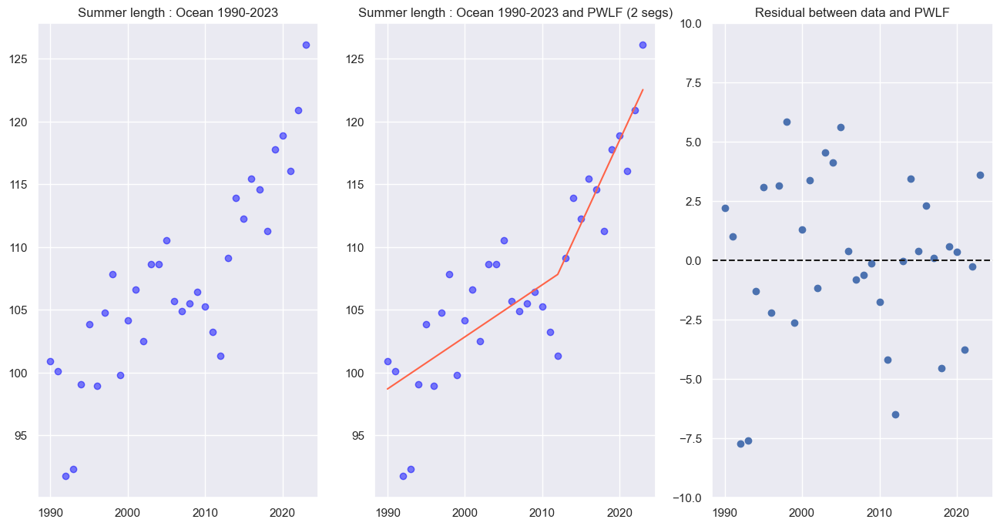

In [61]:
# help from https://jekel.me/piecewise_linear_fit_py/examples.html#find-the-best-number-of-line-segments

# define x & y 
x = nh_ocean_an.time.dt.year.values
y = nh_ocean_an.SummerLength.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for two line segments
res = my_pwlf.fit(2)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='blue', alpha=0.5)
plt.title("Summer length : Ocean 1990-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='blue', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer length : Ocean 1990-2023 and PWLF (2 segs)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-10,10)
plt.title("Residual between data and PWLF")


plt.show()

In [62]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks, my_pwlf.r_squared()

(array([0.41500713, 1.3378462 ]),
 array([1990., 2012., 2023.]),
 np.float64(0.7932638905699883))

#### **** try just one line instead

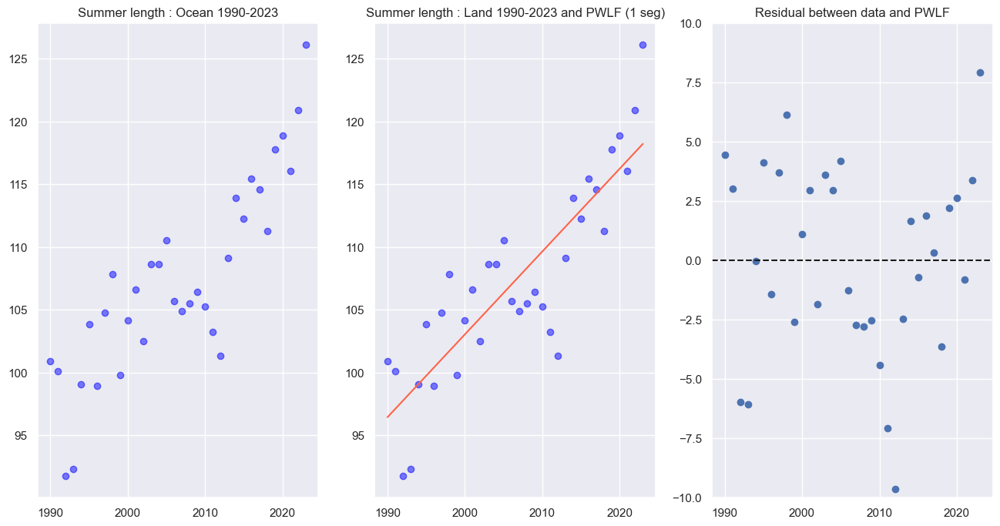

In [63]:
# help from https://jekel.me/piecewise_linear_fit_py/examples.html#find-the-best-number-of-line-segments

# define x & y 
x = nh_ocean_an.time.dt.year.values
y = nh_ocean_an.SummerLength.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for two line segments
res = my_pwlf.fit(1)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='blue', alpha=0.5)
plt.title("Summer length : Ocean 1990-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='blue', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer length : Land 1990-2023 and PWLF (1 seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-10,10)
plt.title("Residual between data and PWLF")


plt.show()

In [64]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks, my_pwlf.r_squared()

(array([0.66006356]), array([1990, 2023]), np.float64(0.729184569770035))

#### Two segments for Analysis period Ocean yields a better fit (residuals and $R^2$ and a much higher slope (1.3 $\frac{days}{year}$) for recent years - *indicates acceleration*

### Full Coastal (no accel)

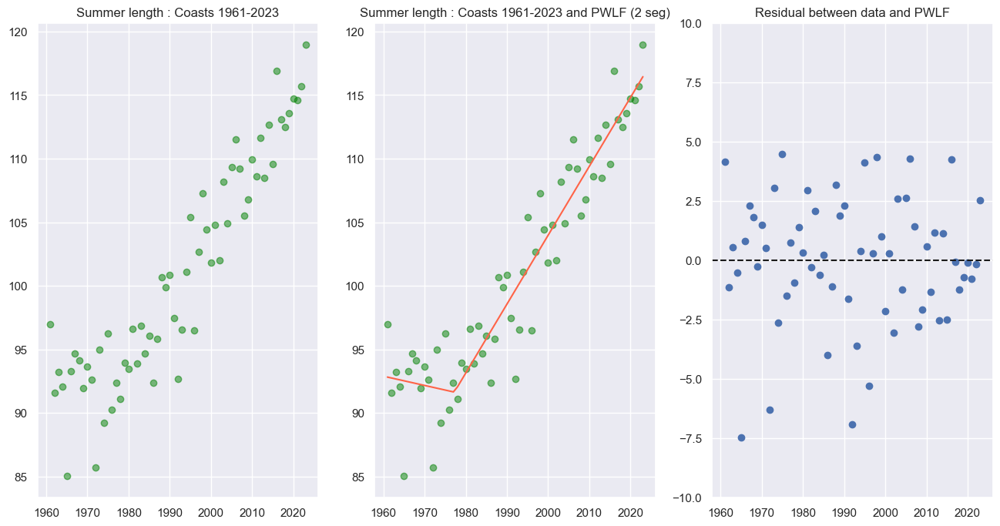

In [65]:
# help from https://james-brennan.github.io/posts/lowess_conf/


# define x & y using NH Ocean from 1990-2023 as example
x = nh_coast_full.time.dt.year.values
y = nh_coast_full.SummerLength.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for two line segments - it looks like 2 is best to me
res = my_pwlf.fit(2)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='green', alpha=0.5)
plt.title("Summer length : Coasts 1961-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='green', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer length : Coasts 1961-2023 and PWLF (2 seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-10,10)
plt.title("Residual between data and PWLF")


plt.show()

In [66]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks

(array([-0.07277863,  0.54209986]),
 array([1961.        , 1977.23607388, 2023.        ]))

#### Two segments fits Coastal areas well

### Analysis Coastal (no accel)

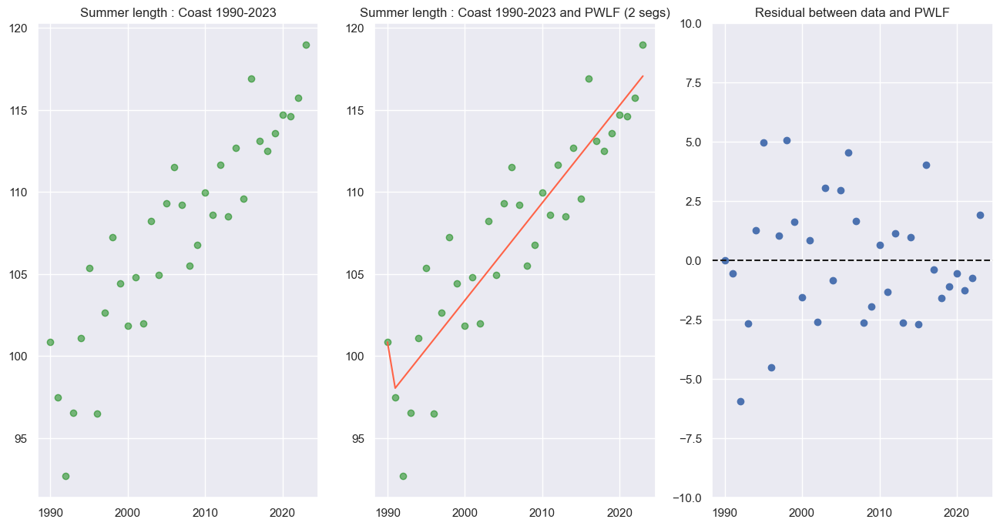

In [67]:
# help from https://jekel.me/piecewise_linear_fit_py/examples.html#find-the-best-number-of-line-segments

# define x & y 
x = nh_coast_an.time.dt.year.values
y = nh_coast_an.SummerLength.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for two line segments
res = my_pwlf.fit(2)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='green', alpha=0.5)
plt.title("Summer length : Coast 1990-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='green', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer length : Coast 1990-2023 and PWLF (2 segs)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-10,10)
plt.title("Residual between data and PWLF")


plt.show()

In [68]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks, my_pwlf.r_squared()

(array([-1.45380447e+04,  5.94086220e-01]),
 array([1990.        , 1990.00023368, 2023.        ]),
 np.float64(0.8295394499058089))

#### **** try just one line instead

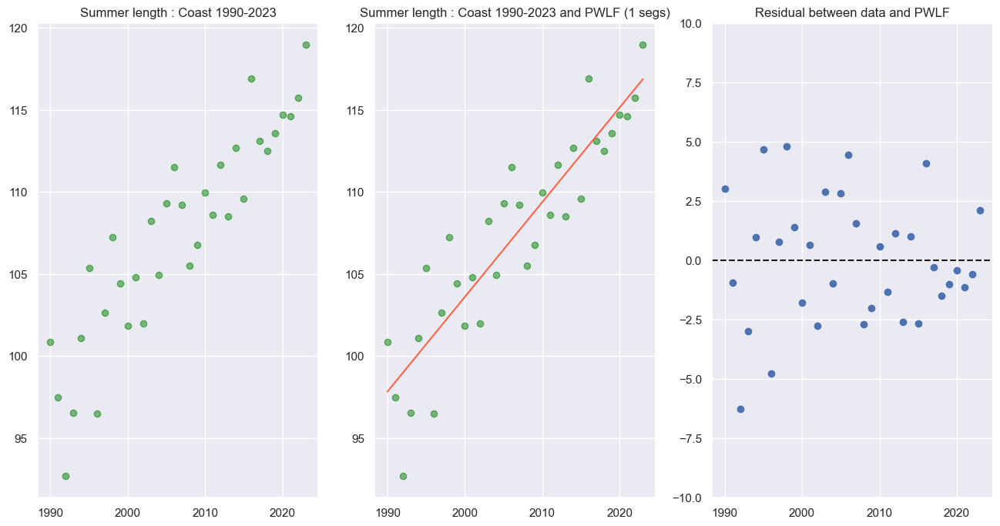

In [69]:
# help from https://jekel.me/piecewise_linear_fit_py/examples.html#find-the-best-number-of-line-segments

# define x & y 
x = nh_coast_an.time.dt.year.values
y = nh_coast_an.SummerLength.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for two line segments
res = my_pwlf.fit(1)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='green', alpha=0.5)
plt.title("Summer length : Coast 1990-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='green', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer length : Coast 1990-2023 and PWLF (1 segs)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-10,10)
plt.title("Residual between data and PWLF")


plt.show()

In [70]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks, my_pwlf.r_squared()

(array([0.57695685]), array([1990, 2023]), np.float64(0.821812686176448))

#### One segment for Analysis period Coast yields a more parsimonius fit 

## ** NORTHERN ** Summer Heat

### Full Land (no accel)

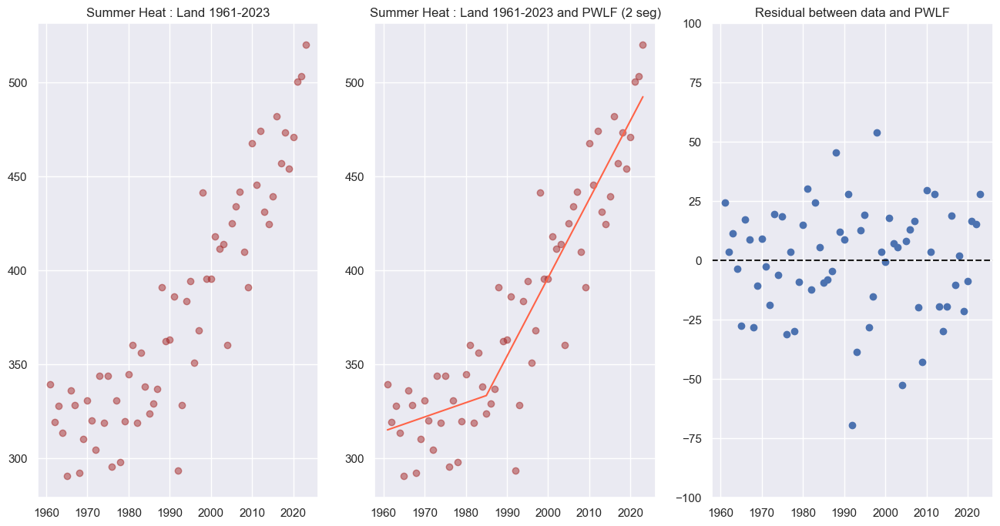

In [71]:
# help from https://jekel.me/piecewise_linear_fit_py/examples.html#find-the-best-number-of-line-segments

# define x & y using NH Ocean from 1990-2023 as example
x = nh_land_full.time.dt.year.values
y = nh_land_full.SummerHeat.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for two line segments - it looks like either 2 or 3 to me
res = my_pwlf.fit(2)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='brown', alpha=0.5)
plt.title("Summer Heat : Land 1961-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='brown', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer Heat : Land 1961-2023 and PWLF (2 seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'o', 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-100,100)
plt.title("Residual between data and PWLF")


plt.show()

In [72]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks, my_pwlf.r_squared()

(array([0.76185443, 4.18807005]),
 array([1961.        , 1985.00326802, 2023.        ]),
 np.float64(0.8599955456757523))

#### Two segments fits Land well and residuals are mostly cenetered around zero with only the 1992 (?) outlier

#### CP at 1990 results

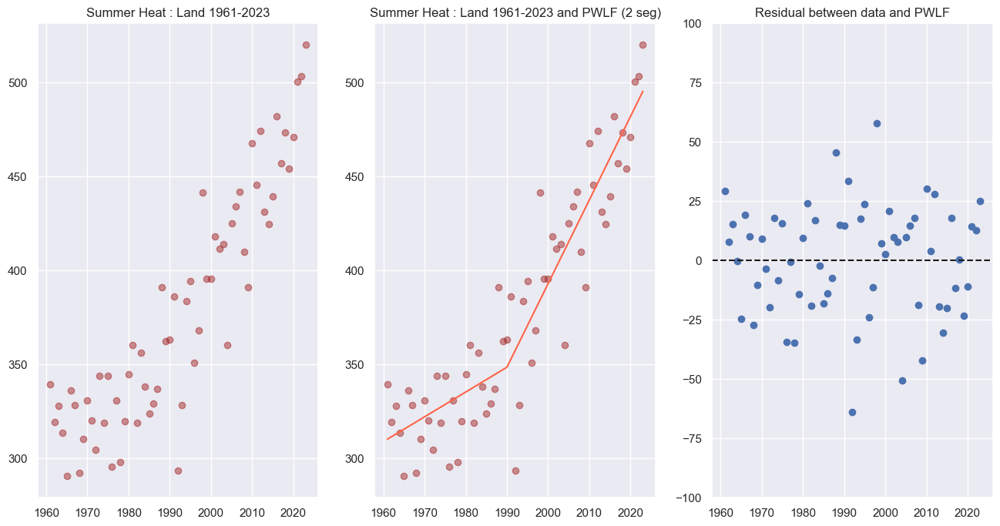

In [21]:
# define x & y using NH Ocean from 1990-2023 as example
x = nh_land_full.time.dt.year.values
y = nh_land_full.SummerHeat.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# your desired line segment end locations
x0 = np.array([min(x), 1990, max(x)])

# fit the data for three line segments - it looks like either 2 or 3 to me
res = my_pwlf.fit_with_breaks(x0)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# help from https://jekel.me/piecewise_linear_fit_py/examples.html#find-the-best-number-of-line-segments


# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='brown', alpha=0.5)
plt.title("Summer Heat : Land 1961-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='brown', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer Heat : Land 1961-2023 and PWLF (2 seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'o', 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-100,100)
plt.title("Residual between data and PWLF")


plt.show()



In [20]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks, my_pwlf.r_squared()

(array([1.32125557, 4.4537752 ]),
 array([1961, 1990, 2023]),
 np.float64(0.8578622674896367))

#### MSR and $R^{2}$

In [22]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(538.391762599218), np.float64(0.8578622674896367))

#### Only one segment for residual comparison

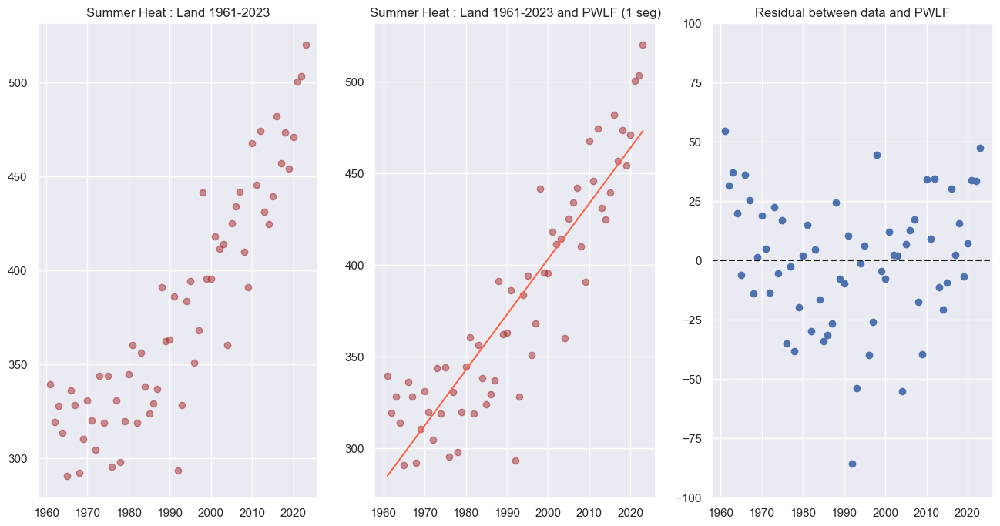

In [23]:
# help from https://jekel.me/piecewise_linear_fit_py/examples.html#find-the-best-number-of-line-segments

# define x & y using NH Ocean from 1990-2023 as example
x = nh_land_full.time.dt.year.values
y = nh_land_full.SummerHeat.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for two line segments - it looks like either 2 or 3 to me
res = my_pwlf.fit(1)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='brown', alpha=0.5)
plt.title("Summer Heat : Land 1961-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='brown', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer Heat : Land 1961-2023 and PWLF (1 seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'o', 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-100,100)
plt.title("Residual between data and PWLF")


plt.show()

In [16]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks, my_pwlf.r_squared()

(array([3.03653262]), array([1961, 2023]), np.float64(0.8049284808145911))

#### MSR and $R^{2}$

In [24]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(738.8952756755291), np.float64(0.8049284808145911))

### Analysis Land (2020+ exceptional)

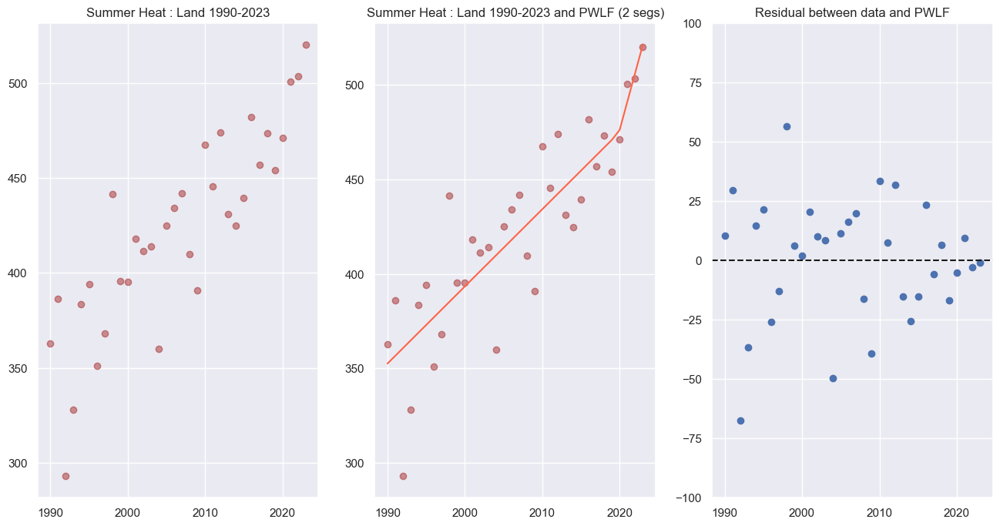

In [73]:
# help from https://jekel.me/piecewise_linear_fit_py/examples.html#find-the-best-number-of-line-segments

# define x & y 
x = nh_land_an.time.dt.year.values
y = nh_land_an.SummerHeat.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for two line segments
res = my_pwlf.fit(2)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='brown', alpha=0.5)
plt.title("Summer Heat : Land 1990-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='brown', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer Heat : Land 1990-2023 and PWLF (2 segs)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-100,100)
plt.title("Residual between data and PWLF")


plt.show()

In [74]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks, my_pwlf.r_squared()

(array([ 4.0846341, 15.0611957]),
 array([1990.        , 2019.89438019, 2023.        ]),
 np.float64(0.7515861561409192))

#### MSR and $R^{2}$

In [75]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(635.6162904139927), np.float64(0.7515861561409192))

#### **** try just one line instead

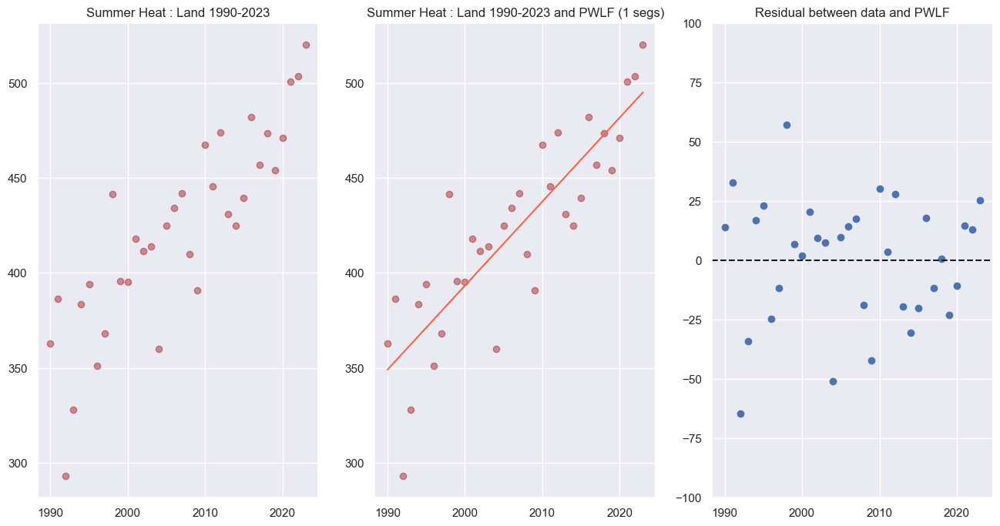

In [76]:
# help from https://jekel.me/piecewise_linear_fit_py/examples.html#find-the-best-number-of-line-segments

# define x & y 
x = nh_land_an.time.dt.year.values
y = nh_land_an.SummerHeat.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for two line segments
res = my_pwlf.fit(1)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='brown', alpha=0.5)
plt.title("Summer Heat : Land 1990-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='brown', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer Heat : Land 1990-2023 and PWLF (1 segs)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-100,100)
plt.title("Residual between data and PWLF")


plt.show()

In [77]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks, my_pwlf.r_squared()

(array([4.42453751]), array([1990, 2023]), np.float64(0.7364059275119377))

#### MSR and $R^{2}$

In [78]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(674.457928459991), np.float64(0.7364059275119377))

#### Two segments for Analysis period Land yields a slightly better fit so weak evidence for acceleration

### Full Ocean (accel since 2018)

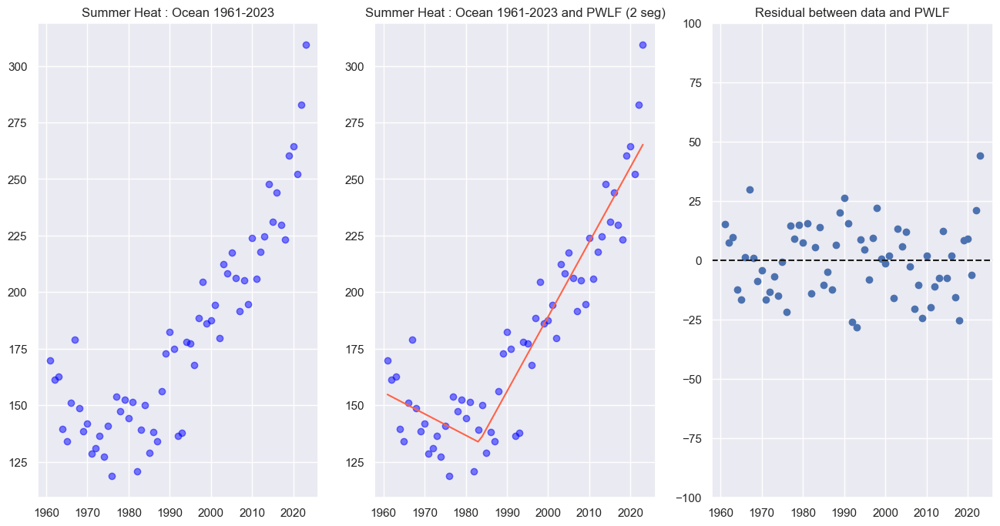

In [79]:
# help from https://james-brennan.github.io/posts/lowess_conf/


# define x & y using NH Ocean from 1990-2023 as example
x = nh_ocean_full.time.dt.year.values
y = nh_ocean_full.SummerHeat.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for two line segments - it looks like either 2 or 3 to me
res = my_pwlf.fit(2)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='blue', alpha=0.5)
plt.title("Summer Heat : Ocean 1961-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='blue', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer Heat : Ocean 1961-2023 and PWLF (2 seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-100,100)
plt.title("Residual between data and PWLF")


plt.show()

In [80]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks, my_pwlf.r_squared()

(array([-0.94961821,  3.30858127]),
 array([1961.        , 1983.22035047, 2023.        ]),
 np.float64(0.8821248057323156))

#### MSR and $R^{2}$

In [81]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(224.36427354816723), np.float64(0.8821248057323156))

#### Two segments for Ocean still looks wrong for recent years (high residuals in 2020+ and MSR plus $R^{2}$ not as good as below) - try 3

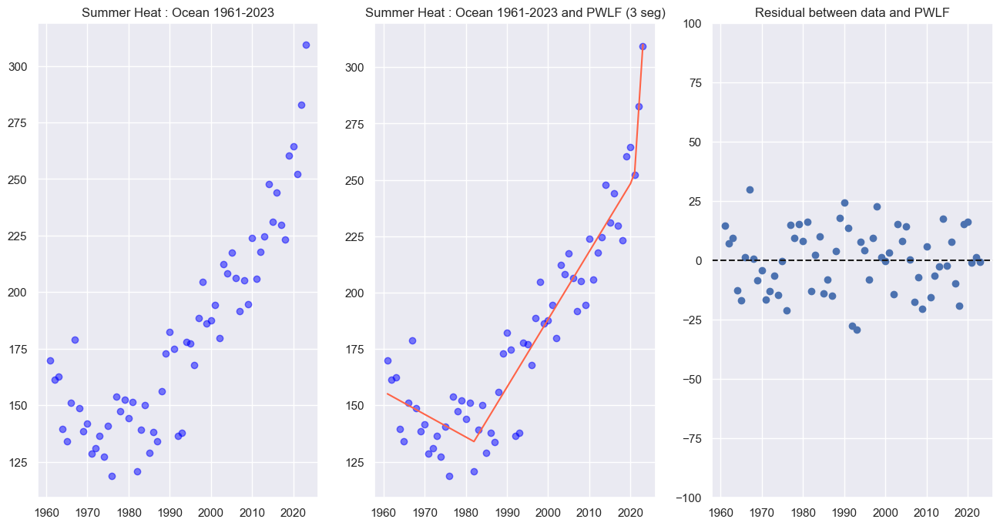

In [82]:



# define x & y using NH Ocean from 1990-2023 as example
x = nh_ocean_full.time.dt.year.values
y = nh_ocean_full.SummerHeat.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for three line segments - it looks like either 2 or 3 to me
res = my_pwlf.fit(3)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='blue', alpha=0.5)
plt.title("Summer Heat : Ocean 1961-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='blue', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer Heat : Ocean 1961-2023 and PWLF (3 seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-100,100)
plt.title("Residual between data and PWLF")


plt.show()

In [83]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks

(array([-1.0077756 ,  3.01111217, 28.43899626]),
 array([1961.        , 1982.00000252, 2020.9299631 , 2023.        ]))

#### MSR and $R^{2}$

In [84]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(178.17171786231685), np.float64(0.9063931813924961))

#### Three segments for Ocean yields much better residual plot - recent years slope is 29 deg/days per year for growth of summer heating!


#### *** Might want to fix the third segment transition for both heat and length - e.g. 2018 - try it

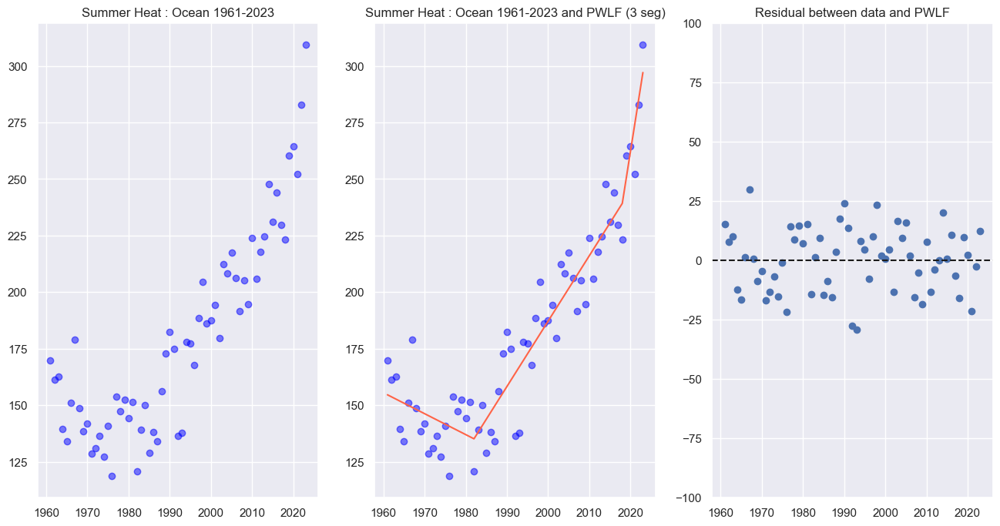

In [179]:



# define x & y using NH Ocean from 1990-2023 as example
x = nh_ocean_full.time.dt.year.values
y = nh_ocean_full.SummerHeat.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# your desired line segment end locations
x0 = np.array([min(x), 1982, 2018, max(x)])

# fit the data for three line segments - it looks like either 2 or 3 to me
res = my_pwlf.fit_with_breaks(x0)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='blue', alpha=0.5)
plt.title("Summer Heat : Ocean 1961-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='blue', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer Heat : Ocean 1961-2023 and PWLF (3 seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-100,100)
plt.title("Residual between data and PWLF")


plt.show()

In [180]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks

(array([-0.92702935,  2.89168177, 11.57128187]),
 array([1961, 1982, 2018, 2023]))

#### MSR and $R^{2}$

In [87]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(180.36701132100367), np.float64(0.9052398309110448))

#### These three segments for Ocean yields very slightly worse fit - with these segments recent years slope is 12 deg/days per year for growth of summer heating


#### What if I put the change point at 2015 ala Foster & Rahmstorf 2025?

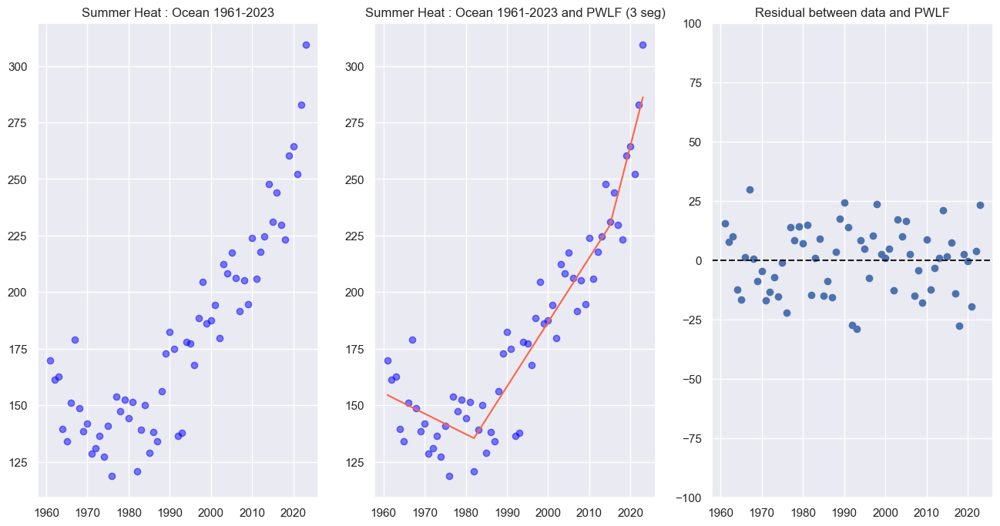

In [88]:



# define x & y using NH Ocean from 1990-2023 as example
x = nh_ocean_full.time.dt.year.values
y = nh_ocean_full.SummerHeat.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# your desired line segment end locations
x0 = np.array([min(x), 1982, 2015, max(x)])

# fit the data for three line segments - it looks like either 2 or 3 to me
res = my_pwlf.fit_with_breaks(x0)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='blue', alpha=0.5)
plt.title("Summer Heat : Ocean 1961-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='blue', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer Heat : Ocean 1961-2023 and PWLF (3 seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-100,100)
plt.title("Residual between data and PWLF")


plt.show()

In [89]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks

(array([-0.90933998,  2.8524536 ,  7.07695928]),
 array([1961, 1982, 2015, 2023]))

#### MSR and $R^{2}$

In [90]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(194.0888291484126), np.float64(0.8980307422422805))

### Analysis Ocean (accel since 2018)

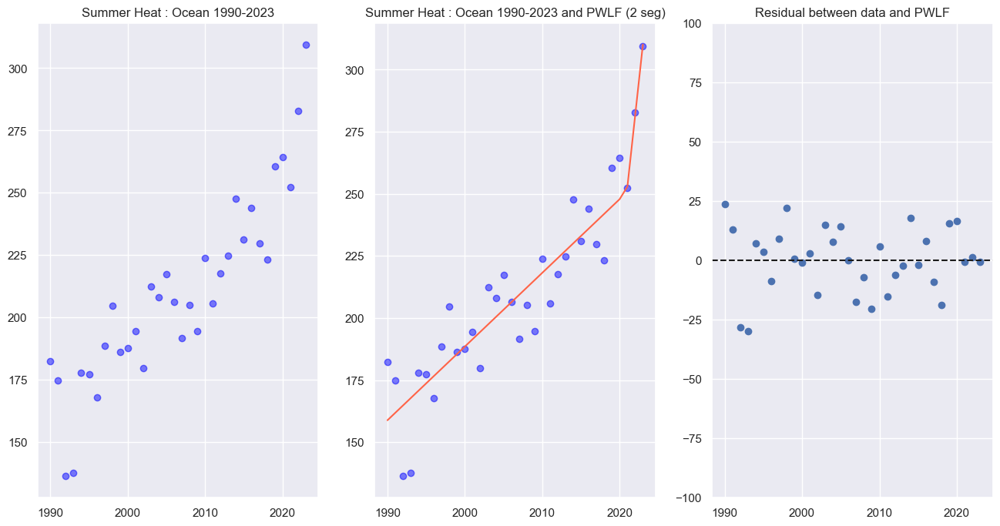

In [91]:
# help from https://james-brennan.github.io/posts/lowess_conf/


# define x & y using NH Ocean from 1990-2023 as example
x = nh_ocean_an.time.dt.year.values
y = nh_ocean_an.SummerHeat.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for two line segments - it looks like either 2 or 3 to me
res = my_pwlf.fit(2)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='blue', alpha=0.5)
plt.title("Summer Heat : Ocean 1990-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='blue', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer Heat : Ocean 1990-2023 and PWLF (2 seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-100,100)
plt.title("Residual between data and PWLF")


plt.show()

In [92]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks, my_pwlf.r_squared()

(array([ 2.96749196, 28.59212874]),
 array([1990.        , 2020.91832706, 2023.        ]),
 np.float64(0.8646808938726218))

#### MSR and $R^{2}$

In [93]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(184.968440459131), np.float64(0.8646808938726218))

#### Two segments for Ocean sbreak at 2020 looks wrong ? (although residuals in 2020+ are amazing and MSR plus $R^{2}$ is OK) - try 1

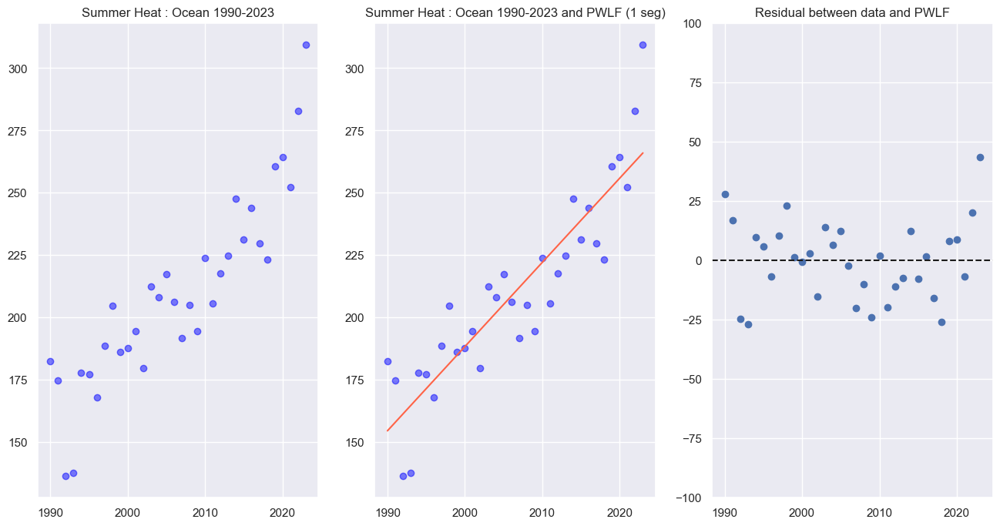

In [94]:



# define x & y using NH Ocean from 1990-2023 as example
x = nh_ocean_an.time.dt.year.values
y = nh_ocean_an.SummerHeat.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for three line segments - it looks like either 2 or 3 to me
res = my_pwlf.fit(1)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='blue', alpha=0.5)
plt.title("Summer Heat : Ocean 1990-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='blue', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer Heat : Ocean 1990-2023 and PWLF (1 seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-100,100)
plt.title("Residual between data and PWLF")


plt.show()

In [95]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks

(array([3.37699904]), array([1990, 2023]))

#### MSR and $R^{2}$

In [96]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(269.2587826514525), np.float64(0.8030158134279608))

#### Two segments for Ocean yields much better residual plot - recent years slope is 29 deg/days per year for growth of summer heating which is the same as the best fit 3 segment plot for 1961-2023!


#### *** Fix the second segment transition for heat - 2018 - try it

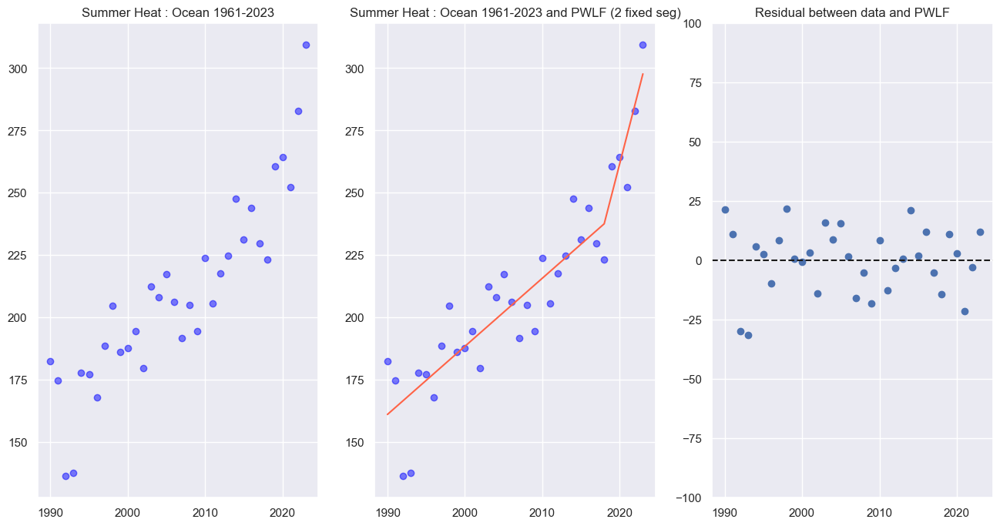

In [97]:
# define x & y using NH Ocean from 1990-2023 as example
x = nh_ocean_an.time.dt.year.values
y = nh_ocean_an.SummerHeat.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# your desired line segment end locations
x0 = np.array([min(x), 2018, max(x)])

# fit the data for three line segments - it looks like either 2 or 3 to me
res = my_pwlf.fit_with_breaks(x0)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='blue', alpha=0.5)
plt.title("Summer Heat : Ocean 1961-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='blue', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer Heat : Ocean 1961-2023 and PWLF (2 fixed seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-100,100)
plt.title("Residual between data and PWLF")


plt.show()

In [98]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks

(array([ 2.73089844, 12.02480711]), array([1990, 2018, 2023]))

#### MSR and $R^{2}$

In [99]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(186.52296371484167), np.float64(0.863543636636226))

#### These Two segments for Analysis Ocean yield a very similar residual plot but slightly worse MSR and $R^2$ - recent years slope is 12 $\frac{deg}{days}$ per year for growth of summer heating which is lower than for 1961-2023 - I suspect the break at 2020 is better but maybe just evidence of uncertainty


### Full Coastal (no accel)

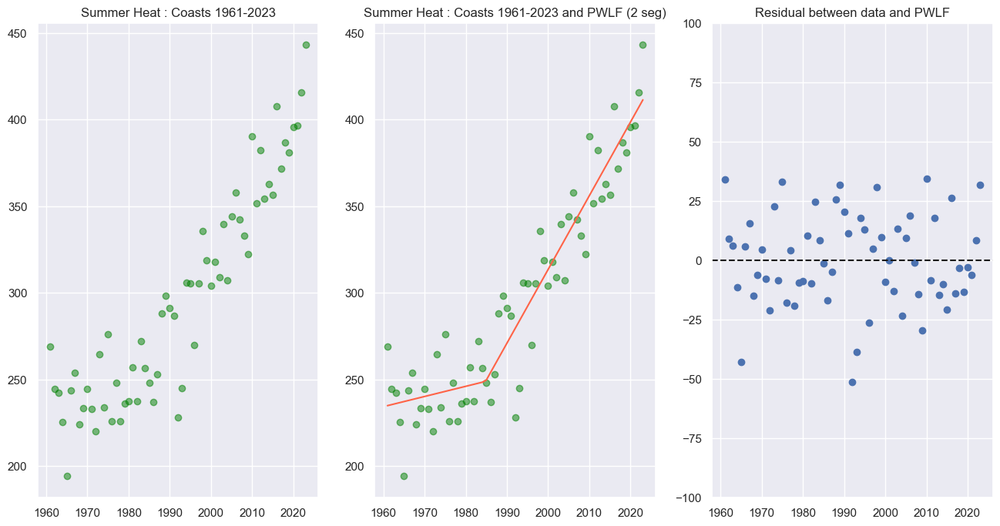

In [100]:
# help from https://james-brennan.github.io/posts/lowess_conf/


# define x & y using NH Ocean from 1990-2023 as example
x = nh_coast_full.time.dt.year.values
y = nh_coast_full.SummerHeat.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for two line segments - it looks like 2 is best to me
res = my_pwlf.fit(2)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='green', alpha=0.5)
plt.title("Summer Heat : Coasts 1961-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='green', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer Heat : Coasts 1961-2023 and PWLF (2 seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-100,100)
plt.title("Residual between data and PWLF")


plt.show()

In [101]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks

(array([0.58693681, 4.25391426]),
 array([1961.        , 1984.81321943, 2023.        ]))

#### MSR and $R^{2}$

In [102]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(375.66140243127376), np.float64(0.8974281303193966))

In [103]:
# # pretty printing of results? from https://github.com/cjekel/piecewise_linear_fit_py/tree/master/examples
# from __future__ import print_function
# p = my_pwlf.p_values(method='non-linear', step_size=1e-4)
# se = my_pwlf.se  # standard errors

# parameters = np.concatenate((my_pwlf.beta,
#                              my_pwlf.fit_breaks[1:-1]))

# header = ['Parameter type', 'Parameter value', 'Standard error', 't',
#           'P > np.abs(t) (p-value)']
# print(*header, sep=' | ')
# values = np.zeros((parameters.size, 5), dtype=np.object_)
# values[:, 1] = np.around(parameters, decimals=3)
# values[:, 2] = np.around(se, decimals=3)
# values[:, 3] = np.around(parameters / se, decimals=3)
# values[:, 4] = np.around(p, decimals=3)

# for i, row in enumerate(values):
#     if i < my_pwlf.beta.size:
#         row[0] = 'Beta'
#         print(*row, sep=' | ')
#     else:
#         row[0] = 'Breakpoint'
#         print(*row, sep=' | ')

#### try 3 segments with one fixed at 1984 and one at 2020

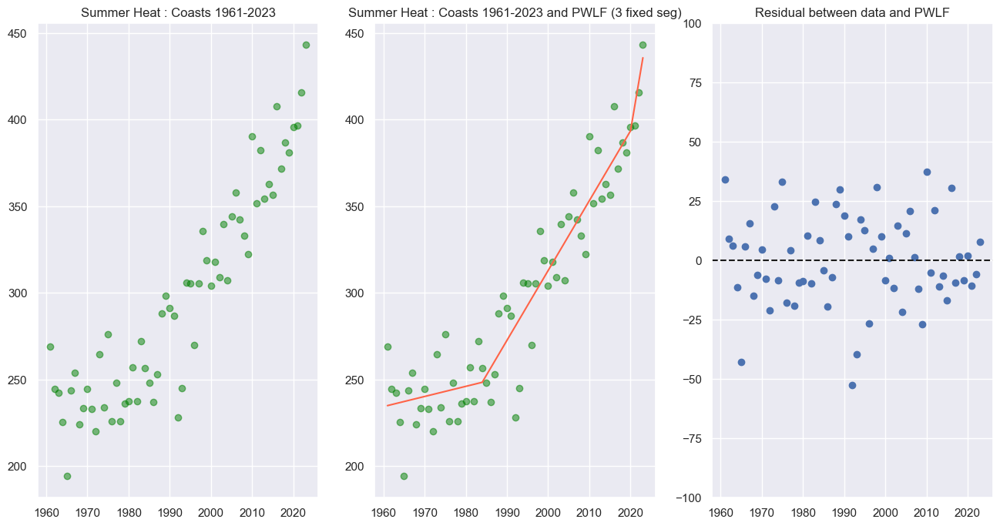

In [104]:
# help from https://james-brennan.github.io/posts/lowess_conf/


# define x & y using NH Ocean from 1990-2023 as example
x = nh_coast_full.time.dt.year.values
y = nh_coast_full.SummerHeat.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# your desired line segment end locations
x0 = np.array([min(x), 1984, 2020, max(x)])

# fit the data for three line segments - it looks like either 2 or 3 to me
res = my_pwlf.fit_with_breaks(x0)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='green', alpha=0.5)
plt.title("Summer Heat : Coasts 1961-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='green', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer Heat : Coasts 1961-2023 and PWLF (3 fixed seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-100,100)
plt.title("Residual between data and PWLF")


plt.show()

In [105]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks

(array([ 0.58462142,  4.02983742, 14.05082712]),
 array([1961, 1984, 2020, 2023]))

#### MSR and $R^{2}$

In [106]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(358.7431098716185), np.float64(0.9020475585822316))

#### Three segments look slightly better for Coasts - weak evidence of recent accel or just exceptional 2020+

### Analysis Coastal (2020+ exceptional)

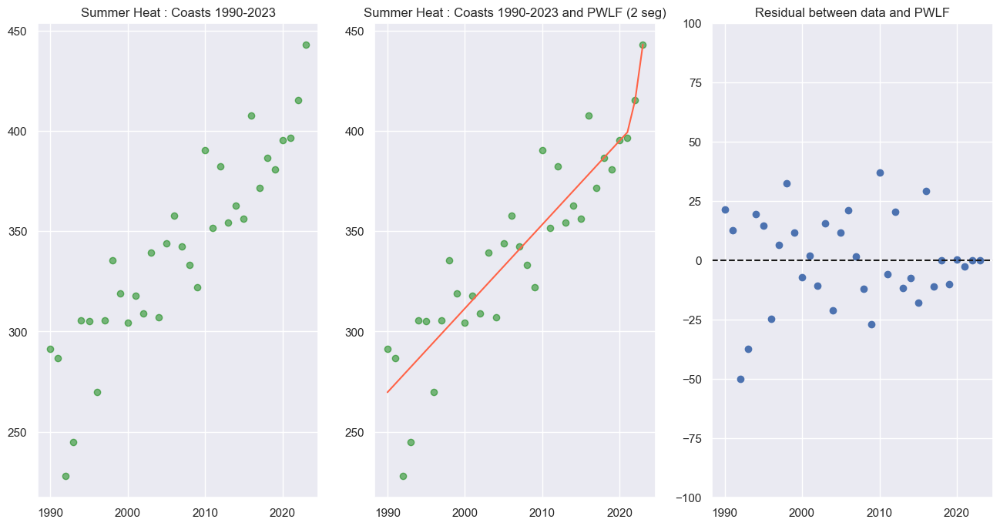

In [107]:
# help from https://james-brennan.github.io/posts/lowess_conf/


# define x & y using NH Ocean from 1990-2023 as example
x = nh_coast_an.time.dt.year.values
y = nh_coast_an.SummerHeat.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for two line segments - it looks like 2 is best to me
res = my_pwlf.fit(2)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='green', alpha=0.5)
plt.title("Summer Heat : Coasts 1990-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='green', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer Heat : Coasts 1990-2023 and PWLF (2 seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-100,100)
plt.title("Residual between data and PWLF")


plt.show()

In [108]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks

(array([ 4.18570118, 27.73695893]),
 array([1990.        , 2021.49613045, 2023.        ]))

#### MSR and $R^{2}$

In [109]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(373.4034744866746), np.float64(0.8367986352621997))

#### Try just one segment

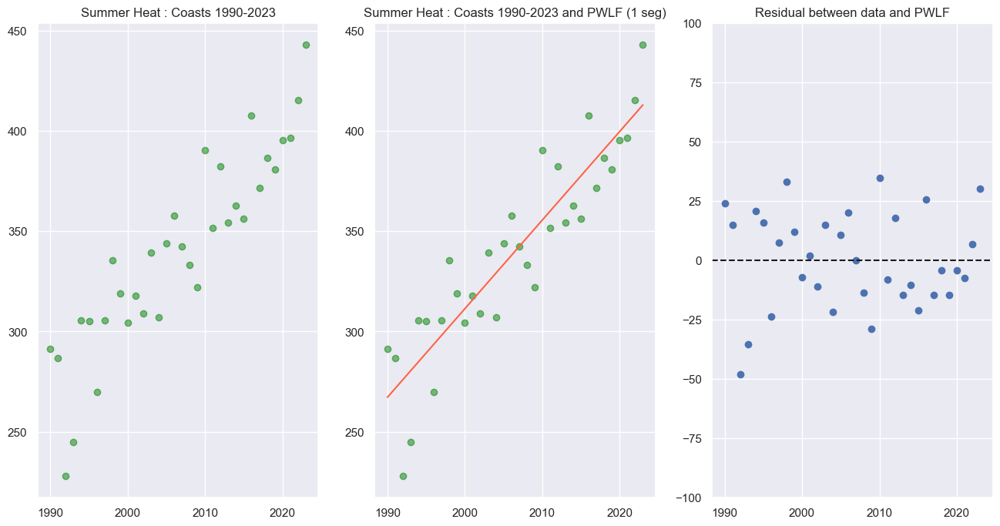

In [110]:
# help from https://james-brennan.github.io/posts/lowess_conf/


# define x & y using NH Ocean from 1990-2023 as example
x = nh_coast_an.time.dt.year.values
y = nh_coast_an.SummerHeat.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for two line segments - it looks like 2 is best to me
res = my_pwlf.fit(1)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='green', alpha=0.5)
plt.title("Summer Heat : Coasts 1990-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='green', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer Heat : Coasts 1990-2023 and PWLF (1 seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-100,100)
plt.title("Residual between data and PWLF")


plt.show()

In [111]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks

(array([4.42048563]), array([1990, 2023]))

#### MSR and $R^{2}$

In [112]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(407.20063276414584), np.float64(0.8220271006300558))

#### Two segments for Analysis period Coasts yields a slightly better fit so weak evidence for acceleration

## **** General Conclusions for NH:
- Evidence of acceleration in Summer Length for Ocean surfaces for 1961-2023 and 1990-2023
- No evidence of acceleration in Summer Length for Inland and Coastal margins for either time period
- Evidence of acceleration in Summer Heat for Ocean surfaces for 1961-2023 and 1990-2023
- Exceptional 2020+ for Summer Heat for Coastal margins for 1961-2023 and 1990-2023 - insufficient for accel
- Exceptional 2020+  in Summer Heat for Inland areas for 1990-2023 - insufficient for accel

## ** SOUTHERN ** Summer Length

### Full Land (accel since 1999?)

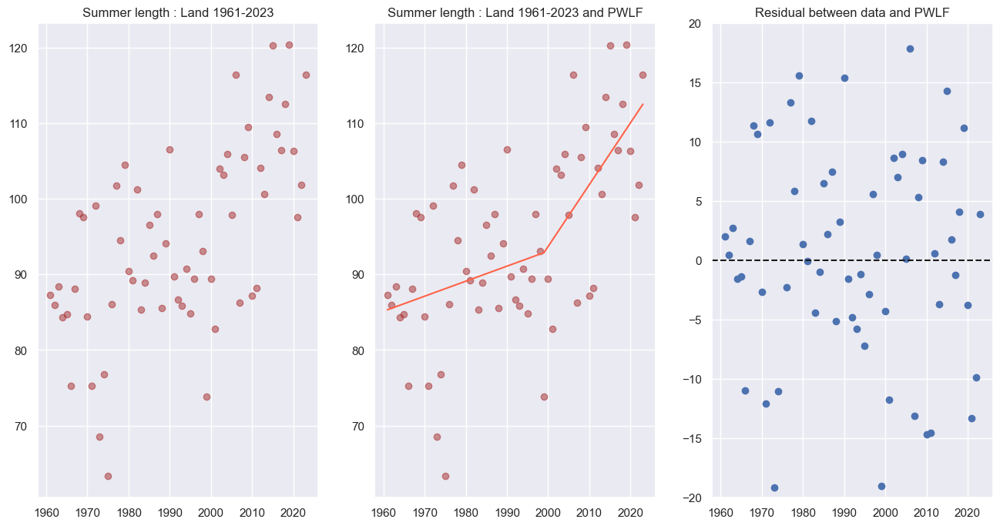

In [113]:
# help from https://jekel.me/piecewise_linear_fit_py/examples.html#find-the-best-number-of-line-segments

# define x & y 
x = sh_land_full.time.dt.year.values
y = sh_land_full.SummerLength.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for two line segments - it looks like either 2 or 3 to me
res = my_pwlf.fit(2)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='brown', alpha=0.5)
plt.title("Summer length : Land 1961-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='brown', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer length : Land 1961-2023 and PWLF")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-20,20)
plt.title("Residual between data and PWLF")


plt.show()

In [114]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks

(array([0.19902113, 0.81868605]),
 array([1961.        , 1998.99999999, 2023.        ]))

#### MSR and $R^{2}$

In [115]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(85.69426245560655), np.float64(0.4184541214608636))

#### try one segment

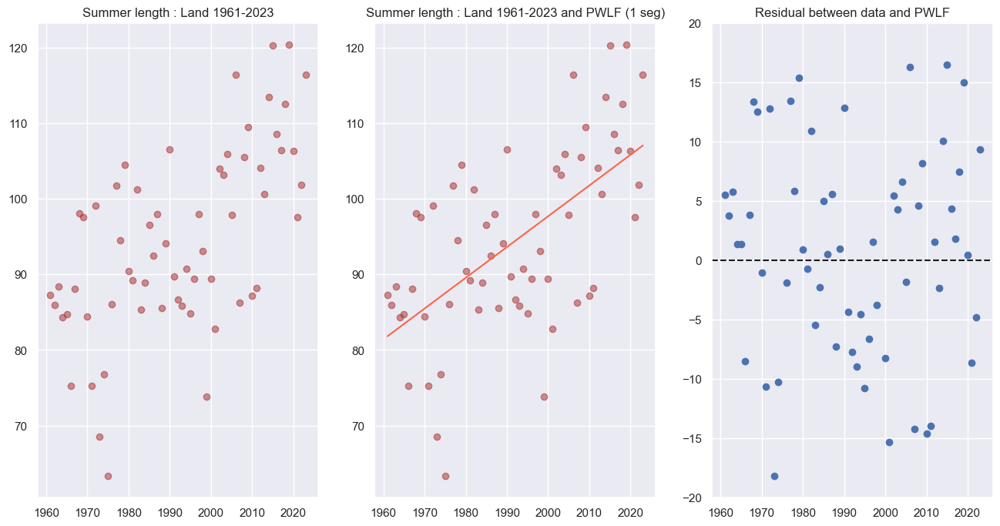

In [116]:
# help from https://jekel.me/piecewise_linear_fit_py/examples.html#find-the-best-number-of-line-segments

# define x & y 
x = sh_land_full.time.dt.year.values
y = sh_land_full.SummerLength.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for line segments
res = my_pwlf.fit(1)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='brown', alpha=0.5)
plt.title("Summer length : Land 1961-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='brown', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer length : Land 1961-2023 and PWLF (1 seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-20,20)
plt.title("Residual between data and PWLF")


plt.show()

In [117]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks

(array([0.40724187]), array([1961, 2023]))

#### MSR and $R^{2}$

In [118]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(92.51625537042202), np.float64(0.37215811809553456))

#### Two segments fits Land better and residuals are mostly centered around zero - evidence of accel since 1999

### Analysis Land (no accel)

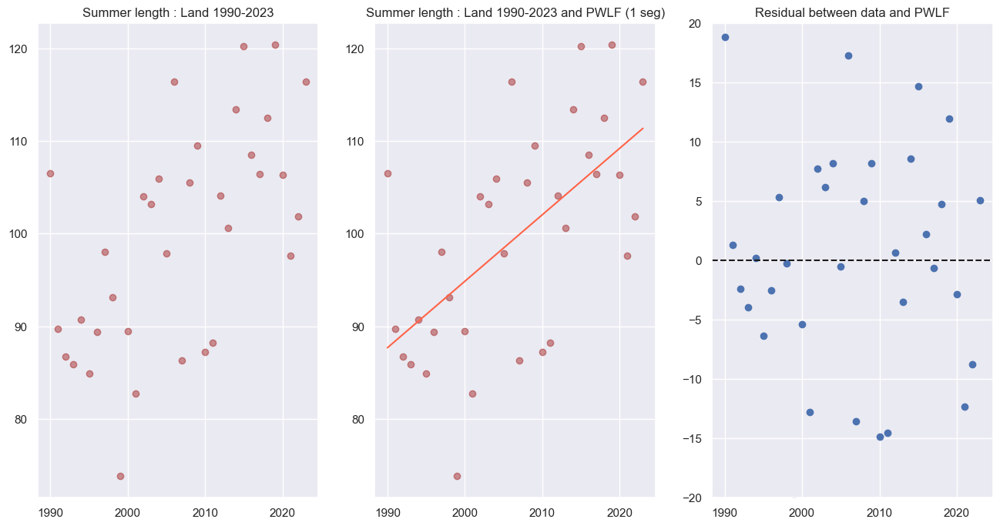

In [119]:
# help from https://jekel.me/piecewise_linear_fit_py/examples.html#find-the-best-number-of-line-segments

# define x & y 
x = sh_land_an.time.dt.year.values
y = sh_land_an.SummerLength.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for one line segments
res = my_pwlf.fit(1)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='brown', alpha=0.5)
plt.title("Summer length : Land 1990-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='brown', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer length : Land 1990-2023 and PWLF (1 seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-20,20)
plt.title("Residual between data and PWLF")


plt.show()

In [120]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks, my_pwlf.r_squared()

(array([0.71829012]), array([1990, 2023]), np.float64(0.36272980706469915))

#### MSR and $R^{2}$

In [121]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(87.24506788295139), np.float64(0.36272980706469915))

#### One segment for Analysis period Land looks to be appropriate - no evidence for accel 

### Full Ocean (hiatus and then return to similar rates? Aerosols?)

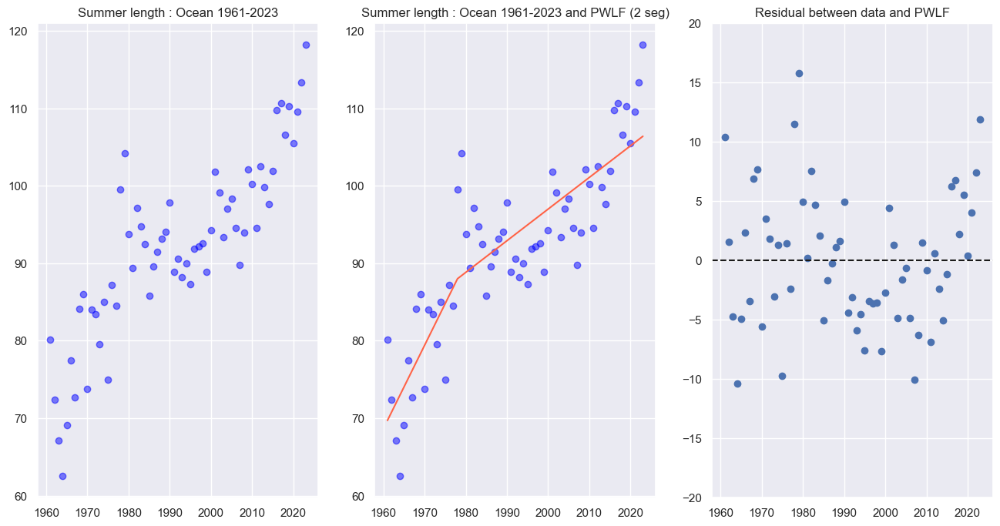

In [122]:
# help from https://james-brennan.github.io/posts/lowess_conf/


# define x & y 
x = sh_ocean_full.time.dt.year.values
y = sh_ocean_full.SummerLength.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for two line segments - it looks like either 2 or 3 to me
res = my_pwlf.fit(2)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='blue', alpha=0.5)
plt.title("Summer length : Ocean 1961-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='blue', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer length : Ocean 1961-2023 and PWLF (2 seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-20,20)
plt.title("Residual between data and PWLF")


plt.show()

In [123]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks, my_pwlf.r_squared()

(array([1.07567353, 0.40851976]),
 array([1961.        , 1977.99999999, 2023.        ]),
 np.float64(0.7601382145296729))

#### Two segments for Ocean looks wrong for recent years - try 3

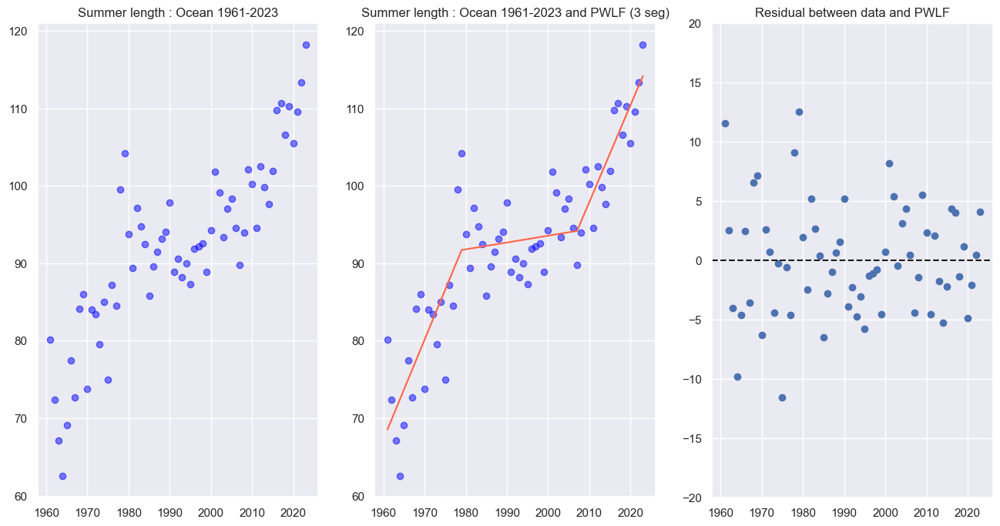

In [124]:
# define x & y 
x = sh_ocean_full.time.dt.year.values
y = sh_ocean_full.SummerLength.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for three line segments - it looks like either 2 or 3 to me
res = my_pwlf.fit(3)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='blue', alpha=0.5)
plt.title("Summer length : Ocean 1961-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='blue', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer length : Ocean 1961-2023 and PWLF (3 seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-20,20)
plt.title("Residual between data and PWLF")


plt.show()

In [125]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks, my_pwlf.r_squared()

(array([1.28704315, 0.08797913, 1.25122718]),
 array([1961.        , 1979.00000001, 2007.02326385, 2023.        ]),
 np.float64(0.8287024172132869))

#### MSR and $R^{2}$

In [126]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(22.342973344136073), np.float64(0.8287024172132869))

#### Three segments for Ocean yields similar residual plot and better $R^2$ - recent years' (2007+) slope is 1.3 days per year for growth of summer length!

### Analysis Ocean (2012 hiatus?)

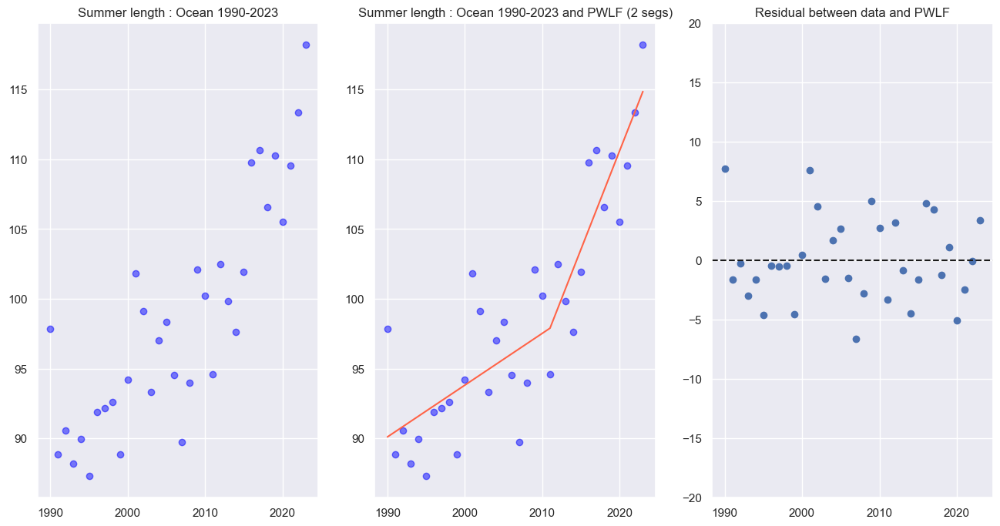

In [127]:
# help from https://jekel.me/piecewise_linear_fit_py/examples.html#find-the-best-number-of-line-segments

# define x & y 
x = sh_ocean_an.time.dt.year.values
y = sh_ocean_an.SummerLength.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for two line segments
res = my_pwlf.fit(2)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='blue', alpha=0.5)
plt.title("Summer length : Ocean 1990-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='blue', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer length : Ocean 1990-2023 and PWLF (2 segs)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-20,20)
plt.title("Residual between data and PWLF")


plt.show()

In [128]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks, my_pwlf.r_squared()

(array([0.37095645, 1.41294137]),
 array([1990., 2011., 2023.]),
 np.float64(0.8023738566188996))

#### MSR and $R^{2}$

In [129]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(12.573008752982778), np.float64(0.8023738566188996))

#### **** try just one line instead

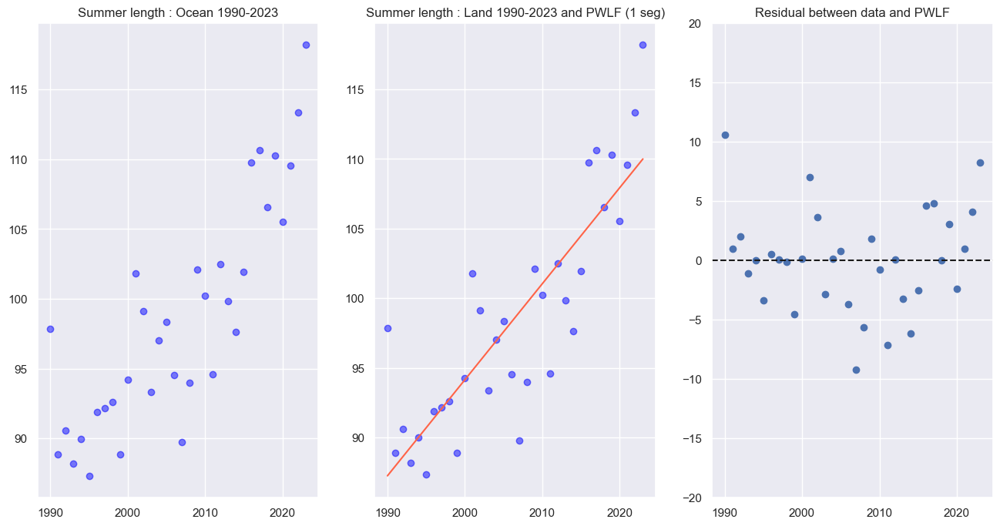

In [130]:
# help from https://jekel.me/piecewise_linear_fit_py/examples.html#find-the-best-number-of-line-segments

# define x & y 
x = sh_ocean_an.time.dt.year.values
y = sh_ocean_an.SummerLength.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for two line segments
res = my_pwlf.fit(1)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='blue', alpha=0.5)
plt.title("Summer length : Ocean 1990-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='blue', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer length : Land 1990-2023 and PWLF (1 seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-20,20)
plt.title("Residual between data and PWLF")


plt.show()

In [131]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks, my_pwlf.r_squared()

(array([0.68968125]), array([1990, 2023]), np.float64(0.7196192236807986))

#### MSR and $R^{2}$

In [132]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(17.837872533045427), np.float64(0.7196192236807986))

#### Two segments for Analysis period Ocean yields a better fit (residuals and $R^2$ and a much higher slope (1.4 $\frac{days}{year}$) for recent years - *indicates acceleration*

### Full Coastal (accel since 2000)

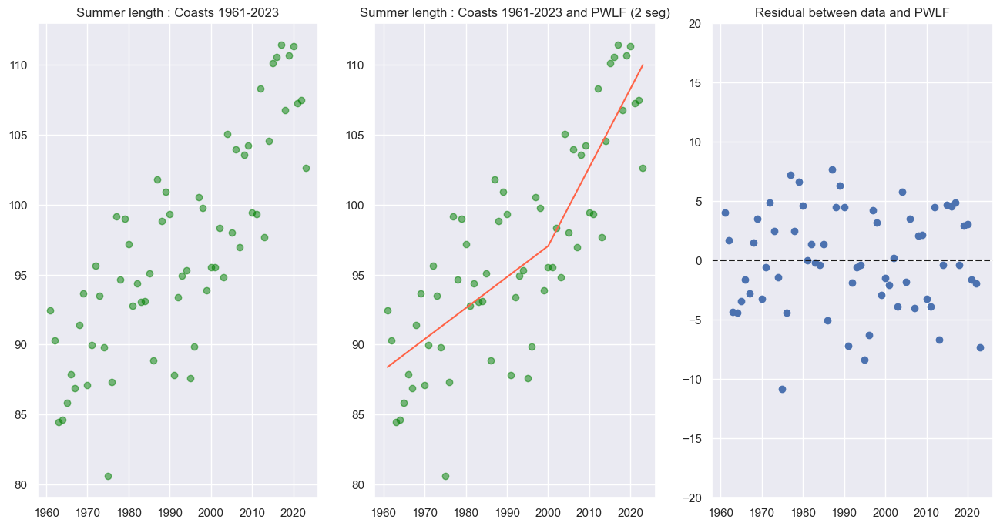

In [133]:
# help from https://james-brennan.github.io/posts/lowess_conf/


# define x & y 
x = sh_coast_full.time.dt.year.values
y = sh_coast_full.SummerLength.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for two line segments - it looks like 2 is best to me
res = my_pwlf.fit(2)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='green', alpha=0.5)
plt.title("Summer length : Coasts 1961-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='green', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer length : Coasts 1961-2023 and PWLF (2 seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-20,20)
plt.title("Residual between data and PWLF")


plt.show()

In [134]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks

(array([0.22203659, 0.56327853]),
 array([1961.        , 2000.00000001, 2023.        ]))

#### MSR and $R^{2}$

In [135]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(17.450568026278674), np.float64(0.6839898398522726))

#### Two segments fits Coastal areas well - acceleration since 2000 again evident

### Analysis Coastal (no accel)

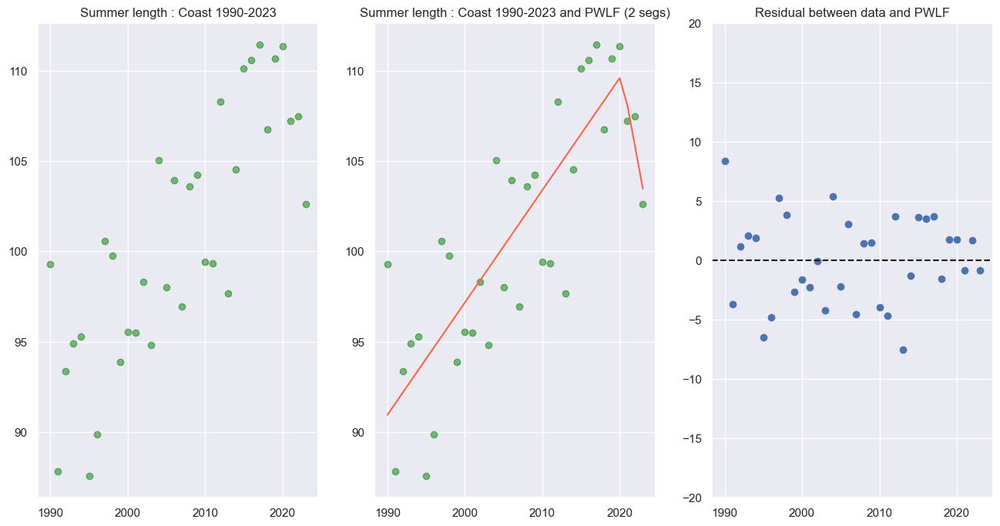

In [136]:
# help from https://jekel.me/piecewise_linear_fit_py/examples.html#find-the-best-number-of-line-segments

# define x & y 
x = sh_coast_an.time.dt.year.values
y = sh_coast_an.SummerLength.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for two line segments
res = my_pwlf.fit(2)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='green', alpha=0.5)
plt.title("Summer length : Coast 1990-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='green', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer length : Coast 1990-2023 and PWLF (2 segs)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-20,20)
plt.title("Residual between data and PWLF")


plt.show()

In [137]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks, my_pwlf.r_squared()

(array([ 0.62176347, -2.31162834]),
 array([1990.        , 2020.27274686, 2023.        ]),
 np.float64(0.6939333784676893))

#### MSR and $R^{2}$

In [138]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(13.650447520354463), np.float64(0.6939333784676893))

#### **** try just one line instead

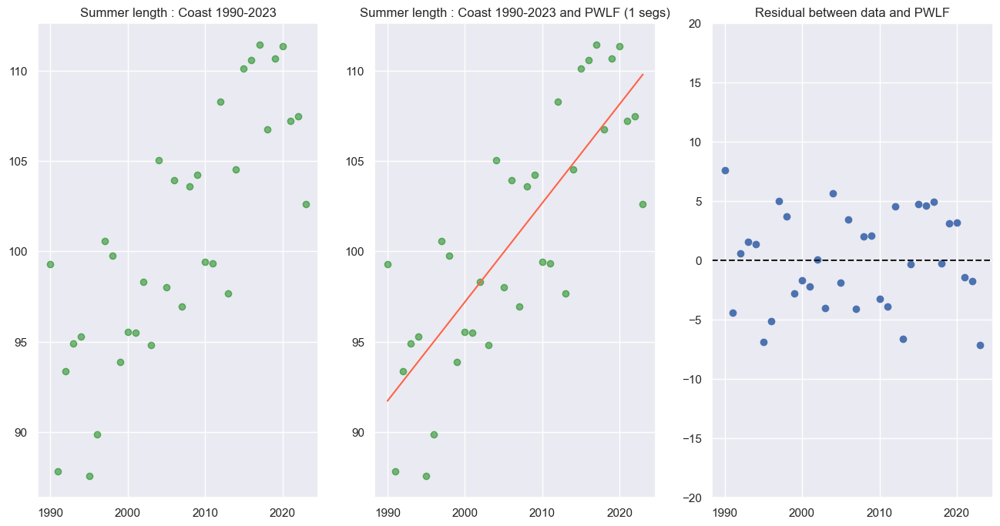

In [139]:
# help from https://jekel.me/piecewise_linear_fit_py/examples.html#find-the-best-number-of-line-segments

# define x & y 
x = sh_coast_an.time.dt.year.values
y = sh_coast_an.SummerLength.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for two line segments
res = my_pwlf.fit(1)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='green', alpha=0.5)
plt.title("Summer length : Coast 1990-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='green', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer length : Coast 1990-2023 and PWLF (1 segs)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-20,20)
plt.title("Residual between data and PWLF")


plt.show()

In [140]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks, my_pwlf.r_squared()

(array([0.54797621]), array([1990, 2023]), np.float64(0.6480271986787152))

#### MSR and $R^{2}$

In [141]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(15.69784457048723), np.float64(0.6480271986787152))

#### One segment for Analysis period Coast yields a more parsimonius fit - no evidence of acceleration

## ** SOUTHERN ** Summer Heat

### Full Land (accel since 2000)

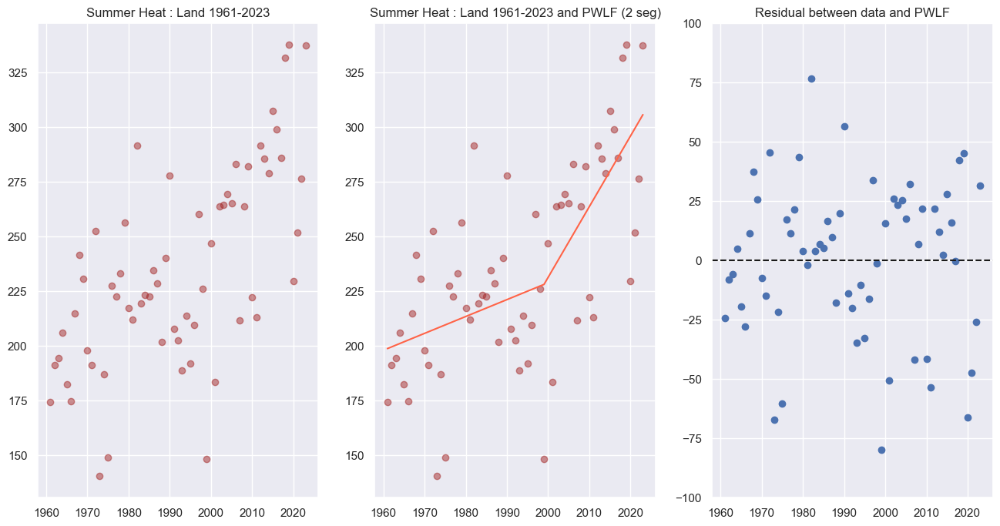

In [142]:
# help from https://jekel.me/piecewise_linear_fit_py/examples.html#find-the-best-number-of-line-segments

# define x & y 
x = sh_land_full.time.dt.year.values
y = sh_land_full.SummerHeat.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for two line segments - it looks like either 2 or 3 to me
res = my_pwlf.fit(2)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='brown', alpha=0.5)
plt.title("Summer Heat : Land 1961-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='brown', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer Heat : Land 1961-2023 and PWLF (2 seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'o', 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-100,100)
plt.title("Residual between data and PWLF")


plt.show()

In [143]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks, my_pwlf.r_squared()

(array([0.77085252, 3.22848407]),
 array([1961., 1999., 2023.]),
 np.float64(0.4776739317552985))

#### MSR and $R^{2}$

In [144]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(1039.1258722611683), np.float64(0.4776739317552985))

#### just 1 seg?

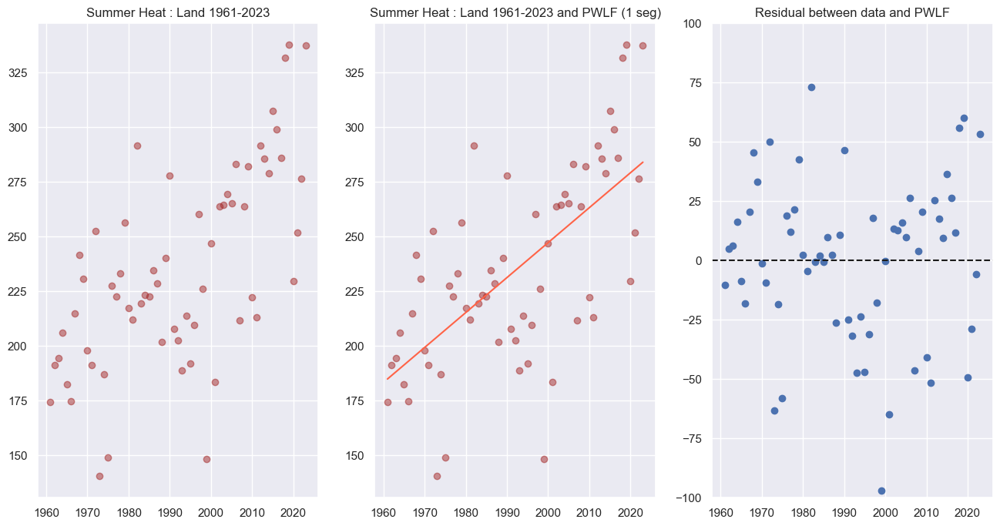

In [145]:
# help from https://jekel.me/piecewise_linear_fit_py/examples.html#find-the-best-number-of-line-segments

# define x & y 
x = sh_land_full.time.dt.year.values
y = sh_land_full.SummerHeat.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for two line segments - it looks like either 2 or 3 to me
res = my_pwlf.fit(1)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='brown', alpha=0.5)
plt.title("Summer Heat : Land 1961-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='brown', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer Heat : Land 1961-2023 and PWLF (1 seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'o', 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-100,100)
plt.title("Residual between data and PWLF")


plt.show()

In [146]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks, my_pwlf.r_squared()

(array([1.59666958]), array([1961, 2023]), np.float64(0.42373472926287925))

#### MSR and $R^{2}$

In [147]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(1146.4335948631895), np.float64(0.42373472926287925))

#### Two segments fits Land better and again evidence of a kink to higher rate at year 2000 - acceleration?

### Analysis Land (no accel)

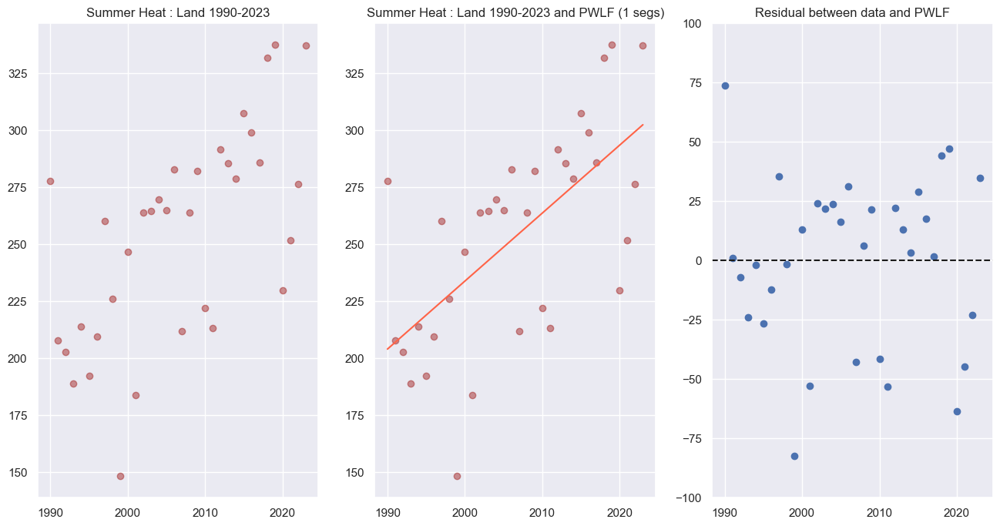

In [148]:
# help from https://jekel.me/piecewise_linear_fit_py/examples.html#find-the-best-number-of-line-segments

# define x & y 
x = sh_land_an.time.dt.year.values
y = sh_land_an.SummerHeat.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for one line segments
res = my_pwlf.fit(1)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='brown', alpha=0.5)
plt.title("Summer Heat : Land 1990-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='brown', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer Heat : Land 1990-2023 and PWLF (1 segs)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-100,100)
plt.title("Residual between data and PWLF")


plt.show()

In [149]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks, my_pwlf.r_squared()

(array([2.98422691]), array([1990, 2023]), np.float64(0.41242781115670724))

#### MSR and $R^{2}$

In [150]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(1221.1744573721717), np.float64(0.41242781115670724))

#### **** try two lines instead but doesn't look warranted

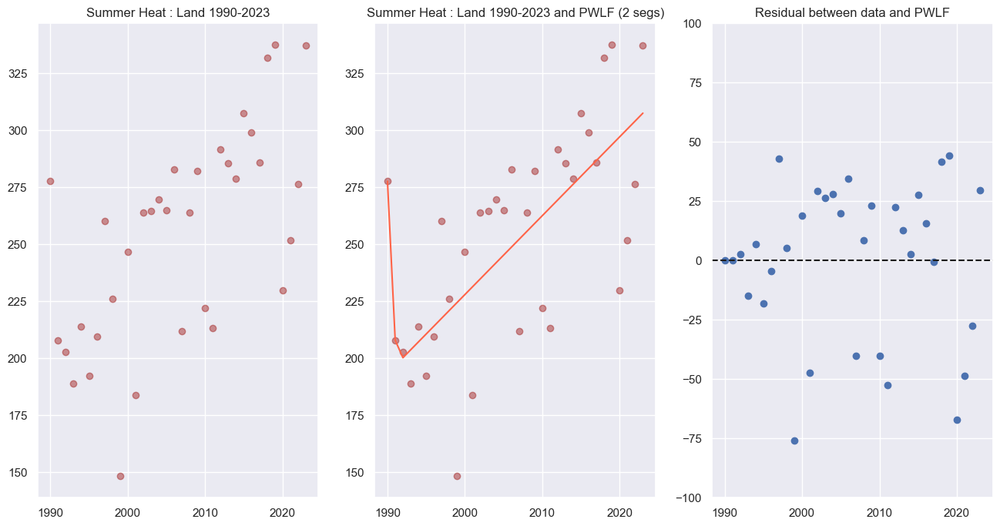

In [151]:
# help from https://jekel.me/piecewise_linear_fit_py/examples.html#find-the-best-number-of-line-segments

# define x & y 
x = sh_land_an.time.dt.year.values
y = sh_land_an.SummerHeat.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for two line segments
res = my_pwlf.fit(2)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='brown', alpha=0.5)
plt.title("Summer Heat : Land 1990-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='brown', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer Heat : Land 1990-2023 and PWLF (2 segs)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-100,100)
plt.title("Residual between data and PWLF")


plt.show()

In [152]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks, my_pwlf.r_squared()

(array([-69.82626012,   3.4624874 ]),
 array([1990.        , 1991.15172994, 2023.        ]),
 np.float64(0.5006143806513577))

#### MSR and $R^{2}$

In [153]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(1037.8928313950364), np.float64(0.5006143806513577))

#### One segment for Analysis period Land is much more visually parsimonius

### Full Ocean (hiatus? or accel since 2012)

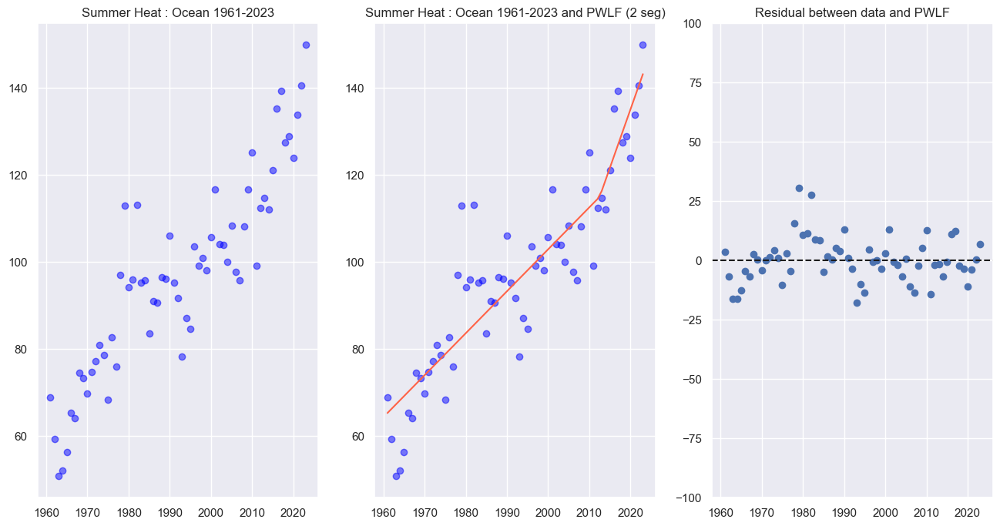

In [154]:
# help from https://james-brennan.github.io/posts/lowess_conf/


# define x & y 
x = sh_ocean_full.time.dt.year.values
y = sh_ocean_full.SummerHeat.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for two line segments - it looks like either 2 or 3 to me
res = my_pwlf.fit(2)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='blue', alpha=0.5)
plt.title("Summer Heat : Ocean 1961-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='blue', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer Heat : Ocean 1961-2023 and PWLF (2 seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-100,100)
plt.title("Residual between data and PWLF")


plt.show()

In [155]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks, my_pwlf.r_squared()

(array([0.96563939, 2.69049126]),
 array([1961.        , 2012.51129924, 2023.        ]),
 np.float64(0.8221039073686972))

#### MSR and $R^{2}$

In [156]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(89.8594376317712), np.float64(0.8221039073686972))

#### Two segments for Ocean looks quite good (good residuals and $R^{2}$ - evidence of acceration since 2012 or so

### Analysis Ocean (2012 hiatus?)

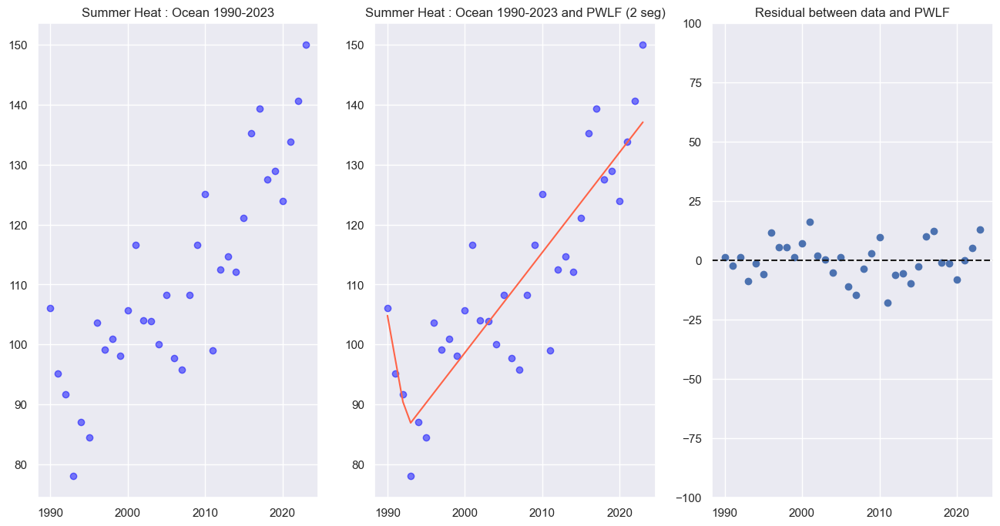

In [157]:
# help from https://james-brennan.github.io/posts/lowess_conf/


# define x & y 
x = sh_ocean_an.time.dt.year.values
y = sh_ocean_an.SummerHeat.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for two unknown line segments
res = my_pwlf.fit(2)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='blue', alpha=0.5)
plt.title("Summer Heat : Ocean 1990-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='blue', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer Heat : Ocean 1990-2023 and PWLF (2 seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-100,100)
plt.title("Residual between data and PWLF")


plt.show()

In [158]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks, my_pwlf.r_squared()

(array([-7.19399748,  1.67028678]),
 array([1990.        , 1992.58305803, 2023.        ]),
 np.float64(0.7804684679933335))

#### MSR and $R^{2}$

In [159]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(62.763649117433395), np.float64(0.7804684679933335))

#### Try one segment 

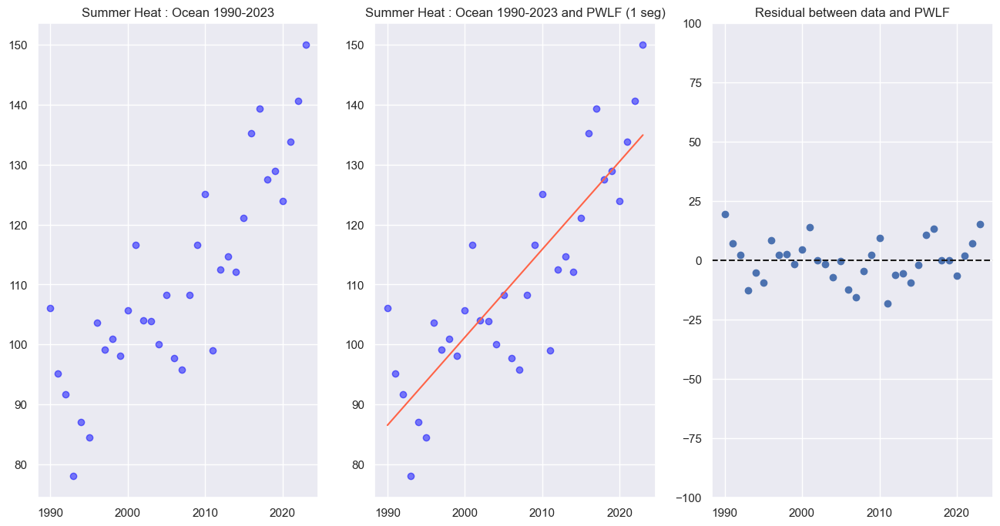

In [160]:



# define x & y 
x = sh_ocean_an.time.dt.year.values
y = sh_ocean_an.SummerHeat.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for three line segments - it looks like either 2 or 3 to me
res = my_pwlf.fit(1)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='blue', alpha=0.5)
plt.title("Summer Heat : Ocean 1990-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='blue', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer Heat : Ocean 1990-2023 and PWLF (1 seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-100,100)
plt.title("Residual between data and PWLF")


plt.show()

In [161]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks

(array([1.46547455]), array([1990, 2023]))

#### MSR and $R^{2}$

In [162]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(79.19009838180749), np.float64(0.7230128607565608))

#### really looks like the kink should be around 2012 again?


#### *** Fix the second segment transition for heat - 2012 - try it

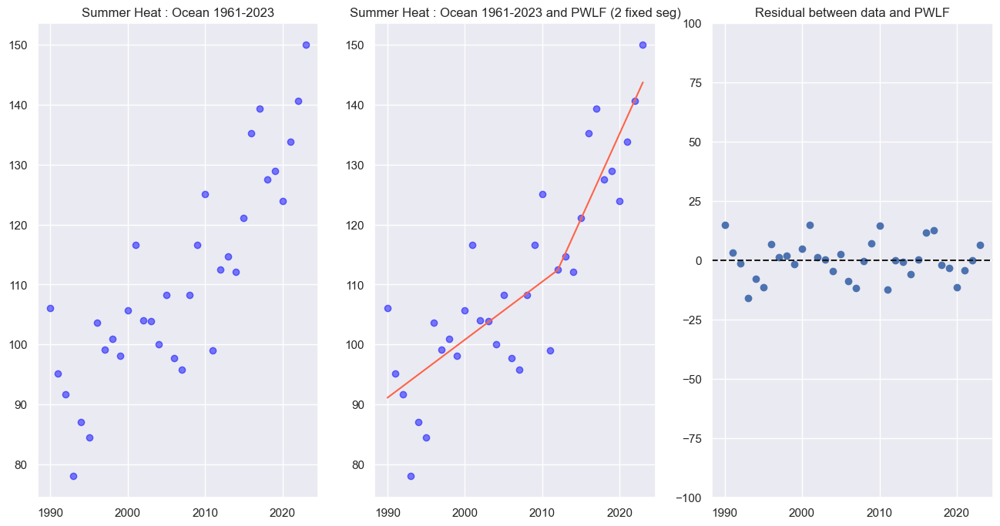

In [163]:
# define x & y 
x = sh_ocean_an.time.dt.year.values
y = sh_ocean_an.SummerHeat.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# your desired line segment end locations
x0 = np.array([min(x), 2012, max(x)])

# fit the data for three line segments - it looks like either 2 or 3 to me
res = my_pwlf.fit_with_breaks(x0)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='blue', alpha=0.5)
plt.title("Summer Heat : Ocean 1961-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='blue', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer Heat : Ocean 1961-2023 and PWLF (2 fixed seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-100,100)
plt.title("Residual between data and PWLF")


plt.show()

In [164]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks

(array([0.96717285, 2.84368874]), array([1990, 2012, 2023]))

#### MSR and $R^{2}$

In [165]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(63.95289634717016), np.float64(0.7763087789065765))

#### These Two segments for Analysis Ocean yield a very similar residual plot and MSR and $R^2$ - recent years slope is 2.8 $\frac{deg}{days}$ per year for growth of summer heating which matches 1961-2023 given the same breakpoint - accel since 2012


### Full Coastal (accel since 2000)

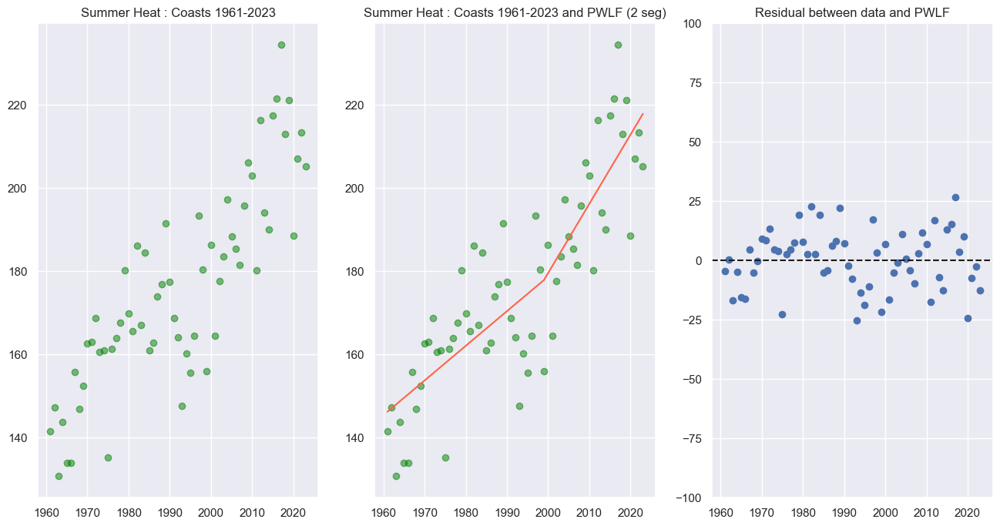

In [166]:
# help from https://james-brennan.github.io/posts/lowess_conf/


# define x & y 
x = sh_coast_full.time.dt.year.values
y = sh_coast_full.SummerHeat.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for two line segments - it looks like 2 is best to me
res = my_pwlf.fit(2)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='green', alpha=0.5)
plt.title("Summer Heat : Coasts 1961-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='green', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer Heat : Coasts 1961-2023 and PWLF (2 seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-100,100)
plt.title("Residual between data and PWLF")


plt.show()

In [167]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks

(array([0.8346303 , 1.66665571]),
 array([1961.        , 1999.00000002, 2023.        ]))

#### MSR and $R^{2}$

In [168]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(153.07573831222626), np.float64(0.7341902392484201))

#### What if we put the breakpoint at 2012 again?

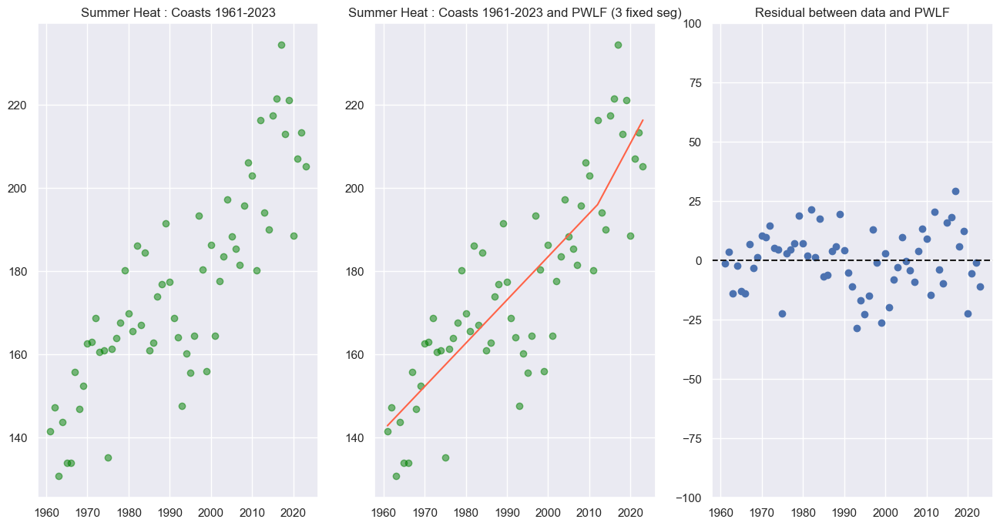

In [169]:
# help from https://james-brennan.github.io/posts/lowess_conf/


# define x & y 
x = sh_coast_full.time.dt.year.values
y = sh_coast_full.SummerHeat.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# your desired line segment end locations
x0 = np.array([min(x), 2012, max(x)])

# fit the data for three line segments - it looks like either 2 or 3 to me
res = my_pwlf.fit_with_breaks(x0)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='green', alpha=0.5)
plt.title("Summer Heat : Coasts 1961-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='green', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer Heat : Coasts 1961-2023 and PWLF (3 fixed seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-100,100)
plt.title("Residual between data and PWLF")


plt.show()

In [170]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks

(array([1.04348904, 1.85029775]), array([1961, 2012, 2023]))

#### MSR and $R^{2}$

In [171]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(162.5147397029916), np.float64(0.7177997992670324))

#### Two segments with the break at 2000 looks slightly better for Coasts - again evidence of recent accel or at least a shift - some sort of natural variability?

### Analysis Coastal (no accel)

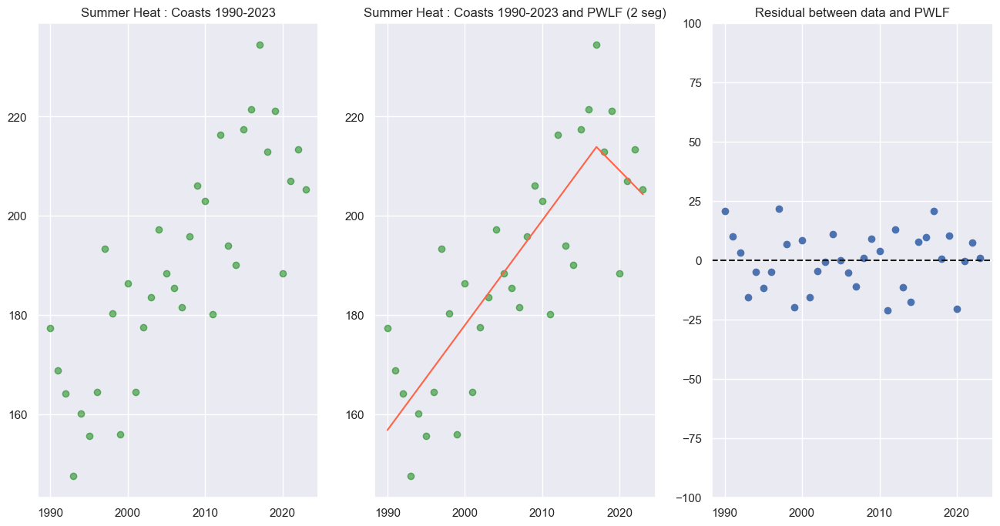

In [172]:
# help from https://james-brennan.github.io/posts/lowess_conf/


# define x & y 
x = sh_coast_an.time.dt.year.values
y = sh_coast_an.SummerHeat.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for two line segments - it looks like 2 is best to me
res = my_pwlf.fit(2)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='green', alpha=0.5)
plt.title("Summer Heat : Coasts 1990-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='green', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer Heat : Coasts 1990-2023 and PWLF (2 seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-100,100)
plt.title("Residual between data and PWLF")


plt.show()

In [173]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks

(array([ 2.11606995, -1.59256268]),
 array([1990.        , 2017.00000003, 2023.        ]))

#### MSR and $R^{2}$

In [174]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(141.53174915655902), np.float64(0.6925110782869102))

#### Try just one segment

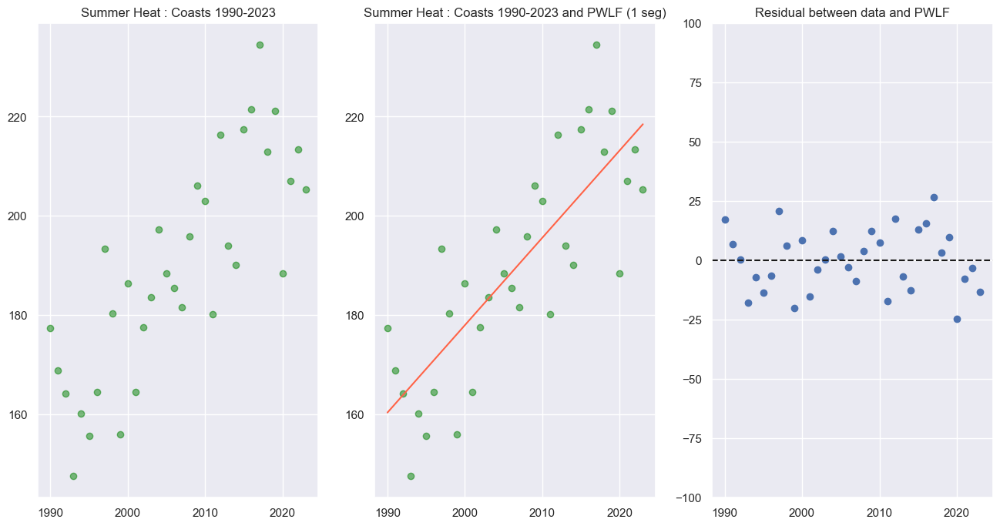

In [175]:
# help from https://james-brennan.github.io/posts/lowess_conf/


# define x & y 
x = sh_coast_an.time.dt.year.values
y = sh_coast_an.SummerHeat.values

# number of segments - can also determine this algorithmically via link above
my_pwlf = pwlf.PiecewiseLinFit(x, y)

# fit the data for two line segments - it looks like 2 is best to me
res = my_pwlf.fit(1)

# predict for the determined points
xHat = np.linspace(min(x), max(x), num=len(y))
yHat = my_pwlf.predict(xHat)

# plot the results
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
plt.plot(x, y, 'o',c='green', alpha=0.5)
plt.title("Summer Heat : Coasts 1990-2023")

plt.subplot(1,3,2)
plt.plot(x, y, 'o', c='green', alpha=0.5)
plt.plot(xHat, yHat, '-', c='tomato')
plt.title("Summer Heat : Coasts 1990-2023 and PWLF (1 seg)")

plt.subplot(1,3,3)
#plt.plot(x, y - yHat, 'b')
plt.scatter(x, y - yHat)
plt.axhline(color='k', linestyle="--")
plt.ylim(-100,100)
plt.title("Residual between data and PWLF")


plt.show()

In [176]:
my_pwlf.calc_slopes(), my_pwlf.fit_breaks

(array([1.76305572]), array([1990, 2023]))

#### MSR and $R^{2}$

In [177]:
# MSR calculation for comparison
MSR = np.sum((y-yHat)**2)/len(x)
MSR, my_pwlf.r_squared()

(np.float64(161.1022567202295), np.float64(0.6499926023690139))

#### One segment for Analysis period Coasts yields a more parsimonius fit

## **** General Conclusions for SH:
- Evidence of acceleration ?? in Summer Length for Land and Coastal Margins for 1961-2023 since ~2000
- No evidence of acceleration in Summer Length for Land and Coastal margins for 1990-2023
- 2012 hiatus showing in Summer Length for Ocean surfaces for 1961-2023
- 2012 hiatus showing in Summer Heat for Ocean surfaces since 2012 for 1961-2023 and 1990-2023
- Evidence of acceleration ?? in Summer Heat for Land since 2000 for 1961-2023
- No evidence of acceleration in Summer Heat for Land for 1990-2023
- Evidence of acceleration in Summer Heat for Coastal margins since 2000 for 1961-2023
- No evidence of acceleration in Summer Heat for Coastal margins for 1990-2023